<div style="color:#c62828; border-left:4px solid #c62828; padding-left:10px">

### 0. Settings
07_results: theta results from the rebuilt pipeline (01–06, functions.py); 3 rats (134, 135, 136), Neuropixels LFP in mPFC.
Loads fn, paths (DATA_ROOT, PROC = 2_processed, TABLES, AMIR, THETA_DIR = amir_data\Theta), extra bad channels (XB),
session list and rat per session (RAT), done_sessions(ref), load_bp(session, ref), test session TEST (20260529_r0000136_wt_1318).

**Band power (06, fn.band_power_session):** Morlet wavelets; delta 1–3 Hz (2 cycles), theta 4, 5, 6, 7 Hz (5 cycles),
alpha 8–12 (6), beta 13–29 (7), low γ 30–60 and high γ 61–100 (10). Window value = log10 of the mean power over the band's
frequencies × window, per trial × channel. Curves = mean over trials of log10(power(t) / own pre-press power),
each trial only while the paw is on the lever. Power in a.u. (not µV²).
**Epochs:** press −2.5..3.5 s, release −3.0..2.5 s. **Tones:** short 0.35 s, long 1.05 s after the press.
**Windows:** pre −0.5..−0.2 s (press) | hold_early 0.10–0.30 s | hold 0.20–0.85 s (press; not cut at the release) |
pre_release −0.3..0 s (release) | post 0.2–0.5 s (release) | pre_tone / post_tone 0.3 s before / after the tone.

**Statistics:** session = unit. Session value = mean over trials -> median over channels. Sign-flip test across sessions
(10,000 flips, seed 0; p floor 0.0001 -> reported as p < 0.001); time points: t-test across sessions (as in the paper).
FDR = Benjamini–Hochberg; q = FDR-corrected p. % change = (10^log − 1) × 100.
**References:** CMR (global median) and LOCAL (SpikeInterface local median, channels 30–200 µm away).
Every result cell runs CMR and LOCAL.

**Colours:** correct #2CA02C (green), late #DD8452 (orange), early #E6B800 (yellow); wait #C44E52 (red), go #2CA02C (green);
rats 134 #4C72B0, 135 #DD8452, 136 #55A868; heat maps viridis. Figures: PNG, 300 dpi, white background.

**Figures (amir_data\Theta\):** 20 selected channels_pilot | theta computation example | hold vs pre and post all sessions |
all long trials | across regions | check licks | movement check | reaction time | wait vs go | correct vs error.
**Tables:** tables\ (M1_session_values_<ref>.csv, M1_stats_<ref>.csv, …).

<div>

In [2]:
# %%
# ── 0. SETTINGS ──
import os, sys, glob, pickle, importlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAIN      = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
AMIR      = os.path.join(DATA_ROOT, "amir_data")
TABLES    = os.path.join(MAIN, "tables")
FIGS      = os.path.join(MAIN, "figures", "07_results")
DATA_OUT  = os.path.join(AMIR, "data")                                         # recomputed 2026-11-05 (analysis_main was deleted)
BP_DIRS   = {"CMR":   os.path.join(DATA_OUT, "band power", "CMR"),
             "LOCAL": os.path.join(DATA_OUT, "band power", "LOCAL")}
BURST_DIR = os.path.join(DATA_OUT, "Bursts detection")                         # Karvat 2021 (Golan), 50-ms bins, beta + gamma, CMR + LOCAL
EXACT_DIR = os.path.join(DATA_OUT, "Bursts detection exact times")             # same detection, exact burst times (beta)
ALL_DIR   = os.path.join(DATA_OUT, "Beta and gamma bursts across channels")    # whole probe, LOCAL (run later)
BETA_DIR  = os.path.join(AMIR, "Beta bursts"); os.makedirs(BETA_DIR, exist_ok=True)   # figures/tables of the burst results
os.makedirs(FIGS, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", message="Mean of empty slice|All-NaN slice")

final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
RAT   = final.set_index("session")["rat"].astype(str)
BANDS = list(fn.MAIN_BANDS)
TEST  = "20260529_r0000136_wt_1318"

def load_bp(session, ref="CMR"):
    """One band-power file (06) -> dict (meta, trials, logpow, curves, counts, times, spectra, spec_n)."""
    with open(os.path.join(BP_DIRS[ref], session + ".pkl"), "rb") as f:
        return pickle.load(f)

def done_sessions(ref="CMR"):
    """Final sessions whose band-power file exists."""
    return [s for s in final["session"] if os.path.exists(os.path.join(BP_DIRS[ref], s + ".pkl"))]

print("band power done:", {r: len(done_sessions(r)) for r in BP_DIRS}, "of", len(final))
print("bursts done:", sum(os.path.exists(os.path.join(BURST_DIR, s + ".npz")) for s in final["session"]), "of", len(final))

# shared for the theta cells
PROC      = os.path.join(DATA_ROOT, "2_processed")                         # raw recordings (cells that recompute from the LFP)
XB        = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))    # extra bad channels (removed before referencing)
THETA_DIR = os.path.join(AMIR, "Theta"); os.makedirs(THETA_DIR, exist_ok=True)
COL = {"correct": "#2CA02C", "late": "#DD8452", "early": "#E6B800", "wait": "#C44E52", "go": "#2CA02C"}
RCOL = {"134": "#4C72B0", "135": "#DD8452", "136": "#55A868"}
pc = lambda x: 100 * (10 ** np.asarray(x, float) - 1)                     # log10 ratio -> % change
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")   # LOCAL edge-channel fallback

band power done: {'CMR': 60, 'LOCAL': 60} of 60
bursts done: 60 of 60


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1. Theta during the hold (M1): does power change while the rat holds the lever?
Per trial and channel: log10(power in the hold 0.20–0.85 s) − log10(power before the press −0.5..−0.2 s) ("hold-pre"),
and − log10(power after the release 0.2–0.5 s) ("hold-post"). Mean over correct long trials -> median over channels -> one value per session
(sessions with >= 10 correct long trials). Sign-flip test across sessions (10,000 flips), per rat and all rats; shown as % change;
raw p and FDR (6 bands × 2 comparisons). All long_prob blocks (new filter). CMR first, LOCAL in 1i.
Result (CMR, 58 sessions): theta hold-pre +23.9 % (58/58), hold-post +55.4 % (57/58), every rat, q < 0.001;
LOCAL +13.0 % (56/58) / +20.1 % (57/58).
Cells: 1a test session | 1b all sessions (all bands) | 1c pilot computation example (heat maps) | 1d pilot significance (20 channels)
| 1e theta across all sessions | theta time courses and comparisons by outcome | wait vs go | outcome and RT | 1i LOCAL | FDR figures.
(Earlier result 2026-10-20, old filter, 0.5 blocks: theta hold-pre +29 % (30/30), hold-post +56 %.)

<div>

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1a. M1 on the test session (20260529_r0000136_wt_1318, CMR)
fn.m1_session on one file: correct long trials (all blocks), per channel the mean over trials of log10(hold / pre) and log10(hold / post),
then the median over channels; printed as % change per band.
Check: theta hold vs pre must equal the 06_band_power test (+30.7 %).

<div>

In [68]:
# ── 1a. M1, TEST SESSION ──
importlib.reload(fn)
MIN_CL = 10
m, n_cl = fn.m1_session(load_bp(TEST, "CMR"), BANDS, MIN_CL)
print(f"{TEST}: correct long trials {n_cl}")
for b in BANDS:
    print(f"  {b:13s} hold vs pre {100 * (10 ** m[b]['hold-pre'] - 1):+6.1f} % | hold vs post {100 * (10 ** m[b]['hold-post'] - 1):+6.1f} %")

20260529_r0000136_wt_1318: correct long trials 49
  delta 1-3     hold vs pre   +5.1 % | hold vs post  +22.9 %
  theta 4-7     hold vs pre  +30.7 % | hold vs post  +37.1 %
  alpha 8-12    hold vs pre  +18.5 % | hold vs post  +25.7 %
  beta 13-29    hold vs pre   +4.3 % | hold vs post  +11.9 %
  lowG 30-60    hold vs pre   +3.9 % | hold vs post   +8.9 %
  highG 61-100  hold vs pre   -3.7 % | hold vs post   +5.9 %


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1b. M1 on all finished sessions (CMR)
The same value for every finished session (>= 10 correct long trials) -> table M1 (one row per session × band).
Sign-flip test across sessions (fn.sign_flip_p, 10,000 flips): is the mean over sessions different from 0? Per rat and all rats;
raw p and FDR q (per rat: 6 bands × 2 comparisons = 12 tests). p floor 0.0001 -> reported as p < 0.001.
Result (58 of 60 sessions; 2 with < 10 correct long trials: 135_0510_1625, 134_0620_1512): theta hold-pre +23.9 % (58/58),
hold-post +55.4 % (57/58); alpha +16.5 / +27.4 %; beta +12.6 / +20.0 %; delta +9.9 % (40/58) / +33.3 %; high gamma −5.5 / −5.8 %;
all q < 0.001.
Saved: tables\M1_session_values_CMR.csv, tables\M1_stats_CMR.csv.

<div>

In [69]:
# ── 1b. M1, ALL FINISHED SESSIONS (sign-flip across sessions, raw p + FDR) ──
importlib.reload(fn)
from statsmodels.stats.multitest import multipletests
REF = "CMR"
MIN_CL = globals().get("MIN_CL", 10)                  # from 1a; 10 if 1a was not run

rows = []
for s in done_sessions(REF):
    m, n_cl = fn.m1_session(load_bp(s, REF), BANDS, MIN_CL)
    if m is None:
        continue
    for b in BANDS:
        rows.append({"session": s, "rat": RAT[s], "band": b, "n_cl": n_cl, **m[b]})
M1 = pd.DataFrame(rows)
M1.to_csv(os.path.join(TABLES, f"M1_session_values_{REF}.csv"), index=False)
print(f"sessions with >= {MIN_CL} correct long trials: {M1['session'].nunique()} of {len(done_sessions(REF))} finished")

stat = []
for meas in ["hold-pre", "hold-post"]:
    for b in BANDS:
        for rat in ["all"] + sorted(M1["rat"].unique()):
            v = M1[(M1["band"] == b) & ((M1["rat"] == rat) if rat != "all" else True)][meas]
            mean, p, n = fn.sign_flip_p(v.values)
            stat.append({"measure": meas, "band": b, "rat": rat, "n_sessions": n, "sessions_up": int((v > 0).sum()),
                         "mean_%": round(100 * (10 ** mean - 1), 1) if n else np.nan, "p": round(p, 4) if n >= 2 else np.nan})
M1_stat = pd.DataFrame(stat)

# FDR (Benjamini–Hochberg) per rat: 6 bands x 2 comparisons = 12 tests
M1_stat["q"] = np.nan
for rat, idx in M1_stat.groupby("rat").groups.items():
    ok = M1_stat.loc[idx, "p"].notna()
    ii = M1_stat.loc[idx][ok].index
    M1_stat.loc[ii, "q"] = multipletests(M1_stat.loc[ii, "p"], method="fdr_bh")[1].round(4)
M1_stat.to_csv(os.path.join(TABLES, f"M1_stats_{REF}.csv"), index=False)

for meas, d in M1_stat.groupby("measure", sort=False):
    print(f"\n===== M1 {meas} ({REF}) =====")
    print(d.pivot(index="band", columns="rat", values=["mean_%", "sessions_up", "n_sessions", "p", "q"]).loc[BANDS].to_string())

KeyboardInterrupt: 

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1c. Pilot: session 20260529_r0000136_wt_1318, comparison example (how the band power is computed)
Same session, same 20 channels (fn.select_channels, n_total = 20) and same 49 correct long trials as the pilot; CMR.
Needs 1e-20 and 1e-20b (Morlet power of the 20 channels around the press and the release) run directly before this cell.
Per trial and channel: Morlet wavelet power over time (same frequencies and cycles as 06: theta 4–7 Hz, 5 cycles),
cut around the press (−2.5..3.5 s) and around the release (−3.0..2.5 s).
Windows: pre −0.5..−0.2 s (press), hold 0.20..0.85 s (press), post 0.2..0.5 s (release).
Per window: log10 of the mean power over the band frequencies and the window time -> hold − pre and hold − post (log ratio),
mean over trials, then mean over the 20 channels; shown as % change.
Heat maps (display only; the numbers come from the windows): log10 power minus each trial's own baseline, mean over trials and channels:
pilot_comparison.png (pre | hold | post): baseline = mean of own pre and post (the hold colour lies between hold − pre and hold − post);
pilot_hold_vs_pre.png: baseline = own pre-press; pilot_hold_vs_post.png: baseline = own post-release.
Check: recomputed theta hold − pre = saved value (+31.9 % mean, +31.1 % median over the 20 channels; range +5 to +65 %, all channels up).
The middle of the hold is cut in the joined plots because the hold length differs between trials.
Saved: amir_data\Theta\theta computation example\pilot_comparison.png, pilot_hold_vs_pre.png, pilot_hold_vs_post.png

<div>

theta hold − pre            +31.9 %  (saved: +31.9 %)
theta hold − post           +50.6 %
theta hold − mean(pre,post) +40.9 %  (combined plot)


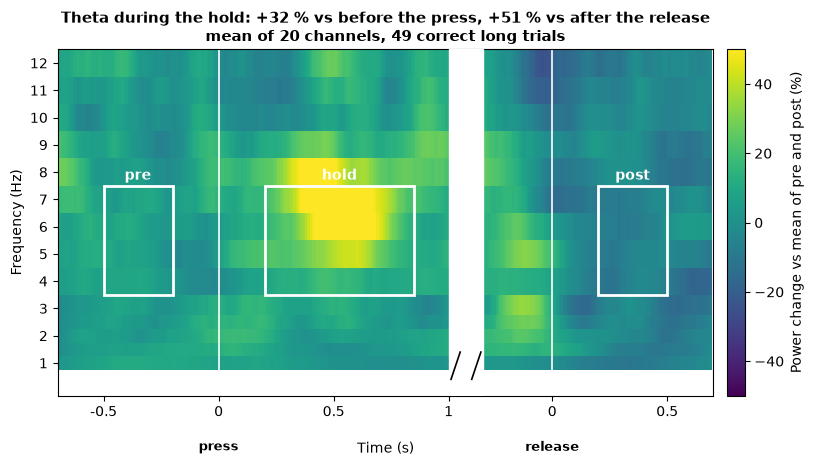

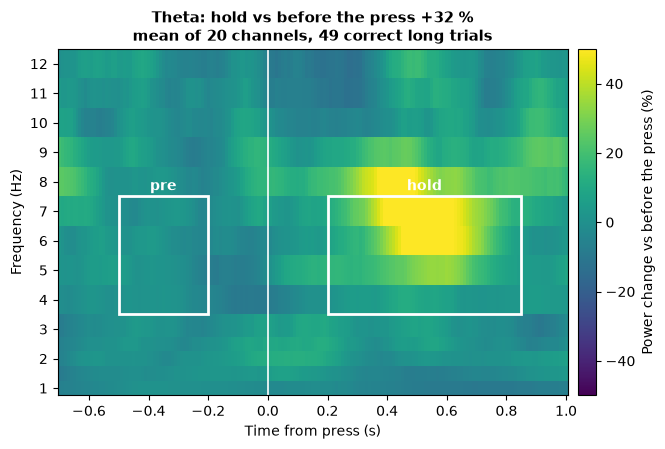

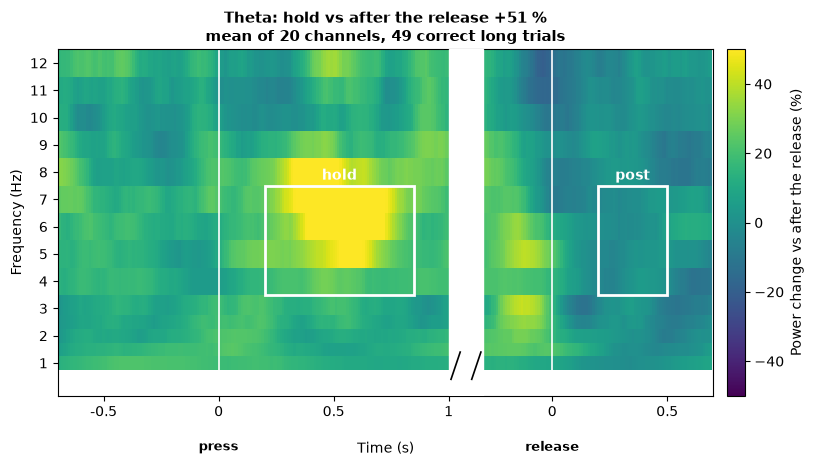

In [4]:
# %%
# ── 1c. PILOT COMPARISON PLOTS (self-contained): combined (pre | hold | post) + hold vs pre + hold vs post ──
importlib.reload(fn)
import scipy.signal as ss
from matplotlib.patches import Rectangle
PROC = os.path.join(DATA_ROOT, "2_processed")
XB   = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
SES, REF, BAND, DEC = TEST, "CMR", "theta 4-7", 10
KEEP = ["delta 1-3", "theta 4-7", "alpha 8-12"]             # frequencies shown in the maps

# 1) trials and the same 20 channels as the pilot
r  = load_bp(SES, REF); T, meta = r["trials"], r["meta"]
cl = ((T["label"] == "correct") & (T["type"] == "long")).values
pdf = pd.DataFrame({"channel_id": meta["channel_ids"], "x": meta["x"], "y": meta["y"]}); pdf["shank"] = (pdf["x"] // 250).astype(int)
sel_ids = [str(c) for c in fn.select_channels(pdf, n_total=20)["channel_id"]]

# 2) recording (20 channels) and epochs around the press and the release
rec = fn.load_session(PROC, SES, XB, refs=(REF,))[0][REF]
full = [str(c) for c in rec.get_channel_ids()]
objs = [rec.get_channel_ids()[full.index(c)] for c in sel_ids]
recN = rec.select_channels(objs) if hasattr(rec, "select_channels") else rec.channel_slice(channel_ids=objs)
fs = recN.get_sampling_frequency()
(a0, a1), (b0, b1) = fn.MAIN_EPOCHS["Press"], fn.MAIN_EPOCHS["Release"]
XP = fn.read_epochs(recN, T.loc[cl, "press_s"].values, a0, a1)[0].astype(np.float64)
XR = fn.read_epochs(recN, T.loc[cl, "release_s"].values, b0, b1)[0].astype(np.float64)
t  = (np.arange(XP.shape[-1]) / fs + a0)[::DEC]
tR = (np.arange(XR.shape[-1]) / fs + b0)[::DEC]

# 3) Morlet power, same frequencies and cycles as 06 (delta–alpha)
freqs, band_of, P, PR = [], [], [], []
for b in KEEP:
    spec = fn.MAIN_BANDS[b]
    for f in spec["freqs"]:
        w = fn.morlet(f, spec["n_cycles"], fs)[None, None, :]
        P.append((np.abs(ss.fftconvolve(XP, w, mode="same", axes=-1)) ** 2)[..., ::DEC])
        PR.append((np.abs(ss.fftconvolve(XR, w, mode="same", axes=-1)) ** 2)[..., ::DEC])
        freqs.append(f); band_of.append(b)
P, PR = np.stack(P, axis=2), np.stack(PR, axis=2)            # (trials, channels, freqs, times)
freqs, band_of = np.array(freqs), np.array(band_of)
fb = band_of == BAND
win = lambda tt, name: (tt >= fn.MAIN_WINDOWS[name][1][0] - 1e-9) & (tt <= fn.MAIN_WINDOWS[name][1][1] + 1e-9)
m_pre, m_hold, m_post = win(t, "pre"), win(t, "hold"), win(tR, "post")

# 4) plots
L_SHOW, R_SHOW, GAP = (-0.7, 1.0), (-0.3, 0.7), 0.15
mL = (t  >= L_SHOW[0]) & (t  <= L_SHOW[1])
mR = (tR >= R_SHOW[0]) & (tR <= R_SHOW[1])
off = L_SHOW[1] + GAP - R_SHOW[0]
theta_dir = os.path.join(AMIR, "Theta", "theta computation example"); os.makedirs(theta_dir, exist_ok=True)
sub = f"mean of {len(sel_ids)} channels, {cl.sum()} correct long trials"
kw  = dict(cmap="viridis", vmin=-50, vmax=50, shading="nearest")

logPL, logPR = np.log10(P), np.log10(PR)
b_pre  = logPL[..., m_pre].mean(axis=-1, keepdims=True)
b_post = logPR[..., m_post].mean(axis=-1, keepdims=True)
b_both = (b_pre + b_post) / 2
pct_map = lambda logX, base: 100 * (10 ** (logX - base).mean(axis=0).mean(axis=0) - 1)   # (freqs, times)

th = lambda PP, m: np.log10(PP[:, :, fb][..., m].mean(axis=(2, 3)))                       # window values, as in 06
w_pre, w_hold, w_post = th(P, m_pre), th(P, m_hold), th(PR, m_post)
pc_win = lambda d: 100 * (10 ** d.mean(axis=0).mean() - 1)      # mean over trials, then channels -> %
d_saved = (r["logpow"][BAND]["hold"][cl] - r["logpow"][BAND]["pre"][cl])[:, [list(map(str, meta["channel_ids"])).index(c) for c in sel_ids]].mean(0)
print(f"theta hold − pre            {pc_win(w_hold - w_pre):+.1f} %  (saved: {100 * (10 ** d_saved.mean() - 1):+.1f} %)")
print(f"theta hold − post           {pc_win(w_hold - w_post):+.1f} %")
print(f"theta hold − mean(pre,post) {pc_win(w_hold - (w_pre + w_post) / 2):+.1f} %  (combined plot)")

def frame(ax, x0, w_, name):
    a, z = fn.MAIN_WINDOWS[w_][1]
    ax.add_patch(Rectangle((a + x0, 3.5), z - a, 4.0, fill=False, ec="white", lw=2, zorder=5))
    ax.text((a + z) / 2 + x0, 7.6, name, ha="center", va="bottom", fontsize=10, fontweight="bold", color="white", zorder=5)

def joined(ML, MR, boxes, cbar, title, fname):
    fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
    ax.pcolormesh(t[mL], freqs, ML[:, mL], **kw)
    im = ax.pcolormesh(tR[mR] + off, freqs, MR[:, mR], **kw)
    ax.axvspan(L_SHOW[1], L_SHOW[1] + GAP, color="white", zorder=3)
    for xx in (L_SHOW[1] + 0.03, L_SHOW[1] + GAP - 0.03):
        ax.plot([xx - 0.02, xx + 0.02], [0.4, 1.4], color="k", lw=1.2, clip_on=False, zorder=4)
    for x0, w_ in boxes:
        frame(ax, x0, w_, w_)
    ax.axvline(0, color="white", lw=1.2); ax.axvline(off, color="white", lw=1.2)
    tl, tr = [-0.5, 0, 0.5, 1.0], [0, 0.5]
    ax.set_xticks(tl + [v + off for v in tr]); ax.set_xticklabels([f"{v:g}" for v in tl + tr])
    ax.text(0, -0.13, "press", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, fontweight="bold")
    ax.text(off, -0.13, "release", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, fontweight="bold")
    ax.set_xlabel("Time (s)", labelpad=16); ax.set_xlim(L_SHOW[0], R_SHOW[1] + off)
    ax.set_ylabel("Frequency (Hz)"); ax.set_yticks(range(1, 13))
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label=cbar)
    ax.set_title(title, fontsize=11, fontweight="bold")
    fig.savefig(os.path.join(theta_dir, fname), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

joined(pct_map(logPL, b_both), pct_map(logPR, b_both), [(0, "pre"), (0, "hold"), (off, "post")],
       "Power change vs mean of pre and post (%)",
       f"Theta during the hold: {pc_win(w_hold - w_pre):+.0f} % vs before the press, {pc_win(w_hold - w_post):+.0f} % vs after the release\n{sub}",
       "pilot_comparison.png")

fig, ax = plt.subplots(figsize=(7, 4.5), facecolor="white")
im = ax.pcolormesh(t[mL], freqs, pct_map(logPL, b_pre)[:, mL], **kw)
frame(ax, 0, "pre", "pre"); frame(ax, 0, "hold", "hold")
ax.axvline(0, color="white", lw=1.2)
ax.set_xlabel("Time from press (s)"); ax.set_ylabel("Frequency (Hz)"); ax.set_yticks(range(1, 13))
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Power change vs before the press (%)")
ax.set_title(f"Theta: hold vs before the press {pc_win(w_hold - w_pre):+.0f} %\n{sub}", fontsize=11, fontweight="bold")
fig.savefig(os.path.join(theta_dir, "pilot_hold_vs_pre.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

joined(pct_map(logPL, b_post), pct_map(logPR, b_post), [(0, "hold"), (off, "post")],
       "Power change vs after the release (%)",
       f"Theta: hold vs after the release {pc_win(w_hold - w_post):+.0f} %\n{sub}",
       "pilot_hold_vs_post.png")

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1d. Pilot: session 20260529_r0000136_wt_1318, significance per channel
Same session, 20 channels (fn.select_channels), 49 correct long trials, CMR. Per channel and band: hold − pre and hold − post
(log10 ratio per trial); sign-flip test across TRIALS (5000 flips).
* = p < 0.05 vs before the press AND vs after the release, same direction (hold-specific); · = p < 0.05 in that panel only.
Colour = % change (geometric mean over trials); white frame = theta.
Result (raw p): theta hold-specific in 12/20 channels, alpha 6/20, delta 1/20, beta 1/20, low γ 2/20, high γ 1/20
(about 1/20 expected by chance per band; channels are not independent, so this is only a guide).
FDR (per band over 20 channels × 2 comparisons): theta [X]/20 (see printout).
-> first sign that theta rises while the rat holds the lever; tested across sessions in 1b / 1e.
Probe plots: the 20 selected channels (blue) and the theta-significant ones (red).
Saved: amir_data\Theta\pilot_significance_CMR.png, pilot_selected_channels_CMR.png, pilot_significant_channels_CMR.png

<div>

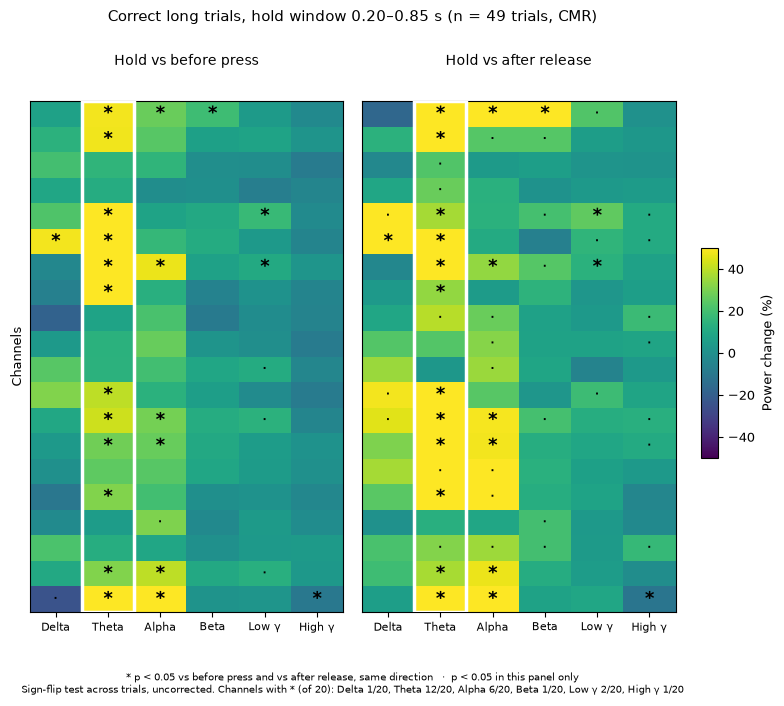

raw: Delta 1/20, Theta 12/20, Alpha 6/20, Beta 1/20, Low γ 2/20, High γ 1/20
FDR: Delta 0/20, Theta 10/20, Alpha 4/20, Beta 0/20, Low γ 1/20, High γ 0/20


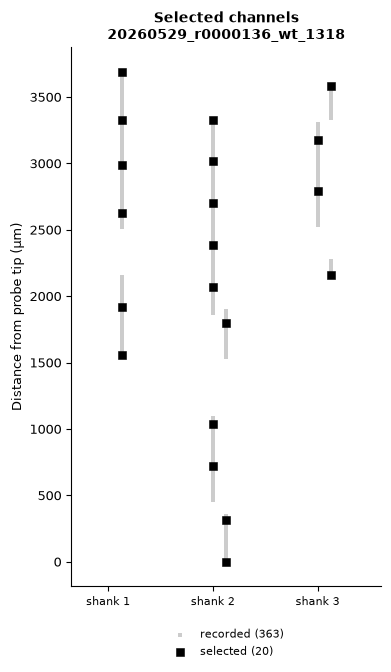

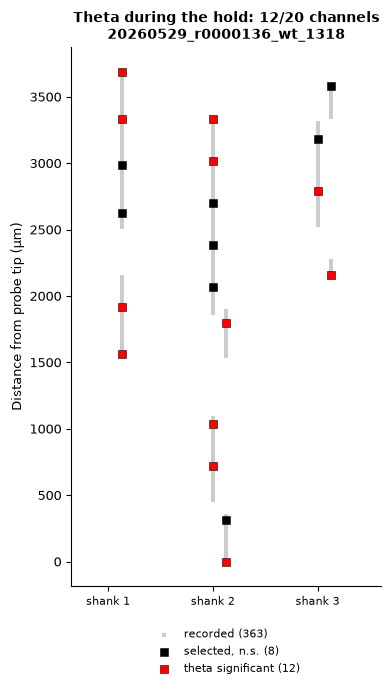

In [64]:
# %%
# ── 1d. PILOT: SIGNIFICANCE PER CHANNEL (sign-flip across trials) + FDR count + probe plots ──
importlib.reload(fn)
from matplotlib.patches import Rectangle
from statsmodels.stats.multitest import multipletests
SES_1D, REF_1D, NPERM_1D = TEST, "CMR", 5000
NAMES = {"delta 1-3": "Delta", "theta 4-7": "Theta", "alpha 8-12": "Alpha", "beta 13-29": "Beta",
         "lowG 30-60": "Low γ", "highG 61-100": "High γ"}
theta_dir = os.path.join(AMIR, "Theta", "20 selected channels_pilot"); os.makedirs(theta_dir, exist_ok=True)

r = load_bp(SES_1D, REF_1D)
T, lp, meta = r["trials"], r["logpow"], r["meta"]
pdf = pd.DataFrame({"channel_id": meta["channel_ids"], "x": meta["x"], "y": meta["y"]})
pdf["shank"] = (pdf["x"] // 250).astype(int)
sel = fn.select_channels(pdf, n_total=20).sort_values(["shank", "y"], ascending=[True, False])
ci = [list(map(str, meta["channel_ids"])).index(str(c)) for c in sel["channel_id"]]
cl = ((T["label"] == "correct") & (T["type"] == "long")).values
n_tr = int(cl.sum())

# 1) per channel and band: sign-flip across trials
pct = {k: np.full((len(ci), len(BANDS)), np.nan) for k in ("pre", "post")}
pv  = {k: np.full((len(ci), len(BANDS)), np.nan) for k in ("pre", "post")}
for j, b in enumerate(BANDS):
    for k in ("pre", "post"):
        R = lp[b]["hold"][cl][:, ci] - lp[b][k][cl][:, ci]                  # (trials, channels) log10 ratios
        for i in range(len(ci)):
            m, p, _ = fn.sign_flip_p(R[:, i], n_perm=NPERM_1D)
            pct[k][i, j], pv[k][i, j] = 100 * (10 ** m - 1), p
same_dir = np.sign(pct["pre"]) == np.sign(pct["post"])
spec = (pv["pre"] < 0.05) & (pv["post"] < 0.05) & same_dir
counts = ", ".join(f"{NAMES[b]} {int(spec[:, j].sum())}/{len(ci)}" for j, b in enumerate(BANDS))

# FDR per band over 20 channels x 2 comparisons
spec_fdr = np.zeros_like(spec)
for j in range(len(BANDS)):
    q = multipletests(np.concatenate([pv["pre"][:, j], pv["post"][:, j]]), method="fdr_bh")[1]
    spec_fdr[:, j] = (q[:len(ci)] < 0.05) & (q[len(ci):] < 0.05) & same_dir[:, j]
counts_fdr = ", ".join(f"{NAMES[b]} {int(spec_fdr[:, j].sum())}/{len(ci)}" for j, b in enumerate(BANDS))

# 2) significance figure (raw p, as on the pilot slide)
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(8.5, 7), sharey=True, facecolor="white")
jt = BANDS.index("theta 4-7")
for ax, k, ttl in zip(axes, ("pre", "post"), ("Hold vs before press", "Hold vs after release")):
    im = ax.imshow(pct[k], cmap="viridis", vmin=-50, vmax=50, aspect="auto")
    ax.add_patch(Rectangle((jt - 0.5, -0.5), 1, len(ci), fill=False, ec="white", lw=2.5, zorder=5))   # theta frame
    for i in range(len(ci)):
        for j in range(len(BANDS)):
            if spec[i, j]:
                ax.text(j, i, "*", ha="center", va="center", fontsize=13, fontweight="bold")
            elif pv[k][i, j] < 0.05:
                ax.text(j, i, "·", ha="center", va="center", fontsize=13)
    ax.set_xticks(range(len(BANDS))); ax.set_xticklabels([NAMES[b] for b in BANDS], fontsize=8)
    ax.set_title(ttl, fontsize=10, pad=26)
axes[0].set_yticks([]); axes[0].set_ylabel("Channels")
fig.suptitle(f"Correct long trials, hold window 0.20–0.85 s (n = {n_tr} trials, {REF_1D})", fontsize=10.5, y=0.99)
fig.text(0.5, 0.01, "* p < 0.05 vs before press and vs after release, same direction   ·  p < 0.05 in this panel only\n"
         f"Sign-flip test across trials, uncorrected. Channels with * (of {len(ci)}): " + counts,
         ha="center", va="bottom", fontsize=7)
fig.subplots_adjust(bottom=0.13, top=0.86, left=0.12, right=0.88, wspace=0.06)
cb = fig.colorbar(im, cax=fig.add_axes([0.91, 0.35, 0.02, 0.3])); cb.set_label("Power change (%)")
fig.savefig(os.path.join(theta_dir, f"pilot_significance_{REF_1D}.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()
print("raw:", counts)
print("FDR:", counts_fdr)

# 3) probe plots: (a) selected channels (blue) | (b) theta-significant (red) + rest of the selected (blue)
xs, ys = np.asarray(meta["x"], float), np.asarray(meta["y"], float)
ids_all = np.array([str(c) for c in meta["channel_ids"]])
sel_ids = np.array([str(c) for c in sel["channel_id"]])                 # same order as the rows of spec
is_sel = np.isin(ids_all, sel_ids)
is_sig = np.isin(ids_all, sel_ids[spec[:, jt]])
shanks = np.unique(np.round(xs / 250).astype(int))
for kind in ("selected", "significant"):
    fig, ax = plt.subplots(figsize=(4, 7), facecolor="white")
    rest = ~is_sel
    ax.scatter(xs[rest], ys[rest], s=6, marker="s", color="0.8", lw=0, label=f"recorded ({rest.sum()})")
    blue = is_sel if kind == "selected" else (is_sel & ~is_sig)
    ax.scatter(xs[blue], ys[blue], s=40, marker="s", color="#000000FF", edgecolor="k", lw=0.4, zorder=3,
               label=f"selected ({blue.sum()})" if kind == "selected" else f"selected, n.s. ({blue.sum()})")
    if kind == "significant":
        ax.scatter(xs[is_sig], ys[is_sig], s=40, marker="s", color="red", edgecolor="k", lw=0.4, zorder=4,
                   label=f"theta significant ({is_sig.sum()})")
    ax.set_xticks(shanks * 250); ax.set_xticklabels([f"shank {s + 1}" for s in shanks], fontsize=8)
    ax.set_xlim(xs.min() - 120, xs.max() + 120); ax.set_ylabel("Distance from probe tip (µm)")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=1, frameon=False, fontsize=8)
    ttl = "Selected channels" if kind == "selected" else f"Theta during the hold: {is_sig.sum()}/{len(sel_ids)} channels"
    ax.set_title(f"{ttl}\n{SES_1D}", fontsize=10, fontweight="bold")
    fig.savefig(os.path.join(theta_dir, f"pilot_{kind}_channels_{REF_1D}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1e. Theta across all sessions (correct long), CMR and LOCAL
- Same figure for both references; q = FDR over 12 tests (6 bands x 2 comparisons, all rats), as in 1b.
- Result: CMR hold vs pre +23.9 % (58/58 up), hold vs post +55.4 %; LOCAL +13.0 % (56/58), +20.1 %; all q < 0.001.
- Saved: amir_data\Theta\hold vs pre and post all sessions\all_sessions_theta_CMR.png, all_sessions_theta_LOCAL.png

<div>

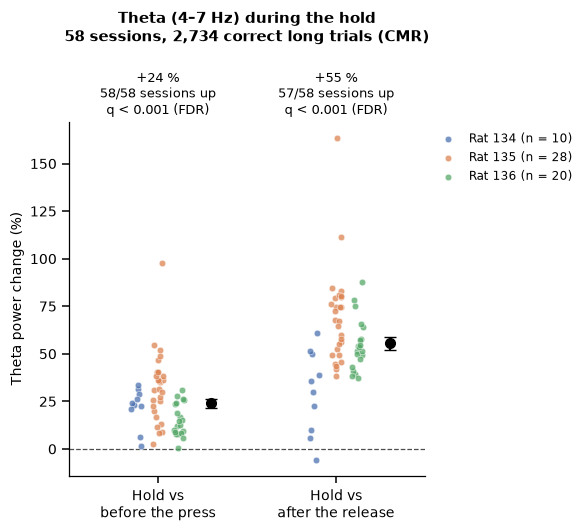

CMR: 58 sessions, 2734 correct long trials | per rat: {'134': 10, '135': 28, '136': 20}


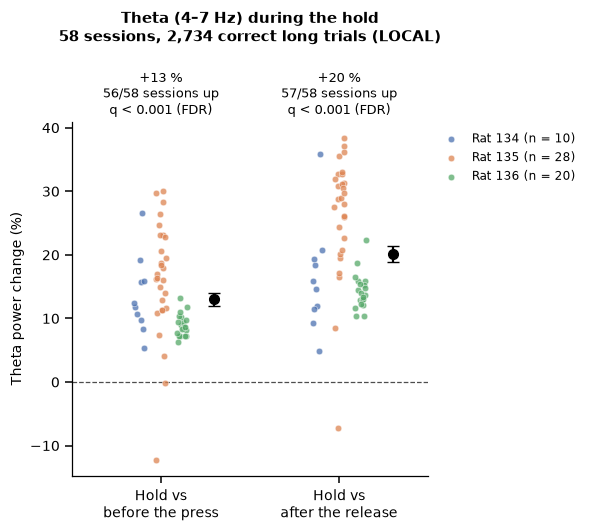

LOCAL: 58 sessions, 2734 correct long trials | per rat: {'134': 10, '135': 28, '136': 20}

theta, correct long — CMR vs LOCAL
  ref   measure  n_sessions  sessions_up  mean_%      p      q
  CMR  hold-pre          58           58    23.9 0.0001 0.0001
  CMR hold-post          58           57    55.4 0.0001 0.0001
LOCAL  hold-pre          58           56    13.0 0.0001 0.0001
LOCAL hold-post          58           57    20.1 0.0001 0.0001
saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\hold vs pre and post all sessions


In [92]:
# %%
# ── 1e. THETA ACROSS ALL SESSIONS (slide figure), CMR and LOCAL ──
from statsmodels.stats.multitest import multipletests
BAND, MIN_CL = "theta 4-7", globals().get("MIN_CL", 10)
BANDS_ = globals().get("BANDS", list(fn.MAIN_BANDS))
RCOL = {"134": "#4C72B0", "135": "#DD8452", "136": "#55A868"}
PAN  = [("hold-pre", "Hold vs\nbefore the press"), ("hold-post", "Hold vs\nafter the release")]
pc   = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
ses_dir = os.path.join(AMIR, "Theta", "hold vs pre and post all sessions"); os.makedirs(ses_dir, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9, "font.family": "sans-serif"})

def session_values(ref):
    """M1 session values (correct long, all bands); read from tables or computed with fn.m1_session (as 1b)"""
    f = os.path.join(TABLES, f"M1_session_values_{ref}.csv")
    if os.path.exists(f):
        return pd.read_csv(f, dtype={"rat": str})
    rows = []
    for s in done_sessions(ref):
        m, n_cl = fn.m1_session(load_bp(s, ref), BANDS_, MIN_CL)
        if m is not None:
            rows += [{"session": s, "rat": RAT[s], "band": b, "n_cl": n_cl, **m[b]} for b in BANDS_]
    M = pd.DataFrame(rows); M.to_csv(f, index=False)
    return M

summary_rows = []
for REF in ["CMR", "LOCAL"]:
    MV = session_values(REF)
    # FDR over the 12 tests (6 bands x 2 comparisons, all rats), as in 1b
    tests = [(col, b, *fn.sign_flip_p(MV.loc[MV["band"] == b, col].values)) for col, _ in PAN for b in BANDS_]
    qs = multipletests([t[3] for t in tests], method="fdr_bh")[1]
    Q = {(t[0], t[1]): q for t, q in zip(tests, qs)}

    M1t = MV[MV["band"] == BAND].copy()
    n_ses, n_tr = M1t["session"].nunique(), int(M1t["n_cl"].sum())
    fig, ax = plt.subplots(figsize=(4.6, 4.6), facecolor="white")
    rng = np.random.default_rng(0)
    for i, (col, _) in enumerate(PAN):
        v = pc(M1t[col])
        for k, rat in enumerate(sorted(RCOL)):
            vr = v[M1t["rat"] == rat]
            ax.scatter(i + (k - 1) * 0.12 + rng.uniform(-0.03, 0.03, len(vr)), vr, s=22, color=RCOL[rat],
                       alpha=0.75, edgecolor="white", linewidth=0.4, zorder=2,
                       label=f"Rat {rat} (n = {len(vr)})" if i == 0 else None)
        m, p, n = fn.sign_flip_p(M1t[col].values)                 # test on log10 values
        mean_pct, sem_pct = pc(m), v.std(ddof=1) / np.sqrt(len(v))
        q = Q[(col, BAND)]
        ax.errorbar(i + 0.30, mean_pct, yerr=sem_pct, fmt="o", color="k", ms=7, capsize=4, lw=1.6, zorder=4)
        ps = "q < 0.001 (FDR)" if q < 0.001 else f"q = {q:.3f} (FDR)"
        up = int((M1t[col] > 0).sum())
        ax.text(i, 1.01, f"{mean_pct:+.0f} %\n{up}/{n} sessions up\n{ps}",
                transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9)
        summary_rows.append({"ref": REF, "measure": col, "n_sessions": n, "sessions_up": up,
                             "mean_%": round(float(mean_pct), 1), "p": p, "q": q})
    ax.axhline(0, color="0.3", lw=0.9, ls="--", zorder=1)
    ax.set_xticks(range(len(PAN))); ax.set_xticklabels([t for _, t in PAN]); ax.set_xlim(-0.5, len(PAN) - 0.5)
    ax.set_ylabel("Theta power change (%)")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax.set_title(f"Theta (4–7 Hz) during the hold\n{n_ses} sessions, {n_tr:,} correct long trials ({REF})",
                 fontsize=11, fontweight="bold", pad=58)
    fig.savefig(os.path.join(ses_dir, f"all_sessions_theta_{REF}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"{REF}: {n_ses} sessions, {n_tr} correct long trials | per rat:", M1t.groupby("rat")["session"].nunique().to_dict())

print("\ntheta, correct long — CMR vs LOCAL")
print(pd.DataFrame(summary_rows).round({"p": 4, "q": 4}).to_string(index=False))
print("saved in:", ses_dir)

In [16]:
# ── 1e-check. M1 with mPFC channels only (Cg1, PL, IL) vs all channels ──
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
pc = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
rows = []
for ref in ["CMR", "LOCAL"]:
    for s in done_sessions(ref):
        r = load_bp(s, ref)
        cl = ((r["trials"]["label"] == "correct") & (r["trials"]["type"] == "long")).values
        if cl.sum() < 10:
            continue
        masks, _ = fn.region_masks(r, CHREG, s)
        mp = masks["PL"] | masks["IL"] | masks["Cg1"]
        for b in fn.MAIN_BANDS:
            L = r["logpow"][b]
            for meas, w0 in (("hold-pre", "pre"), ("hold-post", "post")):
                ch = (L["hold"][cl] - L[w0][cl]).mean(axis=0)
                rows.append({"ref": ref, "session": s, "band": b, "measure": meas, "n_all": len(ch), "n_mpfc": int(mp.sum()),
                             "all": float(np.median(ch)), "mpfc": float(np.median(ch[mp]))})
CK = pd.DataFrame(rows)
out = []
for (ref, b, meas), g in CK.groupby(["ref", "band", "measure"], sort=False):
    ma, pa, na = fn.sign_flip_p(g["all"].values); mm, pm, nm = fn.sign_flip_p(g["mpfc"].values)
    out.append({"ref": ref, "band": b, "measure": meas, "sessions": na, "all_%": pc(ma), "p_all": pa,
                "mPFC_only_%": pc(mm), "p_mPFC": pm, "up_mPFC": int((g["mpfc"] > 0).sum())})
print(pd.DataFrame(out).round({"all_%": 1, "mPFC_only_%": 1, "p_all": 4, "p_mPFC": 4}).to_string(index=False))
print("\nchannels per session: all", int(CK.n_all.median()), "| mPFC", int(CK.n_mpfc.median()),
      "| lowest mPFC share:", CK.assign(f=CK.n_mpfc / CK.n_all).groupby("session")["f"].first().nsmallest(3).round(2).to_dict())

  ref         band   measure  sessions  all_%  p_all  mPFC_only_%  p_mPFC  up_mPFC
  CMR    delta 1-3  hold-pre        58    9.9 0.0001          9.7  0.0001       40
  CMR    delta 1-3 hold-post        58   33.3 0.0001         33.0  0.0001       53
  CMR    theta 4-7  hold-pre        58   23.9 0.0001         23.8  0.0001       58
  CMR    theta 4-7 hold-post        58   55.4 0.0001         54.9  0.0001       57
  CMR   alpha 8-12  hold-pre        58   16.5 0.0001         16.5  0.0001       54
  CMR   alpha 8-12 hold-post        58   27.4 0.0001         27.6  0.0001       54
  CMR   beta 13-29  hold-pre        58   12.6 0.0001         12.5  0.0001       57
  CMR   beta 13-29 hold-post        58   20.0 0.0001         19.7  0.0001       57
  CMR   lowG 30-60  hold-pre        58    3.0 0.0001          2.9  0.0001       45
  CMR   lowG 30-60 hold-post        58    7.5 0.0001          7.3  0.0001       56
  CMR highG 61-100  hold-pre        58   -5.5 0.0001         -5.5  0.0001       19
  CM

In [20]:
# ── 1e-check2. Baseline check: single-trial baseline (ours) vs classical trial-average baseline ──
# ours:      per trial log10(window / reference), mean over trials, median over channels
# classical: mean power over trials first, then log10(window / reference), median over channels (Cohen 2014)
pc = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
rows = []
for ref in ["CMR", "LOCAL"]:
    for s in done_sessions(ref):
        r = load_bp(s, ref)
        cl = ((r["trials"]["label"] == "correct") & (r["trials"]["type"] == "long")).values
        if cl.sum() < 10:
            continue
        for b in fn.MAIN_BANDS:
            L = r["logpow"][b]
            for meas, w0 in (("hold-pre", "pre"), ("hold-post", "post")):
                ours = np.median((L["hold"][cl] - L[w0][cl]).mean(axis=0))
                classical = np.median(np.log10((10 ** L["hold"][cl]).mean(axis=0)) - np.log10((10 ** L[w0][cl]).mean(axis=0)))
                rows.append({"ref": ref, "session": s, "band": b, "measure": meas, "ours": ours, "classical": classical})
BC = pd.DataFrame(rows)
out = []
for (ref, b, meas), g in BC.groupby(["ref", "band", "measure"], sort=False):
    mo, po, n = fn.sign_flip_p(g["ours"].values); mc, pcl, _ = fn.sign_flip_p(g["classical"].values)
    out.append({"ref": ref, "band": b, "measure": meas, "sessions": n,
                "ours_%": pc(mo), "p_ours": po, "classical_%": pc(mc), "p_classical": pcl,
                "r": np.corrcoef(g["ours"], g["classical"])[0, 1]})
OB = pd.DataFrame(out)
print(OB.round({"ours_%": 1, "classical_%": 1, "p_ours": 4, "p_classical": 4, "r": 2}).to_string(index=False))
OB.to_csv(os.path.join(TABLES, "baseline_check_single_trial_vs_classical.csv"), index=False)

  ref         band   measure  sessions  ours_%  p_ours  classical_%  p_classical    r
  CMR    delta 1-3  hold-pre        58     9.9  0.0001          0.8       0.6993 0.98
  CMR    delta 1-3 hold-post        58    33.3  0.0001         27.4       0.0001 0.99
  CMR    theta 4-7  hold-pre        58    23.9  0.0001         15.8       0.0001 0.98
  CMR    theta 4-7 hold-post        58    55.4  0.0001         46.0       0.0001 0.98
  CMR   alpha 8-12  hold-pre        58    16.5  0.0001          7.8       0.0001 0.98
  CMR   alpha 8-12 hold-post        58    27.4  0.0001         19.1       0.0001 0.99
  CMR   beta 13-29  hold-pre        58    12.6  0.0001          8.9       0.0001 1.00
  CMR   beta 13-29 hold-post        58    20.0  0.0001         16.4       0.0001 1.00
  CMR   lowG 30-60  hold-pre        58     3.0  0.0001          0.9       0.0817 0.99
  CMR   lowG 30-60 hold-post        58     7.5  0.0001          5.3       0.0001 1.00
  CMR highG 61-100  hold-pre        58    -5.5  0.0001

c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


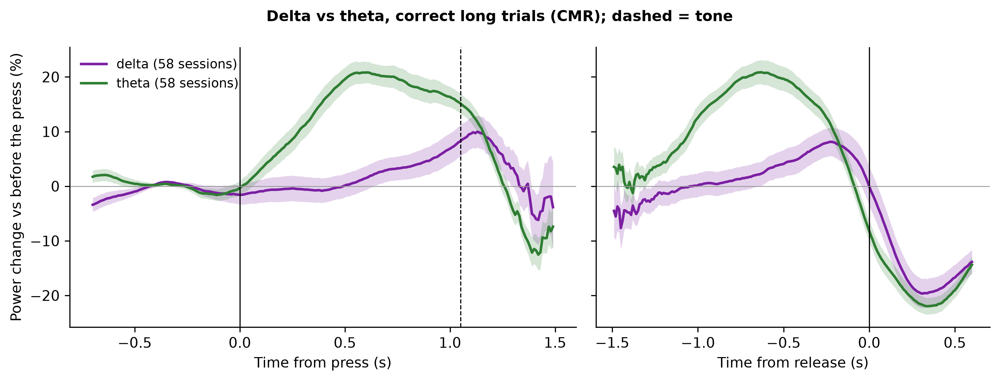

c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


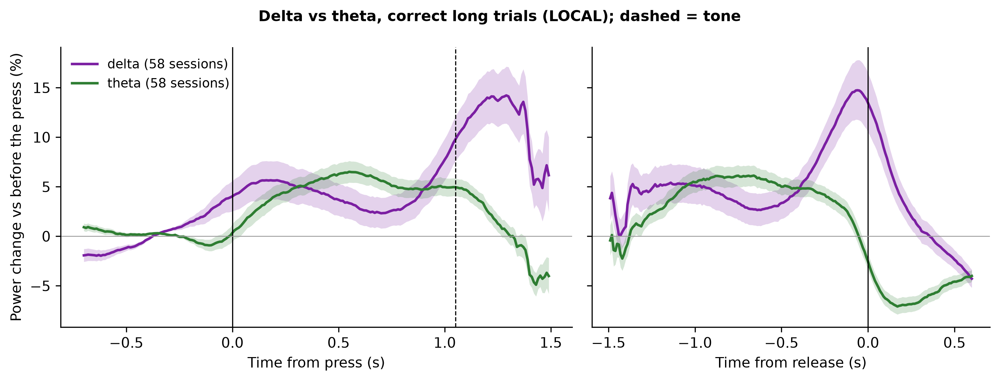

In [17]:
# ── 1r. QUICK LOOK: DELTA vs THETA TIME COURSE AROUND THE PRESS AND THE RELEASE (correct long) ──
pc = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
BCOL = {"delta 1-3": "#7B1FA2", "theta 4-7": "#2e7d32"}
out_dir = os.path.join(AMIR, "Theta", "delta check"); os.makedirs(out_dir, exist_ok=True)
for ref in ["CMR", "LOCAL"]:
    curves, times = {b: {"Press": [], "Release": []} for b in BCOL}, {}
    for s in done_sessions(ref):
        r = load_bp(s, ref)
        for al in ("Press", "Release"):
            times[al] = r["times"][al]
            for b in BCOL:
                c = fn.session_curve(r, al, b, "correct long", min_trials=10)
                if c is not None:
                    curves[b][al].append(c)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, facecolor="white", gridspec_kw=dict(width_ratios=[2.7, 2.1]))
    for k, al in enumerate(("Press", "Release")):
        for b, col in BCOL.items():
            X = np.vstack(curves[b][al]); n = np.sum(np.isfinite(X), 0)
            m = np.nanmean(X, 0); se = np.nanstd(X, 0, ddof=1) / np.sqrt(n)
            ok = n >= 0.5 * len(X)
            ax[k].plot(times[al][ok], pc(m[ok]), color=col, lw=1.8, label=f"{b.split()[0]} ({len(X)} sessions)")
            ax[k].fill_between(times[al][ok], pc((m - se)[ok]), pc((m + se)[ok]), color=col, alpha=0.2, lw=0)
        ax[k].axvline(0, color="k", lw=0.8); ax[k].axhline(0, color="0.6", lw=0.6)
        if al == "Press": ax[k].axvline(1.05, color="k", lw=0.8, ls="--")
        ax[k].set_xlabel(f"Time from {'press' if al == 'Press' else 'release'} (s)")
        for sp in ("top", "right"): ax[k].spines[sp].set_visible(False)
    ax[0].set_ylabel("Power change vs before the press (%)"); ax[0].legend(frameon=False, fontsize=9)
    fig.suptitle(f"Delta vs theta, correct long trials ({ref}); dashed = tone", fontsize=10.5, fontweight="bold")
    fig.tight_layout(); fp = os.path.join(out_dir, f"delta_vs_theta_timecourse_{ref}.png")
    fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))

20260510_r0000136_wt_1926: 60 trials, 20 channels
20260511_r0000136_wt_0909: 14 trials, 20 channels
20260511_r0000136_wt_0930: 34 trials, 20 channels
20260511_r0000136_wt_1832: 37 trials, 20 channels
20260512_r0000136_wt_1054: 50 trials, 20 channels
20260513_r0000136_wt_1729: 11 trials, 20 channels
20260514_r0000136_wt_1317: 12 trials, 20 channels
20260515_r0000135_wt_1953: 58 trials, 20 channels
20260515_r0000135_wt_1957: 16 trials, 20 channels
20260515_r0000136_wt_1817: 30 trials, 20 channels
20260517_r0000135_wt_1846: 12 trials, 20 channels
20260517_r0000136_wt_1557: 53 trials, 20 channels
20260519_r0000136_wt_2031: 38 trials, 20 channels
20260520_r0000135_wt_1357: 20 trials, 21 channels
20260520_r0000136_wt_1443: 39 trials, 20 channels
20260521_r0000135_wt_1309: 28 trials, 21 channels
20260521_r0000136_wt_1221: 37 trials, 20 channels
20260522_r0000135_wt_1716: 32 trials, 21 channels
20260522_r0000136_wt_1750: 55 trials, 20 channels
20260523_r0000135_wt_1320: 20 trials, 21 channels


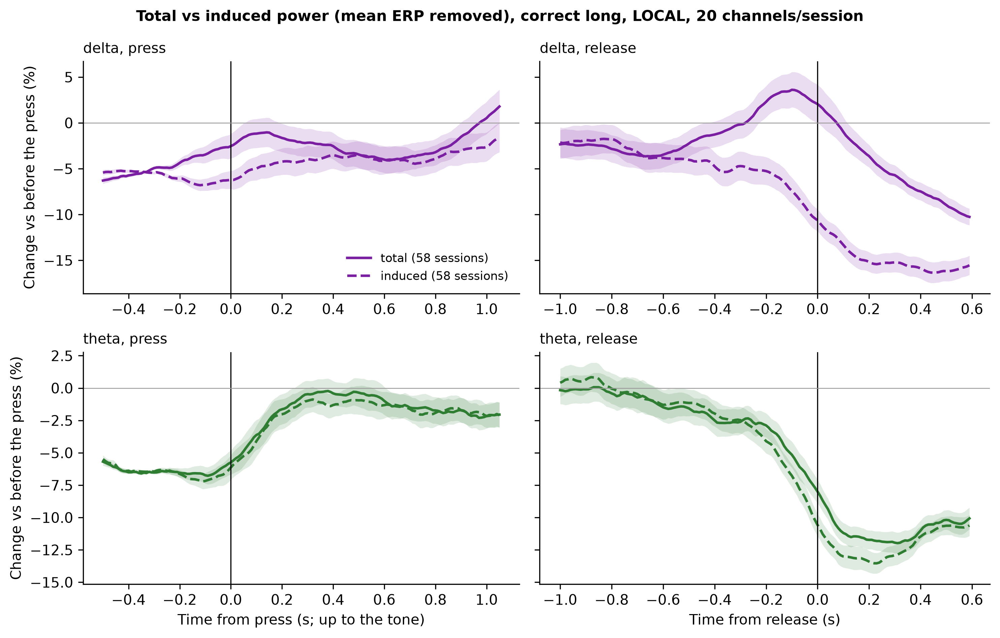

In [18]:
# ── 1s. DELTA PEAK AT THE RELEASE: TOTAL vs INDUCED POWER (ERP removed) ──
import scipy.fft as sfft
from IPython.display import Image, display
REF_D, N_CH, DEC, ONLY_TEST = "LOCAL", 20, 10, False          # ONLY_TEST = True -> run on TEST first (fast check)
BANDS_D = {b: fn.MAIN_BANDS[b] for b in ["delta 1-3", "theta 4-7"]}
EP   = {"Press": (-2.5, 3.5), "Release": (-3.0, 2.5)}          # same epochs as 06
SHOW = {"Press": (-0.5, 1.05), "Release": (-1.0, 0.6)}
PRE, PEAK = (-0.5, -0.2), (-0.2, 0.1)
PT = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), low_memory=False)
out_dir = os.path.join(AMIR, "Theta", "delta check"); os.makedirs(out_dir, exist_ok=True)

def band_pow(X, fs, band):
    """(trials, ch, n) -> mean Morlet power over the band's frequencies (trials, ch, n // DEC), as in 06."""
    n = X.shape[-1]; nfft = int(2 ** np.ceil(np.log2(n + 4 * fs)))
    Xf = sfft.fft(X, nfft, axis=-1, workers=-1)
    return np.mean([fn._power(Xf, nfft, n, f, band["n_cycles"], fs, DEC) for f in band["freqs"]], axis=0)

sessions = [TEST] if ONLY_TEST else list(final["session"])
CUR = {(b, k, al): [] for b in BANDS_D for k in ("total", "induced") for al in EP}; SHARE, TT = [], {}
for s in sessions:
    tr = fn.session_trials(PT, s); tr = tr[(tr.label == "correct") & (tr.type == "long")].reset_index(drop=True)
    if len(tr) < 10:
        continue
    recs, _ = fn.load_session(PROC, s, extra_bad=XB, refs=(REF_D,)); rec = recs[REF_D]
    sel = set(fn.select_channels(fn.probe_table(rec), N_CH)["channel_id"])
    ids = [c for c in rec.get_channel_ids() if str(c) in sel]
    sub = rec.select_channels(ids) if hasattr(rec, "select_channels") else rec.channel_slice(ids)
    fs = sub.get_sampling_frequency()
    X, ok = {}, {}
    for al, col in (("Press", "press_s"), ("Release", "release_s")):
        X[al], ok[al] = fn.read_epochs(sub, tr[col].values, *EP[al])
    keep = ok["Press"] & ok["Release"]                              # same trials in both alignments
    X = {al: X[al][keep[ok[al]]] for al in X}
    t = {al: EP[al][0] + np.arange(0, X[al].shape[-1], DEC) / fs for al in X}; TT = t
    for b, band in BANDS_D.items():
        P = {}
        for k in ("total", "induced"):
            for al in X:
                Xk = X[al] if k == "total" else X[al] - X[al].mean(axis=0, keepdims=True)   # remove the mean ERP
                P[(k, al)] = band_pow(Xk, fs, band)
            pm = (t["Press"] >= PRE[0]) & (t["Press"] <= PRE[1])
            base = P[(k, "Press")][..., pm].mean(axis=-1, keepdims=True)                     # own pre-press power
            for al in X:
                sm = (t[al] >= SHOW[al][0]) & (t[al] <= SHOW[al][1])
                CUR[(b, k, al)].append(np.median(np.log10(P[(k, al)][..., sm] / base).mean(axis=0), axis=0))
        rm = (t["Release"] >= PEAK[0]) & (t["Release"] <= PEAK[1])
        share = 1 - np.median(P[("induced", "Release")][..., rm].mean(axis=(0, 2)) / P[("total", "Release")][..., rm].mean(axis=(0, 2)))
        SHARE.append({"session": s, "band": b, "evoked_share_%": 100 * share, "n_trials": int(keep.sum())})
    print(f"{s}: {int(keep.sum())} trials, {len(ids)} channels", flush=True)

SH = pd.DataFrame(SHARE)
print(f"\nEvoked share of power around the release ({PEAK[0]}..{PEAK[1]} s), {REF_D}: mean over sessions (min–max)")
print(SH.groupby("band")["evoked_share_%"].agg(["mean", "min", "max"]).round(1).to_string())

# figure: rows = delta, theta; columns = press, release; solid = total, dashed = induced
BC = {"delta 1-3": "#7B1FA2", "theta 4-7": "#2e7d32"}
fig, ax = plt.subplots(2, 2, figsize=(10, 6.4), sharey="row", facecolor="white", gridspec_kw=dict(width_ratios=[1.55, 1.6]))
for i, b in enumerate(BANDS_D):
    for j, al in enumerate(EP):
        sm = (TT[al] >= SHOW[al][0]) & (TT[al] <= SHOW[al][1]); x = TT[al][sm]
        for k, ls in (("total", "-"), ("induced", "--")):
            Y = np.vstack(CUR[(b, k, al)]); m, se = Y.mean(0), Y.std(0, ddof=1) / np.sqrt(len(Y))
            ax[i, j].plot(x, pc(m), ls, color=BC[b], lw=1.8, label=f"{k} ({len(Y)} sessions)")
            ax[i, j].fill_between(x, pc(m - se), pc(m + se), color=BC[b], alpha=0.15, lw=0)
        ax[i, j].axvline(0, color="k", lw=0.8); ax[i, j].axhline(0, color="0.6", lw=0.6)
        ax[i, j].set_title(f"{b.split()[0]}, {'press' if al == 'Press' else 'release'}", fontsize=10, loc="left")
        for sp in ("top", "right"): ax[i, j].spines[sp].set_visible(False)
    ax[i, 0].set_ylabel("Change vs before the press (%)")
ax[0, 0].legend(frameon=False, fontsize=8.5)
ax[1, 0].set_xlabel("Time from press (s; up to the tone)"); ax[1, 1].set_xlabel("Time from release (s)")
fig.suptitle(f"Total vs induced power (mean ERP removed), correct long, {REF_D}, {N_CH} channels/session",
             fontsize=10.5, fontweight="bold"); fig.tight_layout()
fp = os.path.join(out_dir, f"delta_total_vs_induced_{REF_D}.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
SH.to_csv(os.path.join(out_dir, f"delta_evoked_share_{REF_D}.csv"), index=False)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1f. Theta power across time (pilot: 20 channels, 49 correct long trials)
Look at the data before any computation: raw theta power (log10 of the mean Morlet power over 4, 5, 6, 7 Hz, 5 cycles; a.u.)
over time, NO baseline subtraction; mean over the 49 correct long trials, then over the 20 selected channels (fn.select_channels);
test session 20260529_r0000136_wt_1318, CMR. Left: around the press (pre and hold windows shaded); right: around the release (post shaded).
No test. Printed: raw window values and hold − pre / hold − post (mean of log; close to, not identical with, the window values of 06).
Saved: amir_data\Theta\20 selected channels_pilot\pilot theta across time.png

<div>

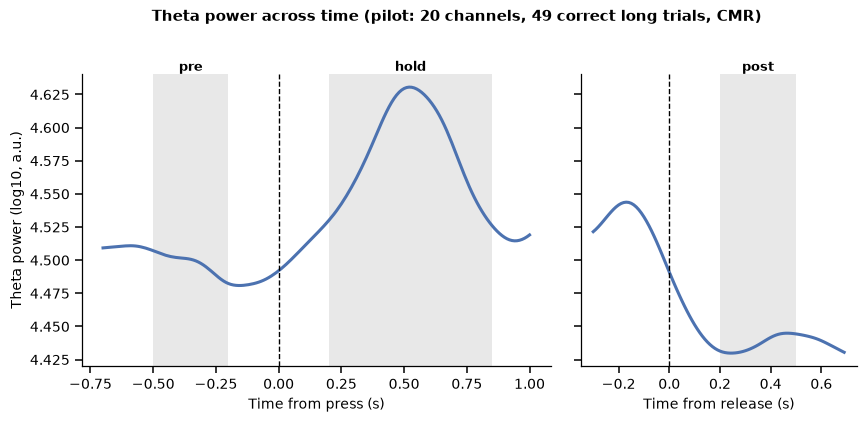

raw theta (log10 a.u.): pre 4.498 | hold 4.583 | post 4.437
hold − pre +0.086 -> +21.9 % | hold − post +0.146 -> +40.1 %


In [84]:
# %%
# ── raw theta power over time (BEFORE the baseline subtraction), test session, 20 channels, correct long ──
importlib.reload(fn)
import scipy.signal as ss

PROC = os.path.join(DATA_ROOT, "2_processed")
XB   = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
SES_R, REF_R, BAND, DEC = TEST, "CMR", "theta 4-7", 10

# trials and the same 20 channels as the pilot
r  = load_bp(SES_R, REF_R)
T, meta = r["trials"], r["meta"]
cl = ((T["label"] == "correct") & (T["type"] == "long")).values
pdf = pd.DataFrame({"channel_id": meta["channel_ids"], "x": meta["x"], "y": meta["y"]})
pdf["shank"] = (pdf["x"] // 250).astype(int)
sel_ids = [str(c) for c in fn.select_channels(pdf, n_total=20)["channel_id"]]

# recording, 20 channels
recs, _ = fn.load_session(PROC, SES_R, XB, refs=(REF_R,))
rec = recs[REF_R]
full = [str(c) for c in rec.get_channel_ids()]
objs = [rec.get_channel_ids()[full.index(c)] for c in sel_ids]
recN = rec.select_channels(objs) if hasattr(rec, "select_channels") else rec.channel_slice(channel_ids=objs)
fs = recN.get_sampling_frequency()

def theta_raw(event_col, align):
    """log10 of the mean theta power (4–7 Hz) over time, per trial and channel"""
    a0, a1 = fn.MAIN_EPOCHS[align]
    X, ok = fn.read_epochs(recN, T.loc[cl, event_col].values, a0, a1)
    X = X.astype(np.float64)
    spec = fn.MAIN_BANDS[BAND]
    Pw = np.mean([np.abs(ss.fftconvolve(X, fn.morlet(f, spec["n_cycles"], fs)[None, None, :], mode="same", axes=-1)) ** 2
                  for f in spec["freqs"]], axis=0)[..., ::DEC]
    tt = (np.arange(X.shape[-1]) / fs + a0)[::DEC]
    return tt, np.log10(Pw)                                      # (trials, channels, times)

tP, rawP = theta_raw("press_s", "Press")
tR, rawR = theta_raw("release_s", "Release")
avg = lambda Z: Z.mean(axis=0).mean(axis=0)                     # mean over trials, then channels

# figure
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, facecolor="white",
                         gridspec_kw={"width_ratios": [1.7, 1.0], "wspace": 0.08})
for ax, tt, Z, rng_, win, xl in ((axes[0], tP, rawP, (-0.7, 1.0), ["pre", "hold"], "Time from press (s)"),
                                 (axes[1], tR, rawR, (-0.3, 0.7), ["post"], "Time from release (s)")):
    m_ = (tt >= rng_[0]) & (tt <= rng_[1])
    ax.plot(tt[m_], avg(Z)[m_], color="#4C72B0", lw=2.2)
    for name in win:
        a, z = fn.MAIN_WINDOWS[name][1]
        ax.axvspan(a, z, color="0.85", alpha=0.6, zorder=0, lw=0)
        ax.text((a + z) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.axvline(0, color="k", ls="--", lw=1); ax.set_xlabel(xl)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel("Theta power (log10, a.u.)")
fig.suptitle(f"Theta power across time (pilot: {len(sel_ids)} channels, {cl.sum()} correct long trials, {REF_R})",
             fontsize=11, fontweight="bold", y=1.05)
theta_dir = os.path.join(AMIR, "Theta", "20 selected channels_pilot"); os.makedirs(theta_dir, exist_ok=True)
fig.savefig(os.path.join(theta_dir, "pilot theta across time.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# numbers: raw window values and the difference
w = lambda tt, Z, name: Z[..., (tt >= fn.MAIN_WINDOWS[name][1][0] - 1e-9) & (tt <= fn.MAIN_WINDOWS[name][1][1] + 1e-9)].mean()
pre, hold, post = w(tP, rawP, "pre"), w(tP, rawP, "hold"), w(tR, rawR, "post")
print(f"raw theta (log10 a.u.): pre {pre:.3f} | hold {hold:.3f} | post {post:.3f}")
print(f"hold − pre {hold - pre:+.3f} -> {100 * (10 ** (hold - pre) - 1):+.1f} % | hold − post {hold - post:+.3f} -> {100 * (10 ** (hold - post) - 1):+.1f} %")

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1g. Theta time course in all long trials: correct, late, early (all sessions, all rats)
Long trials only (tone at 1.05 s), so the windows mean the same in every condition. Curves from the band-power files (06),
each trial only while the paw is on the lever. Per session: condition with >= 10 trials (correct long) or >= 5 (late long,
early long held > 0.3 s); median over channels; time point kept if >= 50 % of the trials are on the lever.
Across sessions: mean ± SEM (session = unit); time point drawn if >= 50 % of the sessions have a value. No tests.
- Figure 1: theta power across time, no baseline (log10, a.u.; rebuilt as change curve + the condition's own pre-press level,
because raw curves were not saved in 06 — same shape as Figure 2).
- Figure 2: hold and after the release, both compared to before the press (%).
- Figure 3: hold compared to before the press (left, pre = 0) and hold compared to after the release (right, post = 0; %).Result (CMR): the same rise in all outcomes, peak about 0.55 s after the press (correct +21 %, late +20 %, early +26 %);
hold vs pre [ ] / [ ] / [ ] %, hold vs post [ ] / [ ] / [ ] % (from the printout).
Saved: amir_data\Theta\all long trials\ theta_raw_timecourse_long_<ref>.png, theta_hold_post_vs_pre_long_<ref>.png,
theta_hold_vs_pre_and_post_long_<ref>.png

<div>

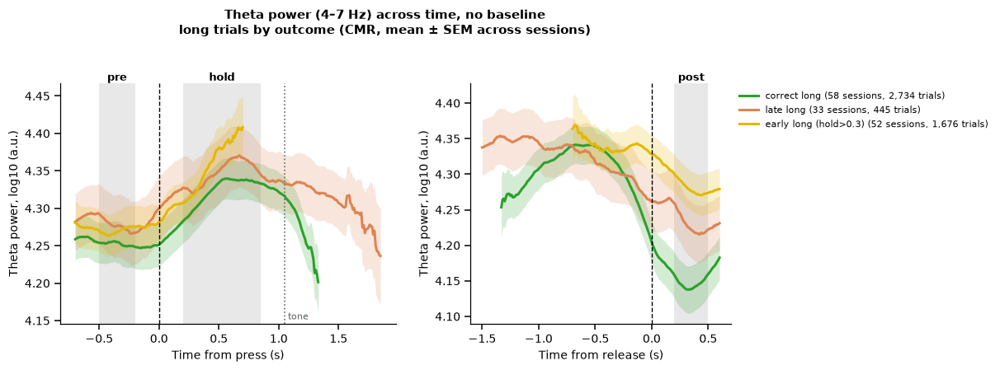

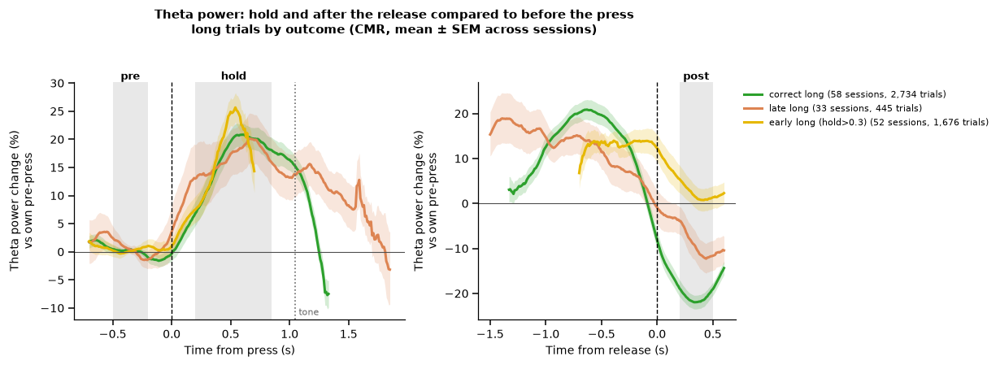

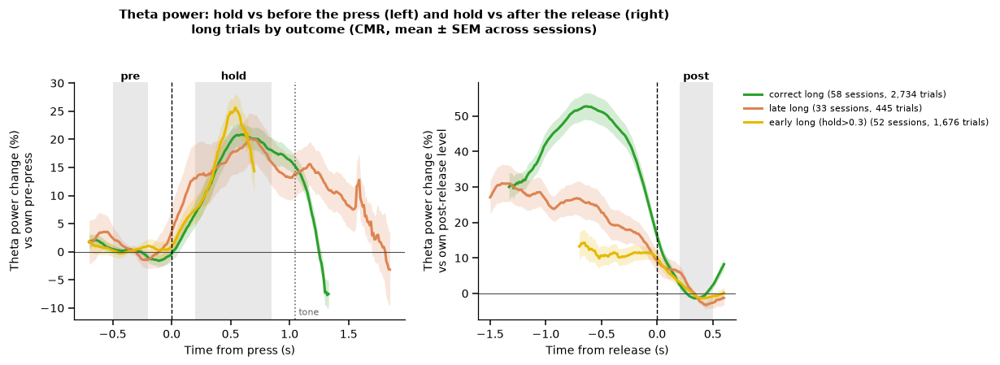

correct long             58 sessions, 2,734 trials | peak +21 % at 0.60 s | hold vs pre +16.7 % | hold vs post +47.5 %
late long                33 sessions,   445 trials | peak +20 % at 0.66 s | hold vs pre +16.7 % | hold vs post +28.6 %
early long (hold>0.3)    52 sessions, 1,676 trials | peak +26 % at 0.54 s | hold vs pre +16.9 % | hold vs post +14.4 %
saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\all long trials


In [86]:
# %%
# ── 1g. THETA TIME COURSE, all long trials (all sessions, all rats): correct, late, early long — no tests ──
importlib.reload(fn)
REF_TC, BAND = "CMR", "theta 4-7"                 # "LOCAL" for the LOCAL version
MIN_TRIALS = {"correct long": 10, "late long": 5, "early long (hold>0.3)": 5}   # per session
MIN_ON, MIN_FRAC, MIN_SES_FRAC = 3, 0.5, 0.5
CONDS = {"correct long": "#2CA02C", "late long": "#DD8452", "early long (hold>0.3)": "#E6B800"}
ALIGN = [("Press", "Time from press (s)"), ("Release", "Time from release (s)")]
TONE_LONG = 1.05
pc = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
long_dir = os.path.join(AMIR, "Theta", "all long trials"); os.makedirs(long_dir, exist_ok=True)

def win_mask(t, name):
    a, z = fn.MAIN_WINDOWS[name][1]
    return (t >= a - 1e-9) & (t <= z + 1e-9)

# 1) per session and condition: change curve (vs own pre-press, as stored), raw curve, hold and post levels
SC = {c: [] for c in CONDS}; TT = {}
for s in done_sessions(REF_TC):
    r = load_bp(s, REF_TC); cm = fn.main_conditions(r["trials"])
    for al, _ in ALIGN:
        TT.setdefault(al, r["times"][al])
    for c in CONDS:
        k = cm[c].values; n = int(k.sum())
        if n < MIN_TRIALS[c]:
            continue
        cur, raw = {}, {}
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            pre_ch = np.nanmean(r["logpow"][BAND]["pre"][k], axis=0)            # (channels,) pre-press level of this condition
            for al, _ in ALIGN:
                C = r["curves"][al][BAND][c]                                     # (channels, times), vs own pre-press
                ok = r["counts"][al][c] >= max(MIN_ON, MIN_FRAC * n)             # >= 50 % of the trials on the lever
                cur[al] = np.where(ok, np.nanmedian(C, axis=0), np.nan)
                raw[al] = np.where(ok, np.nanmedian(C + pre_ch[:, None], axis=0), np.nan)
        if any(len(cur[al]) != len(TT[al]) for al, _ in ALIGN):
            continue
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            hold = np.nanmean(cur["Press"][win_mask(TT["Press"], "hold")])       # hold level (on the lever), vs pre
            post = np.nanmean(cur["Release"][win_mask(TT["Release"], "post")])   # post level, vs pre
        SC[c].append({"session": s, "rat": RAT[s], "n": n, "cur": cur, "raw": raw, "hold": hold, "post": post})

def summary(c, al, mode):
    """mean ± SEM across sessions. mode 'raw': log10 power; 'pre': % vs pre-press; 'hold': release part % vs hold level"""
    rows = [x for x in SC[c] if mode != "post" or np.isfinite(x["post"])]
    if mode == "raw":
        X = np.array([x["raw"][al] for x in rows])
    else:
        X = np.array([x["cur"][al] - (x["post"] if (mode == "post" and al == "Release") else 0) for x in rows])
    n_s = np.sum(np.isfinite(X), 0); ok = n_s >= max(3, MIN_SES_FRAC * len(X))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        m, se = np.nanmean(X, 0), np.nanstd(X, 0, ddof=1) / np.sqrt(n_s)
    f = (lambda v: v) if mode == "raw" else pc
    return TT[al][ok], f(m)[ok], f(m - se)[ok], f(m + se)[ok]

info = lambda c: (len(SC[c]), sum(x["n"] for x in SC[c]))
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9})

def style(ax, al, xlabel, wins, zero=True):
    if zero:
        ax.axhline(0, color="0.3", lw=0.8)
    ax.axvline(0, color="k", ls="--", lw=1)
    for name in wins:
        a, z = fn.MAIN_WINDOWS[name][1]
        ax.axvspan(a, z, color="0.85", alpha=0.6, zorder=0, lw=0)
        ax.text((a + z) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, fontweight="bold")
    if al == "Press":
        ax.axvline(TONE_LONG, color="0.4", ls=":", lw=1.2)
        ax.text(TONE_LONG, 0.02, " tone", transform=ax.get_xaxis_transform(), fontsize=8, color="0.4")
    ax.set_xlabel(xlabel)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

def make_fig(mode, title, ylabels, fname):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), facecolor="white", gridspec_kw={"width_ratios": [2.7, 2.1], "wspace": 0.25})
    for ax, (al, xl), yl in zip(axes, ALIGN, ylabels):
        for c in CONDS:
            if len(SC[c]) < 3:
                continue
            tt, m, lo, hi = summary(c, al, mode); n_s, n_t = info(c)
            ax.fill_between(tt, lo, hi, color=CONDS[c], alpha=0.2, lw=0)
            ax.plot(tt, m, color=CONDS[c], lw=2.2, label=f"{c} ({n_s} sessions, {n_t:,} trials)")
        style(ax, al, xl, ["pre", "hold"] if al == "Press" else ["post"], zero=(mode != "raw"))
        ax.set_ylabel(yl)
    axes[1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    fig.suptitle(f"{title}\nlong trials by outcome ({REF_TC}, mean ± SEM across sessions)", fontsize=11, fontweight="bold", y=1.12)
    fig.savefig(os.path.join(long_dir, fname), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# Figure 1: theta power across time, no baseline
make_fig("raw", "Theta power (4–7 Hz) across time, no baseline",
         ["Theta power, log10 (a.u.)", "Theta power, log10 (a.u.)"], f"theta_raw_timecourse_long_{REF_TC}.png")
# Figure 2: hold and after the release, both vs before the press
make_fig("pre", "Theta power: hold and after the release compared to before the press",
         ["Theta power change (%)\nvs own pre-press", "Theta power change (%)\nvs own pre-press"],
         f"theta_hold_post_vs_pre_long_{REF_TC}.png")
# Figure 3: hold vs before the press (left), hold vs after the release (right; post level = 0)
make_fig("post", "Theta power: hold vs before the press (left) and hold vs after the release (right)",
         ["Theta power change (%)\nvs own pre-press", "Theta power change (%)\nvs own post-release level"],
         f"theta_hold_vs_pre_and_post_long_{REF_TC}.png")

# numbers (no tests): peak, hold vs pre, hold vs post — mean across sessions
for c in CONDS:
    if len(SC[c]) < 3:
        continue
    tt, m, _, _ = summary(c, "Press", "pre"); i = np.nanargmax(m)
    h = np.array([x["hold"] for x in SC[c]]); hp = np.array([x["hold"] - x["post"] for x in SC[c]])
    n_s, n_t = info(c)
    print(f"{c:24s} {n_s:2d} sessions, {n_t:5,} trials | peak {m[i]:+.0f} % at {tt[i]:.2f} s | "
          f"hold vs pre {pc(np.nanmean(h)):+.1f} % | hold vs post {pc(np.nanmean(hp)):+.1f} %")
print("saved in:", long_dir)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1h. Theta during the hold, all long trials pooled (correct + late + early held >= 0.85 s), CMR and LOCAL
Same as 1e, but per session all long trials whose hold window lies completely on the lever are pooled:
all correct long, all late long, and early long trials held >= 0.85 s (the stored hold window 0.20–0.85 s is not cut at the release,
so shorter early trials are left out). Per channel: mean over trials of log10(hold / pre) and log10(hold / post); median over channels
-> one value per session (>= 10 pooled trials). One dot = one session (colour = rat), black = mean ± SEM over sessions.
Sign-flip test across sessions (10,000 flips), raw p (p floor 0.0001 -> reported as p < 0.001).
Question: is the theta rise during the hold present across all long trials, not only correct ones (the rise is the same in all outcomes, 1g)?
Saved: tables\theta_all_long_pooled_<ref>.csv, amir_data\Theta\all_sessions_theta_all_long_<ref>.png

<div>

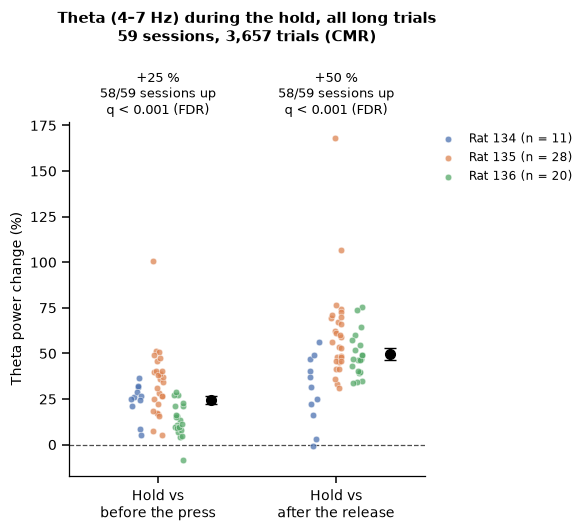

CMR: 59 sessions, 3657 trials: correct 2740, late 490, early (held >= 0.85 s) 427 | per rat: {'134': 11, '135': 28, '136': 20}


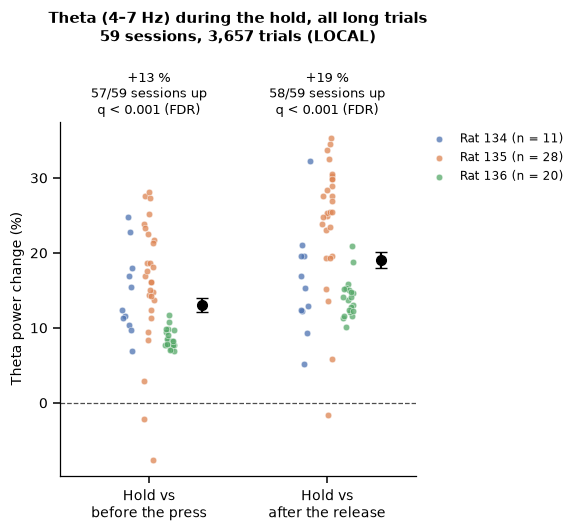

LOCAL: 59 sessions, 3657 trials: correct 2740, late 490, early (held >= 0.85 s) 427 | per rat: {'134': 11, '135': 28, '136': 20}

theta, all long trials pooled — CMR vs LOCAL
  ref   measure  n_sessions  sessions_up  mean_%      p      q
  CMR  hold-pre          59           58    24.5 0.0001 0.0001
  CMR hold-post          59           58    49.7 0.0001 0.0001
LOCAL  hold-pre          59           57    13.0 0.0001 0.0001
LOCAL hold-post          59           58    19.0 0.0001 0.0001
saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\all long trials


In [93]:
# %%
# ── 1h. THETA DURING THE HOLD, ALL LONG TRIALS POOLED (correct + late + early held >= 0.85 s), CMR and LOCAL ──
from statsmodels.stats.multitest import multipletests
BAND, MIN_TR = "theta 4-7", 10
HOLD_FULL = fn.MAIN_WINDOWS["hold"][1][1]               # 0.85 s
RCOL = {"134": "#4C72B0", "135": "#DD8452", "136": "#55A868"}
PAN  = [("hold-pre", "Hold vs\nbefore the press"), ("hold-post", "Hold vs\nafter the release")]
pc   = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
long_dir = os.path.join(AMIR, "Theta", "all long trials"); os.makedirs(long_dir, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9, "font.family": "sans-serif"})

summary_rows = []
for REF_P in ["CMR", "LOCAL"]:
    rows = []
    for s in done_sessions(REF_P):
        r = load_bp(s, REF_P)
        T, lp = r["trials"], r["logpow"][BAND]
        lab, lng = T["label"].values, (T["type"] == "long").values
        mk = lng & (np.isin(lab, ["correct", "late"]) | ((lab == "early") & (T["hold_s"].values >= HOLD_FULL)))
        if mk.sum() < MIN_TR:
            continue
        rows.append({"session": s, "rat": RAT[s], "n": int(mk.sum()),
                     "n_correct": int((mk & (lab == "correct")).sum()), "n_late": int((mk & (lab == "late")).sum()),
                     "n_early": int((mk & (lab == "early")).sum()),
                     "hold-pre":  float(np.median((lp["hold"][mk] - lp["pre"][mk]).mean(0))),
                     "hold-post": float(np.median((lp["hold"][mk] - lp["post"][mk]).mean(0)))})
    PL = pd.DataFrame(rows)
    PL.to_csv(os.path.join(TABLES, f"theta_all_long_pooled_{REF_P}.csv"), index=False)
    n_ses, n_tr = PL["session"].nunique(), int(PL["n"].sum())
    tests = {col: fn.sign_flip_p(PL[col].values) for col, _ in PAN}
    QH = dict(zip(tests, multipletests([t[1] for t in tests.values()], method="fdr_bh")[1]))   # FDR over the 2 tests

    fig, ax = plt.subplots(figsize=(4.6, 4.6), facecolor="white")
    rng = np.random.default_rng(0)
    for i, (col, _) in enumerate(PAN):
        v = pc(PL[col])
        for k, rat in enumerate(sorted(RCOL)):
            vr = v[PL["rat"] == rat]
            ax.scatter(i + (k - 1) * 0.12 + rng.uniform(-0.03, 0.03, len(vr)), vr, s=22, color=RCOL[rat],
                       alpha=0.75, edgecolor="white", linewidth=0.4, zorder=2,
                       label=f"Rat {rat} (n = {len(vr)})" if i == 0 else None)
        m, p, n = tests[col]
        mean_pct, sem_pct = pc(m), v.std(ddof=1) / np.sqrt(len(v))
        ax.errorbar(i + 0.30, mean_pct, yerr=sem_pct, fmt="o", color="k", ms=7, capsize=4, lw=1.6, zorder=4)
        ps = "q < 0.001 (FDR)" if QH[col] < 0.001 else f"q = {QH[col]:.3f} (FDR)"
        up = int((PL[col] > 0).sum())
        ax.text(i, 1.01, f"{mean_pct:+.0f} %\n{up}/{n} sessions up\n{ps}",
                transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9)
        summary_rows.append({"ref": REF_P, "measure": col, "n_sessions": n, "sessions_up": up,
                             "mean_%": round(float(mean_pct), 1), "p": p, "q": QH[col]})
    ax.axhline(0, color="0.3", lw=0.9, ls="--", zorder=1)
    ax.set_xticks(range(len(PAN))); ax.set_xticklabels([t for _, t in PAN]); ax.set_xlim(-0.5, len(PAN) - 0.5)
    ax.set_ylabel("Theta power change (%)")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax.set_title(f"Theta (4–7 Hz) during the hold, all long trials\n{n_ses} sessions, {n_tr:,} trials ({REF_P})",
                 fontsize=11, fontweight="bold", pad=58)
    fig.savefig(os.path.join(long_dir, f"theta_all_long_pooled_{REF_P}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"{REF_P}: {n_ses} sessions, {n_tr} trials: correct {PL['n_correct'].sum()}, late {PL['n_late'].sum()}, "
          f"early (held >= {HOLD_FULL} s) {PL['n_early'].sum()} | per rat:", PL.groupby("rat")["session"].nunique().to_dict())

print("\ntheta, all long trials pooled — CMR vs LOCAL")
print(pd.DataFrame(summary_rows).round({"p": 4, "q": 4}).to_string(index=False))
print("saved in:", long_dir)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1i. Theta during the hold per region (PL, IL, Cg1), CMR and LOCAL (personal note)
Exploratory only (no region hypothesis) — not for the report.
Correct long trials (>= 10 per session). Per channel: mean over trials of log10(hold / pre) and log10(hold / post);
per region (channel_regions_all.csv, fn.region_masks; >= 10 channels in the region): median over the region's channels
-> one value per session and region. Sign-flip across sessions (10,000 flips): each region vs 0, and paired region differences
(IL − PL, IL − Cg1, PL − Cg1; sessions with both regions). Per rat: mean % only.
FDR (Benjamini–Hochberg) per reference: regions 3 × 2 comparisons = 6 tests; differences 3 pairs × 2 comparisons = 6 tests -> q.
Paper (Fakhraei 2021): PL (A32D) only as one SVM feature; IL not reported; no region comparison.
Saved: tables\theta_regions_values.csv, theta_regions_stats.csv;
amir_data\Theta\across regions\theta_regions_CMR.png, theta_regions_LOCAL.png

<div>


===== theta, CMR: regions and differences (all rats; p_fdr per family of 6) =====
  measure     test  n_sessions  up  mean_%      p  p_fdr
 hold-pre       PL          56  55    25.3 0.0001 0.0001
 hold-pre       IL          58  53    29.4 0.0001 0.0001
 hold-pre      Cg1          42  40    19.7 0.0001 0.0001
hold-post       PL          56  55    54.1 0.0001 0.0001
hold-post       IL          58  57    79.4 0.0001 0.0001
hold-post      Cg1          42  40    39.2 0.0001 0.0001
 hold-pre  IL − PL          56  31     4.0 0.0994 0.0994
 hold-pre IL − Cg1          42  31    13.2 0.0004 0.0005
 hold-pre PL − Cg1          42  30     7.9 0.0002 0.0003
hold-post  IL − PL          56  47    17.2 0.0001 0.0002
hold-post IL − Cg1          42  39    37.6 0.0001 0.0002
hold-post PL − Cg1          42  37    14.4 0.0001 0.0002
--- per rat (hold-pre, mean %) ---
rat      134     135     136
test                        
Cg1   18.8 %  20.7 %  17.9 %
IL    42.2 %  38.9 %  11.7 %
PL    19.0 %  36.5 %  14.

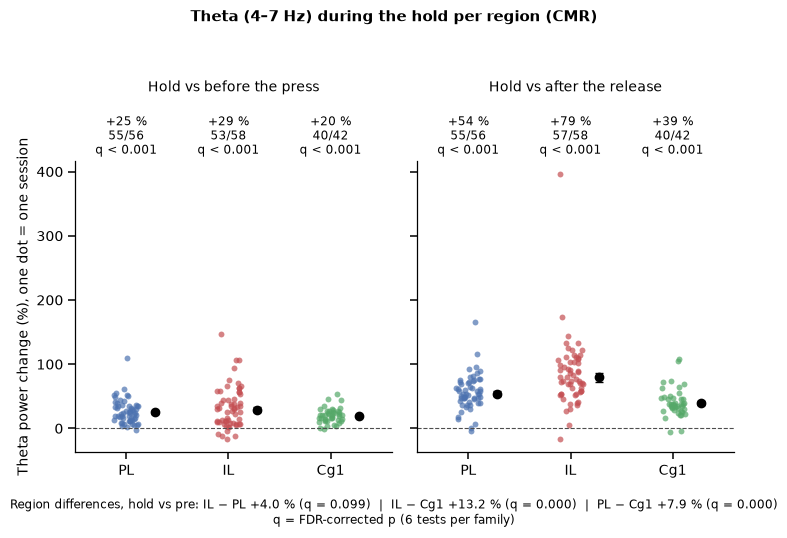

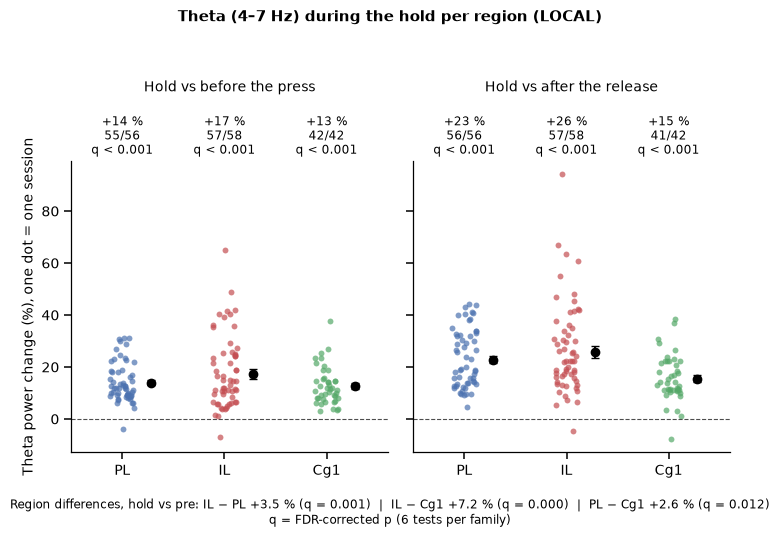

saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\across regions


In [89]:
# %%
# ── 1i. THETA DURING THE HOLD PER REGION (PL, IL, Cg1), CMR and LOCAL (personal note) ──
from statsmodels.stats.multitest import multipletests
fdr = lambda p: multipletests(np.asarray(p, float), alpha=0.05, method="fdr_bh")[1]
pc  = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
BAND, MIN_CL, MIN_CH = "theta 4-7", 10, 10
REGS  = list(fn.REGIONS)                                     # PL, IL, Cg1
PAIRS = [("IL", "PL"), ("IL", "Cg1"), ("PL", "Cg1")]
MEAS  = [("hold-pre", "pre"), ("hold-post", "post")]
GCOL  = {"PL": "#4C72B0", "IL": "#C44E52", "Cg1": "#55A868"}
reg_dir = os.path.join(AMIR, "Theta", "across regions"); os.makedirs(reg_dir, exist_ok=True)

# 1) one value per session x region x comparison x reference
rows = []
for ref in ["CMR", "LOCAL"]:
    for s in done_sessions(ref):
        r = load_bp(s, ref)
        cl = ((r["trials"]["label"] == "correct") & (r["trials"]["type"] == "long")).values
        if cl.sum() < MIN_CL:
            continue
        masks, _ = fn.region_masks(r, CHREG, s)
        L = r["logpow"][BAND]
        for reg, m in masks.items():
            if m.sum() < MIN_CH:
                continue
            for meas, w0 in MEAS:
                ch = (L["hold"][cl][:, m] - L[w0][cl][:, m]).mean(axis=0)
                rows.append({"ref": ref, "session": s, "rat": RAT[s], "region": reg, "n_ch": int(m.sum()),
                             "measure": meas, "value": float(np.median(ch))})
RV = pd.DataFrame(rows)
RV.to_csv(os.path.join(TABLES, "theta_regions_values.csv"), index=False)

# 2) statistics: each region vs 0, paired differences, per rat; FDR per reference and family
stats = []
for ref in ["CMR", "LOCAL"]:
    d = RV[RV["ref"] == ref]
    fam_r, fam_d = [], []
    for meas, _ in MEAS:
        W = d[d["measure"] == meas].pivot(index="session", columns="region", values="value")
        for reg in REGS:
            v = W[reg].dropna(); m, p, n = fn.sign_flip_p(v.values)
            fam_r.append({"ref": ref, "measure": meas, "test": reg, "n_sessions": n, "up": int((v > 0).sum()), "mean_%": pc(m), "p": p})
            for rat in sorted(d["rat"].unique()):
                vr = v[[RAT[s] == rat for s in v.index]]
                if len(vr) >= 2:
                    mr, pr, nr = fn.sign_flip_p(vr.values)
                    stats.append({"ref": ref, "measure": meas, "test": reg, "rat": rat, "n_sessions": nr,
                                  "up": int((vr > 0).sum()), "mean_%": pc(mr), "p": pr, "p_fdr": np.nan})
        for a, b in PAIRS:
            v = (W[a] - W[b]).dropna(); m, p, n = fn.sign_flip_p(v.values)
            fam_d.append({"ref": ref, "measure": meas, "test": f"{a} − {b}", "n_sessions": n, "up": int((v > 0).sum()), "mean_%": pc(m), "p": p})
    for fam in (fam_r, fam_d):
        q = fdr([x["p"] for x in fam])
        for x, qq in zip(fam, q):
            stats.append({**x, "rat": "all", "p_fdr": qq})
RS = pd.DataFrame(stats)
RS.to_csv(os.path.join(TABLES, "theta_regions_stats.csv"), index=False)

for ref in ["CMR", "LOCAL"]:
    print(f"\n===== theta, {ref}: regions and differences (all rats; p_fdr per family of 6) =====")
    t = RS[(RS["ref"] == ref) & (RS["rat"] == "all")][["measure", "test", "n_sessions", "up", "mean_%", "p", "p_fdr"]]
    print(t.round({"mean_%": 1, "p": 4, "p_fdr": 4}).to_string(index=False))
    print("--- per rat (hold-pre, mean %) ---")
    t = RS[(RS["ref"] == ref) & (RS["rat"] != "all") & (RS["measure"] == "hold-pre")]
    print(t.pivot(index="test", columns="rat", values="mean_%").round(1).astype(str).add(" %").to_string())
print("\nsessions with >= 10 channels per region:\n", RV[(RV["ref"] == "LOCAL") & (RV["measure"] == "hold-pre")]
      .groupby(["rat", "region"])["session"].nunique().unstack().to_string())

# 3) figure per reference: one dot = one session, per region, two comparisons
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9})
for ref in ["CMR", "LOCAL"]:
    d = RV[RV["ref"] == ref]
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 5.4), sharey=True, facecolor="white"); rng = np.random.default_rng(0)
    fig.subplots_adjust(top=0.70, bottom=0.16, wspace=0.08)
    for ax, (meas, _) in zip(axes, MEAS):
        for k, reg in enumerate(REGS):
            v = pc(d[(d["measure"] == meas) & (d["region"] == reg)]["value"])
            ax.scatter(k + rng.uniform(-0.12, 0.12, len(v)), v, s=18, color=GCOL[reg], alpha=0.7, lw=0)
            row = RS[(RS["ref"] == ref) & (RS["rat"] == "all") & (RS["measure"] == meas) & (RS["test"] == reg)].iloc[0]
            ax.errorbar(k + 0.28, row["mean_%"], yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt="o", color="k", ms=6, capsize=3, lw=1.4)
            ps = "q < 0.001" if row["p_fdr"] < 0.001 else f"q = {row['p_fdr']:.3f}"
            ax.text(k, 1.01, f"{row['mean_%']:+.0f} %\n{row['up']}/{row['n_sessions']}\n{ps}", transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=8.5)
        ax.axhline(0, color="0.3", lw=0.8, ls="--")
        ax.set_xticks(range(len(REGS))); ax.set_xticklabels(REGS); ax.set_xlim(-0.5, len(REGS) - 0.4)
        ax.set_title("Hold vs before the press" if meas == "hold-pre" else "Hold vs after the release", fontsize=10, pad=50)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    axes[0].set_ylabel("Theta power change (%), one dot = one session")
    diffs = RS[(RS["ref"] == ref) & (RS["rat"] == "all") & (RS["measure"] == "hold-pre") & RS["test"].str.contains("−")]
    sub = "  |  ".join(f"{x['test']} {x['mean_%']:+.1f} % (q = {x['p_fdr']:.3f})" for _, x in diffs.iterrows())
    fig.suptitle(f"Theta (4–7 Hz) during the hold per region ({ref})", fontsize=11, fontweight="bold", y=0.98)
    fig.text(0.5, 0.02, f"Region differences, hold vs pre: {sub}\nq = FDR-corrected p (6 tests per family)",
             ha="center", va="bottom", fontsize=8.5)
    fig.savefig(os.path.join(reg_dir, f"theta_regions_{ref}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
print("saved in:", reg_dir)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1j. Theta drops at the release, before the first lick (CMR and LOCAL)
Question: is the drop of theta after the release caused by licking?
A: per session, long trials of each outcome (>= 5): correct, late, early held >= 0.85 s (hold window fully on the lever);
per channel mean over trials of log10(post / hold); median over channels -> one value per session.
Sign-flip across sessions (10,000 flips): each outcome vs 0, and late − correct, early − correct (paired); FDR over the 5 tests -> q.
Shown as post vs hold (negative = drop; the same number as hold vs post with the sign flipped).
B: first lick after the release (tables\licks_after_release_long.csv), per outcome; the theta post window (0.2–0.5 s) shaded.
If the first lick comes after the post window, the drop starts before licking.
LOCAL reference: with CMR, late − correct differs; with LOCAL it does not.
Result (LOCAL): drop in correct [ ] %, late [ ] %, early [ ] %; late − correct q = [ ], early − correct q = [ ];
first lick median [ ] s after the release.
Saved: amir_data\Theta\check licks\theta_drop_before_licks_LOCAL.png

<div>

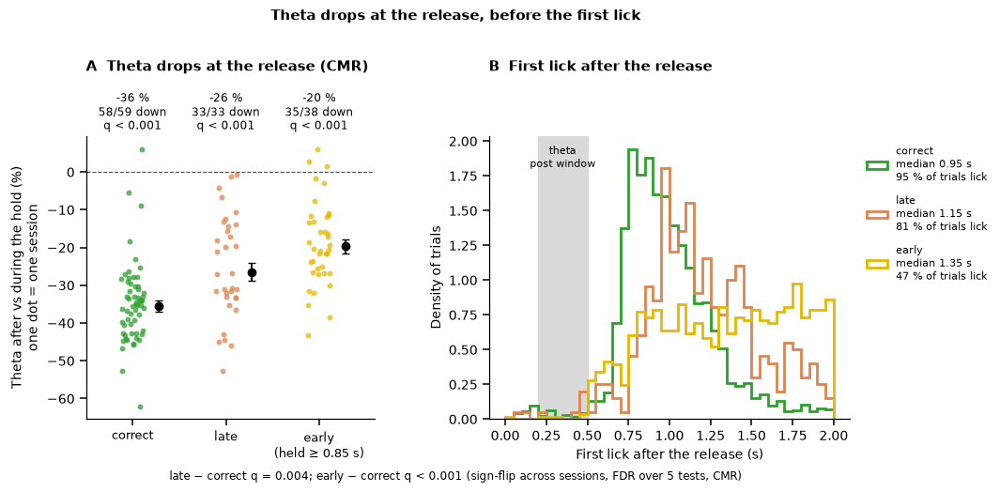

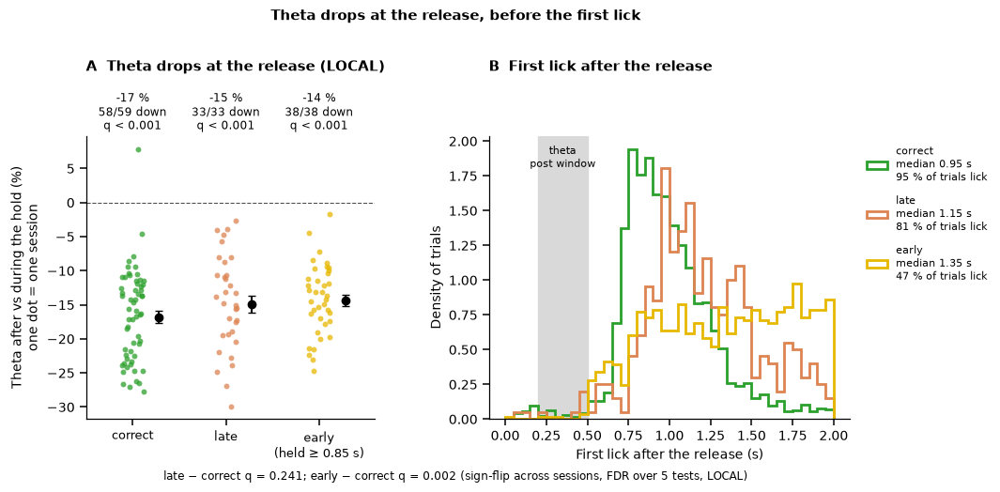

theta after vs during the hold — CMR vs LOCAL (FDR over 5 tests per reference)
  ref            test  n_sessions  down  mean_%      p      q
  CMR         correct          59  58.0   -35.5 0.0001 0.0001
  CMR            late          33  33.0   -26.5 0.0001 0.0001
  CMR           early          38  35.0   -19.7 0.0001 0.0001
  CMR  late − correct          33   NaN    10.4 0.0043 0.0043
  CMR early − correct          38   NaN    25.3 0.0001 0.0001
LOCAL         correct          59  58.0   -16.8 0.0001 0.0002
LOCAL            late          33  33.0   -14.9 0.0001 0.0002
LOCAL           early          38  38.0   -14.3 0.0001 0.0002
LOCAL  late − correct          33   NaN     1.1 0.2410 0.2410
LOCAL early − correct          38   NaN     4.0 0.0019 0.0024
first lick after the release (s), median: {'correct': 0.95, 'early': 1.35, 'late': 1.15}
saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\check licks


In [94]:
# %%
# ── 1j. THETA DROPS AT THE RELEASE, BEFORE THE FIRST LICK, CMR and LOCAL ──
from statsmodels.stats.multitest import multipletests
fdr = lambda p: multipletests(np.asarray(p, float), alpha=0.05, method="fdr_bh")[1]
pc  = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
BAND, MIN_TR = "theta 4-7", 5
HOLD_FULL = fn.MAIN_WINDOWS["hold"][1][1]                  # 0.85 s
CND  = {"correct": "#2CA02C", "late": "#DD8452", "early": "#E6B800"}
LABS = {"correct": "correct", "late": "late", "early": f"early\n(held ≥ {HOLD_FULL} s)"}
lick_dir = os.path.join(AMIR, "Theta", "check licks"); os.makedirs(lick_dir, exist_ok=True)
fmt_q = lambda x: "q < 0.001" if x < 0.001 else f"q = {x:.3f}"
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9})

# first lick after the release (table from the lick cell; same for both references)
f_lick = os.path.join(TABLES, "licks_after_release_long.csv")
LK = pd.read_csv(f_lick, dtype={"rat": str}) if os.path.exists(f_lick) else None
if LK is None:
    print("no lick table:", f_lick)

summary_rows = []
for REF_W in ["CMR", "LOCAL"]:
    # A) theta after vs during the hold (post − hold) per session and condition
    rows = []
    for s in done_sessions(REF_W):
        r = load_bp(s, REF_W); T, L = r["trials"], r["logpow"][BAND]
        lng, lab, hold = (T["type"] == "long").values, T["label"].values, T["hold_s"].values
        masks = {"correct": lng & (lab == "correct"), "late": lng & (lab == "late"),
                 "early": lng & (lab == "early") & (hold >= HOLD_FULL)}
        for c, mk in masks.items():
            if mk.sum() >= MIN_TR:
                rows.append({"session": s, "rat": RAT[s], "cond": c, "n": int(mk.sum()),
                             "drop": float(np.median((L["post"][mk] - L["hold"][mk]).mean(0)))})
    W = pd.DataFrame(rows).pivot(index="session", columns="cond", values="drop")
    tests = []
    for c in CND:
        v = W[c].dropna(); m, p, n = fn.sign_flip_p(v.values); tests.append((c, m, p, n, int((v < 0).sum())))
    for c in ["late", "early"]:
        v = (W[c] - W["correct"]).dropna(); m, p, n = fn.sign_flip_p(v.values); tests.append((f"{c} − correct", m, p, n, None))
    q = fdr([t[2] for t in tests]); qd = dict(zip([t[0] for t in tests], q))
    for (name, m, p, n, down), qq in zip(tests, q):
        summary_rows.append({"ref": REF_W, "test": name, "n_sessions": n, "down": down,
                             "mean_%": round(float(pc(m)), 1), "p": p, "q": qq})

    # figure
    fig, (axA, axB) = plt.subplots(1, 2, figsize=(10.5, 5.2), facecolor="white", gridspec_kw={"width_ratios": [1, 1.25]})
    fig.subplots_adjust(top=0.72, bottom=0.14, wspace=0.35)
    rng = np.random.default_rng(0)
    for k, (c, col) in enumerate(CND.items()):
        v = pc(W[c].dropna())
        axA.scatter(k + rng.uniform(-0.12, 0.12, len(v)), v, s=18, color=col, alpha=0.75, lw=0)
        t = [x for x in tests if x[0] == c][0]
        axA.errorbar(k + 0.28, pc(t[1]), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt="o", color="k", ms=6, capsize=3, lw=1.4)
        axA.text(k, 1.01, f"{pc(t[1]):+.0f} %\n{t[4]}/{t[3]} down\n{fmt_q(qd[c])}", transform=axA.get_xaxis_transform(),
                 ha="center", va="bottom", fontsize=8.5)
    axA.axhline(0, color="0.3", lw=0.8, ls="--")
    axA.set_xticks(range(3)); axA.set_xticklabels([LABS[c] for c in CND], fontsize=9); axA.set_xlim(-0.5, 2.6)
    axA.set_ylabel("Theta after vs during the hold (%)\none dot = one session")
    axA.set_title(f"A  Theta drops at the release ({REF_W})", fontsize=10.5, fontweight="bold", pad=50, loc="left")
    for sp in ("top", "right"):
        axA.spines[sp].set_visible(False)

    if LK is not None:
        bins = np.arange(0, 2.01, 0.05)
        for c, col in CND.items():
            fl = LK.loc[LK["label"] == c, "first_lick_s"].dropna()
            if len(fl):
                axB.hist(fl, bins=bins, histtype="step", lw=2, color=col, density=True,
                         label=f"{c}\nmedian {fl.median():.2f} s\n{100 * LK.loc[LK['label'] == c, 'first_lick_s'].notna().mean():.0f} % of trials lick")
        a, z = fn.MAIN_WINDOWS["post"][1]
        axB.axvspan(a, z, color="0.85", zorder=0)
        axB.text((a + z) / 2, 0.97, "theta\npost window", transform=axB.get_xaxis_transform(), ha="center", va="top", fontsize=8)
        axB.set_xlabel("First lick after the release (s)"); axB.set_ylabel("Density of trials")
        axB.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1.0), labelspacing=1.0)
    else:
        axB.text(0.5, 0.5, "licks_after_release_long.csv not found", ha="center", va="center", transform=axB.transAxes)
    axB.set_title("B  First lick after the release", fontsize=10.5, fontweight="bold", pad=50, loc="left")
    for sp in ("top", "right"):
        axB.spines[sp].set_visible(False)

    fig.suptitle("Theta drops at the release, before the first lick", fontsize=11, fontweight="bold", y=0.98)
    fig.text(0.5, 0.01, f"late − correct {fmt_q(qd['late − correct'])}; early − correct {fmt_q(qd['early − correct'])} "
             f"(sign-flip across sessions, FDR over {len(tests)} tests, {REF_W})", ha="center", va="bottom", fontsize=8.5)
    fig.savefig(os.path.join(lick_dir, f"theta_drop_before_licks_{REF_W}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("theta after vs during the hold — CMR vs LOCAL (FDR over 5 tests per reference)")
print(pd.DataFrame(summary_rows).round({"p": 4, "q": 4}).to_string(index=False))
if LK is not None:
    print("first lick after the release (s), median:", LK.groupby("label")["first_lick_s"].median().round(2).to_dict())
print("saved in:", lick_dir)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1k. Is the theta drop after the release explained by movement? (high gamma as movement proxy), CMR and LOCAL
Correct long trials, stored windows. Per trial (median over channels): theta drop = theta post − hold; movement proxy =
high gamma (61–100 Hz) post − hold (high gamma rises with movement / muscle activity).
Per session (>= 10 trials): (1) Spearman rho theta drop vs high-gamma change; (2) linear fit theta drop ~ high-gamma change ->
intercept = theta drop expected with no high-gamma change; (3) theta drop in the lowest and highest third of high-gamma change.
Across sessions: sign-flip test (10,000 flips; rho vs 0, intercept vs 0, thirds vs 0, highest − lowest); FDR over the 7 tests per reference -> q.
If the intercept and the lowest third still show a clear theta drop -> the drop is not explained by movement.
Figure: A theta drop (all trials, at zero high-gamma change, lowest and highest third); B rho per session.
Result: CMR intercept [ ] %, lowest third [ ] %, rho [ ]; LOCAL intercept [ ] % (earlier run −16.6 %), lowest third [ ] %, rho [ ].
Saved: tables\theta_drop_vs_movement_CMR.csv / _LOCAL.csv;
amir_data\Theta\movement check\theta_drop_vs_movement_CMR.png, theta_drop_vs_movement_LOCAL.png, theta_drop_vs_movement_stats_CMR_LOCAL.csv

<div>


===== correct long, CMR, 58 sessions (FDR over 7 tests) =====
ref                                             test  n_sessions  below_0    mean unit      p      q
CMR        theta drop after the release (all trials)          58       57 -34.800    % 0.0001 0.0001
CMR              high-gamma change after the release          58       13   6.600    % 0.0001 0.0001
CMR   Spearman rho (theta drop vs high-gamma change)          58       22   0.055  rho 0.0114 0.0133
CMR theta drop at zero high-gamma change (intercept)          58       57 -35.200    % 0.0001 0.0001
CMR    theta drop, lowest third of high-gamma change          58       57 -35.400    % 0.0001 0.0001
CMR   theta drop, highest third of high-gamma change          58       56 -32.700    % 0.0001 0.0001
CMR                           highest − lowest third          58       22   4.200    % 0.0272 0.0272
per rat (intercept): {'134': '-21.7 % (9/10 < 0)', '135': '-39.4 % (28/28 < 0)', '136': '-35.2 % (20/20 < 0)'}


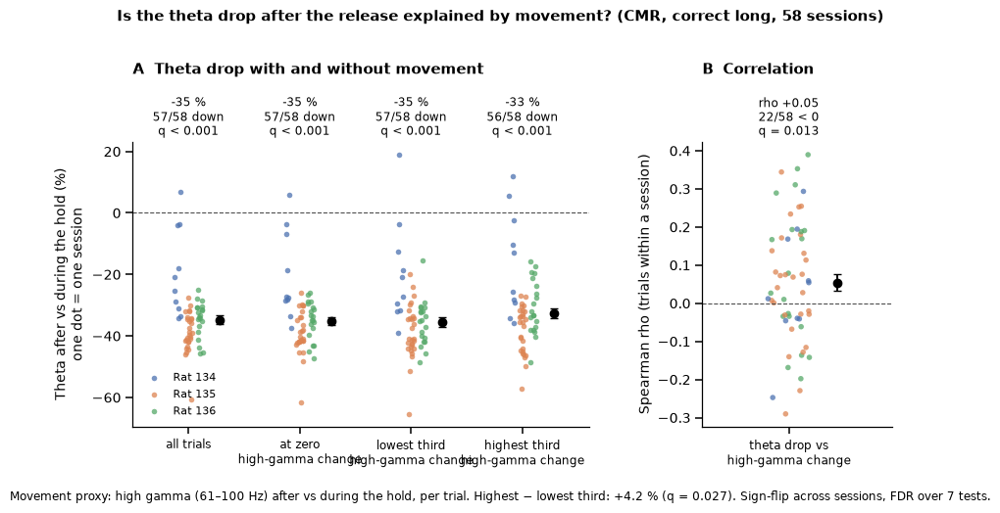


===== correct long, LOCAL, 58 sessions (FDR over 7 tests) =====
  ref                                             test  n_sessions  below_0    mean unit      p      q
LOCAL        theta drop after the release (all trials)          58       57 -16.200    % 0.0001 0.0001
LOCAL              high-gamma change after the release          58       23   1.300    % 0.0003 0.0003
LOCAL   Spearman rho (theta drop vs high-gamma change)          58       12   0.104  rho 0.0005 0.0005
LOCAL theta drop at zero high-gamma change (intercept)          58       57 -16.600    % 0.0001 0.0001
LOCAL    theta drop, lowest third of high-gamma change          58       56 -17.800    % 0.0001 0.0001
LOCAL   theta drop, highest third of high-gamma change          58       57 -14.800    % 0.0001 0.0001
LOCAL                           highest − lowest third          58       13   3.600    % 0.0001 0.0001
per rat (intercept): {'134': '-14.4 % (10/10 < 0)', '135': '-20.9 % (27/28 < 0)', '136': '-11.3 % (20/20 < 0)'}

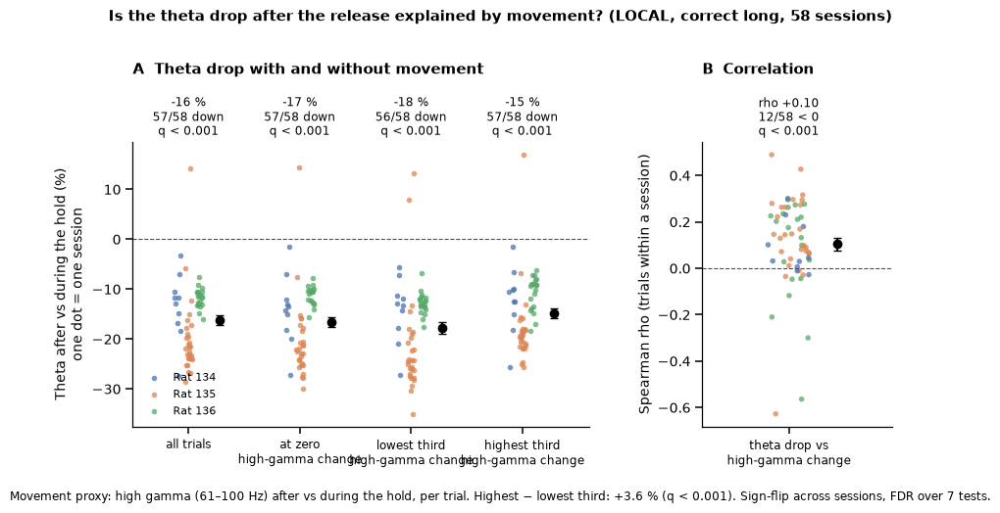

saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\movement check


In [95]:
# %%
# ── 1k. THETA DROP vs MOVEMENT PROXY (high gamma), trial by trial within sessions, CMR and LOCAL ──
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
MIN_TR = 10
pc   = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
RCOL = {"134": "#4C72B0", "135": "#DD8452", "136": "#55A868"}
mov_dir = os.path.join(AMIR, "Theta", "movement check"); os.makedirs(mov_dir, exist_ok=True)
fmt_q = lambda x: "q < 0.001" if x < 0.001 else f"q = {x:.3f}"
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9})

TESTS = [("theta_drop", "theta drop after the release (all trials)", True),
         ("hg_change", "high-gamma change after the release", True),
         ("rho", "Spearman rho (theta drop vs high-gamma change)", False),
         ("intercept", "theta drop at zero high-gamma change (intercept)", True),
         ("drop_low_hg", "theta drop, lowest third of high-gamma change", True),
         ("drop_high_hg", "theta drop, highest third of high-gamma change", True),
         ("high_minus_low", "highest − lowest third", True)]

all_stats = []
for REF_N in ["CMR", "LOCAL"]:
    # 1) per session: trial-by-trial theta drop vs high-gamma change (correct long, median over channels per trial)
    rows = []
    for s in done_sessions(REF_N):
        r = load_bp(s, REF_N); T, lp = r["trials"], r["logpow"]
        cl = ((T["label"] == "correct") & (T["type"] == "long")).values
        if cl.sum() < MIN_TR:
            continue
        th = np.median(lp["theta 4-7"]["post"][cl] - lp["theta 4-7"]["hold"][cl], axis=1)          # per trial
        hg = np.median(lp["highG 61-100"]["post"][cl] - lp["highG 61-100"]["hold"][cl], axis=1)
        ok = np.isfinite(th) & np.isfinite(hg); th, hg = th[ok], hg[ok]
        rho = spearmanr(th, hg)[0]
        slope, icpt = np.polyfit(hg, th, 1)                                                         # theta = icpt + slope * hg
        q1, q2 = np.quantile(hg, [1 / 3, 2 / 3])
        rows.append({"session": s, "rat": RAT[s], "n": len(th), "rho": rho, "slope": slope, "intercept": icpt,
                     "theta_drop": th.mean(), "hg_change": hg.mean(),
                     "drop_low_hg": th[hg <= q1].mean(), "drop_high_hg": th[hg >= q2].mean()})
    MVt = pd.DataFrame(rows)
    MVt["high_minus_low"] = MVt["drop_high_hg"] - MVt["drop_low_hg"]
    MVt.to_csv(os.path.join(TABLES, f"theta_drop_vs_movement_{REF_N}.csv"), index=False)

    # 2) across sessions: sign-flip, FDR over the 7 tests
    st = []
    for col, name, is_pct in TESTS:
        v = MVt[col].dropna(); m, p, n = fn.sign_flip_p(v.values)
        st.append({"ref": REF_N, "test": name, "col": col, "n_sessions": n, "below_0": int((v < 0).sum()),
                   "mean": round(float(pc(m)), 1) if is_pct else round(m, 3), "unit": "%" if is_pct else "rho", "p": p})
    ST = pd.DataFrame(st); ST["q"] = multipletests(ST["p"], method="fdr_bh")[1]
    all_stats.append(ST)
    Q = dict(zip(ST["col"], ST["q"]))
    print(f"\n===== correct long, {REF_N}, {len(MVt)} sessions (FDR over {len(ST)} tests) =====")
    print(ST.drop(columns="col").round({"p": 4, "q": 4}).to_string(index=False))
    print("per rat (intercept):", {rat: f"{pc(d['intercept'].mean()):+.1f} % ({int((d['intercept'] < 0).sum())}/{len(d)} < 0)"
                                   for rat, d in MVt.groupby("rat")})

    # 3) figure: A theta drop overall / at zero movement / by movement third; B rho per session
    fig, (axA, axB) = plt.subplots(1, 2, figsize=(10, 5.2), facecolor="white", gridspec_kw={"width_ratios": [2.4, 1]})
    fig.subplots_adjust(top=0.72, bottom=0.16, wspace=0.35)
    rng = np.random.default_rng(0)
    COLS = [("theta_drop", "all trials"), ("intercept", "at zero\nhigh-gamma change"),
            ("drop_low_hg", "lowest third\nhigh-gamma change"), ("drop_high_hg", "highest third\nhigh-gamma change")]
    for i, (col, lab) in enumerate(COLS):
        v = pc(MVt[col])
        for k, rat in enumerate(sorted(RCOL)):
            vr = v[MVt["rat"] == rat]
            axA.scatter(i + (k - 1) * 0.10 + rng.uniform(-0.03, 0.03, len(vr)), vr, s=16, color=RCOL[rat], alpha=0.75,
                        lw=0, label=f"Rat {rat}" if i == 0 else None)
        m = fn.sign_flip_p(MVt[col].values)[0]
        axA.errorbar(i + 0.28, pc(m), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt="o", color="k", ms=6, capsize=3, lw=1.4, zorder=4)
        axA.text(i, 1.01, f"{pc(m):+.0f} %\n{int((MVt[col] < 0).sum())}/{len(MVt)} down\n{fmt_q(Q[col])}",
                 transform=axA.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.5)
    axA.axhline(0, color="0.3", lw=0.8, ls="--")
    axA.set_xticks(range(len(COLS))); axA.set_xticklabels([l for _, l in COLS], fontsize=8.5); axA.set_xlim(-0.5, len(COLS) - 0.4)
    axA.set_ylabel("Theta after vs during the hold (%)\none dot = one session")
    axA.set_title("A  Theta drop with and without movement", fontsize=10.5, fontweight="bold", pad=50, loc="left")
    axA.legend(frameon=False, fontsize=8, loc="lower left")

    v = MVt["rho"]
    axB.scatter(rng.uniform(-0.12, 0.12, len(v)), v, s=16, color=[RCOL[x] for x in MVt["rat"]], alpha=0.75, lw=0)
    axB.errorbar(0.28, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt="o", color="k", ms=6, capsize=3, lw=1.4, zorder=4)
    axB.text(0, 1.01, f"rho {v.mean():+.2f}\n{int((v < 0).sum())}/{len(v)} < 0\n{fmt_q(Q['rho'])}",
             transform=axB.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.5)
    axB.axhline(0, color="0.3", lw=0.8, ls="--")
    axB.set_xticks([0]); axB.set_xticklabels(["theta drop vs\nhigh-gamma change"], fontsize=8.5); axB.set_xlim(-0.5, 0.6)
    axB.set_ylabel("Spearman rho (trials within a session)")
    axB.set_title("B  Correlation", fontsize=10.5, fontweight="bold", pad=50, loc="left")
    for ax in (axA, axB):
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    fig.suptitle(f"Is the theta drop after the release explained by movement? ({REF_N}, correct long, {len(MVt)} sessions)",
                 fontsize=11, fontweight="bold", y=0.98)
    fig.text(0.5, 0.01, "Movement proxy: high gamma (61–100 Hz) after vs during the hold, per trial. "
             f"Highest − lowest third: {pc(MVt['high_minus_low'].mean()):+.1f} % ({fmt_q(Q['high_minus_low'])}). "
             "Sign-flip across sessions, FDR over 7 tests.", ha="center", va="bottom", fontsize=8.5)
    fig.savefig(os.path.join(mov_dir, f"theta_drop_vs_movement_{REF_N}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

pd.concat(all_stats).drop(columns="col").to_csv(os.path.join(mov_dir, "theta_drop_vs_movement_stats_CMR_LOCAL.csv"), index=False)
print("saved in:", mov_dir)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1l. Theta does not predict the outcome or the reaction time, CMR and LOCAL
A: theta rise during the hold (hold − pre; per channel mean over trials, median over channels; one dot = one session) in long trials:
correct, late, early held >= 0.85 s (>= 5 trials per condition and session). Paired sign-flip late − correct and early − correct.
B: within each session (>= 10 correct long trials), Spearman rho between pre-tone theta (pre_tone − pre, median over channels per trial)
and reaction time (release − tone); one dot = one session (colour = rat); sign-flip of rho across sessions.
FDR (Benjamini–Hochberg) over the 3 tests per reference -> q.
Result: CMR late − correct [ ] %, early − correct [ ] %, rho [ ]; LOCAL [ ] %, [ ] %, rho [ ] (earlier runs: rho ≈ 0 in both).
Saved: tables\theta_rise_by_outcome_<ref>.csv, theta_pretone_rt_rho_<ref>.csv;
amir_data\Theta\reaction time\theta_outcome_rt_CMR.png, theta_outcome_rt_LOCAL.png

<div>

CMR  rise during the hold: {'correct': '+24.0 % (n=59)', 'late': '+24.3 % (n=33)', 'early': '+26.7 % (n=38)'}


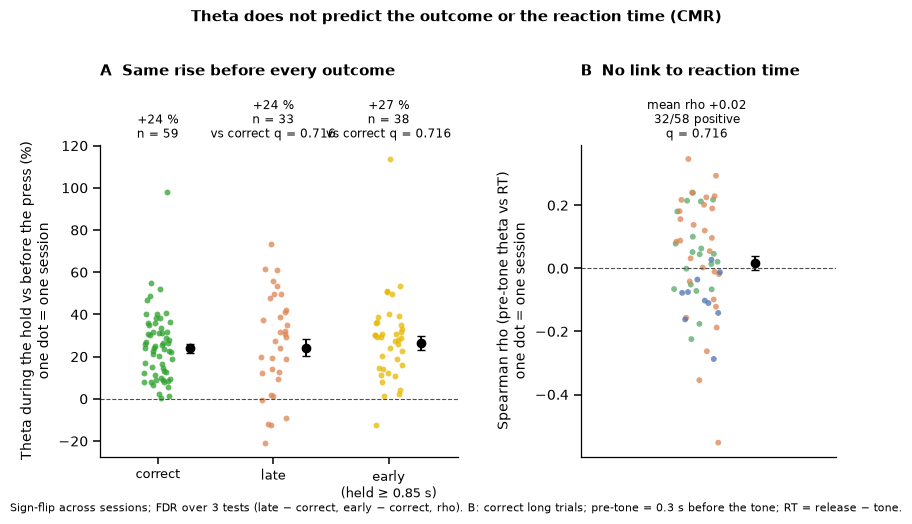

LOCAL  rise during the hold: {'correct': '+13.2 % (n=59)', 'late': '+12.1 % (n=33)', 'early': '+13.6 % (n=38)'}


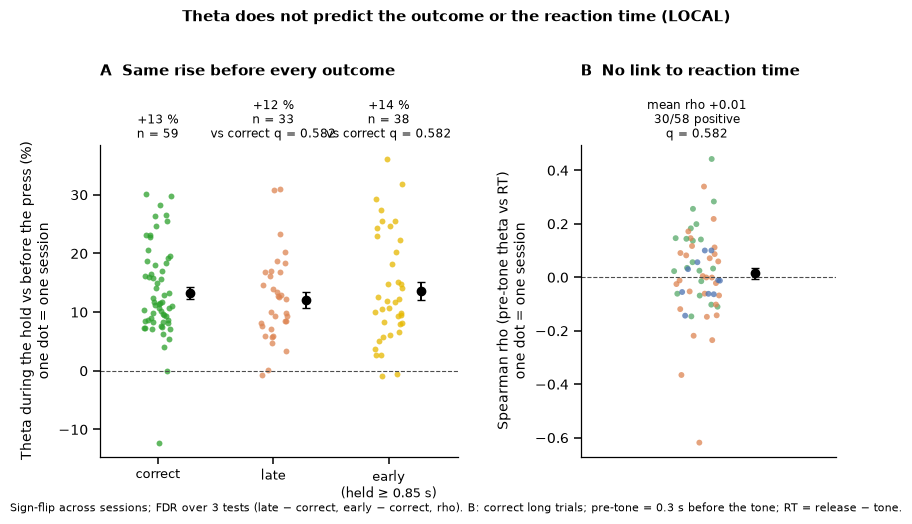


CMR vs LOCAL (FDR over 3 tests per reference)
  ref                       test  n_sessions   mean unit      p      q
  CMR             late − correct          33  2.100    % 0.5095 0.7163
  CMR            early − correct          38  0.900    % 0.7163 0.7163
  CMR rho (pre-tone theta vs RT)          58  0.016  rho 0.4820 0.7163
LOCAL             late − correct          33 -0.400    % 0.5817 0.5817
LOCAL            early − correct          38 -0.600    % 0.5026 0.5817
LOCAL rho (pre-tone theta vs RT)          58  0.015  rho 0.5080 0.5817
saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\reaction time


In [96]:
# %%
# ── 1l. THETA DOES NOT PREDICT THE OUTCOME OR THE REACTION TIME, CMR and LOCAL ──
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
fdr = lambda p: multipletests(np.asarray(p, float), alpha=0.05, method="fdr_bh")[1]
pc  = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
BAND, MIN_TR, MIN_RT = "theta 4-7", 5, 10
HOLD_FULL = fn.MAIN_WINDOWS["hold"][1][1]                  # 0.85 s
CND  = {"correct": "#2CA02C", "late": "#DD8452", "early": "#E6B800"}
LABS = {"correct": "correct", "late": "late", "early": f"early\n(held ≥ {HOLD_FULL} s)"}
RCOL = {"134": "#4C72B0", "135": "#DD8452", "136": "#55A868"}
rt_dir = os.path.join(AMIR, "Theta", "reaction time"); os.makedirs(rt_dir, exist_ok=True)
fmt_q = lambda x: "q < 0.001" if x < 0.001 else f"q = {x:.3f}"
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9, "font.family": "sans-serif"})

summary_rows = []
for REF_Q in ["CMR", "LOCAL"]:
    rows, rhos = [], []
    for s in done_sessions(REF_Q):
        r = load_bp(s, REF_Q); T, L = r["trials"], r["logpow"][BAND]
        lng, lab, hold = (T["type"] == "long").values, T["label"].values, T["hold_s"].values
        masks = {"correct": lng & (lab == "correct"), "late": lng & (lab == "late"),
                 "early": lng & (lab == "early") & (hold >= HOLD_FULL)}
        for c, mk in masks.items():
            if mk.sum() >= MIN_TR:
                rows.append({"session": s, "rat": RAT[s], "cond": c, "rise": float(np.median((L["hold"][mk] - L["pre"][mk]).mean(0)))})
        cl = masks["correct"] & np.isfinite(T["tone_delay_s"].values)
        if cl.sum() >= MIN_RT:
            th = np.median(L["pre_tone"][cl] - L["pre"][cl], axis=1)                # pre-tone theta per trial
            rt = (T["hold_s"] - T["tone_delay_s"]).values[cl]                       # reaction time = release − tone
            rhos.append({"session": s, "rat": RAT[s], "rho": spearmanr(th, rt, nan_policy="omit")[0]})
    DQ, RQ = pd.DataFrame(rows), pd.DataFrame(rhos)
    DQ.to_csv(os.path.join(TABLES, f"theta_rise_by_outcome_{REF_Q}.csv"), index=False)
    RQ.to_csv(os.path.join(TABLES, f"theta_pretone_rt_rho_{REF_Q}.csv"), index=False)
    W = DQ.pivot(index="session", columns="cond", values="rise")

    # tests: late − correct, early − correct (paired), rho vs 0; FDR over the 3
    tests = {f"{c} − correct": fn.sign_flip_p((W[c] - W["correct"]).dropna().values) for c in ["late", "early"]}
    tests["rho (pre-tone theta vs RT)"] = fn.sign_flip_p(RQ["rho"].dropna().values)
    Q = dict(zip(tests, fdr([t[1] for t in tests.values()])))
    for name, (m, p, n) in tests.items():
        summary_rows.append({"ref": REF_Q, "test": name, "n_sessions": n,
                             "mean": round(float(m), 3) if name.startswith("rho") else round(float(pc(m)), 1),
                             "unit": "rho" if name.startswith("rho") else "%", "p": p, "q": Q[name]})
    print(f"{REF_Q}  rise during the hold:", {c: f"{pc(W[c].mean()):+.1f} % (n={W[c].notna().sum()})" for c in CND})

    # figure
    fig, (axA, axB) = plt.subplots(1, 2, figsize=(9.5, 5.2), facecolor="white", gridspec_kw={"width_ratios": [1.4, 1]})
    fig.subplots_adjust(top=0.72, bottom=0.12, wspace=0.4)
    rng = np.random.default_rng(0)
    for k, (c, col) in enumerate(CND.items()):
        v = pc(W[c].dropna())
        axA.scatter(k + rng.uniform(-0.12, 0.12, len(v)), v, s=18, color=col, alpha=0.75, lw=0)
        axA.errorbar(k + 0.28, pc(W[c].dropna().mean()), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt="o", color="k", ms=6, capsize=3, lw=1.4)
        sub = f"{pc(W[c].mean()):+.0f} %\nn = {len(v)}" + ("" if c == "correct" else f"\nvs correct {fmt_q(Q[f'{c} − correct'])}")
        axA.text(k, 1.01, sub, transform=axA.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.5)
    axA.axhline(0, color="0.3", lw=0.8, ls="--")
    axA.set_xticks(range(3)); axA.set_xticklabels([LABS[c] for c in CND], fontsize=9); axA.set_xlim(-0.5, 2.6)
    axA.set_ylabel("Theta during the hold vs before the press (%)\none dot = one session")
    axA.set_title("A  Same rise before every outcome", fontsize=10.5, fontweight="bold", loc="left", pad=50)

    v = RQ["rho"].dropna(); mr = tests["rho (pre-tone theta vs RT)"][0]
    axB.scatter(rng.uniform(-0.1, 0.1, len(v)), v, s=18, color=[RCOL[x] for x in RQ.loc[v.index, "rat"]], alpha=0.75, lw=0)
    axB.errorbar(0.25, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt="o", color="k", ms=6, capsize=3, lw=1.4)
    axB.text(0, 1.01, f"mean rho {mr:+.2f}\n{int((v > 0).sum())}/{len(v)} positive\n{fmt_q(Q['rho (pre-tone theta vs RT)'])}",
             transform=axB.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.5)
    axB.axhline(0, color="0.3", lw=0.8, ls="--"); axB.set_xlim(-0.5, 0.6); axB.set_xticks([])
    axB.set_ylabel("Spearman rho (pre-tone theta vs RT)\none dot = one session")
    axB.set_title("B  No link to reaction time", fontsize=10.5, fontweight="bold", loc="left", pad=50)
    for ax in (axA, axB):
        for sp_ in ("top", "right"):
            ax.spines[sp_].set_visible(False)
    fig.suptitle(f"Theta does not predict the outcome or the reaction time ({REF_Q})", fontsize=11, fontweight="bold", y=0.98)
    fig.text(0.5, 0.01, "Sign-flip across sessions; FDR over 3 tests (late − correct, early − correct, rho). "
             "B: correct long trials; pre-tone = 0.3 s before the tone; RT = release − tone.", ha="center", va="bottom", fontsize=8)
    fig.savefig(os.path.join(rt_dir, f"theta_outcome_rt_{REF_Q}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nCMR vs LOCAL (FDR over 3 tests per reference)")
print(pd.DataFrame(summary_rows).round({"p": 4, "q": 4}).to_string(index=False))
print("saved in:", rt_dir)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1m. Theta wait vs go, paper-style (Fakhraei 2021, Fig. 6), CMR and LOCAL
Wait = correct long (tone at 1.05 s), go = correct short (tone at 0.35 s), press-aligned; both identical until 0.35 s.
Theta (4–7 Hz) from the saved wait/go maps (tables\wait_vs_go_maps_<ref>.npz, from the maps cell): mean over 4–7 Hz,
change vs pre-press per session; mean ± SEM across sessions.
As in the paper: t-test across sessions at every time point, FDR over time; a point is marked only if
wait > baseline AND wait > go (both q < 0.05); bar = significant points, q shown = the larger of the two.
Result: CMR wait > go [ ]–[ ] s (earlier run: from about 0.5 s); LOCAL [ ]–[ ] s (earlier run: 0.50–1.19 s).
Saved: amir_data\Theta\wait vs go\wait_vs_go_paper_CMR.png, wait_vs_go_paper_LOCAL.png

<div>

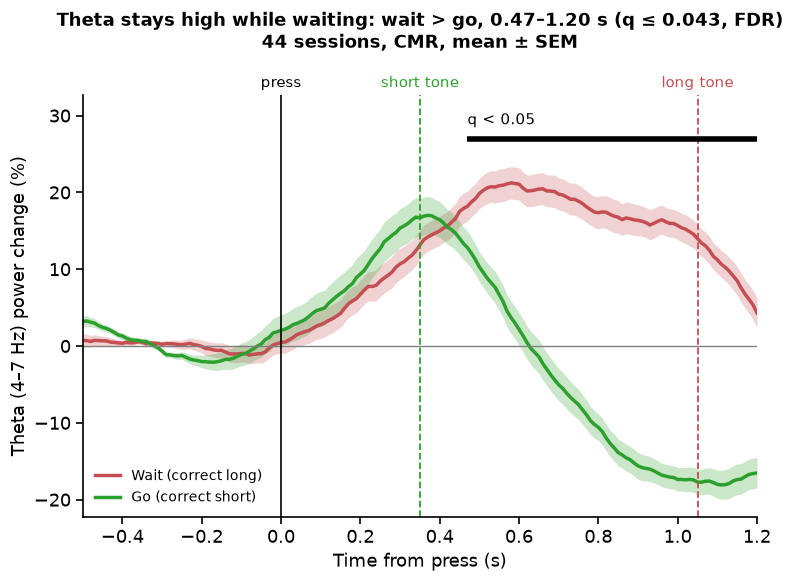

CMR: 44 sessions | significant: 0.47–1.20 s | q inside: min 1.5e-12, max 0.043


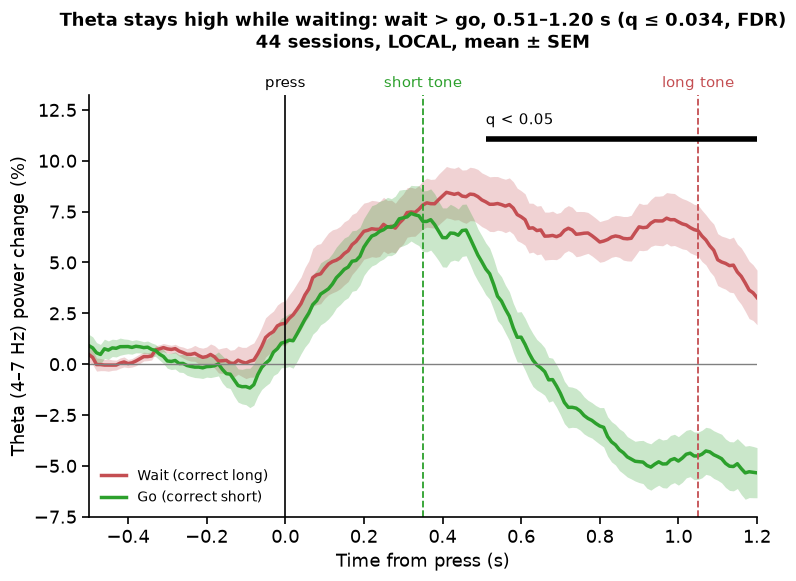

LOCAL: 44 sessions | significant: 0.51–1.20 s | q inside: min 5.3e-07, max 0.034
saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\wait vs go


In [97]:
# %%
# ── 1m. THETA WAIT vs GO, paper-style figure (from the saved maps), CMR and LOCAL ──
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
C_WAIT, C_GO = "#C44E52", "#2CA02C"                 # wait = red, go = green
pc = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
wg_dir = os.path.join(AMIR, "Theta", "wait vs go"); os.makedirs(wg_dir, exist_ok=True)
for REF_G in ["CMR", "LOCAL"]:
    f = os.path.join(TABLES, f"wait_vs_go_maps_{REF_G}.npz")
    if not os.path.exists(f):
        print(f"{REF_G}: {f} not found -> run the wait vs go maps cell with REF = '{REF_G}' first"); continue
    z = np.load(f, allow_pickle=True)
    MW, MG, FREQS, tt, used = z["wait"], z["go"], z["freqs"], z["times"], z["sessions"]

    fb = (FREQS >= 4) & (FREQS <= 7)
    thw, thg = MW[:, fb].mean(1), MG[:, fb].mean(1)
    t1, p1 = ttest_1samp(thw, 0, axis=0);       q1 = multipletests(p1, method="fdr_bh")[1]
    t2, p2 = ttest_1samp(thw - thg, 0, axis=0); q2 = multipletests(p2, method="fdr_bh")[1]
    sig = (q1 < 0.05) & (t1 > 0) & (q2 < 0.05) & (t2 > 0)          # wait > baseline AND wait > go
    qq  = np.maximum(q1, q2)                                        # a point needs both tests -> larger q

    plt.rcParams.update({"font.size": 13, "axes.linewidth": 1.2, "font.family": "sans-serif",
                         "xtick.major.width": 1.2, "ytick.major.width": 1.2, "xtick.major.size": 5, "ytick.major.size": 5})
    fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
    for v, col, lab in ((thw, C_WAIT, "Wait (correct long)"), (thg, C_GO, "Go (correct short)")):
        m, se = v.mean(0), v.std(0, ddof=1) / np.sqrt(len(v))
        ax.fill_between(tt, pc(m - se), pc(m + se), color=col, alpha=0.25, lw=0)
        ax.plot(tt, pc(m), color=col, lw=2.5, label=lab)
    ax.axhline(0, color="0.5", lw=1)
    ax.axvline(0, color="k", lw=1.2)
    ax.text(0, 1.01, "press", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=11)
    for x, col, lab in ((0.35, C_GO, "short tone"), (1.05, C_WAIT, "long tone")):
        ax.axvline(x, color=col, ls="--", lw=1.3)
        ax.text(x, 1.01, lab, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=11, color=col)
    if sig.any():                                                   # significance bar (contiguous segments)
        y0, y1 = ax.get_ylim(); yb = y1 + 0.03 * (y1 - y0)
        idx = np.where(sig)[0]; segs = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
        for sg in segs:
            ax.plot([tt[sg[0]], tt[sg[-1]]], [yb, yb], color="k", lw=4, solid_capstyle="butt")
        ax.text(tt[segs[0][0]], yb + 0.03 * (y1 - y0), "q < 0.05", fontsize=11, va="bottom")
        ax.set_ylim(top=yb + 0.12 * (y1 - y0))
    ax.set_xlim(tt[0], tt[-1])
    ax.set_xlabel("Time from press (s)")
    ax.set_ylabel("Theta (4–7 Hz) power change (%)")
    for sp_ in ("top", "right"):
        ax.spines[sp_].set_visible(False)
    ax.legend(frameon=False, fontsize=10, loc="lower left", handlelength=1.8)
    title = (f"Theta stays high while waiting: wait > go, {tt[sig].min():.2f}–{tt[sig].max():.2f} s "
             f"(q ≤ {qq[sig].max():.3f}, FDR)" if sig.any() else "Theta: wait vs go (no significant time point)")
    ax.set_title(f"{title}\n{len(used)} sessions, {REF_G}, mean ± SEM", fontsize=13, fontweight="bold", pad=34)
    fig.tight_layout()
    fig.savefig(os.path.join(wg_dir, f"wait_vs_go_paper_{REF_G}.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    if sig.any():
        segs_txt = ", ".join(f"{tt[sg[0]]:.2f}–{tt[sg[-1]]:.2f} s" for sg in segs)
        print(f"{REF_G}: {len(used)} sessions | significant: {segs_txt} | q inside: min {qq[sig].min():.1e}, max {qq[sig].max():.3f}")
    else:
        print(f"{REF_G}: {len(used)} sessions | no significant time point")
print("saved in:", wg_dir)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1n. Theta time course: correct vs early and correct vs late long, CMR and LOCAL
Curves from the band-power files (06): per trial and channel change vs own pre-press, only while on the lever;
per session (both groups >= 5 trials) median over channels; time point kept if >= 50 % of the group's trials are on the lever.
Across sessions: mean ± SEM (session = unit). Early long = released before the tone, held > 0.3 s.
Test: paired t-test across sessions (other − correct) at every shown time point, FDR over all shown points of both panels;
black bar = q < 0.05. Window names shown above (no shading).
Result: CMR early vs correct [ ]; late vs correct [ ]; LOCAL [ ]; [ ] (from the printout).
Saved: amir_data\Theta\correct vs error\theta_course_correct_vs_early_<ref>.png, theta_course_correct_vs_late_<ref>.png

<div>

CMR | early vs correct, Press-aligned: no significant time point
CMR | early vs correct, Release-aligned: q < 0.05 at -0.52–-0.50 s, -0.15–0.60 s


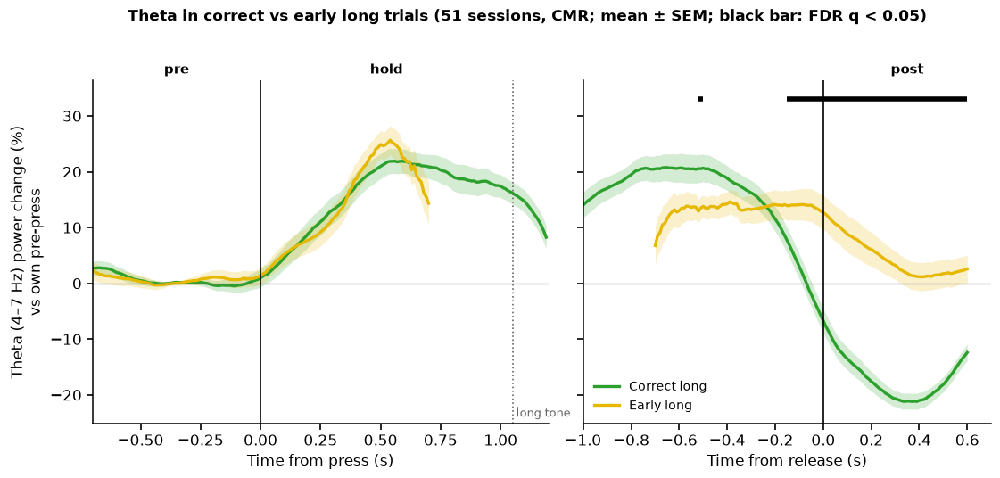

CMR | late vs correct, Press-aligned: no significant time point
CMR | late vs correct, Release-aligned: q < 0.05 at 0.07–0.35 s


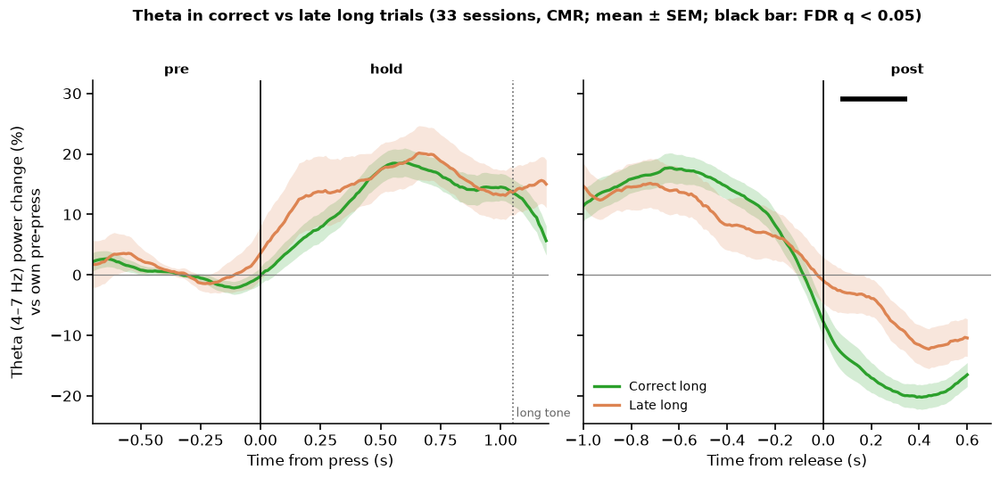

LOCAL | early vs correct, Press-aligned: no significant time point
LOCAL | early vs correct, Release-aligned: q < 0.05 at -0.16–0.60 s


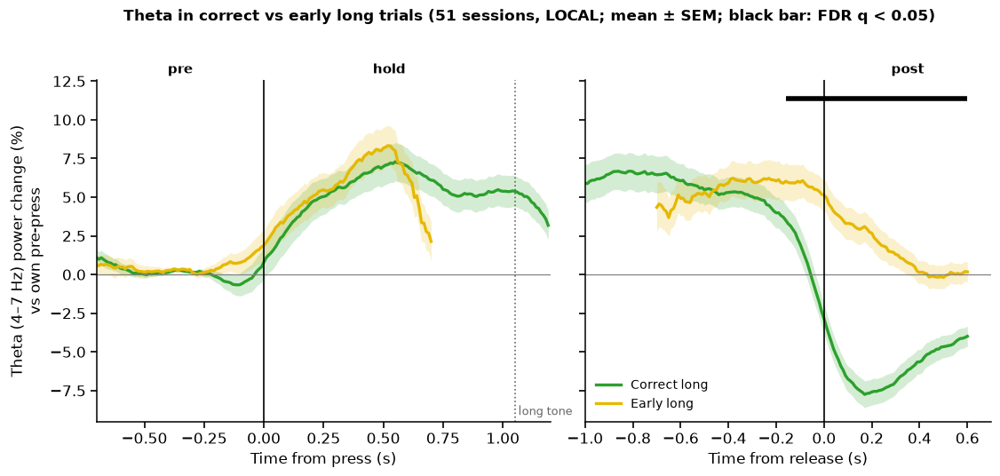

LOCAL | late vs correct, Press-aligned: no significant time point
LOCAL | late vs correct, Release-aligned: no significant time point


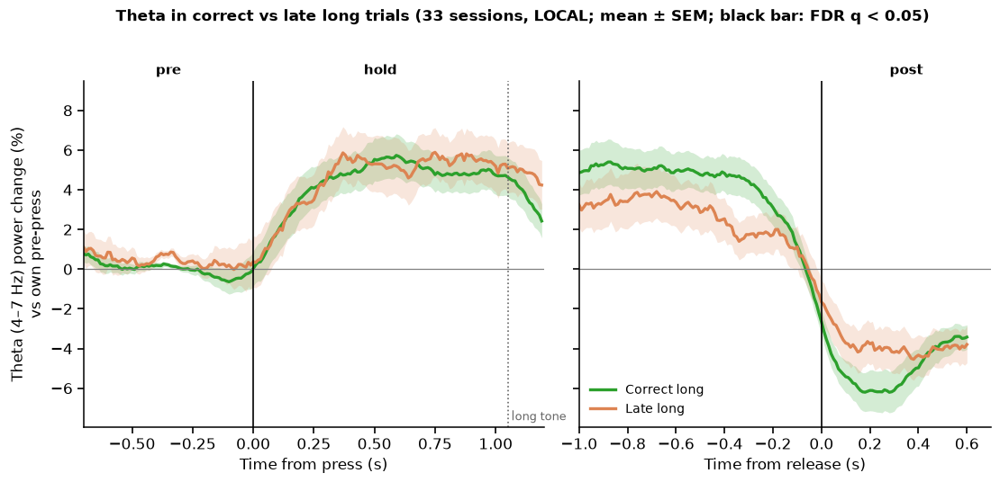

saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\correct vs error


In [98]:
# %%
# ── 1n. THETA TIME COURSE: correct vs early and correct vs late long (black bar = significant time points), CMR and LOCAL ──
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
BAND, MIN_TR = "theta 4-7", 5
GRP = {"correct": ("#2CA02C", "Correct long", "correct long"),
       "early":   ("#E6B800", "Early long", "early long (hold>0.3)"),
       "late":    ("#DD8452", "Late long", "late long")}
SHOW = {"Press": (-0.7, 1.2), "Release": (-1.0, 0.7)}
LABELS = {"Press": ["pre", "hold"], "Release": ["post"]}
pc = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
ce_dir = os.path.join(AMIR, "Theta", "correct vs error"); os.makedirs(ce_dir, exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.linewidth": 1.1, "font.family": "sans-serif"})

for REF_T in ["CMR", "LOCAL"]:
    for OTHER in ["early", "late"]:
        G2 = ["correct", OTHER]
        # 1) paired session curves (sessions with both groups)
        C = {al: {g: [] for g in G2} for al in SHOW}; TT = {}; used = []
        for s in done_sessions(REF_T):
            r = load_bp(s, REF_T); cm = fn.main_conditions(r["trials"])
            n = {g: int(cm[GRP[g][2]].sum()) for g in G2}
            if min(n.values()) < MIN_TR:
                continue
            used.append(s)
            for al in SHOW:
                TT.setdefault(al, r["times"][al])
                for g in G2:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore", RuntimeWarning)
                        cur = np.nanmedian(r["curves"][al][BAND][GRP[g][2]], axis=0)
                    C[al][g].append(np.where(r["counts"][al][GRP[g][2]] >= max(3, 0.5 * n[g]), cur, np.nan))
        C = {al: {g: np.array(v) for g, v in d.items()} for al, d in C.items()}

        # 2) paired t-test (other − correct) at every time point, FDR over all shown time points of both panels
        P, keep = {}, {}
        for al in SHOW:
            D = C[al][OTHER] - C[al]["correct"]
            keep[al] = (np.sum(np.isfinite(D), 0) >= max(5, 0.5 * len(used))) & (TT[al] >= SHOW[al][0]) & (TT[al] <= SHOW[al][1])
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                P[al] = ttest_1samp(D, 0, axis=0, nan_policy="omit")[1]
        allq = multipletests(np.concatenate([P[al][keep[al]] for al in SHOW]), method="fdr_bh")[1]
        Q, i0 = {}, 0
        for al in SHOW:
            Q[al] = np.full(len(TT[al]), np.nan); k = keep[al].sum(); Q[al][keep[al]] = allq[i0:i0 + k]; i0 += k

        # 3) figure
        fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, facecolor="white", gridspec_kw={"width_ratios": [1.9, 1.7], "wspace": 0.08})
        for ax, al, xl in zip(axes, SHOW, ["Time from press (s)", "Time from release (s)"]):
            for g in G2:
                col, lab, _ = GRP[g]
                X = C[al][g]; n_s = np.sum(np.isfinite(X), 0)
                ok = (n_s >= max(3, 0.5 * len(X))) & (TT[al] >= SHOW[al][0]) & (TT[al] <= SHOW[al][1])
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", RuntimeWarning)
                    m, se = np.nanmean(X, 0), np.nanstd(X, 0, ddof=1) / np.sqrt(n_s)
                ax.fill_between(TT[al][ok], pc(m - se)[ok], pc(m + se)[ok], color=col, alpha=0.2, lw=0)
                ax.plot(TT[al][ok], pc(m)[ok], color=col, lw=2.4, label=lab)
            for name in LABELS[al]:                                       # window labels only, no shading
                a, z = fn.MAIN_WINDOWS[name][1]
                ax.text((a + z) / 2, 1.01, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=11, fontweight="bold")
            ax.axhline(0, color="0.5", lw=0.9); ax.axvline(0, color="k", lw=1.2)
            if al == "Press":
                ax.axvline(1.05, color="0.4", ls=":", lw=1.2); ax.text(1.05, 0.02, " long tone", transform=ax.get_xaxis_transform(), fontsize=9, color="0.4")
            ax.set_xlim(*SHOW[al]); ax.set_xlabel(xl)
            for sp_ in ("top", "right"):
                ax.spines[sp_].set_visible(False)
        ylo, yhi = axes[0].get_ylim(); yb = yhi + 0.04 * (yhi - ylo)
        for ax, al in zip(axes, SHOW):                                    # black bar where other ≠ correct (q < 0.05)
            sig = Q[al] < 0.05
            if sig.any():
                idx = np.where(sig)[0]; segs = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
                for sg in segs:
                    ax.plot([TT[al][sg[0]], TT[al][sg[-1]]], [yb, yb], color="k", lw=4, solid_capstyle="butt")
                print(f"{REF_T} | {OTHER} vs correct, {al}-aligned: q < 0.05 at " +
                      ", ".join(f"{TT[al][sg[0]]:.2f}–{TT[al][sg[-1]]:.2f} s" for sg in segs))
            else:
                print(f"{REF_T} | {OTHER} vs correct, {al}-aligned: no significant time point")
        axes[0].set_ylim(ylo, yb + 0.06 * (yhi - ylo))
        axes[0].set_ylabel("Theta (4–7 Hz) power change (%)\nvs own pre-press")
        axes[1].legend(frameon=False, fontsize=10, loc="lower left")
        fig.suptitle(f"Theta in correct vs {OTHER} long trials ({len(used)} sessions, {REF_T}; mean ± SEM; black bar: FDR q < 0.05)",
                     fontsize=12.5, fontweight="bold", y=1.04)
        fig.savefig(os.path.join(ce_dir, f"theta_course_correct_vs_{OTHER}_{REF_T}.png"), dpi=300, bbox_inches="tight", facecolor="white")
        plt.show()
print("saved in:", ce_dir)

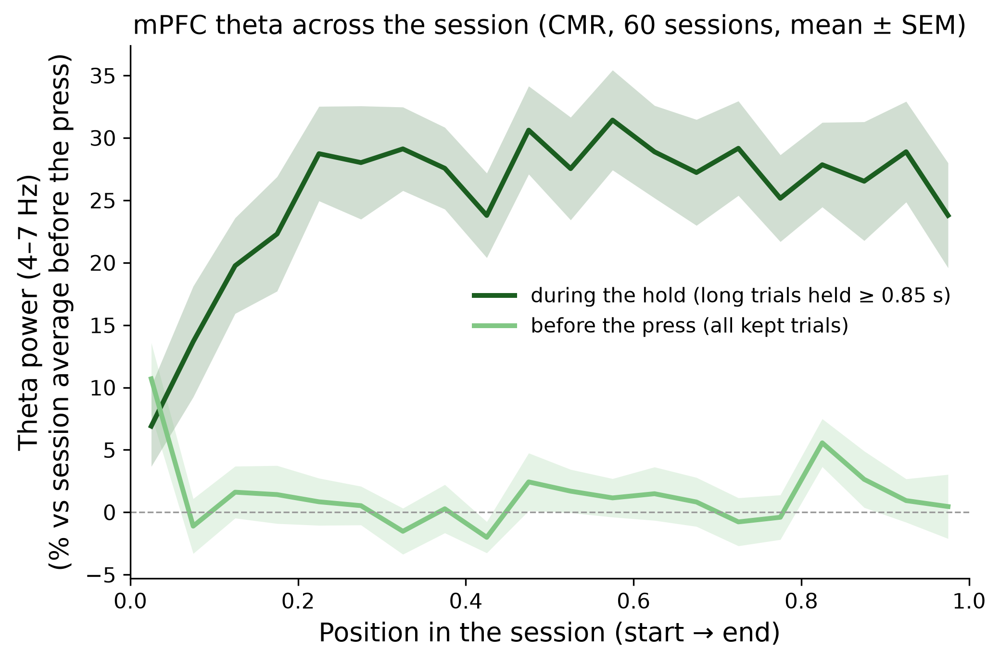

saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\How theta behaves in general\theta_across_session_pooled_CMR.png


In [81]:
# ── THETA POWER ACROSS THE SESSION, mPFC POOLED, CMR — before the press and during the hold, no tests (needs cell 0) ──
importlib.reload(fn)
from IPython.display import Image, display
GEN_T = os.path.join(THETA_DIR, "How theta behaves in general"); os.makedirs(GEN_T, exist_ok=True)
for old in [f"theta_across_session_{k}_{r_}.{e}" for r_ in ("CMR", "LOCAL")
            for k, e in (("regions", "png"), ("tests", "csv"), ("data", "csv"))]:     # remove the files of the old version
    if os.path.exists(os.path.join(GEN_T, old)): os.remove(os.path.join(GEN_T, old))
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
REF, BAND, REGS, NB, MIN_CH, MIN_TR, MIN_HOLD = "CMR", "theta 4-7", ["IL", "PL", "Cg1"], 20, 5, 3, 0.85

rows = []
for s in done_sessions(REF):
    r = load_bp(s, REF); T = r["trials"]; L = r["logpow"][BAND]
    masks, _ = fn.region_masks(r, CHREG, s)
    t0, t1 = np.nanmin(T["press_s"]), np.nanmax(T["release_s"])
    part = np.clip(((T["press_s"].values - t0) / (t1 - t0) * NB).astype(int), 0, NB - 1)
    held = (T["type"].values == "long") & (T["hold_s"].values >= MIN_HOLD)
    pre_r, hold_r = [], []
    for g in REGS:
        m = masks[g]
        if m.sum() < MIN_CH: continue
        pre_r.append(np.nanmedian(L["pre"][:, m], axis=1)); hold_r.append(np.nanmedian(L["hold"][:, m], axis=1))
    if not pre_r: continue
    pre, hold = np.nanmean(pre_r, axis=0), np.nanmean(hold_r, axis=0)        # mPFC pooled: mean of the regions (log10)
    base = np.nanmean(pre)                                                     # session's average theta before the press
    for k in range(NB):
        a, b = part == k, (part == k) & held
        rows.append(dict(session=s, rat=str(RAT[s]), part=k, pos=(k + 0.5) / NB,
                         pre=pc(np.nanmean(pre[a]) - base) if a.sum() >= MIN_TR else np.nan,
                         hold=pc(np.nanmean(hold[b]) - base) if b.sum() >= MIN_TR else np.nan))
    del r
D = pd.DataFrame(rows)
D.to_csv(os.path.join(GEN_T, "theta_across_session_pooled_CMR_data.csv"), index=False)

plt.rcParams.update({"font.size": 12, "axes.linewidth": 0.8})
fig, ax = plt.subplots(figsize=(7.5, 4.8), facecolor="white")
for col, c, lab in (("hold", "#1B5E20", f"during the hold (long trials held ≥ {MIN_HOLD} s)"),
                    ("pre", "#81C784", "before the press (all kept trials)")):
    g = D.groupby("part")[col].agg(["mean", "sem", "count"]); x = (g.index + 0.5) / NB
    ax.fill_between(x, g["mean"] - g["sem"], g["mean"] + g["sem"], color=c, alpha=0.2, lw=0)
    ax.plot(x, g["mean"], color=c, lw=2.4, label=lab)
ax.axhline(0, color="0.6", lw=0.8, ls="--")
ax.set_xlim(0, 1); ax.set_xlabel("Position in the session (start → end)", fontsize=13)
ax.set_ylabel("Theta power (4–7 Hz)\n(% vs session average before the press)", fontsize=13)
ax.set_title(f"mPFC theta across the session (CMR, {D.session.nunique()} sessions, mean ± SEM)", fontsize=13)
ax.legend(frameon=False, fontsize=10, loc="best")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fp = os.path.join(GEN_T, "theta_across_session_pooled_CMR.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("saved:", fp)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1o. Theta phase connectivity (PLV, PLI) — step 1: choose the channel pair
Pilot session 20260529_r0000136_wt_1318, the same 20 channels as 1c/1d (fn.select_channels, n_total = 20, from the CMR band-power file).
Per channel: shank (x // 250 µm), x, y (µm; larger y = higher on the probe), region (channel_regions_all.csv), theta hold-specific in 1d
(sign-flip across the 49 correct long trials, hold − pre and hold − post both p < 0.05, same direction; raw p), present in the LOCAL file.
Candidates: lowest and highest channel on each shank, and their distances. The pair for PLV / PLI is chosen from this list.
Saved: amir_data\Theta\PLV\pilot_20_channels.csv, pilot_20_channels_probe.png
<div>

IL/PL border per shank (µm): {shank 1: 908} -> line at 908 µm
PL/Cg1 border per shank (µm): {shank 0: 2782, shank 1: 2782, shank 2: 2782} -> line at 2782 µm


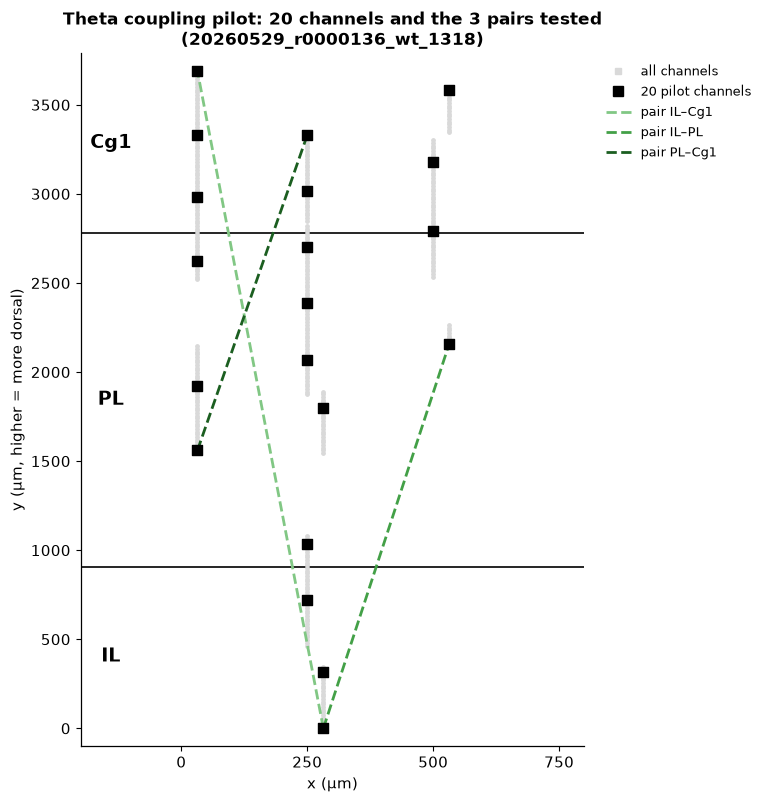

saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\pilot_20_channels_pairs_probe.png


In [80]:
# ── 1o. THE 20 PILOT CHANNELS ON THE PROBE (black), 3 PAIRS TESTED (one colour per pair), REGION BORDERS (2 lines) (needs cell 0) ──
importlib.reload(fn)
from matplotlib.lines import Line2D
PLV_DIR = os.path.join(AMIR, "Theta", "Phase connectivity"); os.makedirs(PLV_DIR, exist_ok=True)
SES = TEST
PAIRS = {"IL–Cg1": ("imec0.ap#AP49", "imec0.ap#AP205"), "IL–PL": ("imec0.ap#AP49", "imec0.ap#AP241"),
         "PL–Cg1": ("imec0.ap#AP257", "imec0.ap#AP156")}
PCOL = {"IL–Cg1": "#81C784", "IL–PL": "#43A047", "PL–Cg1": "#1B5E20"}            # light, mid, dark green
ORDER = [("Infralimbic area", "IL"), ("Prelimbic area", "PL"), ("Cingulate area 1", "Cg1")]   # ventral -> dorsal
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)

meta = load_bp(SES, "CMR")["meta"]
pdf = pd.DataFrame({"channel_id": [str(c) for c in meta["channel_ids"]], "x": meta["x"], "y": meta["y"]})
pdf["shank"] = (pdf["x"] // 250).astype(int)
pdf["region"] = pdf.channel_id.map(CHREG[CHREG.session == SES].set_index("channel_id")["region"])
sel = fn.select_channels(pdf, n_total=20).copy(); sel["channel_id"] = sel["channel_id"].astype(str)
P = pdf.set_index("channel_id")

# region borders: per shank halfway between the regions, then the median over shanks -> one line per border
borders = {}
for (lo, lo_s), (hi, hi_s) in zip(ORDER[:-1], ORDER[1:]):
    per = {sh: (d[d.region == lo].y.max() + d[d.region == hi].y.min()) / 2
           for sh, d in pdf.groupby("shank") if (d.region == lo).any() and (d.region == hi).any()}
    borders[f"{lo_s}/{hi_s}"] = np.median(list(per.values()))
    print(f"{lo_s}/{hi_s} border per shank (µm): {{{', '.join(f'shank {k}: {v:.0f}' for k, v in per.items())}}} -> line at {borders[f'{lo_s}/{hi_s}']:.0f} µm")

plt.rcParams.update({"font.size": 11, "axes.linewidth": 0.9})
fig, ax = plt.subplots(figsize=(6.5, 9), facecolor="white")
ax.scatter(pdf.x, pdf.y, s=6, color="0.85", zorder=1)                              # all channels
for pname, (c1, c2) in PAIRS.items():                                              # pairs tested, one colour each
    ax.plot(P.loc[[c1, c2], "x"], P.loc[[c1, c2], "y"], color=PCOL[pname], lw=2, ls="--", zorder=2)
ax.scatter(sel.x, sel.y, s=55, color="k", marker="s", zorder=3)                    # 20 pilot channels (black)

# 2 horizontal lines + region names
y_il_pl, y_pl_cg = borders["IL/PL"], borders["PL/Cg1"]
for yb in (y_il_pl, y_pl_cg):
    ax.axhline(yb, color="k", lw=1.2, zorder=0)
ymin, ymax = pdf.y.min() - 100, pdf.y.max() + 100
for name, (a, b) in (("IL", (ymin, y_il_pl)), ("PL", (y_il_pl, y_pl_cg)), ("Cg1", (y_pl_cg, ymax))):
    ax.text(-140, (a + b) / 2, name, fontsize=14, fontweight="bold", ha="center", va="center")
ax.set_xlim(-200, 800); ax.set_ylim(ymin, ymax)

h = [Line2D([], [], marker="s", ls="", color="0.85", ms=4, label="all channels"),
     Line2D([], [], marker="s", ls="", color="k", ms=7, label="20 pilot channels")]
h += [Line2D([], [], color=col, ls="--", lw=2, label=f"pair {p}") for p, col in PCOL.items()]
ax.legend(handles=h, frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm, higher = more dorsal)"); ax.set_xticks([0, 250, 500, 750])
ax.set_title(f"Theta coupling pilot: 20 channels and the 3 pairs tested\n({SES})", fontsize=12, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fp = os.path.join(PLV_DIR, "pilot_20_channels_pairs_probe.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.show()
print("saved:", fp)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1p. Theta phase coupling between three region pairs during the hold: PLV, PLI, PPC, debiased wPLI² — pilot session, correct long trials, CMR
Pilot session 20260529_r0000136_wt_1318, 49 correct long trials (all still holding until 0.85 s), reference CMR. Pairs (20 pilot channels,
theta hold-specific in 1d, different shanks): IL–Cg1 AP49–AP205 (3.7 mm), IL–PL AP49–AP241 (2.2 mm), PL–Cg1 AP257–AP156 (1.8 mm).<br>
Computed with MNE-Python (mne-connectivity 0.9.0, spectral_connectivity_epochs, mode "cwt_morlet", 4, 5, 6, 7 Hz, 5 cycles): across trials at each
time point and frequency, then mean over the 4 frequencies and over the hold window (0.2–0.85 s after the press, 10-ms steps).<br>
- <b>PLV</b> (Lachaux 1999): consistency of the phase difference (counts 0°/180°; biased upward with few trials).
- <b>PPC</b> (Vinck 2010): the same without trial-number bias (≈ PLV²).
- <b>PLI</b> (Stam 2007): how consistently one region is ahead (ignores 0°/180°, i.e. shared signals; biased with few trials).
- <b>Debiased wPLI²</b> (Vinck 2011; MNE "wpli2_debiased"): weighted PLI, squared scale, no trial-number bias, robust to noise.
Mean Δφ: circular mean (> 0 = first region leads).<br>
- Chance: second channel taken from another trial (500 shuffles; own code, identical to MNE within 0.0008 — see validation cell);
black line = 95 % of the shuffles; p = (1 + shuffles ≥ real value) / 501 (raw, one-sided).<br>
Saved: amir_data\Theta\Phase connectivity\pilot_3pairs_coupling_hold_CMR.png, .csv
<div>

20260529_r0000136_wt_1318: 49 correct long trials, CMR, hold 0.2–0.85 s | values: MNE 0.9.0 (dwpli = wpli2_debiased) | chance: 500 shuffles | mean Δφ > 0 = first region leads
  pair  trials  mean_dphi_deg   plv  chance95_plv  p_plv   pli  chance95_pli  p_pli   ppc  chance95_ppc  p_ppc  dwpli  chance95_dwpli  p_dwpli
IL–Cg1      49        -90.515 0.312         0.162  0.002 0.366         0.156  0.002 0.091         0.012  0.002  0.385           0.038    0.002
 IL–PL      49         76.941 0.401         0.164  0.002 0.435         0.159  0.002 0.160         0.011  0.002  0.466           0.039    0.002
PL–Cg1      49        166.292 0.486         0.166  0.002 0.197         0.153  0.004 0.237         0.012  0.002  0.154           0.037    0.002


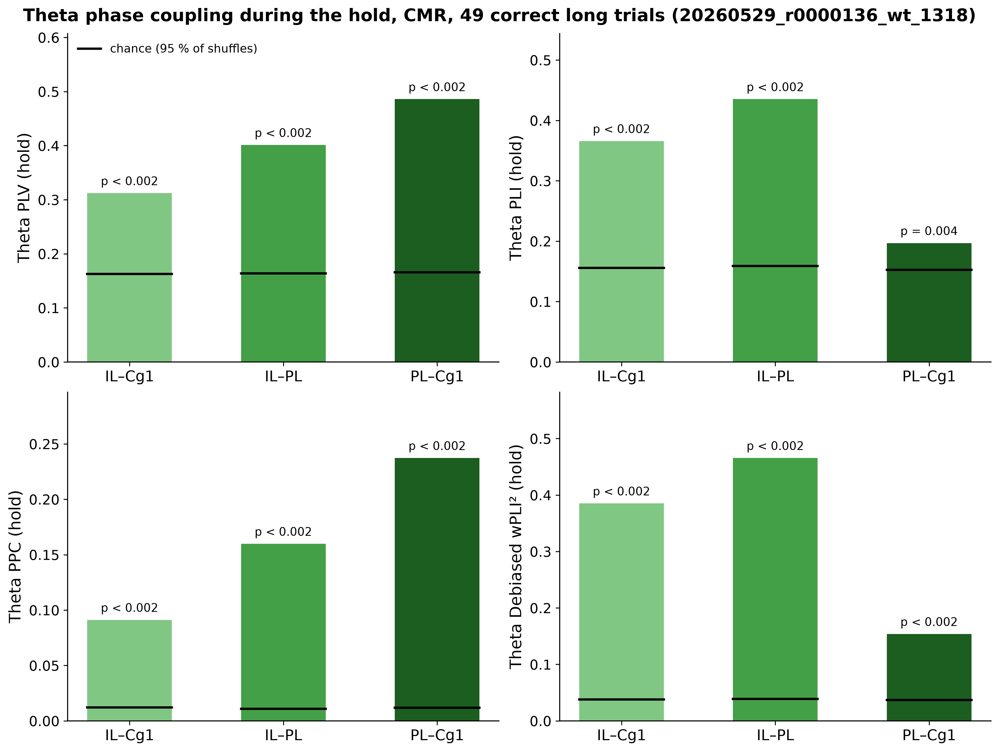

saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\pilot_3pairs_coupling_hold_CMR.png


In [84]:
# ── 1p. THETA PLV, PLI, PPC, DEBIASED wPLI² (MNE), 3 PAIRS, PILOT SESSION, CORRECT LONG, HOLD, CMR — one figure (needs cell 0) ──
importlib.reload(fn)
import scipy.signal as ss
import mne_connectivity
from mne_connectivity import spectral_connectivity_epochs
from IPython.display import Image, display
PCOL = {"IL–Cg1": "#81C784", "IL–PL": "#43A047", "PL–Cg1": "#1B5E20"}            # light, mid, dark green
PC_DIR = os.path.join(AMIR, "Theta", "Phase connectivity"); os.makedirs(PC_DIR, exist_ok=True)
SES, REF = TEST, "CMR"
PAIRS = {"IL–Cg1": ("imec0.ap#AP49", "imec0.ap#AP205"), "IL–PL": ("imec0.ap#AP49", "imec0.ap#AP241"),
         "PL–Cg1": ("imec0.ap#AP257", "imec0.ap#AP156")}
FR, NCYC = np.array(fn.MAIN_BANDS["theta 4-7"]["freqs"]), fn.MAIN_BANDS["theta 4-7"]["n_cycles"]
HOLD, STEP_S, NSH, RNG = (0.20, 0.85), 0.010, 500, np.random.default_rng(0)
MEAS = [("plv", "plv", "PLV"), ("pli", "pli", "PLI"), ("ppc", "ppc", "PPC"), ("dwpli", "wpli2_debiased", "Debiased wPLI²")]
CHS = sorted({c for p in PAIRS.values() for c in p})

T = load_bp(SES, "LOCAL")["trials"]; T = T[(T["type"] == "long") & (T["label"] == "correct")].reset_index(drop=True)
rec = fn.load_session(PROC, SES, XB, refs=(REF,))[0][REF]
full = [str(c) for c in rec.get_channel_ids()]
objs = [rec.get_channel_ids()[full.index(c)] for c in CHS]
recN = rec.select_channels(objs) if hasattr(rec, "select_channels") else rec.channel_slice(channel_ids=objs)
a0, a1 = fn.MAIN_EPOCHS["Press"]
X, ok = fn.read_epochs(recN, T["press_s"].values, a0, a1); fs = recN.get_sampling_frequency(); Tk = T[ok].reset_index(drop=True)
assert ((Tk["release_s"] - Tk["press_s"]).values >= HOLD[1]).all(), "some trials released before the end of the hold window"
t = np.arange(X.shape[-1]) / fs + a0
idx = np.where((t >= HOLD[0]) & (t <= HOLD[1]))[0][::int(round(STEP_S * fs))]
ci = {c: i for i, c in enumerate(CHS)}

def own(A, B):
    """validated own formulas (identical to MNE within 0.0008) — used for the shuffles only"""
    S = A * np.conj(B); E = S / np.abs(S).clip(1e-30); n = A.shape[0]
    im = S.imag; num = im.sum(0) ** 2 - (im ** 2).sum(0); den = np.abs(im).sum(0) ** 2 - (im ** 2).sum(0)
    return dict(plv=np.abs(E.mean(0)).mean(0).mean(), pli=np.abs(np.sign(E.imag).mean(0)).mean(0).mean(),
                ppc=((np.abs(E.sum(0)) ** 2 - n) / (n * (n - 1))).mean(),
                dwpli=np.nanmean(np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)))

W = np.stack([ss.fftconvolve(X.astype(np.float64), fn.morlet(f, NCYC, fs)[None, None, :], mode="same", axes=-1) for f in FR], axis=2)[..., idx]
ROWS = []
for pname, (c1, c2) in PAIRS.items():
    # real values: MNE
    cons = spectral_connectivity_epochs(X[:, [ci[c1], ci[c2]]].astype(np.float64), method=[m[1] for m in MEAS],
                                        indices=(np.array([0]), np.array([1])), sfreq=fs, mode="cwt_morlet", cwt_freqs=FR,
                                        cwt_n_cycles=NCYC, fmin=FR[0], fmax=FR[-1], faverage=False, verbose=False)
    real = {m[0]: np.nanmean(np.squeeze(con.get_data())[:, idx].mean(0)) for m, con in zip(MEAS, cons)}
    cohy = spectral_connectivity_epochs(X[:, [ci[c1], ci[c2]]].astype(np.float64), method="cohy", indices=(np.array([0]), np.array([1])),
                                        sfreq=fs, mode="cwt_morlet", cwt_freqs=FR, cwt_n_cycles=NCYC, fmin=FR[0], fmax=FR[-1],
                                        faverage=False, verbose=False)
    A, B = W[:, ci[c1]], W[:, ci[c2]]
    E = A * np.conj(B); E = E / np.abs(E).clip(1e-30)
    row = dict(pair=pname, trials=len(Tk), mean_dphi_deg=np.degrees(np.angle(E.mean())))
    # chance: own validated code, channel 2 from another trial
    sh = [own(A, B[RNG.permutation(len(A))]) for _ in range(NSH)]
    for m, _, _ in MEAS:
        v = np.array([d[m] for d in sh])
        row.update({m: real[m], f"chance95_{m}": np.percentile(v, 95), f"p_{m}": (1 + (v >= real[m]).sum()) / (1 + NSH)})
    ROWS.append(row)
del W, X
WV = pd.DataFrame(ROWS); pd.set_option("display.width", 300); pd.set_option("display.max_columns", 30)
print(f"{SES}: {len(Tk)} correct long trials, CMR, hold {HOLD[0]}–{HOLD[1]} s | values: MNE {mne_connectivity.__version__} "
      f"(dwpli = wpli2_debiased) | chance: {NSH} shuffles | mean Δφ > 0 = first region leads")
print(WV.round(3).to_string(index=False))
WV.to_csv(os.path.join(PC_DIR, "pilot_3pairs_coupling_hold_CMR.csv"), index=False)

# ── one figure: 2 x 2 panels; one bar per pair (pair colours as in 1o), black line = 95 % chance, raw p above ──
plt.rcParams.update({"font.size": 12, "axes.linewidth": 0.9})
fig, axs = plt.subplots(2, 2, figsize=(12, 9), facecolor="white", constrained_layout=True)
ptxt = lambda p: "p < 0.002" if p < 0.002 else f"p = {p:.3f}"
for ax, (m, _, lab) in zip(axs.flat, MEAS):
    top = max(WV[m].max(), WV[f"chance95_{m}"].max())
    for i, r_ in WV.iterrows():
        ax.bar(i, r_[m], width=0.55, color=PCOL[r_["pair"]])
        ax.plot([i - 0.275, i + 0.275], [r_[f"chance95_{m}"]] * 2, color="k", lw=2, label="chance (95 % of shuffles)" if i == 0 else None)
        ax.text(i, max(r_[m], r_[f"chance95_{m}"], 0) + 0.02 * top, ptxt(r_[f"p_{m}"]), ha="center", va="bottom", fontsize=10)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xticks(range(len(WV))); ax.set_xticklabels(WV.pair, fontsize=13)
    ax.set_ylabel(f"Theta {lab} (hold)", fontsize=14); ax.set_ylim(min(0, WV[m].min() * 1.2), top * 1.25)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axs[0, 0].legend(frameon=False, fontsize=10, loc="upper left")
fig.suptitle(f"Theta phase coupling during the hold, CMR, {len(Tk)} correct long trials ({SES})", fontsize=15, fontweight="bold")
fp = os.path.join(PC_DIR, "pilot_3pairs_coupling_hold_CMR.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("saved:", fp)

theta (4–7 Hz) in LOCAL, % of CMR, hold, correct long, representative channels:
  Cg1  (47 sessions): median 19.5 %  [25th–75th 8.3–38.2 %]
  PL   (56 sessions): median 8.7 %  [25th–75th 6.4–12.4 %]
  IL   (58 sessions): median 3.8 %  [25th–75th 2.2–9.2 %]


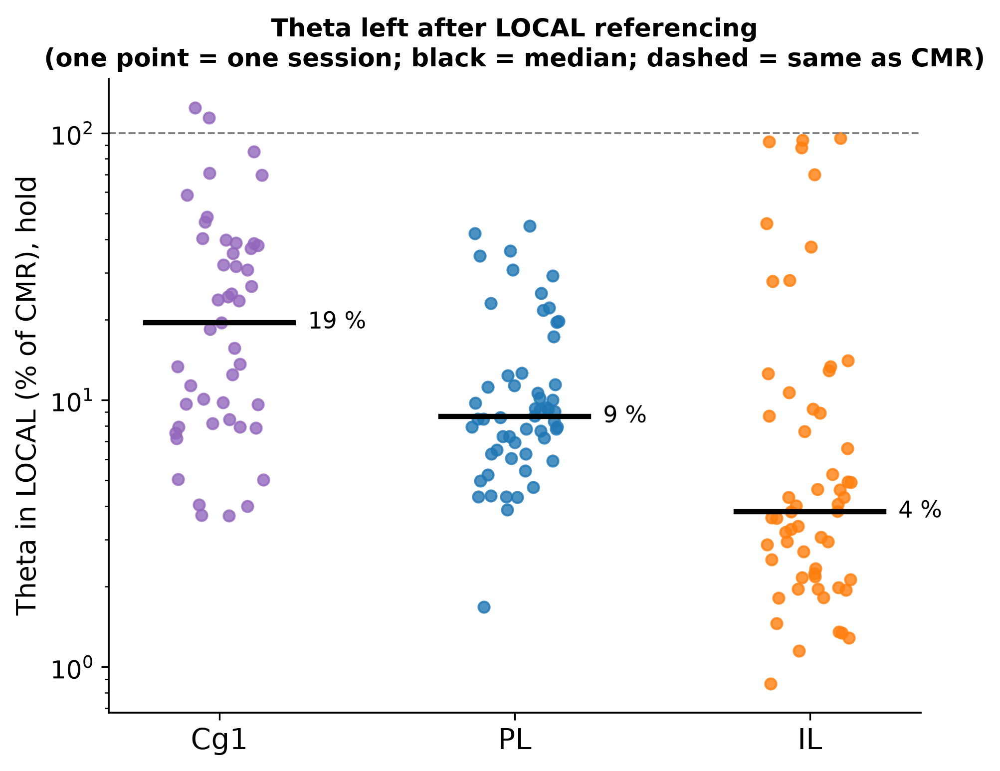

saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\theta_left_LOCAL_vs_CMR_all_sessions.png


In [29]:
# ── THETA LEFT IN LOCAL (% of CMR), hold, correct long: one point per session, regions in colour (representative channels) (needs cell 0) ──
from IPython.display import Image, display
PC_DIR = os.path.join(AMIR, "Theta", "Phase connectivity"); os.makedirs(PC_DIR, exist_ok=True)
REFS, REGS, BAND = ("CMR", "LOCAL"), ("Cg1", "PL", "IL"), "theta 4-7"
RC = {"Cg1": "#9467bd", "PL": "#1f77b4", "IL": "#ff7f0e"}

rows = []
for s in final["session"]:
    fb = os.path.join(BURST_DIR, s + ".npz")
    if not (os.path.exists(fb) and all(os.path.exists(os.path.join(BP_DIRS[r], s + ".pkl")) for r in REFS)): continue
    zb = np.load(fb); R = {r: load_bp(s, r) for r in REFS}
    for g in REGS:
        if f"CMR|{g}|channel" not in zb.files: continue
        c = str(zb[f"CMR|{g}|channel"][0]); v = {}
        for r in REFS:
            ids = [str(x) for x in R[r]["meta"]["channel_ids"]]
            Tr = R[r]["trials"]; cl = ((Tr["label"] == "correct") & (Tr["type"] == "long")).values
            if c not in ids or cl.sum() < 10: break
            v[r] = np.nanmean(R[r]["logpow"][BAND]["hold"][cl, ids.index(c)])        # mean log10 power over trials
        if len(v) == 2:
            rows.append(dict(session=s, rat=str(RAT[s]), region=g, LOCAL_pct_of_CMR=100 * 10 ** (v["LOCAL"] - v["CMR"])))
    del R
L_ = pd.DataFrame(rows)
print("theta (4–7 Hz) in LOCAL, % of CMR, hold, correct long, representative channels:")
for g in REGS:
    d = L_[L_.region == g].LOCAL_pct_of_CMR
    print(f"  {g:4s} ({len(d)} sessions): median {d.median():.1f} %  [25th–75th {d.quantile(.25):.1f}–{d.quantile(.75):.1f} %]")
L_.to_csv(os.path.join(PC_DIR, "theta_left_LOCAL_vs_CMR_all_sessions.csv"), index=False)

plt.rcParams.update({"font.size": 12, "axes.linewidth": 0.9})
fig, ax = plt.subplots(figsize=(7, 5.5), facecolor="white")
rng = np.random.default_rng(0)
for i, g in enumerate(REGS):
    d = L_[L_.region == g].LOCAL_pct_of_CMR
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(d)), d, s=28, color=RC[g], alpha=0.8, zorder=2)
    ax.plot([i - 0.25, i + 0.25], [d.median()] * 2, color="k", lw=2.5, zorder=3)
    ax.text(i + 0.3, d.median(), f"{d.median():.0f} %", va="center", fontsize=11)
ax.axhline(100, color="0.5", lw=0.9, ls="--")
ax.set_yscale("log"); ax.set_xticks(range(len(REGS))); ax.set_xticklabels(REGS, fontsize=14)
ax.set_ylabel("Theta in LOCAL (% of CMR), hold", fontsize=13)
ax.set_title("Theta left after LOCAL referencing\n(one point = one session; black = median; dashed = same as CMR)", fontsize=12, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fp = os.path.join(PC_DIR, "theta_left_LOCAL_vs_CMR_all_sessions.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("saved:", fp)

In [85]:
# ── MOST LOCAL REFERENCE THAT STILL HAS THETA: same-region rings, theta peak by FOOOF (specparam), pilot, correct long, hold (needs cell 0 and 1q-A) ──
import scipy.signal as ss
from fooof import FOOOF
SEEDS = {"IL AP49": "imec0.ap#AP49", "PL AP241": "imec0.ap#AP241", "Cg1 AP205": "imec0.ap#AP205", "PL AP257": "imec0.ap#AP257", "Cg1 AP156": "imec0.ap#AP156"}
MAIN = ("IL AP49", "PL AP241")
INNER, OUTER, MIN_CH = (30, 50, 100, 150, 200, 300, 500), (150, 200, 250, 300, 400, 500, 750, 1000), 5
FQ, NC, HOLD, STEP_S = np.arange(2, 31), 5, (0.20, 0.85), 0.010
FOOOF_KW = dict(peak_width_limits=(1, 8), max_n_peaks=4, aperiodic_mode="fixed", verbose=False)
PCOL = {"IL–Cg1": "#81C784", "IL–PL": "#43A047", "PL–Cg1": "#1B5E20"}            # light, mid, dark green

T = load_bp(SES, "LOCAL")["trials"]; T = T[(T["type"] == "long") & (T["label"] == "correct")].reset_index(drop=True)
a0, a1 = fn.MAIN_EPOCHS["Press"]
X, ok = fn.read_epochs(rec0, T["press_s"].values, a0, a1); fs = rec0.get_sampling_frequency()      # all channels, original
t = np.arange(X.shape[-1]) / fs + a0; idx = np.where((t >= HOLD[0]) & (t <= HOLD[1]))[0][::int(round(STEP_S * fs))]
spec = lambda x: np.array([(np.abs(ss.fftconvolve(x, fn.morlet(f, NC, fs)[None, :], mode="same", axes=-1)[:, idx]) ** 2).mean() for f in FQ])

def theta_peak(P):
    """FOOOF fit 2–30 Hz -> (peak centre Hz, height above 1/f in log10) of the strongest peak with centre 4–8 Hz, or (nan, 0)"""
    fm = FOOOF(**FOOOF_KW); fm.fit(FQ.astype(float), P, [2, 30])
    pk = [p for p in fm.peak_params_ if 4 <= p[0] <= 8]
    return (max(pk, key=lambda p: p[1])[0], max(pk, key=lambda p: p[1])[1]) if pk else (np.nan, 0.0)

rows = []
for name, c in SEEDS.items():
    i = IDS.index(c); x0 = X[:, i].astype(np.float64); P0 = spec(x0); th0 = P0[(FQ >= 4) & (FQ <= 7)].mean()
    cf, h = theta_peak(P0)
    rows.append(dict(seed=name, ring="original", inner=np.nan, outer=np.nan, n=0, theta_left_pct=100.0, peak=bool(h > 0), peak_hz=cf, peak_height=h))
    for hi in OUTER:
        for lo in INNER:
            if lo >= hi: continue
            s_set = np.where((REG == REG[i]) & (DIST[i] > lo) & (DIST[i] <= hi))[0]
            if len(s_set) < MIN_CH: continue
            P = spec(x0 - np.median(X[:, s_set], axis=1)); cf, h = theta_peak(P)
            rows.append(dict(seed=name, ring=f"{lo}–{hi}", inner=lo, outer=hi, n=len(s_set),
                             theta_left_pct=100 * P[(FQ >= 4) & (FQ <= 7)].mean() / th0, peak=bool(h > 0), peak_hz=cf, peak_height=h))
    print(f"{name} done", flush=True)
del X
SC = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 300)
SC.to_csv(os.path.join(AMIR, "Theta", "Phase connectivity", "reference_scan_fooof_pilot.csv"), index=False)

print(f"\n{SES}: {int(ok.sum())} correct long trials, hold | theta peak = FOOOF peak with centre 4–8 Hz (height = log10 above 1/f)")
print("original:"); print(SC[SC.ring == "original"][["seed", "peak", "peak_hz", "peak_height"]].round(2).to_string(index=False))
W_ = SC[SC.ring != "original"].copy()
cell = W_.apply(lambda r: f"{r.theta_left_pct:.0f}% {'P' if r.peak else '-'}{'' if not r.peak else f'{r.peak_height:.2f}'}", axis=1)
print("\nper ring (sorted most local first): theta left % | P = theta peak (height) / - = no peak")
print(W_.assign(v=cell).pivot_table(index=["outer", "inner"], columns="seed", values="v", aggfunc="first").to_string())

# most local ring with a theta peak at the main pair / at all seeds (rings available for all of them)
ok_main = W_[W_.seed.isin(MAIN)].groupby(["outer", "inner"]).agg(n_seeds=("peak", "size"), all_peak=("peak", "all")).reset_index()
ok_all  = W_.groupby(["outer", "inner"]).agg(n_seeds=("peak", "size"), all_peak=("peak", "all")).reset_index()
m1 = ok_main[(ok_main.n_seeds == len(MAIN)) & ok_main.all_peak].sort_values(["outer", "inner"])
m2 = ok_all[(ok_all.n_seeds == len(SEEDS)) & ok_all.all_peak].sort_values(["outer", "inner"])
print(f"\nmost local ring with a theta peak at {MAIN}: " + (f"{int(m1.iloc[0].inner)}–{int(m1.iloc[0].outer)} µm" if len(m1) else "none"))
print("most local ring with a theta peak at all 5 seeds: " + (f"{int(m2.iloc[0].inner)}–{int(m2.iloc[0].outer)} µm" if len(m2) else "none"))

IL AP49 done
PL AP241 done


KeyboardInterrupt: 

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1q. Theta phase coupling of the three pairs with a same-region local reference (30–500 µm) — pilot, correct long, hold
Reference chosen before computing coupling (pilot scan): each channel minus the median of the channels in the SAME region 30–500 µm away
(original recording). Rules for re-referencing (Bastos & Schoffelen 2016; Trongnetrpunya et al. 2016): the two signals share no subtracted channel,
and no channel of the partner's region is subtracted. 30–500 µm is the most local same-region ring with a theta peak above the 1/f background
(FOOOF, centre 4–8 Hz) at all five pilot channels (theta left: IL AP49 22 %, PL AP241 17 % of original). CMR (shares all channels) and
LOCAL 30–200 µm (theta removed) are not used.<br>
Coupling as 1p: MNE-Python spectral_connectivity_epochs (PLV, PLI, PPC, debiased wPLI²), across trials per time point and frequency (4–7 Hz, 5 cycles),
mean over frequencies and the hold window (0.2–0.85 s); chance from 500 trial shuffles (own validated code); raw one-sided p.<br>
Saved: amir_data\Theta\Phase connectivity\pilot_3pairs_coupling_hold_sameregion_30-500.png, .csv
<div>

20260529_r0000136_wt_1318: same-region ring 30–500 µm
  IL–Cg1: AP49 (IL) minus 24 ch | AP205 (Cg1) minus 37 ch | shared 0
  IL–PL: AP49 (IL) minus 24 ch | AP241 (PL) minus 72 ch | shared 0
  PL–Cg1: AP257 (PL) minus 64 ch | AP156 (Cg1) minus 128 ch | shared 0

49 correct long trials, hold 0.2–0.85 s | MNE 0.9.0 | 500 shuffles | Δφ > 0 = first region leads
  pair  trials  mean_dphi_deg   plv  chance95_plv  p_plv   pli  chance95_pli  p_pli   ppc  chance95_ppc  p_ppc  dwpli  chance95_dwpli  p_dwpli
IL–Cg1      49         -9.026 0.183         0.170  0.014 0.131         0.160  0.214 0.027         0.014  0.006  0.020           0.046    0.182
 IL–PL      49         67.038 0.205         0.164  0.004 0.187         0.152  0.004 0.029         0.013  0.002  0.146           0.036    0.002
PL–Cg1      49        144.113 0.131         0.161  0.411 0.134         0.160  0.188 0.002         0.012  0.351  0.044           0.031    0.020


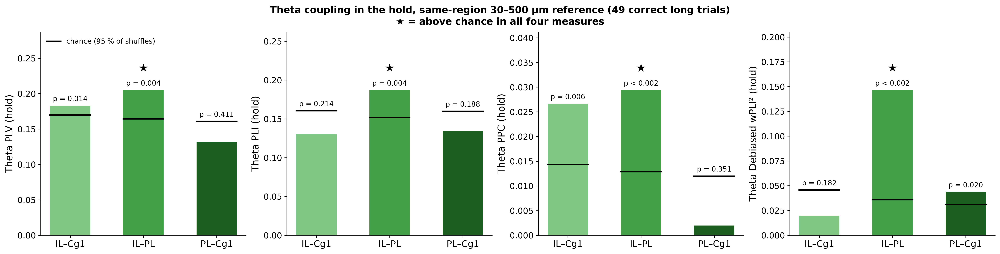

pairs above chance in all four measures: ['IL–PL']
saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\pilot_3pairs_coupling_hold_sameregion_30-500.png


In [86]:
# ── 1q. THETA PLV, PLI, PPC, DEBIASED wPLI² (MNE), 3 PAIRS, PILOT, CORRECT LONG, HOLD — SAME-REGION 30–500 µm REFERENCE (needs cell 0) ──
importlib.reload(fn)
import scipy.signal as ss
import mne_connectivity
from mne_connectivity import spectral_connectivity_epochs
from IPython.display import Image, display
PC_DIR = os.path.join(AMIR, "Theta", "Phase connectivity"); os.makedirs(PC_DIR, exist_ok=True)
SES, RING = TEST, (30, 500)
PAIRS = {"IL–Cg1": ("imec0.ap#AP49", "imec0.ap#AP205"), "IL–PL": ("imec0.ap#AP49", "imec0.ap#AP241"),
         "PL–Cg1": ("imec0.ap#AP257", "imec0.ap#AP156")}
PCOL = {"IL–Cg1": "#81C784", "IL–PL": "#43A047", "PL–Cg1": "#1B5E20"}            # light, mid, dark green
FR, NCYC = np.array(fn.MAIN_BANDS["theta 4-7"]["freqs"]), fn.MAIN_BANDS["theta 4-7"]["n_cycles"]
HOLD, STEP_S, NSH, RNG = (0.20, 0.85), 0.010, 500, np.random.default_rng(0)
MEAS = [("plv", "plv", "PLV"), ("pli", "pli", "PLI"), ("ppc", "ppc", "PPC"), ("dwpli", "wpli2_debiased", "Debiased wPLI²")]
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
SHORT = {"Infralimbic area": "IL", "Prelimbic area": "PL", "Cingulate area 1": "Cg1"}

# ── recording, channel regions and distances ──
rec0 = fn.load_session(PROC, SES, XB, refs=("original",))[0]["original"]
IDS = [str(c) for c in rec0.get_channel_ids()]; LOC = rec0.get_channel_locations()
REG = np.array([SHORT.get(r, "other") for r in pd.Series(IDS).map(CHREG[CHREG.session == SES].set_index("channel_id")["region"]).fillna("")])
DIST = np.hypot(LOC[:, None, 0] - LOC[None, :, 0], LOC[:, None, 1] - LOC[None, :, 1])
ring_set = lambda i: np.where((REG == REG[i]) & (DIST[i] > RING[0]) & (DIST[i] <= RING[1]))[0]

# ── reference check: channels subtracted per side, shared channels (must be 0) ──
print(f"{SES}: same-region ring {RING[0]}–{RING[1]} µm")
for pname, (c1, c2) in PAIRS.items():
    s1, s2 = ring_set(IDS.index(c1)), ring_set(IDS.index(c2))
    print(f"  {pname}: {c1.split('#')[-1]} ({REG[IDS.index(c1)]}) minus {len(s1)} ch | {c2.split('#')[-1]} ({REG[IDS.index(c2)]}) minus {len(s2)} ch"
          f" | shared {len(np.intersect1d(s1, s2))}")

# ── epochs (all channels, original), derived signals ──
T = load_bp(SES, "LOCAL")["trials"]; T = T[(T["type"] == "long") & (T["label"] == "correct")].reset_index(drop=True)
a0, a1 = fn.MAIN_EPOCHS["Press"]
X, ok = fn.read_epochs(rec0, T["press_s"].values, a0, a1); fs = rec0.get_sampling_frequency(); Tk = T[ok].reset_index(drop=True)
assert ((Tk["release_s"] - Tk["press_s"]).values >= HOLD[1]).all(), "some trials released before the end of the hold window"
t = np.arange(X.shape[-1]) / fs + a0
idx = np.where((t >= HOLD[0]) & (t <= HOLD[1]))[0][::int(round(STEP_S * fs))]
derived = lambda c: (X[:, IDS.index(c)] - np.median(X[:, ring_set(IDS.index(c))], axis=1)).astype(np.float64)
wav = lambda x: np.stack([ss.fftconvolve(x, fn.morlet(f, NCYC, fs)[None, :], mode="same", axes=-1) for f in FR], axis=1)[..., idx]

def own(A, B):
    """validated own formulas (identical to MNE within 0.0008) — used for the shuffles only"""
    S = A * np.conj(B); E = S / np.abs(S).clip(1e-30); n = A.shape[0]
    im = S.imag; num = im.sum(0) ** 2 - (im ** 2).sum(0); den = np.abs(im).sum(0) ** 2 - (im ** 2).sum(0)
    return dict(plv=np.abs(E.mean(0)).mean(0).mean(), pli=np.abs(np.sign(E.imag).mean(0)).mean(0).mean(),
                ppc=((np.abs(E.sum(0)) ** 2 - n) / (n * (n - 1))).mean(),
                dwpli=np.nanmean(np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)))

ROWS = []
for pname, (c1, c2) in PAIRS.items():
    x1, x2 = derived(c1), derived(c2)
    cons = spectral_connectivity_epochs(np.stack([x1, x2], axis=1), method=[m[1] for m in MEAS], indices=(np.array([0]), np.array([1])),
                                        sfreq=fs, mode="cwt_morlet", cwt_freqs=FR, cwt_n_cycles=NCYC, fmin=FR[0], fmax=FR[-1],
                                        faverage=False, verbose=False)
    real = {m[0]: np.nanmean(np.squeeze(con.get_data())[:, idx].mean(0)) for m, con in zip(MEAS, cons)}
    A, B = wav(x1), wav(x2)
    E = A * np.conj(B); E = E / np.abs(E).clip(1e-30)
    row = dict(pair=pname, trials=len(Tk), mean_dphi_deg=np.degrees(np.angle(E.mean())))
    sh = [own(A, B[RNG.permutation(len(A))]) for _ in range(NSH)]
    for m, _, _ in MEAS:
        v = np.array([d[m] for d in sh])
        row.update({m: real[m], f"chance95_{m}": np.percentile(v, 95), f"p_{m}": (1 + (v >= real[m]).sum()) / (1 + NSH)})
    ROWS.append(row)
del X
WV = pd.DataFrame(ROWS); pd.set_option("display.width", 300); pd.set_option("display.max_columns", 30)
print(f"\n{len(Tk)} correct long trials, hold {HOLD[0]}–{HOLD[1]} s | MNE {mne_connectivity.__version__} | {NSH} shuffles | Δφ > 0 = first region leads")
print(WV.round(3).to_string(index=False))
WV.to_csv(os.path.join(PC_DIR, "pilot_3pairs_coupling_hold_sameregion_30-500.csv"), index=False)

# ── one figure: 4 panels; one bar per pair (pair colours), black line = 95 % chance; ★ = pair above chance in all four measures ──
plt.rcParams.update({"font.size": 12, "axes.linewidth": 0.9})
fig, axs = plt.subplots(1, 4, figsize=(20, 5), facecolor="white", constrained_layout=True)
ptxt = lambda p: "p < 0.002" if p < 0.002 else f"p = {p:.3f}"
ALPHA = 0.05
surv = {r_["pair"]: all(r_[f"p_{m}"] < ALPHA for m, _, _ in MEAS) for _, r_ in WV.iterrows()}
for ax, (m, _, lab) in zip(axs, MEAS):
    top = max(WV[m].max(), WV[f"chance95_{m}"].max())
    for i, r_ in WV.iterrows():
        ax.bar(i, r_[m], width=0.55, color=PCOL[r_["pair"]])
        ax.plot([i - 0.275, i + 0.275], [r_[f"chance95_{m}"]] * 2, color="k", lw=2, label="chance (95 % of shuffles)" if i == 0 else None)
        y0 = max(r_[m], r_[f"chance95_{m}"], 0) + 0.02 * top
        ax.text(i, y0, ptxt(r_[f"p_{m}"]), ha="center", va="bottom", fontsize=10)
        if surv[r_["pair"]]: ax.text(i, y0 + 0.09 * top, "★", ha="center", va="bottom", fontsize=16)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xticks(range(len(WV))); ax.set_xticklabels(WV.pair, fontsize=13)
    ax.set_ylabel(f"Theta {lab} (hold)", fontsize=14); ax.set_ylim(min(0, WV[m].min() * 1.2), top * 1.4)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axs[0].legend(frameon=False, fontsize=10, loc="upper left")
fig.suptitle(f"Theta coupling in the hold, same-region 30–500 µm reference ({len(Tk)} correct long trials)\n★ = above chance in all four measures",
             fontsize=14, fontweight="bold")
fp = os.path.join(PC_DIR, "pilot_3pairs_coupling_hold_sameregion_30-500.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("pairs above chance in all four measures:", [p for p, v in surv.items() if v] or "none")
print("saved:", fp)

rat 136 sessions with both pilot channels: 11
[1/11] 20260519_r0000136_wt_2031: 38 trials, Δφ +42° | 0.1 min
[2/11] 20260520_r0000136_wt_1443: 38 trials, Δφ +22° | 0.2 min
[3/11] 20260521_r0000136_wt_1221: 37 trials, Δφ +90° | 0.2 min
[4/11] 20260522_r0000136_wt_1750: 55 trials, Δφ +101° | 0.3 min
[5/11] 20260523_r0000136_wt_1320: 54 trials, Δφ +7° | 0.5 min
[6/11] 20260524_r0000136_wt_1836: 52 trials, Δφ +141° | 0.6 min
[7/11] 20260525_r0000136_wt_1523: 57 trials, Δφ +90° | 0.7 min
[8/11] 20260526_r0000136_wt_1317: 40 trials, Δφ +93° | 0.8 min
[9/11] 20260527_r0000136_wt_1252: 41 trials, Δφ +121° | 0.8 min
[10/11] 20260528_r0000136_wt_1912: 64 trials, Δφ +44° | 1.0 min
[11/11] 20260529_r0000136_wt_1318 (PILOT): 49 trials, Δφ +67° | 1.0 min
saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\Rat 136 pilot channels\rat136_pilot_channels_sessions.csv | exists: True


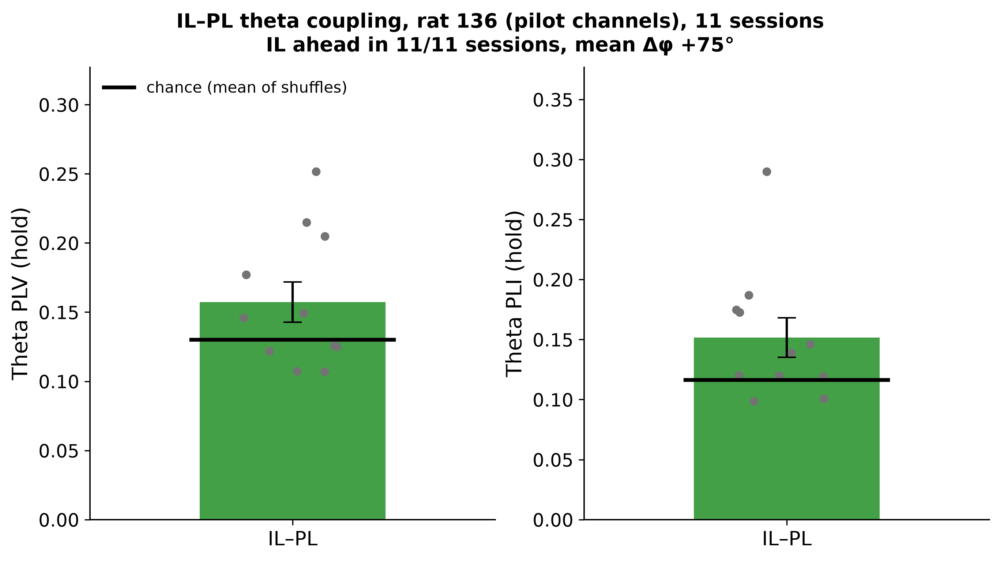

measure  sessions   mean    sem  chance  mean_minus_chance      p
    PLV        11 0.1573 0.0146  0.1301             0.0273 0.0711
    PLI        11 0.1516 0.0165  0.1162             0.0354 0.0197
saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\Rat 136 pilot channels\rat136_pilot_channels_IL_PL_averaged.png


In [87]:
# ── STEP A-136 (compute): IL–PL theta coupling with the pilot channels AP49 – AP241, rat 136, all sessions with them, SR30-500, correct long, hold (needs cell 0) ──
importlib.reload(fn)
import time, scipy.signal as ss
from mne_connectivity import spectral_connectivity_epochs
PC_DIR = os.path.join(AMIR, "Theta", "Phase connectivity", "Rat 136 pilot channels"); os.makedirs(PC_DIR, exist_ok=True)
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
SHORT = {"Infralimbic area": "IL", "Prelimbic area": "PL", "Cingulate area 1": "Cg1"}
PCH = {"IL": "imec0.ap#AP49", "PL": "imec0.ap#AP241"}; PXY = {"IL": (282, 0), "PL": (532, 2160)}
RING = (30, 500)
FR, NCYC = np.array(fn.MAIN_BANDS["theta 4-7"]["freqs"]), fn.MAIN_BANDS["theta 4-7"]["n_cycles"]
HOLD, STEP_S, NSH, RNG = (0.20, 0.85), 0.010, 200, np.random.default_rng(0)
MIN_TR, MIN_RING = 10, 5
MEAS = [("plv", "plv"), ("pli", "pli"), ("ppc", "ppc"), ("dwpli", "wpli2_debiased")]

def own(A, B):
    """validated own formulas (identical to MNE within 0.0008) — shuffles only"""
    S = A * np.conj(B); E = S / np.abs(S).clip(1e-30); n = A.shape[0]
    im = S.imag; num = im.sum(0) ** 2 - (im ** 2).sum(0); den = np.abs(im).sum(0) ** 2 - (im ** 2).sum(0)
    return dict(plv=np.abs(E.mean(0)).mean(0).mean(), pli=np.abs(np.sign(E.imag).mean(0)).mean(0).mean(),
                ppc=((np.abs(E.sum(0)) ** 2 - n) / (n * (n - 1))).mean(),
                dwpli=np.nanmean(np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)))

C = CHREG[CHREG.session.isin(final["session"]) & (CHREG.rat.astype(str) == "136")]
SESS = sorted(s for s, d in C.groupby("session")
              if all(((d.channel_id == PCH[g]) & (np.hypot(d.x - PXY[g][0], d.y - PXY[g][1]) < 1)).any() for g in PCH))
print(f"rat 136 sessions with both pilot channels: {len(SESS)}", flush=True)
rows, t_ = [], time.time()
for n_, s in enumerate(SESS, 1):
    T = fn.session_trials(K, s)
    T = T[(T["type"] == "long") & (T["label"] == "correct") & ((T["release_s"] - T["press_s"]) >= HOLD[1])].reset_index(drop=True)
    if len(T) < MIN_TR: print(f"[{n_}] {s}: {len(T)} trials, skipped"); continue
    rec = fn.load_session(PROC, s, XB, refs=("original",))[0]["original"]; fs = rec.get_sampling_frequency()
    ids = [str(c) for c in rec.get_channel_ids()]; loc = rec.get_channel_locations()
    reg = np.array([SHORT.get(r, "other") for r in pd.Series(ids).map(CHREG[CHREG.session == s].set_index("channel_id")["region"]).fillna("")])
    def ring_set(i): dd = np.hypot(loc[:, 0] - loc[i, 0], loc[:, 1] - loc[i, 1]); return np.where((reg == reg[i]) & (dd > RING[0]) & (dd <= RING[1]))[0]
    rs = {g: ring_set(ids.index(c)) for g, c in PCH.items()}
    if min(len(v) for v in rs.values()) < MIN_RING: print(f"[{n_}] {s}: ring too small, skipped"); continue
    a0, a1 = fn.MAIN_EPOCHS["Press"]
    X, ok = fn.read_epochs(rec, T["press_s"].values, a0, a1); t = np.arange(X.shape[-1]) / fs + a0
    idx = np.where((t >= HOLD[0]) & (t <= HOLD[1]))[0][::int(round(STEP_S * fs))]
    x1, x2 = [(X[:, ids.index(PCH[g])] - np.median(X[:, rs[g]], axis=1)).astype(np.float64) for g in ("IL", "PL")]; del X
    cons = spectral_connectivity_epochs(np.stack([x1, x2], axis=1), method=[m[1] for m in MEAS], indices=(np.array([0]), np.array([1])),
                                        sfreq=fs, mode="cwt_morlet", cwt_freqs=FR, cwt_n_cycles=NCYC, fmin=FR[0], fmax=FR[-1],
                                        faverage=False, verbose=False)
    real = {m[0]: np.nanmean(np.squeeze(con.get_data())[:, idx].mean(0)) for m, con in zip(MEAS, cons)}
    wav = lambda x: np.stack([ss.fftconvolve(x, fn.morlet(f_, NCYC, fs)[None, :], mode="same", axes=-1) for f_ in FR], axis=1)[..., idx]
    A, B = wav(x1), wav(x2); E = A * np.conj(B); E = E / np.abs(E).clip(1e-30)
    sh = [own(A, B[RNG.permutation(len(A))]) for _ in range(NSH)]
    row = dict(session=s, pilot=(s == TEST), ref="SR30-500", pair="IL–PL", trials=len(T), dphi_deg=np.degrees(np.angle(E.mean())))
    for m, _ in MEAS:
        v = np.array([d_[m] for d_ in sh]); row.update({m: real[m], f"chance_{m}": v.mean(), f"p_{m}": (1 + (v >= real[m]).sum()) / (1 + NSH)})
    rows.append(row)
    print(f"[{n_}/{len(SESS)}] {s}{' (PILOT)' if s == TEST else ''}: {len(T)} trials, Δφ {row['dphi_deg']:+.0f}° | {(time.time() - t_) / 60:.1f} min", flush=True)
    del rec
D = pd.DataFrame(rows); fp = os.path.join(PC_DIR, "rat136_pilot_channels_sessions.csv"); D.to_csv(fp, index=False)
print("saved:", fp, "| exists:", os.path.exists(fp))
# ── STEP A-136 (IL–PL): 1q FIGURE, SESSIONS AVERAGED — pilot channels AP49 – AP241, rat 136, 10 sessions without the pilot, SR30-500 (needs cell 0) ──
from IPython.display import Image, display
PC_DIR = os.path.join(AMIR, "Theta", "Phase connectivity", "Rat 136 pilot channels")
D = pd.read_csv(os.path.join(PC_DIR, "rat136_pilot_channels_sessions.csv"))
d = D[(D.pair == "IL–PL") & (D.ref == "SR30-500")].reset_index(drop=True)
MEAS = [("plv", "PLV"), ("pli", "PLI")]
COL = "#43A047"; ptxt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
rng = np.random.default_rng(0)
mean_dphi = np.degrees(np.angle(np.exp(1j * np.radians(d.dphi_deg)).mean())); n_ahead = int((np.sin(np.radians(d.dphi_deg)) > 0).sum())

plt.rcParams.update({"font.size": 12, "axes.linewidth": 0.9})
fig, axs = plt.subplots(1, 2, figsize=(9, 5), facecolor="white", constrained_layout=True)
rows = []
for ax, (m, lab) in zip(axs, MEAS):
    real, ch = d[m].values, d[f"chance_{m}"].values
    _, p, _ = fn.sign_flip_p(real - ch, n_perm=10000)
    rows.append(dict(measure=lab, sessions=len(d), mean=real.mean(), sem=real.std(ddof=1) / np.sqrt(len(d)), chance=ch.mean(),
                     mean_minus_chance=(real - ch).mean(), p=p))
    ax.bar(0, real.mean(), width=0.55, color=COL, zorder=1)
    ax.errorbar(0, real.mean(), yerr=real.std(ddof=1) / np.sqrt(len(d)), color="k", capsize=6, lw=1.5, zorder=3)
    ax.scatter(rng.uniform(-0.15, 0.15, len(d)), real, s=22, color="0.45", zorder=2)
    ax.plot([-0.3, 0.3], [ch.mean()] * 2, color="k", lw=2.5, zorder=4, label="chance (mean of shuffles)")

    ax.axhline(0, color="0.5", lw=0.8); ax.set_xlim(-0.6, 0.6); ax.set_xticks([0]); ax.set_xticklabels(["IL–PL"], fontsize=13)
    ax.set_ylabel(f"Theta {lab} (hold)", fontsize=14); ax.set_ylim(min(0, real.min() * 1.3), max(real.max(), ch.mean()) * 1.3)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axs[0].legend(frameon=False, fontsize=10, loc="upper left")
fig.suptitle(f"IL–PL theta coupling, rat 136 (pilot channels), {len(d)} sessions\nIL ahead in {n_ahead}/{len(d)} sessions, mean Δφ {mean_dphi:+.0f}°",
             fontsize=13, fontweight="bold")
fp = os.path.join(PC_DIR, "rat136_pilot_channels_IL_PL_averaged.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print(pd.DataFrame(rows).round(4).to_string(index=False)); print("saved:", fp)

In [61]:
d_ = os.path.join(AMIR, "Theta", "Phase connectivity")
for root, dirs, files in os.walk(d_):
    for f in files:
        if "rat136" in f: print(os.path.join(root, f))

mean Δφ over 11 sessions +75° | example session (closest to the mean): 20260529_r0000136_wt_1318
example trial 37: Δφ +63° (9 trials within ±20° of the mean)


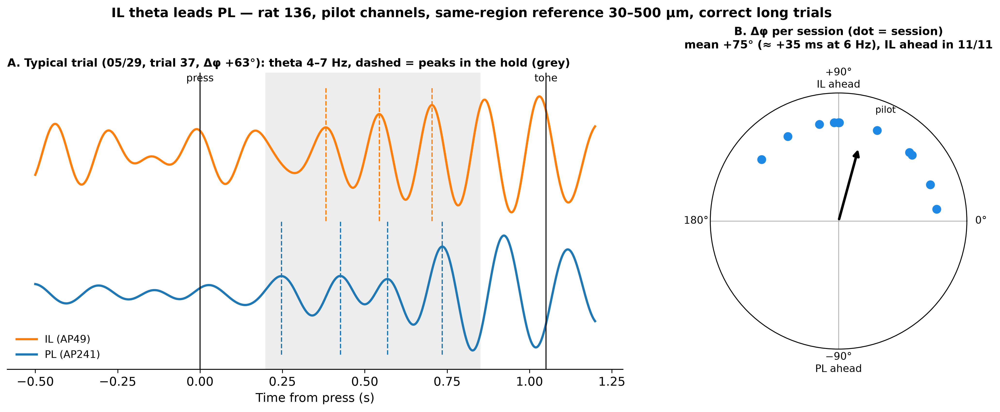

saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\Rat 136 pilot channels\rat136_IL_PL_lead_example_sessions.png


In [63]:
# ── IL AHEAD OF PL: example trial (typical, by rule) + Δφ per session (polar) — rat 136, pilot channels AP49 – AP241, SR30-500, correct long (needs cell 0) ──
importlib.reload(fn)
import scipy.signal as ss
from IPython.display import Image, display
PC_DIR = os.path.join(AMIR, "Theta", "Phase connectivity", "Rat 136 pilot channels")
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
SHORT = {"Infralimbic area": "IL", "Prelimbic area": "PL", "Cingulate area 1": "Cg1"}
IL_C, PL_C, RING = "imec0.ap#AP49", "imec0.ap#AP241", (30, 500)
FR, NCYC = np.array(fn.MAIN_BANDS["theta 4-7"]["freqs"]), fn.MAIN_BANDS["theta 4-7"]["n_cycles"]
HOLD, STEP_S, TONE, F_LAG, WIN = (0.20, 0.85), 0.010, 1.05, 6.0, 20
COL_IL, COL_PL, COL = "#ff7f0e", "#1f77b4", "#1E88E5"

# ── sessions: mean Δφ, session closest to it ──
D = pd.read_csv(os.path.join(PC_DIR, "rat136_pilot_channels_sessions.csv"))
d = D[(D.pair == "IL–PL") & (D.ref == "SR30-500")].sort_values("session").reset_index(drop=True); d["pilot"] = d["pilot"].astype(bool)
th = np.radians(d.dphi_deg.values); mean_ang = np.angle(np.exp(1j * th).mean()); R = np.abs(np.exp(1j * th).mean())
s_ex = d.session[np.argmin(np.abs(np.angle(np.exp(1j * (th - mean_ang)))))]
print(f"mean Δφ over {len(d)} sessions {np.degrees(mean_ang):+.0f}° | example session (closest to the mean): {s_ex}", flush=True)

# ── example session: SR30-500 signals, per-trial Δφ in the hold, trial within ±WIN° of the mean with the strongest theta ──
T = fn.session_trials(K, s_ex)
T = T[(T["type"] == "long") & (T["label"] == "correct") & ((T["release_s"] - T["press_s"]) >= HOLD[1])].reset_index(drop=True)
rec = fn.load_session(PROC, s_ex, XB, refs=("original",))[0]["original"]; fs = rec.get_sampling_frequency()
ids = [str(c) for c in rec.get_channel_ids()]; loc = rec.get_channel_locations()
reg = np.array([SHORT.get(r, "other") for r in pd.Series(ids).map(CHREG[CHREG.session == s_ex].set_index("channel_id")["region"]).fillna("")])
def ring_set(i): dd = np.hypot(loc[:, 0] - loc[i, 0], loc[:, 1] - loc[i, 1]); return np.where((reg == reg[i]) & (dd > RING[0]) & (dd <= RING[1]))[0]
a0, a1 = fn.MAIN_EPOCHS["Press"]
X, ok = fn.read_epochs(rec, T["press_s"].values, a0, a1); t = np.arange(X.shape[-1]) / fs + a0
der = lambda c: (X[:, ids.index(c)] - np.median(X[:, ring_set(ids.index(c))], axis=1)).astype(np.float64)
xIL, xPL = der(IL_C), der(PL_C); del X
idx = np.where((t >= HOLD[0]) & (t <= HOLD[1]))[0][::int(round(STEP_S * fs))]
wav = lambda x: np.stack([ss.fftconvolve(x, fn.morlet(f, NCYC, fs)[None, :], mode="same", axes=-1) for f in FR], axis=1)[..., idx]
A, B = wav(xIL), wav(xPL); E = A * np.conj(B); E = E / np.abs(E).clip(1e-30)
dphi_tr = np.angle(E.mean(axis=(1, 2)))
amp = 0.5 * (np.abs(A).mean(axis=(1, 2)) + np.abs(B).mean(axis=(1, 2)))
near = np.where(np.abs(np.angle(np.exp(1j * (dphi_tr - mean_ang)))) <= np.radians(WIN))[0]
k = near[np.argmax(amp[near])] if len(near) else int(np.argmax(amp))
sos = ss.butter(4, [4, 7], btype="bandpass", fs=fs, output="sos")                  # zero-phase theta filter (display only)
fIL, fPL = ss.sosfiltfilt(sos, xIL[k]), ss.sosfiltfilt(sos, xPL[k])
show = (t >= -0.5) & (t <= 1.2); nIL, nPL = fIL / np.abs(fIL[show]).max(), fPL / np.abs(fPL[show]).max()
print(f"example trial {k}: Δφ {np.degrees(dphi_tr[k]):+.0f}° ({len(near)} trials within ±{WIN}° of the mean)")

# ── figure ──
plt.rcParams.update({"font.size": 12, "axes.linewidth": 0.9})
fig = plt.figure(figsize=(17, 5.3), facecolor="white"); gs = fig.add_gridspec(1, 2, width_ratios=[2.4, 1], wspace=0.2)
ax = fig.add_subplot(gs[0])
ax.axvspan(*HOLD, color="0.93", zorder=0)
ax.plot(t[show], nIL[show] + 1.2, color=COL_IL, lw=2.2, label="IL (AP49)"); ax.plot(t[show], nPL[show] - 1.2, color=COL_PL, lw=2.2, label="PL (AP241)")
mw = (t >= HOLD[0]) & (t <= HOLD[1])
for p in t[mw][ss.find_peaks(nIL[mw], distance=int(0.1 * fs))[0]]: ax.axvline(p, ymin=0.5, ymax=0.95, color=COL_IL, ls="--", lw=1.2)
for p in t[mw][ss.find_peaks(nPL[mw], distance=int(0.1 * fs))[0]]: ax.axvline(p, ymin=0.05, ymax=0.5, color=COL_PL, ls="--", lw=1.2)
for x_, lb in ((0, "press"), (TONE, "tone")): ax.axvline(x_, color="k", lw=1); ax.text(x_, 2.45, lb, ha="center", fontsize=10)
ax.set_yticks([]); ax.set_ylim(-2.5, 2.6); ax.set_xlabel("Time from press (s)")
ax.set_title(f"A. Typical trial ({s_ex[4:6]}/{s_ex[6:8]}, trial {k}, Δφ {np.degrees(dphi_tr[k]):+.0f}°): theta 4–7 Hz, dashed = peaks in the hold (grey)",
             loc="left", fontsize=11, fontweight="bold")
ax.legend(frameon=False, loc="lower left", fontsize=10)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
axp = fig.add_subplot(gs[1], projection="polar")
axp.scatter(th, np.ones(len(th)), s=60, color=COL, zorder=3)
for a_, pl in zip(th, d.pilot):
    if pl: axp.text(a_, 1.22, "pilot", ha="center", va="center", fontsize=9)
axp.annotate("", xy=(mean_ang, R), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2.5))
axp.set_ylim(0, 1.3); axp.set_yticks([]); axp.set_xticks(np.radians([0, 90, 180, 270]))
axp.set_xticklabels(["0°", "+90°\nIL ahead", "180°", "−90°\nPL ahead"], fontsize=10)
lag_ms = np.degrees(mean_ang) / 360 * 1000 / F_LAG
axp.set_title(f"B. Δφ per session (dot = session)\nmean {np.degrees(mean_ang):+.0f}° (≈ {lag_ms:+.0f} ms at {F_LAG:.0f} Hz), "
              f"IL ahead in {int((np.sin(th) > 0).sum())}/{len(th)}", fontsize=11, fontweight="bold", pad=18)
fig.suptitle("IL theta leads PL — rat 136, pilot channels, same-region reference 30–500 µm, correct long trials", fontsize=13, fontweight="bold", y=1.05)
fp = os.path.join(PC_DIR, "rat136_IL_PL_lead_example_sessions.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("saved:", fp)

[1/60] 20260510_r0000135_wt_1625: 2 trials, skipped
[2/60] 20260510_r0000136_wt_1926: 60 trials, 61 IL × 35 PL, 650 pairs — computing...
      PLV 0.218 (chance 0.114) | PLI 0.153 (chance 0.103) | 1.0 min
[3/60] 20260511_r0000136_wt_0909: 13 trials, 61 IL × 35 PL, 650 pairs — computing...
      PLV 0.287 (chance 0.247) | PLI 0.239 (chance 0.225) | 1.2 min
[4/60] 20260511_r0000136_wt_0930: 34 trials, 61 IL × 35 PL, 650 pairs — computing...
      PLV 0.249 (chance 0.152) | PLI 0.188 (chance 0.135) | 1.7 min
[5/60] 20260511_r0000136_wt_1832: 38 trials, 61 IL × 35 PL, 650 pairs — computing...
      PLV 0.247 (chance 0.147) | PLI 0.178 (chance 0.133) | 2.3 min
[6/60] 20260512_r0000136_wt_1054: 50 trials, 61 IL × 35 PL, 650 pairs — computing...
      PLV 0.228 (chance 0.124) | PLI 0.157 (chance 0.111) | 3.1 min
[7/60] 20260513_r0000136_wt_1729: 11 trials, 61 IL × 35 PL, 650 pairs — computing...
      PLV 0.307 (chance 0.267) | PLI 0.263 (chance 0.243) | 3.3 min
[8/60] 20260514_r0000136_wt_13

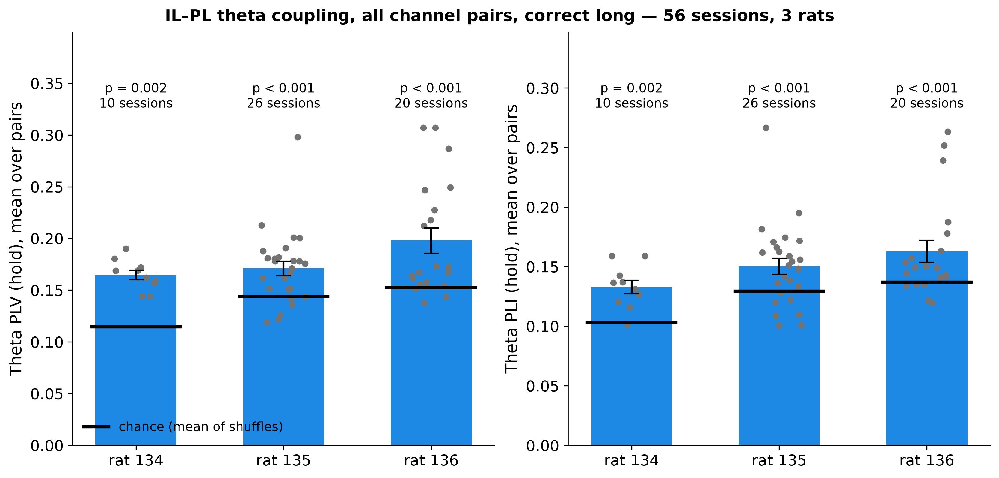

saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\All sessions all pairs\all_pairs_correct_long_per_rat.png


In [97]:
# ── 06: ALL-PAIRS IL–PL THETA PLV and PLI, CORRECT LONG, ALL SESSIONS — SR30-500, hold, every 4th channel, pairs ≥ 1000 µm, vs trial-shuffle chance (needs 06 cell 0) ──
importlib.reload(fn)
import time, scipy.signal as ss
from IPython.display import Image, display
OUT = os.path.join(AMIR, "Theta", "Phase connectivity", "All sessions all pairs"); os.makedirs(OUT, exist_ok=True)
FILE = os.path.join(OUT, "all_pairs_correct_long_sessions.csv")
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
SHORT = {"Infralimbic area": "IL", "Prelimbic area": "PL", "Cingulate area 1": "Cg1"}
RING, MIN_RING, STRIDE, MIN_PAIR_UM, SHANK_W = (30, 500), 5, 4, 1000, 250
WIN, STEP_S, NSH, MIN_TR, RNG = (0.20, 0.85), 0.010, 50, 10, np.random.default_rng(0)
FR, NCYC = np.array(fn.MAIN_BANDS["theta 4-7"]["freqs"]), fn.MAIN_BANDS["theta 4-7"]["n_cycles"]
globals().pop("C", None)

def pv_all(a, b, M):
    """mean PLV and PLI over all IL × PL pairs in mask M; a: (trials, nIL, F, T), b: (trials, nPL, F, T), unit phases"""
    plv = pli = 0.0; cnt = 0
    for i in range(a.shape[1]):
        m = M[i]
        if not m.any(): continue
        E = a[:, i:i + 1] * np.conj(b[:, m])
        plv += np.abs(E.mean(0)).mean(axis=(1, 2)).sum(); pli += np.abs(np.sign(E.imag).mean(0)).mean(axis=(1, 2)).sum(); cnt += int(m.sum())
    return plv / cnt, pli / cnt

done = pd.read_csv(FILE) if os.path.exists(FILE) else pd.DataFrame()
SESS = sorted(final["session"]); t_ = time.time()
for n_, s in enumerate(SESS, 1):
    if len(done) and s in set(done.session): continue
    T = fn.session_trials(K, s); T = T[(T["type"] == "long") & (T["label"] == "correct") & ((T["release_s"] - T["press_s"]) >= WIN[1])].reset_index(drop=True)
    if len(T) < MIN_TR: print(f"[{n_}/{len(SESS)}] {s}: {len(T)} trials, skipped"); continue
    rec = fn.load_session(PROC, s, XB, refs=("original",))[0]["original"]; fs = rec.get_sampling_frequency()
    ids = [str(c) for c in rec.get_channel_ids()]; loc = rec.get_channel_locations()
    reg = np.array([SHORT.get(r, "other") for r in pd.Series(ids).map(CHREG[CHREG.session == s].set_index("channel_id")["region"]).fillna("")])
    def ring_set(i): dd = np.hypot(loc[:, 0] - loc[i, 0], loc[:, 1] - loc[i, 1]); return np.where((reg == reg[i]) & (dd > RING[0]) & (dd <= RING[1]))[0]
    CH = {}
    for g in ("IL", "PL"):
        u = [i for i in np.where(reg == g)[0] if len(ring_set(i)) >= MIN_RING]
        CH[g] = sorted(u, key=lambda i: (loc[i, 0] // SHANK_W, loc[i, 1], loc[i, 0]))[::STRIDE]
    if not CH["IL"] or not CH["PL"]: print(f"[{n_}/{len(SESS)}] {s}: no usable IL or PL channel, skipped"); continue
    PD = np.hypot(loc[CH["IL"], 0][:, None] - loc[CH["PL"], 0][None, :], loc[CH["IL"], 1][:, None] - loc[CH["PL"], 1][None, :])
    M = PD >= MIN_PAIR_UM
    if not M.any(): print(f"[{n_}/{len(SESS)}] {s}: no pair ≥ {MIN_PAIR_UM} µm, skipped"); continue
    print(f"[{n_}/{len(SESS)}] {s}: {len(T)} trials, {len(CH['IL'])} IL × {len(CH['PL'])} PL, {int(M.sum())} pairs — computing...", flush=True)
    a0, a1 = fn.MAIN_EPOCHS["Press"]
    X, ok = fn.read_epochs(rec, T["press_s"].values, a0, a1); del rec
    t = np.arange(X.shape[-1]) / fs + a0; idx = np.where((t >= WIN[0]) & (t <= WIN[1]))[0][::int(round(STEP_S * fs))]
    UW = {}
    for g in ("IL", "PL"):
        u = []
        for i in CH[g]:
            x = (X[:, i] - np.median(X[:, ring_set(i)], axis=1)).astype(np.float64)                     # SR30-500 for this channel
            W = np.stack([ss.fftconvolve(x, fn.morlet(f_, NCYC, fs)[None, :], mode="same", axes=-1) for f_ in FR], axis=1)[..., idx]
            u.append((W / np.abs(W).clip(1e-30)).astype(np.complex64))
        UW[g] = np.stack(u, axis=1)
    del X
    a, b = UW["IL"], UW["PL"]; del UW
    rv, ri = pv_all(a, b, M)
    ch = np.array([pv_all(a, b[RNG.permutation(len(a))], M) for _ in range(NSH)])
    row = pd.DataFrame([dict(session=s, rat=s.split("_")[1][-3:], trials=len(a), n_IL=len(CH["IL"]), n_PL=len(CH["PL"]), pairs=int(M.sum()),
                             mean_pair_dist_um=PD[M].mean(), plv=rv, chance_plv=ch[:, 0].mean(), p_plv=(1 + (ch[:, 0] >= rv).sum()) / (1 + NSH),
                             pli=ri, chance_pli=ch[:, 1].mean(), p_pli=(1 + (ch[:, 1] >= ri).sum()) / (1 + NSH))])
    done = pd.concat([done, row], ignore_index=True); done.to_csv(FILE, index=False)                   # saved after every session
    print(f"      PLV {rv:.3f} (chance {ch[:, 0].mean():.3f}) | PLI {ri:.3f} (chance {ch[:, 1].mean():.3f}) | {(time.time() - t_) / 60:.1f} min", flush=True)
    del a, b

# ── across sessions: all, and per rat; sign-flip on (real − chance), raw p ──
D = pd.read_csv(FILE, dtype={"rat": str}); out = []
for name, d in [("all", D)] + [(f"rat {r}", D[D.rat == r]) for r in sorted(D.rat.unique())]:
    for m in ("plv", "pli"):
        v = (d[m] - d[f"chance_{m}"]).values; _, p, _ = fn.sign_flip_p(v, n_perm=10000)
        out.append(dict(set=name, measure=m.upper(), sessions=len(v), mean=d[m].mean(), chance=d[f"chance_{m}"].mean(), mean_minus_chance=v.mean(),
                        sessions_above=f"{int((v > 0).sum())}/{len(v)}", p=p))
S_ = pd.DataFrame(out); pd.set_option("display.width", 250)
print(f"\nIL–PL theta, ALL PAIRS (every {STRIDE}th channel, pairs ≥ {MIN_PAIR_UM} µm), SR30-500, correct long, hold {WIN[0]}–{WIN[1]} s; "
      f"sign-flip across sessions on (real − chance), raw p")
print(S_.round(4).to_string(index=False))
S_.to_csv(os.path.join(OUT, "all_pairs_correct_long_summary.csv"), index=False)

# ── figure (averaged style): per rat, bar = mean, SEM, grey dots = sessions, black line = chance, p (vs chance) above ──
ptxt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
rats = sorted(D.rat.unique()); rng = np.random.default_rng(0)
plt.rcParams.update({"font.size": 12, "axes.linewidth": 0.9})
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2), facecolor="white", constrained_layout=True)
for ax, (m, lab) in zip(axs, (("plv", "PLV"), ("pli", "PLI"))):
    top = D[m].max()
    for x_, r in enumerate(rats):
        d = D[D.rat == r]; v, chv = d[m].values, d[f"chance_{m}"].values
        ax.bar(x_, v.mean(), width=0.55, color="#1E88E5", zorder=1)
        ax.errorbar(x_, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0, color="k", capsize=6, lw=1.5, zorder=3)
        ax.scatter(x_ + rng.uniform(-0.15, 0.15, len(v)), v, s=18, color="0.45", zorder=2)
        ax.plot([x_ - 0.3, x_ + 0.3], [chv.mean()] * 2, color="k", lw=2.5, zorder=4, label="chance (mean of shuffles)" if x_ == 0 else None)
        p_ = S_[(S_.set == f"rat {r}") & (S_.measure == m.upper())].p.values[0]
        ax.text(x_, top * 1.05, f"{ptxt(p_)}\n{len(v)} sessions", ha="center", va="bottom", fontsize=10)
    ax.set_xticks(range(len(rats))); ax.set_xticklabels([f"rat {r}" for r in rats]); ax.set_ylim(0, top * 1.3)
    ax.set_ylabel(f"Theta {lab} (hold), mean over pairs", fontsize=13)
    for sp_ in ("top", "right"): ax.spines[sp_].set_visible(False)
axs[0].legend(frameon=False, fontsize=10, loc="lower left")
fig.suptitle(f"IL–PL theta coupling, all channel pairs, correct long — {len(D)} sessions, 3 rats", fontsize=13, fontweight="bold")
fp = os.path.join(OUT, "all_pairs_correct_long_per_rat.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("saved:", fp)

In [15]:
# ── 1q. THETA AFTER THE RELEASE: CORRECT vs EARLY, PER REGION, IL vs PL ──
import warnings
pc = globals().get("pc", lambda x: 100 * (10 ** np.asarray(x, float) - 1))
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
BAND_E, MIN_CL, MIN_EL, MIN_CH = "theta 4-7", 10, 5, 10
MEAS_E = {"post − pre": "pre", "post − pre_release": "pre_release"}

rows = []
for ref in ["CMR", "LOCAL"]:
    for s in done_sessions(ref):
        r = load_bp(s, ref)
        C = fn.main_conditions(r["trials"])
        cl, el = C["correct long"].values, C["early long (hold>0.3)"].values
        if cl.sum() < MIN_CL or el.sum() < MIN_EL:
            continue
        masks, _ = fn.region_masks(r, CHREG, s)
        L = r["logpow"][BAND_E]
        for meas, w0 in MEAS_E.items():
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                d_ch = np.nanmean(L["post"][cl] - L[w0][cl], axis=0) - np.nanmean(L["post"][el] - L[w0][el], axis=0)
            for reg in ("IL", "PL"):
                m = masks[reg]
                if m.sum() >= MIN_CH:
                    rows.append({"ref": ref, "session": s, "rat": RAT[s], "measure": meas, "region": reg,
                                 "value": float(np.nanmedian(d_ch[m]))})
VE = pd.DataFrame(rows)

out = []
for ref in ["CMR", "LOCAL"]:
    for meas in MEAS_E:
        Wd = VE[(VE.ref == ref) & (VE.measure == meas)].pivot(index="session", columns="region", values="value")
        for test, v in (("IL", Wd["IL"]), ("PL", Wd["PL"]), ("IL − PL", Wd["IL"] - Wd["PL"])):
            v = v.dropna(); mm, p, n = fn.sign_flip_p(v.values)
            out.append({"ref": ref, "measure": meas, "test": test, "n_sessions": n, "up": int((v > 0).sum()),
                        "correct_minus_early_%": pc(mm), "p": p})
OE = pd.DataFrame(out)
OE.to_csv(os.path.join(TABLES, "theta_post_release_correct_vs_early_regions.csv"), index=False)
for ref in ["CMR", "LOCAL"]:
    print(f"\n===== theta after the release, correct − early long (%), {ref} (raw p) =====")
    print(OE[OE.ref == ref].drop(columns="ref").round({"correct_minus_early_%": 1, "p": 4}).to_string(index=False))


===== theta after the release, correct − early long (%), CMR (raw p) =====
           measure    test  n_sessions  up  correct_minus_early_%      p
        post − pre      IL          50   6                  -32.1 0.0001
        post − pre      PL          48   5                  -21.5 0.0001
        post − pre IL − PL          48  12                  -13.8 0.0001
post − pre_release      IL          50  10                  -25.7 0.0001
post − pre_release      PL          48   9                  -13.9 0.0001
post − pre_release IL − PL          48  16                  -14.1 0.0001

===== theta after the release, correct − early long (%), LOCAL (raw p) =====
           measure    test  n_sessions  up  correct_minus_early_%      p
        post − pre      IL          50  13                   -9.4 0.0001
        post − pre      PL          48  11                   -8.7 0.0001
        post − pre IL − PL          48  25                   -1.4 0.3745
post − pre_release      IL          50  17 

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

## 2. Burst Q1: more or fewer beta bursts before a late response?
Burst occupancy (Karvat 2021 rule: Morlet 7 cycles, 90th percentile per frequency over the whole session; one representative channel per region;
pooled = mean of PL, IL, Cg1 per trial), LOCAL reference.
Main test: late long vs correct long, occupancy in the 0.6 s before the tone (beta 15–30 Hz; gamma 30–100 Hz as comparison).
Session value = 100 × (mean occupancy late − mean occupancy correct), %-points; POSITIVE = more bursts before the late response (paper direction).
Across sessions: sign-flip (10,000 flips) and paired t-test; FINDING = both p < 0.05. Checks: leave-one-session-out (largest p),
without channels > 300 µm from the representative position, per rat. Raw p, no FDR.
Filter: all blocks, no minimum correct RT, sessions need ≥ 1 trial of each kind (MIN_TR = 1).

<div>

In [3]:
# %%
# ── 6a. LOAD BURST TRIAL TABLES (all sessions) — used by 6c onwards ──
importlib.reload(fn)
BURST_BANDS_R = ["beta 15-30", "gamma 30-100"]
GROUPS6 = ("mPFC pooled", "PL", "IL", "Cg1")
MIN_RT, MIN_TR = None, 1
FAR_UM = 300
TESTS6 = [("late long",  "late",  "long",  "correct", "late"),
          ("late short", "late",  "short", "correct", "late"),
          ("early long (time-matched)", "early", "long", "correct long, time-matched", "early long"),
          ("early long (own release)",  "early", "long", "correct long, own release",  "early long")]
files = [s for s in final["session"] if os.path.exists(os.path.join(BURST_DIR, s + ".npz"))]
TABS, FAR = {bd: {"late": [], "early": []} for bd in BURST_BANDS_R}, set()
for s in files:
    z = np.load(os.path.join(BURST_DIR, s + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))
    FAR |= {(s, k.split("|")[0], k.split("|")[1]) for k in z.files if k.endswith("|distance_um") and z[k][0] > FAR_UM}
    for band in BURST_BANDS_R:
        L, E = fn.burst_trial_tables(z, T, band, min_rt=MIN_RT)
        TABS[band]["late"].append(L.assign(session=s, rat=RAT[s])); TABS[band]["early"].append(E.assign(session=s, rat=RAT[s]))
TABS = {bd: {w: pd.concat(v, ignore_index=True) for w, v in d.items()} for bd, d in TABS.items()}
BETA_DIR = os.path.join(AMIR, "beta bursts"); os.makedirs(BETA_DIR, exist_ok=True)
print(f"burst files: {len(files)} | far channel-regions: {len(FAR)} | beta late-table rows: {len(TABS['beta 15-30']['late'])}")

burst files: 60 | far channel-regions: 26 | beta late-table rows: 46282


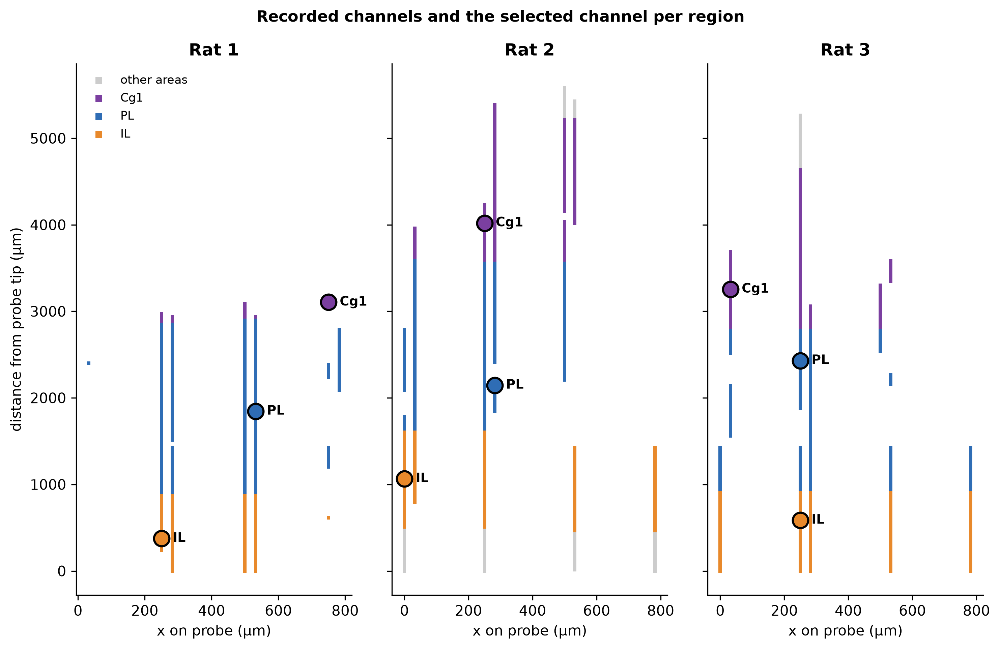

In [21]:
# ── S-probe. Recorded channels per rat and the selected channel per region (supplement) ──
from IPython.display import Image, display
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
REP = pd.read_csv(os.path.join(TABLES, "representative_channels.csv")); REP["rat"] = REP["rat"].astype(str)
FULL = {v: k for k, v in fn.REGIONS.items()}                       # "Prelimbic area" -> "PL"
RC = {"Cg1": "#7B3FA0", "PL": "#2F6DB5", "IL": "#E8892B", "other": "0.80"}
RNAME = {"134": "Rat 1", "135": "Rat 2", "136": "Rat 3"}

# 1) all recorded positions per rat (union over sessions), with their area
pos = []
for s in done_sessions("LOCAL"):
    r = load_bp(s, "LOCAL"); _, reg = fn.region_masks(r, CHREG, s)
    for x, y, g in zip(r["meta"]["x"], r["meta"]["y"], reg):
        pos.append({"rat": str(RAT[s]), "x": float(x), "y": float(y), "area": FULL.get(g, "other")})
P = pd.DataFrame(pos).drop_duplicates(["rat", "x", "y"])

# 2) figure: one panel per rat
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig, axs = plt.subplots(1, 3, figsize=(10, 6.5), sharey=True, facecolor="white")
for ax, rat in zip(axs, ["134", "135", "136"]):
    d = P[P.rat == rat]
    for area in ["other", "Cg1", "PL", "IL"]:
        k = d[d.area == area]
        ax.scatter(k.x, k.y, s=6, marker="s", color=RC[area], lw=0, label=area if area != "other" else "other areas")
    for _, rr in REP[REP.rat == rat].iterrows():
        ax.scatter(rr.x, rr.y, s=120, marker="o", facecolor=RC[rr.region], edgecolor="k", lw=1.5, zorder=5)
        ax.annotate(rr.region, (rr.x, rr.y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, fontweight="bold")
    ax.set_title(RNAME[rat], fontweight="bold"); ax.set_xlabel("x on probe (µm)")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axs[0].set_ylabel("distance from probe tip (µm)")
axs[0].legend(frameon=False, fontsize=8.5, loc="upper left", markerscale=2)
fig.suptitle("Recorded channels and the selected channel per region", fontsize=11, fontweight="bold")
fig.tight_layout()
fp = os.path.join(BETA_DIR, "supp_probe_selected_channels.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">
<b>Step 1-power: beta power around the tone, correct vs late long trials, as Karvat et al. (2021), Fig. 2D</b><br>
Beta 15–30 Hz (Morlet, 7 cycles), each frequency normalised to the 90th percentile of its artifact-free power, representative channel (LOCAL).
−0.5 to +0.5 s around the tone in 25-ms bins. Two-way repeated-measures ANOVA (time × outcome), trials as units, Tukey post hoc per bin;
grey: p &lt; 0.01. Mean ± 95 % CI over trials.
</div>


=== mPFC pooled: 2743 correct, 490 late trials (60 sessions)
   outcome         F(1,3231) = 11.71, p = 0.000628
   time            F(39,126009) = 4.85, p = 1.39e-21
   time × outcome  F(39,126009) = 0.74, p = 0.881
   bins with p < 0.01 (Tukey): ['-0.038', '-0.013', '+0.013']

=== IL: 2743 correct, 490 late trials (60 sessions)
   outcome         F(1,3231) = 23.08, p = 1.63e-06
   time            F(39,126009) = 3.27, p = 2.6e-11
   time × outcome  F(39,126009) = 1.45, p = 0.034
   bins with p < 0.01 (Tukey): ['-0.362', '-0.337', '-0.312', '-0.287', '-0.263', '-0.038', '-0.013', '+0.013', '+0.138', '+0.413', '+0.438', '+0.463', '+0.487']

=== PL: 2681 correct, 454 late trials (57 sessions)
   outcome         F(1,3133) = 2.47, p = 0.116
   time            F(39,122187) = 3.60, p = 2.31e-13
   time × outcome  F(39,122187) = 0.76, p = 0.857
   bins with p < 0.01 (Tukey): none

=== Cg1: 2381 correct, 417 late trials (48 sessions)
   outcome         F(1,2796) = 0.19, p = 0.661
   time       

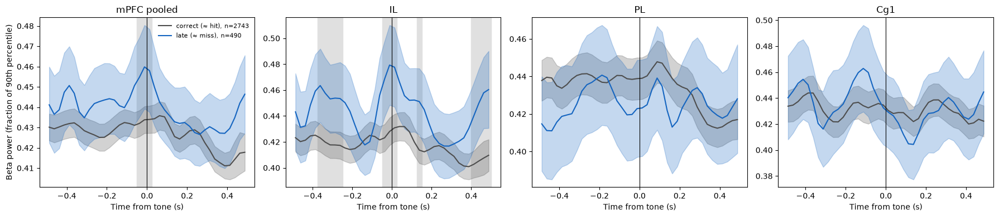

In [47]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import f as fdist, t as tdist
from statsmodels.stats.multicomp import pairwise_tukeyhsd

MAIN      = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
DATA_OUT  = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data"
BURST_DIR = os.path.join(DATA_OUT, "Bursts detection")
PW_DIR    = os.path.join(DATA_OUT, "Beta power p90 LOCAL")
FIG_DIR   = os.path.join(MAIN, "figures", "07_beta_power"); os.makedirs(FIG_DIR, exist_ok=True)
WIN, BIN  = (-0.5, 0.5), 0.025
GROUPS    = ["mPFC pooled", "IL", "PL", "Cg1"]
STYLE     = {"correct": ("correct (≈ hit)", "0.3"), "late": ("late (≈ miss)", "#1565c0")}

# 1. power per trial in 25-ms bins, correct and late long trials, all sessions
edges = np.round(np.arange(WIN[0], WIN[1] + 1e-9, BIN), 3); centers = edges[:-1] + BIN / 2
rows = []
for f in sorted(glob.glob(os.path.join(PW_DIR, "*.npz"))):
    if f.endswith(".tmp.npz"): continue
    s = os.path.basename(f)[:-4]
    z = np.load(f); tm = z["times"]
    T = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))
    regs = [g for g in ("IL", "PL", "Cg1") if f"{g}|tone" in z.files]
    M = {g: z[f"{g}|tone"] for g in regs}
    M["mPFC pooled"] = np.nanmean(np.stack([M[g] for g in regs]), axis=0)
    keep = np.where((T["type"] == "long") & T["label"].isin(["correct", "late"]))[0]
    for g, A in M.items():
        Bn = np.stack([np.nanmean(A[:, (tm >= a) & (tm < a + BIN)], axis=1) for a in edges[:-1]], axis=1)
        for k in keep:
            if np.isfinite(Bn[k]).all():
                rows.append((s, g, T.loc[k, "label"], *Bn[k]))
P = pd.DataFrame(rows, columns=["session", "group", "cond", *[f"b{j}" for j in range(len(centers))]])
bcols = [c for c in P.columns if c.startswith("b")]

# 2. two-way repeated-measures ANOVA: outcome (between trials) × time (within trials), trials as units
def rm_anova(Ys):
    Y = np.vstack(Ys); g = np.repeat(np.arange(len(Ys)), [len(y) for y in Ys]); N, Tn = Y.shape; GM = Y.mean()
    ng = np.bincount(g); mg = np.array([Y[g == k].mean() for k in range(len(Ys))])
    mgt = np.array([Y[g == k].mean(0) for k in range(len(Ys))]); mt, mi = Y.mean(0), Y.mean(1)
    ss_g = Tn * np.sum(ng * (mg - GM) ** 2); ss_s = Tn * np.sum((mi - mg[g]) ** 2); ss_t = N * np.sum((mt - GM) ** 2)
    ss_gt = np.sum(ng[:, None] * (mgt - mg[:, None] - mt[None, :] + GM) ** 2)
    ss_e = np.sum((Y - GM) ** 2) - ss_g - ss_s - ss_t - ss_gt; G = len(Ys); df_s, df_e = N - G, (N - G) * (Tn - 1)
    out = {}
    for name, ss_, d1, den, d2 in [("outcome", ss_g, G - 1, ss_s, df_s), ("time", ss_t, Tn - 1, ss_e, df_e),
                                   ("time × outcome", ss_gt, (G - 1) * (Tn - 1), ss_e, df_e)]:
        F = (ss_ / d1) / (den / d2); out[name] = (F, d1, d2, fdist.sf(F, d1, d2))
    return out

# 3. test + figure per region
res = []
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, g in zip(axes, GROUPS):
    G_ = P[P["group"] == g]
    Y = {c: G_.loc[G_.cond == c, bcols].values for c in ("correct", "late")}
    print(f"\n=== {g}: {len(Y['correct'])} correct, {len(Y['late'])} late trials ({G_.session.nunique()} sessions)")
    if min(len(Y["correct"]), len(Y["late"])) < 2:
        print("   not enough trials in one outcome, skipped"); continue
    for k, (F, d1, d2, p) in rm_anova([Y["correct"], Y["late"]]).items():
        print(f"   {k:15s} F({d1},{d2}) = {F:.2f}, p = {p:.3g}")
        res.append(dict(group=g, term=k, F=F, df1=d1, df2=d2, p=p))
    p_bin = np.array([pairwise_tukeyhsd(np.r_[Y["correct"][:, j], Y["late"][:, j]],
                                        np.r_[["correct"] * len(Y["correct"]), ["late"] * len(Y["late"])]).pvalues[0]
                      for j in range(len(centers))])
    print("   bins with p < 0.01 (Tukey):", [f"{c:+.3f}" for c, p in zip(centers, p_bin) if p < 0.01] or "none")
    for c, p in zip(centers, p_bin):
        if p < 0.01: ax.axvspan(c - BIN / 2, c + BIN / 2, color="0.88", zorder=0)
    for c in ("correct", "late"):
        y = Y[c]; mu = y.mean(0); ci = tdist.ppf(0.975, len(y) - 1) * y.std(0, ddof=1) / np.sqrt(len(y))
        lab, col = STYLE[c]
        ax.plot(centers, mu, color=col, label=f"{lab}, n={len(y)}"); ax.fill_between(centers, mu - ci, mu + ci, color=col, alpha=0.25)
    ax.axvline(0, color="k", lw=0.8); ax.set_title(g); ax.set_xlabel("Time from tone (s)")
axes[0].set_ylabel("Beta power (fraction of 90th percentile)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "beta_power_correct_vs_late_KarvatFig2D.png"), dpi=300); plt.show()
KARVAT_2D = pd.DataFrame(res)

In [48]:
pre = [f"b{j}" for j, c in enumerate(centers) if c < 0]
for g in GROUPS:
    G_ = P[P.group == g]
    print(g, G_.groupby("cond")[pre].mean().mean(axis=1).round(3).to_dict())

mPFC pooled {'correct': 0.4300000071525574, 'late': 0.4440000057220459}
IL {'correct': 0.42100000381469727, 'late': 0.44600000977516174}
PL {'correct': 0.4390000104904175, 'late': 0.42500001192092896}
Cg1 {'correct': 0.4339999854564667, 'late': 0.44200000166893005}


<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 0. How do mPFC beta bursts behave across the session?

All beta bursts (15–30 Hz, LOCAL, exact burst times) over the whole task period of each session, from the first press to the last release,
<b>without any trial categories</b>. Each session is divided into 20 equal parts (0 = start, 1 = end); artifact time is removed
(parts with > 50 % artifact left out).<br>
Rows: <b>mPFC pooled</b> (mean of IL, PL and Cg1, using the regions each session has), then <b>IL</b>, <b>PL</b>, <b>Cg1</b>.
Left: burst occupancy (% of time in a beta burst); right: burst rate (bursts per second). Black = mean over sessions ± SEM, pink = rats.<br>
Test: for each session, Spearman correlation between position in the session and the beta measure; sign test across sessions
(do more sessions go down than expected by chance?). Black text = p < 0.05, grey = n.s. Raw p.<br>
Saved in <i>Beta bursts / How beta behaves in general</i>.
<div>

sessions per region: {'Cg1': 48, 'IL': 60, 'PL': 57, 'pooled': 60} | session length: median 34 min

region   measure sessions_decreasing  median_rho  sign_test_p rat 134 rat 135 rat 136
pooled occupancy            42 of 60      -0.459        0.003    9/11   21/29   12/20
pooled      rate            42 of 60      -0.511        0.003    9/11   21/29   12/20
    IL occupancy            46 of 60      -0.419        0.000    9/11   25/29   12/20
    IL      rate            47 of 60      -0.414        0.000    9/11   26/29   12/20
    PL occupancy            42 of 57      -0.441        0.000    9/11   21/26   12/20
    PL      rate            44 of 56      -0.415        0.000    9/11   23/26   12/20
   Cg1 occupancy            28 of 48      -0.161        0.312    7/10   15/26    6/12
   Cg1      rate            30 of 48      -0.285        0.111    8/10   16/26    6/12


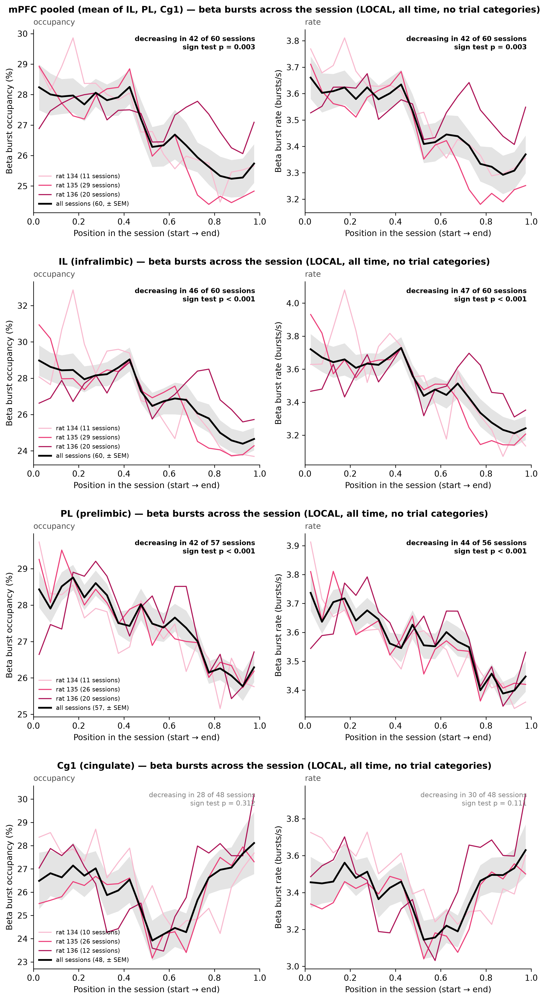

saved in: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\beta bursts\How beta behaves in general


In [111]:
# ── STEP 0. mPFC BETA BURSTS ACROSS THE SESSION — POOLED, IL, PL, Cg1: OCCUPANCY AND RATE, ALL TIME, NO TRIAL CATEGORIES (exact times, LOCAL) (needs Settings, RAT) ──
import glob
from scipy.stats import spearmanr, binomtest
from IPython.display import Image, display
GEN_DIR = os.path.join(BETA_DIR, "How beta behaves in general"); os.makedirs(GEN_DIR, exist_ok=True)
REGS, NB = ["IL", "PL", "Cg1"], 20
ROWS = [("pooled", "mPFC pooled (mean of IL, PL, Cg1)"), ("IL", "IL (infralimbic)"), ("PL", "PL (prelimbic)"), ("Cg1", "Cg1 (cingulate)")]
RCOL = {"134": "#F8BBD0", "135": "#EC407A", "136": "#AD1457"}
ptxt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
def overlap(s_, e_, a, b): return np.clip(np.minimum(e_, b) - np.maximum(s_, a), 0, None).sum()

# ── 1. occupancy and rate in 20 parts of each session, per region ──
rows = []
for f in sorted(glob.glob(os.path.join(EXACT_DIR, "*.npz"))):
    s = os.path.basename(f)[:-4]; z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
    t0, t1 = np.nanmin(T["press_s"]), np.nanmax(T["release_s"]); edges = np.linspace(t0, t1, NB + 1)
    for g in REGS:
        k_ = f"LOCAL|beta 15-30|{g}"
        if k_ + "|burst_start_s" not in z.files: continue
        bs, be, pk = z[k_ + "|burst_start_s"], z[k_ + "|burst_end_s"], z[k_ + "|peak_s"]
        ast, aen = z[f"LOCAL|{g}|art_start_s"], z[f"LOCAL|{g}|art_end_s"]
        for k in range(NB):
            a, b = edges[k], edges[k + 1]; clean = (b - a) - overlap(ast, aen, a, b)
            if clean < 0.5 * (b - a): continue
            rows.append(dict(session=s, rat=str(RAT[s]), region=g, part=k, pos=(k + 0.5) / NB, minutes=(t1 - t0) / 60,
                             occ=100 * overlap(bs, be, a, b) / clean, rate=((pk >= a) & (pk < b)).sum() / clean))
DR = pd.DataFrame(rows)
DP = DR.groupby(["session", "rat", "part", "pos"])[["occ", "rate"]].mean().reset_index().assign(region="pooled")
DALL = pd.concat([DP, DR], ignore_index=True)
print("sessions per region:", DALL.groupby("region").session.nunique().to_dict(),
      f"| session length: median {DR.groupby('session').minutes.first().median():.0f} min")

# ── 2. test: per-session trend, sign test across sessions ──
RES, out = {}, []
for reg, _ in ROWS:
    d0 = DALL[DALL.region == reg]
    for col, name in (("occ", "occupancy"), ("rate", "rate")):
        rho = d0.groupby(["session", "rat"]).apply(lambda d: spearmanr(d.pos, d[col])[0] if len(d) >= 5 else np.nan).dropna()
        down, nn = int((rho < 0).sum()), int((rho != 0).sum()); p = binomtest(down, nn).pvalue
        per_rat = {r: f"{(v < 0).sum()}/{len(v)}" for r, v in rho.groupby(level="rat")}
        RES[(reg, col)] = dict(down=down, n=nn, p=p, per_rat=per_rat)
        out.append(dict(region=reg, measure=name, sessions_decreasing=f"{down} of {nn}", median_rho=rho.median(), sign_test_p=p,
                        **{f"rat {r}": v for r, v in per_rat.items()}))
OUT = pd.DataFrame(out); print(); print(OUT.round(3).to_string(index=False))
OUT.to_csv(os.path.join(GEN_DIR, "step0_beta_across_session_tests.csv"), index=False)
DALL.to_csv(os.path.join(GEN_DIR, "step0_beta_across_session_data.csv"), index=False)

# ── 3. figure: one row per region (pooled first), each row its own title ──
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig = plt.figure(figsize=(11, 17), facecolor="white")
SUB = fig.subfigures(len(ROWS), 1, hspace=0.06)
for sf, (reg, title) in zip(SUB, ROWS):
    sf.set_facecolor("white")
    d0 = DALL[DALL.region == reg]
    axs = sf.subplots(1, 2)
    for ax, (col, ylab, letter) in zip(axs, (("occ", "Beta burst occupancy (%)", "occupancy"), ("rate", "Beta burst rate (bursts/s)", "rate"))):
        for r, d in d0.groupby("rat"):
            m = d.groupby("part")[col].mean()
            ax.plot((m.index + 0.5) / NB, m.values, color=RCOL[r], lw=1.3, label=f"rat {r} ({d.session.nunique()} sessions)")
        g = d0.groupby(["session", "part"])[col].mean().groupby("part").agg(["mean", "sem"]); x = (g.index + 0.5) / NB
        ax.fill_between(x, g["mean"] - g["sem"], g["mean"] + g["sem"], color="0.3", alpha=0.15, lw=0)
        ax.plot(x, g["mean"], color="k", lw=2.2, label=f"all sessions ({d0.session.nunique()}, ± SEM)")
        r_ = RES[(reg, col)]; sig = r_["p"] < 0.05
        ax.text(0.98, 0.97, f"decreasing in {r_['down']} of {r_['n']} sessions\nsign test {ptxt(r_['p'])}", transform=ax.transAxes,
                ha="right", va="top", fontsize=8.5, color="k" if sig else "0.5", fontweight="bold" if sig else "normal")
        ax.set_xlim(0, 1); ax.set_xlabel("Position in the session (start → end)"); ax.set_ylabel(ylab)
        ax.set_title(letter, loc="left", fontsize=9.5, color="0.3")
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    axs[0].legend(frameon=False, fontsize=7.5, loc="lower left")
    sf.suptitle(f"{title} — beta bursts across the session (LOCAL, all time, no trial categories)", fontsize=11, fontweight="bold")
fp = os.path.join(GEN_DIR, "step0_beta_across_session_regions.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("saved in:", GEN_DIR)

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">
<b>Step 0: late − correct beta burst occupancy per region, simple test (session means)</b><br>
Per session: mean occupancy in the 0.6 s before the tone of late minus correct long trials, sessions with ≥ 5 late and ≥ 3 correct trials.
Session values tested against zero with a sign-flip test (10,000 permutations). Bars: mean ± 95 % CI over sessions; dots: sessions.
</div>

Simple test: late − correct beta occupancy (%-points), session means (≥5 late, ≥3 correct), LOCAL, long trials
     region  sessions  sessions_up  occ_correct  occ_late  late_minus_correct  ci_low  ci_high     p  sig
         IL        33           20    25.625999 28.679001               3.053   0.738    5.369 0.012    *
         PL        32           14    27.398001 25.525000              -1.872  -4.238    0.494 0.115 n.s.
        Cg1        28           15    27.181000 28.381001               1.200  -1.327    3.727 0.345 n.s.
mPFC pooled        33           19    26.481001 27.677999               1.197  -0.418    2.812 0.144 n.s.


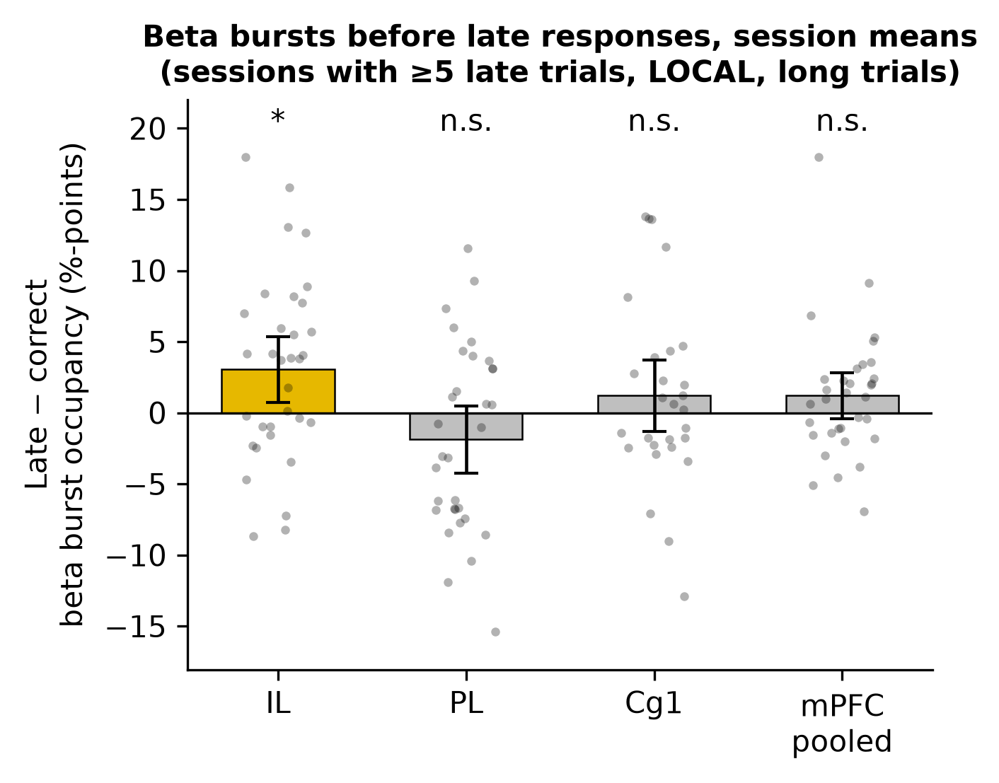

In [46]:
# ── STEP 0. late − correct beta burst occupancy per region, SIMPLE TEST (session means, ≥5 late trials) (needs Settings, 6a) ──
globals().pop("C", None)
from scipy.stats import t as tdist
from IPython.display import Image, display
BAND = "beta 15-30"; YEL = "#E6B800"
REGS = ["IL", "PL", "Cg1", "mPFC pooled"]
MIN_LATE, MIN_CORR = 5, 3
stars = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."

D0 = TABS[BAND]["late"]
D0 = D0[(D0.ref == "LOCAL") & (D0.typ == "long") & D0.cond.isin(["correct", "late"])].dropna(subset=["occ"]).copy()
D0["late"] = (D0.cond == "late").astype(int); D0["occ_pct"] = 100 * D0.occ

rows, dots = [], {}
for g in REGS:
    d = D0[D0.group == g]
    if d.empty: continue
    s = d.groupby(["session", "late"])["occ_pct"].agg(["mean", "size"]).unstack("late")
    ok = (s[("size", 1)] >= MIN_LATE) & (s[("size", 0)] >= MIN_CORR)
    v = (s.loc[ok, ("mean", 1)] - s.loc[ok, ("mean", 0)]).values
    m, p, n = fn.sign_flip_p(v)
    half = tdist.ppf(0.975, n - 1) * v.std(ddof=1) / np.sqrt(n)
    dots[g] = v
    rows.append(dict(region=g, sessions=n, sessions_up=int((v > 0).sum()),
                     occ_correct=s.loc[ok, ("mean", 0)].mean(), occ_late=s.loc[ok, ("mean", 1)].mean(),
                     late_minus_correct=m, ci_low=m - half, ci_high=m + half, p=p, sig=stars(p)))
R0 = pd.DataFrame(rows)
print(f"Simple test: late − correct beta occupancy (%-points), session means (≥{MIN_LATE} late, ≥{MIN_CORR} correct), LOCAL, long trials")
print(R0.round(3).to_string(index=False))
R0.to_csv(os.path.join(BETA_DIR, "step0_simple_late_vs_correct_regions.csv"), index=False)

# ── figure (same style as Step 1) ──
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig, ax = plt.subplots(figsize=(4.6, 3.8), facecolor="white")
rng = np.random.default_rng(0)
for k, r in R0.iterrows():
    ax.bar(k, r.late_minus_correct, width=0.6, color=YEL if r.p < 0.05 else "0.75", edgecolor="k", lw=0.6, zorder=1)
    v = dots[r.region]
    ax.scatter(k + rng.uniform(-0.18, 0.18, len(v)), v, s=9, color="k", alpha=0.3, lw=0, zorder=2)
    ax.errorbar(k, r.late_minus_correct, yerr=[[r.late_minus_correct - r.ci_low], [r.ci_high - r.late_minus_correct]],
                color="k", capsize=4, lw=1.1, zorder=3)
ax.axhline(0, color="k", lw=0.8)
lo = min(min(v.min() for v in dots.values()), R0.ci_low.min()); hi = max(max(v.max() for v in dots.values()), R0.ci_high.max())
ax.set_ylim(lo - 0.08 * (hi - lo), hi + 0.12 * (hi - lo))
for k, r in R0.iterrows():
    ax.text(k, hi + 0.04 * (hi - lo), r.sig, ha="center", va="bottom", fontsize=10)
ax.set_xticks(range(len(R0))); ax.set_xticklabels([g.replace("mPFC pooled", "mPFC\npooled") for g in R0.region])
ax.set_ylabel("Late − correct\nbeta burst occupancy (%-points)")
ax.set_title(f"Beta bursts before late responses, session means\n(sessions with ≥{MIN_LATE} late trials, LOCAL, long trials)", fontsize=10, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fp = os.path.join(BETA_DIR, "step0_simple_late_vs_correct_regions.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig)
display(Image(fp))

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 1. Which region shows more beta bursts before late responses?

Beta bursts (15–30 Hz, Karvat/Golan method), LOCAL reference, one representative channel per region (IL, PL, Cg1) and the mean of the three (mPFC pooled).<br>
Long trials, correct vs late, all blocks, 60 sessions. Value per trial: burst occupancy (% of time in a burst) in the 0.6 s before the tone.<br>
Model per region: occupancy ~ late + position in session + block + (1 | session); the bar is late − correct (%-points) with 95 % CI,
yellow if p < 0.05 (raw p, no FDR).
<div>

all blocks: late − correct beta occupancy (%-points), LOCAL, long trials
     region  sessions  n_correct  n_late  occ_correct  occ_late  late_minus_correct  ci_low  ci_high     p  sig
         IL        60       2743     490    25.688999 28.084999               2.722   0.837    4.607 0.005   **
         PL        57       2681     454    28.079000 25.996000              -1.656  -3.595    0.283 0.094 n.s.
        Cg1        48       2381     417    27.160000 27.830999               1.136  -0.966    3.238 0.289 n.s.
mPFC pooled        60       2743     490    26.840000 27.712999               1.380   0.196    2.565 0.022    *


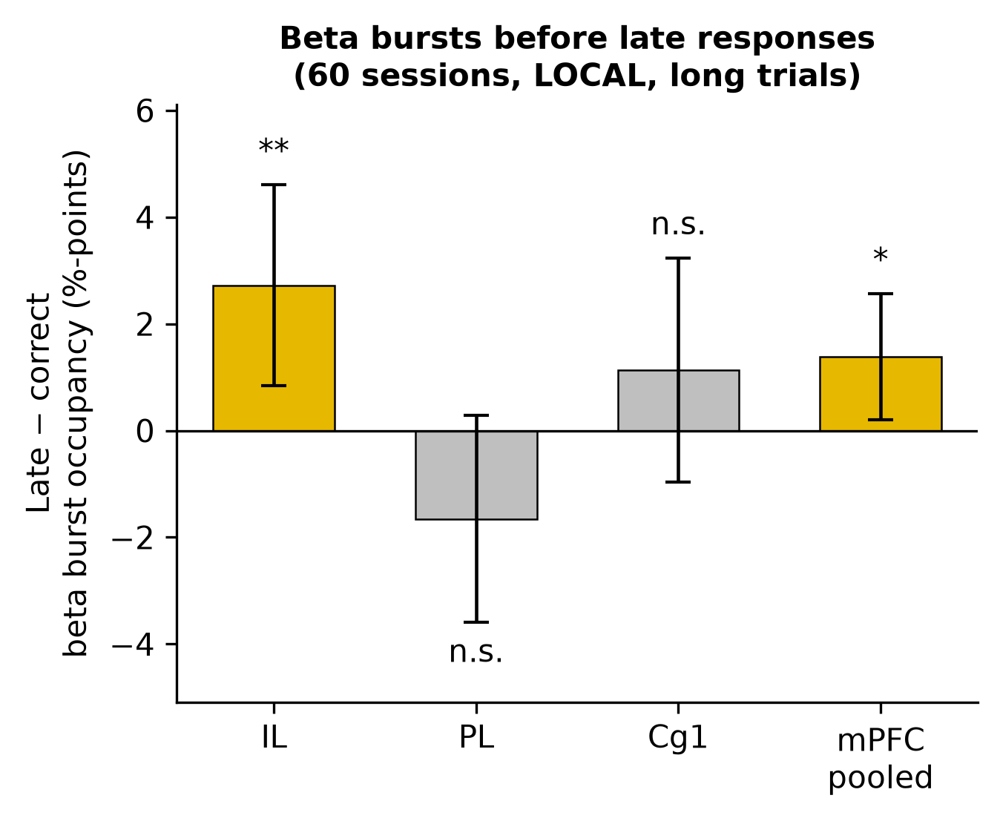

In [26]:
# ── STEP 1. late − correct beta burst occupancy per region (LOCAL, long trials, all blocks) (needs Settings, 6a) ──
globals().pop("C", None)
import warnings
import statsmodels.formula.api as smf
from IPython.display import Image, display
OLD_BLOCKS = False          # True = only 0.5 and >= 0.75 blocks (check: must give the old Step 1 numbers)
BAND = "beta 15-30"; YEL = "#E6B800"
REGS = ["IL", "PL", "Cg1", "mPFC pooled"]
stars = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."

PT = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), low_memory=False).sort_values(["session", "trial_index"])
PT["position"] = PT.groupby("session")["trial_index"].rank(pct=True)
TP = pd.concat([pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))[["trial_index", "long_prob"]]
                .assign(session=s, trial=lambda x: x.index) for s in files], ignore_index=True)
TP = TP.merge(PT[["session", "trial_index", "position"]], on=["session", "trial_index"], how="left")

D = TABS[BAND]["late"].merge(TP, on=["session", "trial"], how="left")
D = D[(D.ref == "LOCAL") & (D.typ == "long") & D.cond.isin(["correct", "late"])].dropna(subset=["occ", "position"]).copy()
if OLD_BLOCKS:
    D = D[(D.long_prob == 0.5) | (D.long_prob >= 0.75)].copy()
    D["block"] = np.where(D.long_prob == 0.5, "b05", "b75")
else:
    D["block"] = D.long_prob.round(2).astype(str)
D["late"] = (D.cond == "late").astype(int); D["occ_pct"] = 100 * D.occ

rows = []
for g in REGS:
    d = D[D.group == g]
    if d.empty: continue
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm("occ_pct ~ late + position + C(block)", d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"])
    e, se, p = m.params["late"], m.bse["late"], m.pvalues["late"]
    rows.append(dict(region=g, sessions=d.session.nunique(), n_correct=int((d.late == 0).sum()), n_late=int(d.late.sum()),
                     occ_correct=d.loc[d.late == 0, "occ_pct"].mean(), occ_late=d.loc[d.late == 1, "occ_pct"].mean(),
                     late_minus_correct=e, ci_low=e - 1.96 * se, ci_high=e + 1.96 * se, p=p, sig=stars(p)))
R1 = pd.DataFrame(rows)
print(f"{'0.5 and ≥0.75 blocks (old check)' if OLD_BLOCKS else 'all blocks'}: late − correct beta occupancy (%-points), LOCAL, long trials")
print(R1.round(3).to_string(index=False))
tag = "_old_blocks" if OLD_BLOCKS else ""
R1.to_csv(os.path.join(BETA_DIR, f"step1_late_vs_correct_regions{tag}.csv"), index=False)

# ── figure ──
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig, ax = plt.subplots(figsize=(4.6, 3.8), facecolor="white")
for k, r in R1.iterrows():
    ax.bar(k, r.late_minus_correct, width=0.6, color=YEL if r.p < 0.05 else "0.75", edgecolor="k", lw=0.6)
    ax.errorbar(k, r.late_minus_correct, yerr=[[r.late_minus_correct - r.ci_low], [r.ci_high - r.late_minus_correct]], color="k", capsize=4, lw=1.1)
    up = r.late_minus_correct >= 0
    ax.text(k, r.ci_high + 0.3 if up else r.ci_low - 0.3, r.sig, ha="center", va="bottom" if up else "top", fontsize=10)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylim(R1.ci_low.min() - 1.5, R1.ci_high.max() + 1.5)       # room for the stars/n.s. above and below the bars
ax.set_xticks(range(len(R1))); ax.set_xticklabels([g.replace("mPFC pooled", "mPFC\npooled") for g in R1.region])
ax.set_ylabel("Late − correct\nbeta burst occupancy (%-points)")
ax.set_title(f"Beta bursts before late responses\n({D.session.nunique()} sessions, LOCAL, long trials)", fontsize=10, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fp = os.path.join(BETA_DIR, f"step1_late_vs_correct_regions{tag}.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig)
display(Image(fp))

In [27]:
# ── STEP 1-check. Simple session test vs mixed model (no block), pooled and each region, LOCAL, 0.6 s before the tone ──
import warnings
import statsmodels.formula.api as smf
rows = []
for g in ["mPFC pooled", "IL", "PL", "Cg1"]:
    d = D[D.group == g].dropna(subset=["occ_pct", "position"])
    # mixed model WITHOUT block: occupancy ~ late + position + (1 | session)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm("occ_pct ~ late + position", d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"])
    rows.append(dict(region=g, test="mixed model (all trials)", sessions=d.session.nunique(), late_trials=int(d.late.sum()),
                     late_minus_correct=m.params["late"], p=m.pvalues["late"], sig=stars(m.pvalues["late"])))
    # simple test: per session mean(late) − mean(correct), sign-flip across sessions, for different minimum numbers of late trials
    S = d.groupby(["session", "late"])["occ_pct"].agg(["mean", "size"]).unstack("late")
    for min_late in (1, 3, 5):
        ok = (S[("size", 1)] >= min_late) & (S[("size", 0)] >= 3)
        diff = (S[("mean", 1)] - S[("mean", 0)])[ok].dropna()
        mm, p, n = fn.sign_flip_p(diff.values)
        rows.append(dict(region=g, test=f"session means, ≥{min_late} late", sessions=n,
                         late_trials=int(S[("size", 1)][ok].sum()), late_minus_correct=mm, p=p, sig=stars(p),
                         sessions_up=f"{int((diff > 0).sum())}/{n}"))
CHK = pd.DataFrame(rows)
print("late − correct beta occupancy (%-points), LOCAL, long trials, 0.6 s before the tone (no block term)")
print(CHK.round(3).to_string(index=False))
CHK.to_csv(os.path.join(BETA_DIR, "step1_check_simple_vs_mixed.csv"), index=False)


late − correct beta occupancy (%-points), LOCAL, long trials, 0.6 s before the tone (no block term)
     region                     test  sessions  late_trials  late_minus_correct     p  sig sessions_up
mPFC pooled mixed model (all trials)        60          490               1.336 0.027    *         NaN
mPFC pooled   session means, ≥1 late        51          490               0.105 0.925 n.s.       28/51
mPFC pooled   session means, ≥3 late        42          475               1.469 0.086 n.s.       25/42
mPFC pooled   session means, ≥5 late        33          445               1.197 0.144 n.s.       19/33
         IL mixed model (all trials)        60          490               2.700 0.005   **         NaN
         IL   session means, ≥1 late        51          490               1.918 0.134 n.s.       29/51
         IL   session means, ≥3 late        42          475               2.706 0.030    *       25/42
         IL   session means, ≥5 late        33          445               3.

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 1b. Beta before late responses: IL vs PL directly (check, not for the report)
Same trials and window as Step 1 (LOCAL, long correct + late, 0.6 s before the tone).
Per trial: IL occupancy − PL occupancy (same trial, both regions). Mixed model diff ~ late + position + C(block), random intercept per session
(same model as Step 1) -> the late coefficient = (late − correct in IL) − (late − correct in PL).
Check: per session (late − correct)_IL − (late − correct)_PL, sign-flip across sessions (fn.sign_flip_p).
Saved: Beta bursts\step1b_IL_vs_PL.csv

<div>

In [8]:
# ── STEP 1b. BETA BEFORE LATE: IL vs PL DIRECTLY (needs Step 1: D, BAND, stars) ──
import warnings
import statsmodels.formula.api as smf

# 1) one row per trial with IL and PL occupancy side by side (only trials with both regions)
W = (D[D.group.isin(["IL", "PL"])]
     .pivot_table(index=["session", "trial", "late", "position", "block"], columns="group", values="occ_pct")
     .dropna(subset=["IL", "PL"]).reset_index())
W["diff"] = W["IL"] - W["PL"]

# 2) mixed model on the IL − PL difference (same model as Step 1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m = smf.mixedlm("diff ~ late + position + C(block)", W, groups=W["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"])
e, se, p = m.params["late"], m.bse["late"], m.pvalues["late"]

# 3) check: per session (late − correct) in IL minus the same in PL, sign-flip across sessions
S = W.groupby(["session", "late"])[["IL", "PL"]].mean().unstack("late").dropna()
d_ses = (S[("IL", 1)] - S[("IL", 0)]) - (S[("PL", 1)] - S[("PL", 0)])
m_s, p_s, n_s = fn.sign_flip_p(d_ses.values)

out = pd.DataFrame([
    dict(test="mixed model (trials)", sessions=W.session.nunique(), n_correct=int((W.late == 0).sum()), n_late=int(W.late.sum()),
         IL_late_minus_correct=W.loc[W.late == 1, "IL"].mean() - W.loc[W.late == 0, "IL"].mean(),
         PL_late_minus_correct=W.loc[W.late == 1, "PL"].mean() - W.loc[W.late == 0, "PL"].mean(),
         IL_minus_PL=e, ci_low=e - 1.96 * se, ci_high=e + 1.96 * se, p=p, sig=stars(p)),
    dict(test="sign-flip (sessions)", sessions=n_s, IL_minus_PL=m_s, up=int((d_ses > 0).sum()), p=p_s, sig=stars(p_s))])
print(f"{BAND}, LOCAL, long trials, 0.6 s before the tone: (late − correct in IL) − (late − correct in PL), %-points")
print(out.round(3).to_string(index=False))
print("\nper rat (sign-flip values, mean %-points):",
      d_ses.groupby([RAT[s] for s in d_ses.index]).agg(["mean", "count"]).round(2).to_dict("index"))
out.to_csv(os.path.join(BETA_DIR, "step1b_IL_vs_PL.csv"), index=False)
print(R1[R1.region == "PL"].round(3).to_string(index=False))

beta 15-30, LOCAL, long trials, 0.6 s before the tone: (late − correct in IL) − (late − correct in PL), %-points
                test  sessions  n_correct  n_late  IL_late_minus_correct  PL_late_minus_correct  IL_minus_PL  ci_low  ci_high     p sig   up
mixed model (trials)        57     2681.0   454.0                  1.695                 -2.083        3.540    0.79     6.29 0.012   *  NaN
sign-flip (sessions)        49        NaN     NaN                    NaN                    NaN        3.576     NaN      NaN 0.036   * 31.0

per rat (sign-flip values, mean %-points): {'134': {'mean': 0.5, 'count': 11}, '135': {'mean': 7.130000114440918, 'count': 18}, '136': {'mean': 2.059999942779541, 'count': 20}}
region  sessions  n_correct  n_late  occ_correct  occ_late  late_minus_correct  ci_low  ci_high     p  sig
    PL        57       2681     454       28.079    25.996              -1.656  -3.595    0.283 0.094 n.s.


<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 2. What a beta burst looks like (example in the 600 ms before the tone)
Test session, IL, LOCAL. Among long correct/late trials (blocks 0.5 and ≥ 0.75, no artifacts), the clearest detected beta burst
(15–30 Hz, 50–300 ms) lying fully inside the 600 ms before the tone (largest beta amplitude vs the rest of the window; chosen for illustration).
Rows: raw LFP · beta-filtered signal with its amplitude (envelope) · time–frequency power (Morlet, 7 cycles) / session 90th percentile, 15–40 Hz.
Red = the detected burst (Karvat et al. 2021 method); white outline = above the 90th percentile inside the burst and 15–30 Hz.
Saved in amir_data\Beta bursts: step2_example_beta_burst.png.

<div>

20260529_r0000136_wt_1318 | IL LOCAL channel imec0.ap#AP174 | candidate bursts fully inside the 600 ms: 37 (median 102 ms)
shown: trial 0 (correct), burst -0.554 to -0.348 s from the tone, 206 ms, peak amplitude 3.4x the rest of the window


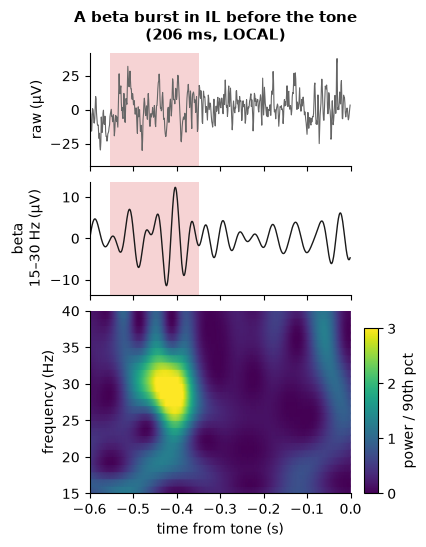

In [23]:
# %%
# ── STEP 2. WHAT A BETA BURST LOOKS LIKE: the clearest burst inside the 600 ms before a tone (illustration) ──
from scipy.signal import butter, sosfiltfilt, hilbert, fftconvolve
S_EX, REF_EX, REG_EX, BAND_EX, WIN_EX = TEST, "LOCAL", "IL", "beta 15-30", 0.6
ze3 = np.load(os.path.join(EXACT_DIR, S_EX + ".npz")); T3 = pd.read_csv(os.path.join(EXACT_DIR, S_EX + "_trials.csv"))
k3 = f"{REF_EX}|{BAND_EX}|{REG_EX}"
bs3, be3 = ze3[k3 + "|burst_start_s"], ze3[k3 + "|burst_end_s"]
ast3, aen3 = ze3[f"{REF_EX}|{REG_EX}|art_start_s"], ze3[f"{REF_EX}|{REG_EX}|art_end_s"]
ch3 = str(ze3[f"{REF_EX}|{REG_EX}|channel"][0])

# whole session, this channel
rec3 = fn.load_session(PROC, S_EX, XB, refs=(REF_EX,))[0][REF_EX]; fs3 = rec3.get_sampling_frequency()
x3 = rec3.get_traces(channel_ids=[ch3], return_in_uV=True)[:, 0].astype(float)
t3 = np.arange(len(x3)) / fs3
beta3 = sosfiltfilt(butter(4, [15, 30], btype="band", fs=fs3, output="sos"), x3)
env3 = np.abs(hilbert(beta3))                                     # only used to choose the clearest burst

# candidate bursts: fully inside the 600 ms before the tone of a long correct/late trial without artifacts
tr = T3[(T3["type"] == "long") & T3["label"].isin(["correct", "late"]) & T3["tone_s"].notna() &
        ((T3["long_prob"] == 0.5) | (T3["long_prob"] >= 0.75))]
rows = []
for idx, r in tr.iterrows():
    tone = r["tone_s"]; a = tone - WIN_EX
    if np.any((ast3 < tone) & (aen3 > a)):
        continue
    i_a, i_t = int(a * fs3), int(tone * fs3)
    for s_, e_ in zip(bs3, be3):
        if s_ >= a and e_ <= tone and 0.05 <= e_ - s_ <= 0.30:
            inside = env3[int(s_ * fs3): int(e_ * fs3)].max()
            rest = np.median(np.r_[env3[i_a: int(s_ * fs3)], env3[int(e_ * fs3): i_t]]) if (s_ > a or e_ < tone) else np.nan
            rows.append(dict(trial=idx, label=r["label"], tone=tone, start=s_, end=e_, dur_ms=1000 * (e_ - s_), score=inside / rest))
CAND = pd.DataFrame(rows).dropna(subset=["score"]).sort_values("score", ascending=False)
best = CAND.iloc[0]; tone = best["tone"]
print(f"{S_EX} | {REG_EX} {REF_EX} channel {ch3} | candidate bursts fully inside the 600 ms: {len(CAND)} "
      f"(median {CAND['dur_ms'].median():.0f} ms)")
print(f"shown: trial {best['trial']} ({best['label']}), burst {best['start'] - tone:+.3f} to {best['end'] - tone:+.3f} s from the tone, "
      f"{best['dur_ms']:.0f} ms, peak amplitude {best['score']:.1f}x the rest of the window")

# time–frequency power 15–40 Hz (Morlet, 7 cycles), / 90th percentile per frequency over the whole session (artifacts excluded)
freqs = np.arange(15, 41, 1.0)
clean = np.ones(len(x3), bool)
for a_, e_ in zip(ast3, aen3):
    clean[(t3 >= a_) & (t3 < e_)] = False
m = (t3 >= tone - WIN_EX) & (t3 <= tone); tt = t3[m] - tone
Pw = np.empty((len(freqs), m.sum()), np.float32)
for i, f in enumerate(freqs):
    sd = 7 / (2 * np.pi * f); tw = np.arange(-3.5 * sd, 3.5 * sd, 1 / fs3)
    w = np.exp(2j * np.pi * f * tw) * np.exp(-tw ** 2 / (2 * sd ** 2)); w /= np.abs(w).sum()
    pw = np.abs(fftconvolve(x3, w, mode="same")) ** 2
    Pw[i] = pw[m] / np.percentile(pw[clean], 90)

# figure
b0, b1 = best["start"] - tone, best["end"] - tone
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig, axs = plt.subplots(3, 1, figsize=(4.5, 5.5), sharex=True, facecolor="white", gridspec_kw=dict(height_ratios=[0.8, 0.8, 1.3]))
for ax in axs[:2]:
    ax.axvspan(b0, b1, color="#d62728", alpha=0.20, lw=0)
axs[0].plot(tt, x3[m], color="0.4", lw=0.8); axs[0].set_ylabel("raw (µV)")
axs[1].plot(tt, beta3[m], color="0.1", lw=1); axs[1].set_ylabel("beta\n15–30 Hz (µV)")
for ax, y in ((axs[0], x3[m]), (axs[1], beta3[m])):                # tight y-axis around the shown data
    lim = 1.1 * np.abs(y).max(); ax.set_ylim(-lim, lim); ax.locator_params(axis="y", nbins=3)
im = axs[2].pcolormesh(tt, freqs, Pw, cmap="viridis", vmin=0, vmax=3, shading="gouraud")
axs[2].set_ylabel("frequency (Hz)"); axs[2].set_xlabel("time from tone (s)"); axs[2].set_xlim(-WIN_EX, 0)
for ax in axs:
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.subplots_adjust(left=0.22, right=0.80, top=0.90, bottom=0.10, hspace=0.12)
cax = fig.add_axes([0.83, 0.10, 0.03, 0.30]); fig.colorbar(im, cax=cax, label="power / 90th pct")
fig.suptitle(f"A beta burst in IL before the tone\n({best['dur_ms']:.0f} ms, {REF_EX})", fontsize=10.5, fontweight="bold")
fig.savefig(os.path.join(BETA_DIR, "step2_example_beta_burst.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 3. The late − correct difference appears only at the start of the session

IL beta bursts, LOCAL, long trials (correct vs late), all blocks, 60 sessions.<br>
Value per trial: beta burst occupancy (% of time in a burst) in the 0.6 s before the tone; burst rate (bursts/s) is shown in the robustness section.<br>
<b>A</b> occupancy along the session (10 bins of trial position) for correct and late trials, with the straight-line model
occupancy ~ late × position + block + (1 | session).<br>
<b>B</b> late − correct per session phase (start 0–25 %, middle 25–85 %, end 85–100 % of trials), model
occupancy ~ late × phase + block + (1 | session); bars yellow if p < 0.05, dots = rats.<br>
Three ways to split the session (trial number, clock time, water drunk) check that the start effect does not depend on how "start" is defined.
<div>

In [35]:
rng = np.random.default_rng(1)

def equal_n(sub, matched, n_draw):
    sess = []
    for s, g in sub.groupby("session"):
        L, C = g[g.late == 1], g[g.late == 0]
        if len(L) and len(C):
            sess.append((L.occ_pct.values, L.position.values, C.occ_pct.values, C.position.values))
    diffs, n_used = [], 0
    for k in range(n_draw):
        lv_all, cv_all = [], []
        for Lv, Lp, Cv, Cp in sess:
            if matched:
                free = np.ones(len(Cv), bool)
                for i in rng.permutation(len(Lv)):
                    if not free.any(): break
                    dist = np.abs(Cp - Lp[i]) + rng.random(len(Cp)) * 1e-9   # random tie-break
                    dist[~free] = np.inf
                    j = np.argmin(dist); free[j] = False
                    lv_all.append(Lv[i]); cv_all.append(Cv[j])
            else:
                n = min(len(Lv), len(Cv))
                lv_all += list(rng.choice(Lv, n, replace=False))
                cv_all += list(rng.choice(Cv, n, replace=False))
        diffs.append(np.mean(lv_all) - np.mean(cv_all)); n_used = len(lv_all)
    diffs = np.array(diffs)
    return dict(n_pairs=n_used, sessions=len(sess), mean_diff=diffs.mean(),
                low_2_5=np.percentile(diffs, 2.5), high_97_5=np.percentile(diffs, 97.5),
                pct_draws_late_higher=100 * np.mean(diffs > 0))

rows = []
for g in ["IL", "mPFC pooled", "PL"]:
    G = P[P["group"] == g]
    for part in ["whole", "start", "middle", "end"]:
        sub = G if part == "whole" else G[G["part"] == part]
        rows.append(dict(group=g, part=part, method="random", **equal_n(sub, False, 1000)))
        rows.append(dict(group=g, part=part, method="matched", **equal_n(sub, True, 200)))

EQ = pd.DataFrame(rows)
print(EQ.round(2).to_string(index=False))

      group   part  method  n_pairs  sessions  mean_diff  low_2_5  high_97_5  pct_draws_late_higher
         IL  whole  random      490        51       3.03     1.72       4.34                  100.0
         IL  whole matched      490        51       2.16     1.77       2.61                  100.0
         IL  start  random      106        33       4.84     2.23       7.65                   99.9
         IL  start matched      106        33       4.70     3.33       6.10                  100.0
         IL middle  random      277        46       1.93     0.20       3.62                   98.0
         IL middle matched      277        46       1.11     0.57       1.64                  100.0
         IL    end  random       88        38      -1.00    -3.60       1.74                   23.0
         IL    end matched       88        38      -0.72    -1.48       0.05                    3.0
mPFC pooled  whole  random      490        51       1.62     0.76       2.49                  100.0


trials per block (IL beta, occupancy): {'0.02': 1, '0.1': 32, '0.2': 20, '0.25': 116, '0.5': 1059, '0.75': 1088, '0.8': 80, '0.9': 151, '1.0': 686}

===== OCCUPANCY beta 15-30, LOCAL: change start→end (%-points) and late − correct at start / end =====
      group  sessions  n_correct  n_late  correct_change  p_correct_change  late_change  p_late_change  late_x_position  p_interaction  late_minus_correct_start  p_start  late_minus_correct_end  p_end
         IL    60.000   2743.000 490.000          -1.257             0.356      -12.905          0.000          -11.648          0.000                     8.901    0.000                  -2.747  0.116
         PL    57.000   2681.000 454.000          -4.058             0.003       -8.298          0.005           -4.241          0.187                     0.622    0.755                  -3.619  0.043
        Cg1    48.000   2381.000 417.000          -5.376             0.001       -0.904          0.788            4.472          0.216           

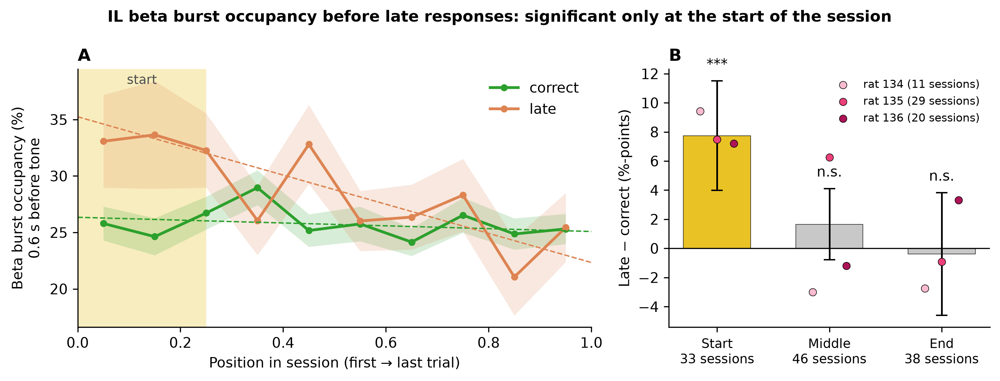

sessions per rat: {'134': 11, '135': 29, '136': 20} | sessions with correct and late per phase: {'start': 33, 'middle': 46, 'end': 38}


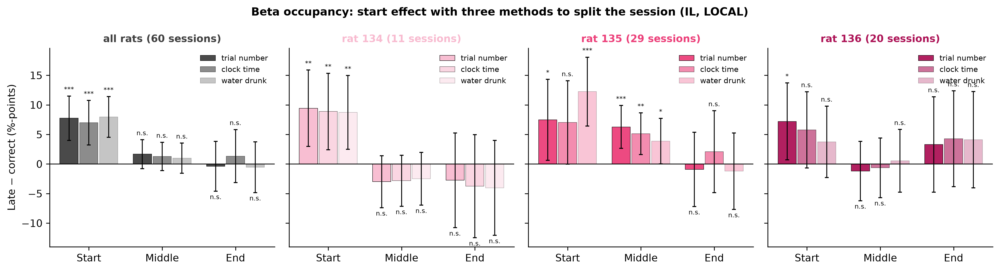


RATE: trials correct 2743, late 490 | sessions 60 | mean rate correct 3.41, late 3.52 bursts/s
RATE straight-line model (bursts/s):
sessions                     60.000
n_correct                  2743.000
n_late                      490.000
correct_change               -0.158
p_correct_change              0.423
late_change                  -1.412
p_late_change                 0.001
late_x_position              -1.255
p_interaction                 0.005
late_minus_correct_start      0.861
p_start                       0.002
late_minus_correct_end       -0.394
p_end                         0.119

RATE IL beta, late − correct (bursts/s) per phase, three methods to split the session:
rat   definition  phase  late_minus_correct  ci_low  ci_high     p  n_correct  n_late  sig
all trial number  start               0.911   0.368    1.454 0.001        605     119  ***
all trial number middle              -0.003  -0.356    0.350 0.987       1728     277 n.s.
all trial number    end              -

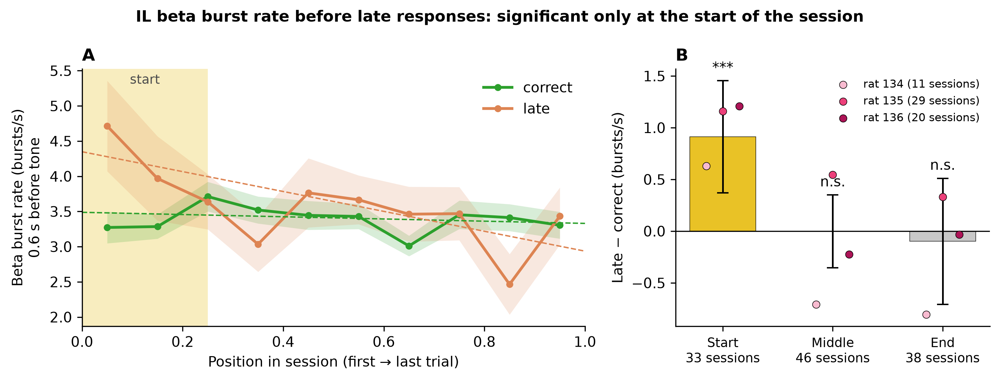

sessions per rat: {'134': 11, '135': 29, '136': 20} | sessions with correct and late per phase: {'start': 33, 'middle': 46, 'end': 38}


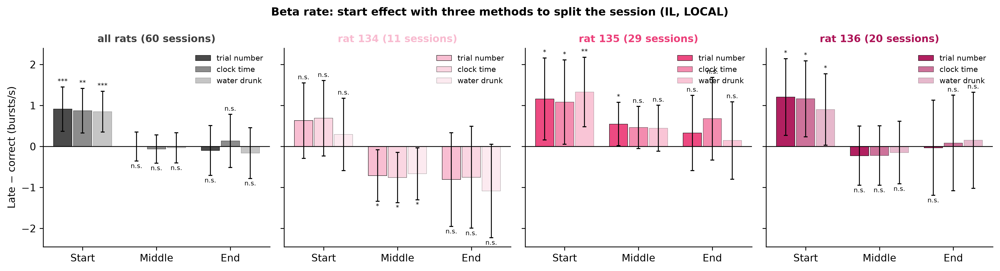

In [29]:
# %%
# ── STEP 3. LATE vs CORRECT ALONG THE SESSION (IL beta, LOCAL, all blocks): occupancy and rate; significant at start + three methods to split ──
globals().pop("C", None)
import warnings
import statsmodels.formula.api as smf
from scipy.stats import norm
from matplotlib.patches import Patch
from IPython.display import Image, display
COLC = {"correct": "#2CA02C", "late": "#DD8452"}
RCOL = {"134": "#F8BBD0", "135": "#EC407A", "136": "#AD1457"}; RCOL4 = {"all": "0.25", **RCOL}   # rats: light, medium, dark pink
YEL = "#E6B800"
PHS, CUTS, WIN3 = ["start", "middle", "end"], (0.25, 0.85), (-0.6, 0.0)
DEFS = {"trial number": "position", "clock time": "v_time", "water drunk": "v_water"}
ALPHA = {"trial number": 0.95, "clock time": 0.6, "water drunk": 0.3}
stars = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."

# ── trial positions: trial number, clock time, water drunk ──
PT = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), low_memory=False).sort_values(["session", "trial_index"])
PT["position"] = PT.groupby("session")["trial_index"].rank(pct=True)
t0_ = PT.groupby("session")["press_neural_s"].transform("min"); t1_ = PT.groupby("session")["press_neural_s"].transform("max")
PT["v_time"] = (PT["press_neural_s"] - t0_) / (t1_ - t0_)
vol = PT["reward_size"].fillna(0).clip(lower=0)
PT["v_water"] = (vol.groupby(PT["session"]).cumsum() - vol) / vol.groupby(PT["session"]).transform("sum")
POSCOLS = ["position", "v_time", "v_water"]

def finish(D):
    D = D.dropna(subset=POSCOLS).copy()
    D["late"] = (D["cond"] == "late").astype(int); D["block"] = D["long_prob"].round(2).astype(str); D["rat"] = D["rat"].astype(str)
    D["pbin"] = pd.cut(D["position"], np.linspace(0, 1, 11), labels=False, include_lowest=True)
    D["phase"] = pd.cut(D["position"], [-0.001, *CUTS, 1.001], labels=PHS).astype(str)
    return D

# ── occupancy table (from TABS, all regions and bands for the straight-line table) ──
TP = pd.concat([pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))[["trial_index", "long_prob"]]
                .assign(session=s, trial=lambda x: x.index) for s in files], ignore_index=True)
TP = TP.merge(PT[["session", "trial_index", *POSCOLS]], on=["session", "trial_index"], how="left")
def occ_table(band):
    D = TABS[band]["late"].merge(TP, on=["session", "trial"], how="left")
    D = D[(D["ref"] == "LOCAL") & (D["typ"] == "long") & D["cond"].isin(["correct", "late"])].dropna(subset=["occ"]).copy()
    D["occ_pct"] = 100 * D["occ"]
    return finish(D)

# ── rate table (IL beta LOCAL, from the 50-ms counts) ──
KEYC = "LOCAL|beta 15-30|IL|tone|cnt"; rr_ = []
for s in files:
    z = np.load(os.path.join(BURST_DIR, s + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))
    if KEYC not in z.files or z[KEYC].shape[0] != len(T):
        print("rate: skipped", s); continue
    tb_ = fn.BURST_A0["tone"] + fn.BURST_BIN * np.arange(z[KEYC].shape[1])
    sb = (tb_ >= WIN3[0] - 1e-9) & (tb_ + fn.BURST_BIN <= WIN3[1] + 1e-9)
    keep = ((T["type"] == "long") & T["label"].isin(["correct", "late"])).values
    C_ = z[KEYC][:, sb]
    for i in np.where(keep)[0]:
        if np.isfinite(C_[i]).all():
            rr_.append(dict(session=s, rat=RAT[s], trial_index=T["trial_index"].values[i], cond=T["label"].values[i],
                            long_prob=T["long_prob"].values[i], rate=C_[i].sum() / (WIN3[1] - WIN3[0])))
D_RATE = finish(pd.DataFrame(rr_).merge(PT[["session", "trial_index", *POSCOLS]], on=["session", "trial_index"], how="left"))

def fit(f, dd):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return smf.mixedlm(f, dd, groups=dd["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"])

def line_model(dd, y):
    m = fit(f"{y} ~ late * position + C(block)", dd); P, V = m.params, m.cov_params()
    comb = lambda k: (sum(P[x] for x in k), 2 * norm.sf(abs(sum(P[x] for x in k) / np.sqrt(sum(V.loc[a, b] for a in k for b in k)))))
    ls_, pls = comb(["position", "late:position"]); le_, ple = comb(["late", "late:position"])
    return pd.Series(dict(sessions=dd.session.nunique(), n_correct=int((dd.late == 0).sum()), n_late=int(dd.late.sum()),
                          correct_change=P["position"], p_correct_change=m.pvalues["position"], late_change=ls_, p_late_change=pls,
                          late_x_position=P["late:position"], p_interaction=m.pvalues["late:position"],
                          late_minus_correct_start=P["late"], p_start=m.pvalues["late"], late_minus_correct_end=le_, p_end=ple))

def phase_fit(dd, var, y):
    dd = dd.assign(phase=pd.cut(dd[var], [-0.001, *CUTS, 1.001], labels=PHS).astype(str))
    m = fit(f"{y} ~ late * C(phase, Treatment('start')) + C(block)", dd); P, V = m.params, m.cov_params(); out = {}
    for ph in PHS:
        k = ["late"] + ([f"late:C(phase, Treatment('start'))[T.{ph}]"] if ph != "start" else [])
        est = sum(P[x] for x in k); se = np.sqrt(sum(V.loc[a, b] for a in k for b in k))
        out[ph] = dict(est=est, se=se, p=2 * norm.sf(abs(est / se)),
                       n_late=int(((dd.phase == ph) & (dd.late == 1)).sum()), n_correct=int(((dd.phase == ph) & (dd.late == 0)).sum()))
    return out

def three_methods(dd, y):
    rows = []
    for rat, x in [("all", dd)] + list(dd.groupby("rat")):
        for dname, var in DEFS.items():
            for ph, rr in phase_fit(x, var, y).items():
                rows.append(dict(rat=rat, definition=dname, phase=ph, late_minus_correct=rr["est"], se=rr["se"],
                                 ci_low=rr["est"] - 1.96 * rr["se"], ci_high=rr["est"] + 1.96 * rr["se"], p=rr["p"],
                                 n_correct=rr["n_correct"], n_late=rr["n_late"]))
    CTm = pd.DataFrame(rows); CTm["sig"] = CTm["p"].apply(stars)
    return CTm

def fig_start(dd, y, r, CTm, ylab, unit, title, fname, off):
    NR = dd.groupby("rat")["session"].nunique()
    NP = {ph: int((dd[dd.phase == ph].groupby("session")["late"].nunique() == 2).sum()) for ph in PHS}
    TN = CTm[CTm.definition == "trial number"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]), facecolor="white")
    a1.axvspan(0, CUTS[0], color=YEL, alpha=0.25, lw=0, zorder=0)
    a1.text(CUTS[0] / 2, 0.98, "start", transform=a1.get_xaxis_transform(), ha="center", va="top", fontsize=9, color="0.3")
    for lab, col in COLC.items():
        x = dd[dd.cond == lab].groupby(["session", "pbin"])[y].mean().groupby("pbin").agg(["mean", "sem"])
        xc = (x.index + 0.5) / 10
        a1.fill_between(xc, x["mean"] - x["sem"], x["mean"] + x["sem"], color=col, alpha=0.18, lw=0)
        a1.plot(xc, x["mean"], "o-", color=col, lw=2, ms=4, label=lab)
    xx = np.linspace(0, 1, 50); base = dd[y][dd.late == 0].mean() - r.correct_change * dd["position"][dd.late == 0].mean()
    a1.plot(xx, base + r.correct_change * xx, "--", color=COLC["correct"], lw=1)
    a1.plot(xx, base + r.late_minus_correct_start + r.late_change * xx, "--", color=COLC["late"], lw=1)
    a1.set_xlim(0, 1); a1.set_xlabel("Position in session (first → last trial)"); a1.set_ylabel(f"{ylab}\n0.6 s before tone")
    a1.legend(frameon=False, loc="upper right"); a1.set_title("A", loc="left", fontweight="bold")
    for k, ph in enumerate(PHS):
        rr = TN[(TN.rat == "all") & (TN.phase == ph)].iloc[0]
        a2.bar(k, rr.late_minus_correct, color=YEL if rr.p < 0.05 else "0.75", width=0.6, alpha=0.85, edgecolor="k", lw=0.4)
        a2.errorbar(k, rr.late_minus_correct, yerr=1.96 * rr.se, color="k", capsize=4, lw=1.2)
        a2.text(k, rr.ci_high + off, rr.sig, ha="center", va="bottom", fontsize=10)
        for j, rat in enumerate(["134", "135", "136"]):
            rq = TN[(TN.rat == rat) & (TN.phase == ph)].iloc[0]
            a2.scatter(k + (j - 1) * 0.15, rq.late_minus_correct, color=RCOL[rat], s=28, zorder=3, edgecolor="k", lw=0.4,
                       label=f"rat {rat} ({NR.loc[rat]} sessions)" if k == 0 else None)
    a2.axhline(0, color="k", lw=0.8)
    a2.set_xticks(range(3)); a2.set_xticklabels([f"{ph.capitalize()}\n{NP[ph]} sessions" for ph in PHS], fontsize=9)
    a2.set_ylabel(f"Late − correct ({unit})")
    a2.legend(frameon=False, fontsize=8, loc="upper right"); a2.set_title("B", loc="left", fontweight="bold")
    for ax in (a1, a2):
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    fig.suptitle(title, fontsize=11, fontweight="bold"); fig.tight_layout()
    for folder in (FIGS, BETA_DIR): fig.savefig(os.path.join(folder, fname), dpi=300, facecolor="white", bbox_inches="tight")
    plt.close(fig); display(Image(os.path.join(FIGS, fname)))
    print("sessions per rat:", NR.to_dict(), "| sessions with correct and late per phase:", NP)

def fig_methods(dd, CTm, unit, title, fname, off):
    NR = dd.groupby("rat")["session"].nunique()
    fig, axs = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True, facecolor="white")
    for ax, rat in zip(axs, ["all", "134", "135", "136"]):
        for k, ph in enumerate(PHS):
            for j, dname in enumerate(DEFS):
                rr = CTm[(CTm.rat == rat) & (CTm.definition == dname) & (CTm.phase == ph)].iloc[0]
                xk = k + (j - 1) * 0.27
                ax.bar(xk, rr.late_minus_correct, width=0.25, color=RCOL4[rat], alpha=ALPHA[dname], edgecolor="k", lw=0.4)
                ax.errorbar(xk, rr.late_minus_correct, yerr=[[rr.late_minus_correct - rr.ci_low], [rr.ci_high - rr.late_minus_correct]],
                            color="k", capsize=2, lw=0.9)
                up = rr.late_minus_correct >= 0
                ax.text(xk, rr.ci_high + off if up else rr.ci_low - off, rr.sig, ha="center", va="bottom" if up else "top", fontsize=6.5)
        ax.axhline(0, color="k", lw=0.8)
        ax.set_xticks(range(3)); ax.set_xticklabels(["Start", "Middle", "End"])
        ns = dd.session.nunique() if rat == "all" else NR.loc[rat]
        ax.set_title(("all rats" if rat == "all" else f"rat {rat}") + f" ({ns} sessions)", fontsize=10,
                     color="0.25" if rat == "all" else RCOL[rat], fontweight="bold")
        ax.legend(handles=[Patch(facecolor=RCOL4[rat], alpha=ALPHA[dn], edgecolor="k", lw=0.4, label=dn) for dn in DEFS],
                  frameon=False, fontsize=7.5, loc="upper right")
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    axs[0].set_ylabel(f"Late − correct ({unit})")
    fig.suptitle(title, fontsize=11, fontweight="bold"); fig.tight_layout()
    for folder in (FIGS, BETA_DIR): fig.savefig(os.path.join(folder, fname), dpi=300, facecolor="white", bbox_inches="tight")
    plt.close(fig); display(Image(os.path.join(FIGS, fname)))

plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# ── occupancy: straight-line table for all regions and bands, then IL beta figures ──
DT = {band: occ_table(band) for band in BURST_BANDS_R}
print("trials per block (IL beta, occupancy):", DT["beta 15-30"].query("group == 'IL'")["block"].value_counts().sort_index().to_dict())
LT = pd.DataFrame([dict(band=band, group=g, **line_model(dd, "occ_pct")) for band in BURST_BANDS_R for g, dd in DT[band].groupby("group")])
LT["group"] = pd.Categorical(LT["group"], ["IL", "PL", "Cg1", "mPFC pooled"]); LT = LT.sort_values(["band", "group"])
for folder in (TABLES, BETA_DIR): LT.to_csv(os.path.join(folder, "step3_beta_occupancy_straight_line_all_regions.csv"), index=False)
for band in BURST_BANDS_R:
    print(f"\n===== OCCUPANCY {band}, LOCAL: change start→end (%-points) and late − correct at start / end =====")
    print(LT[LT.band == band].drop(columns="band").to_string(index=False))
D_OCC = DT["beta 15-30"]; D_OCC = D_OCC[D_OCC.group == "IL"].copy()
CT_OCC = three_methods(D_OCC, "occ_pct")
for folder in (TABLES, BETA_DIR): CT_OCC.to_csv(os.path.join(folder, "step3_beta_occupancy_three_methods_to_split.csv"), index=False)
print("\nOCCUPANCY IL beta, late − correct (%-points) per phase, three methods to split the session:")
print(CT_OCC.drop(columns="se").to_string(index=False))
r_occ = LT[(LT.band == "beta 15-30") & (LT.group == "IL")].iloc[0]
fig_start(D_OCC, "occ_pct", r_occ, CT_OCC, "Beta burst occupancy (%)", "%-points",
          "IL beta burst occupancy before late responses: significant only at the start of the session",
          "step3_beta_occupancy_significant_at_start.png", 0.6)
fig_methods(D_OCC, CT_OCC, "%-points", "Beta occupancy: start effect with three methods to split the session (IL, LOCAL)",
            "step3_beta_occupancy_three_methods_to_split.png", 0.5)

# ── rate: IL beta ──
print(f"\nRATE: trials correct {int((D_RATE.late == 0).sum())}, late {int(D_RATE.late.sum())} | sessions {D_RATE.session.nunique()} | "
      f"mean rate correct {D_RATE.loc[D_RATE.late == 0, 'rate'].mean():.2f}, late {D_RATE.loc[D_RATE.late == 1, 'rate'].mean():.2f} bursts/s")
r_rate = line_model(D_RATE, "rate")
for folder in (TABLES, BETA_DIR): r_rate.to_frame("IL beta LOCAL (bursts/s)").to_csv(os.path.join(folder, "step3_beta_rate_straight_line.csv"))
print("RATE straight-line model (bursts/s):"); print(r_rate.to_string())
CT_RATE = three_methods(D_RATE, "rate")
for folder in (TABLES, BETA_DIR): CT_RATE.to_csv(os.path.join(folder, "step3_beta_rate_three_methods_to_split.csv"), index=False)
print("\nRATE IL beta, late − correct (bursts/s) per phase, three methods to split the session:")
print(CT_RATE.drop(columns="se").to_string(index=False))
fig_start(D_RATE, "rate", r_rate, CT_RATE, "Beta burst rate (bursts/s)", "bursts/s",
          "IL beta burst rate before late responses: significant only at the start of the session",
          "step3_beta_rate_significant_at_start.png", 0.05)
fig_methods(D_RATE, CT_RATE, "bursts/s", "Beta rate: start effect with three methods to split the session (IL, LOCAL)",
            "step3_beta_rate_three_methods_to_split.png", 0.05)
pd.reset_option("display.float_format")

In [23]:
rows = []
for f in sorted(glob.glob(os.path.join(EXACT_DIR, "*.npz"))):
    z = np.load(f); s = os.path.basename(f)[:-4]
    for reg in ("IL", "PL", "Cg1"):
        k = f"LOCAL|{reg}|distance_um"
        if k in z.files: rows.append({"session": s, "rat": RAT[s], "region": reg, "distance_um": float(z[k][0])})
D = pd.DataFrame(rows)
print(D.assign(exact=D.distance_um == 0).groupby(["rat", "region"]).agg(sessions=("session", "size"), exact_position=("exact", "sum"),
      max_distance_um=("distance_um", "max")).to_string())

            sessions  exact_position  max_distance_um
rat region                                           
134 Cg1           10               4       273.402633
    IL            11               9       250.000000
    PL            11              10        32.000000
135 Cg1           26              21       390.000000
    IL            29              11       336.340601
    PL            26              21        68.000000
136 Cg1           12              11       218.000000
    IL            20              19        32.000000
    PL            20              12      1005.000000


<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 4. Where in the trial is the start effect?

Same trials as Step 3 (IL, LOCAL, long correct vs late, all blocks).<br>
Three windows per trial: <b>before press</b> (−1.5–0 s), <b>whole hold</b> (press → tone), <b>0.6 s before tone</b>.<br>
<b>A</b> beta burst occupancy over time in the start phase (first 25 % of trials), correct vs late, from 1.5 s before the press to the tone
(median tone time; dashed lines at press, 0.6 s before the tone and tone).<br>
<b>B</b> late − correct in the start phase for each window, model occupancy ~ late × phase + block + (1 | session).
<div>

60 sessions, 3233 trials (490 late); median tone 1.05 s after the press
trials per block: {'0.02': 1, '0.1': 32, '0.2': 20, '0.25': 116, '0.5': 1059, '0.75': 1088, '0.8': 80, '0.9': 151, '1.0': 686}

===== beta_occupancy: late − correct (%-points) per phase and window (all rats) =====
           window  phase  late_minus_correct  ci_low  ci_high     p  sig
     before press  start               3.317   0.653    5.982 0.015    *
     before press middle              -0.322  -2.055    1.410 0.715 n.s.
     before press    end              -0.064  -3.054    2.925 0.966 n.s.
       whole hold  start               4.722   1.767    7.677 0.002   **
       whole hold middle               1.126  -0.795    3.048 0.251 n.s.
       whole hold    end               1.980  -1.335    5.296 0.242 n.s.
0.6 s before tone  start               7.747   3.991   11.503 0.000  ***
0.6 s before tone middle               1.662  -0.780    4.104 0.182 n.s.
0.6 s before tone    end              -0.391  -4.606    3

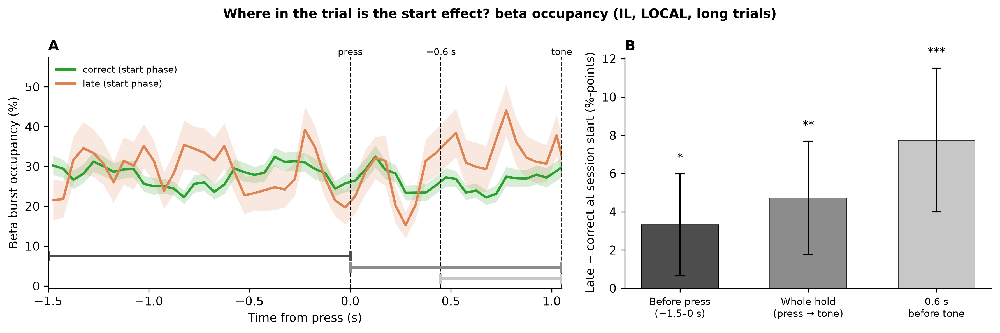


===== beta_rate: late − correct (bursts/s) per phase and window (all rats) =====
           window  phase  late_minus_correct  ci_low  ci_high     p  sig
     before press  start               0.303  -0.054    0.659 0.096 n.s.
     before press middle              -0.143  -0.375    0.088 0.226 n.s.
     before press    end               0.188  -0.212    0.587 0.358 n.s.
       whole hold  start               0.527   0.122    0.931 0.011    *
       whole hold middle               0.002  -0.261    0.265 0.987 n.s.
       whole hold    end               0.282  -0.171    0.736 0.222 n.s.
0.6 s before tone  start               0.911   0.368    1.454 0.001  ***
0.6 s before tone middle              -0.003  -0.356    0.350 0.987 n.s.
0.6 s before tone    end              -0.098  -0.707    0.511 0.752 n.s.


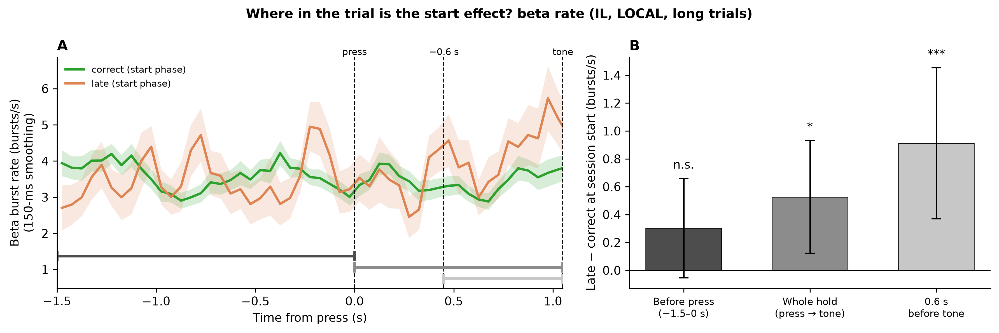

In [43]:
# %%
# ── STEP 4. WHERE IN THE TRIAL IS THE START EFFECT? occupancy and rate, 3 windows (IL beta, LOCAL, long trials, all blocks) ──
globals().pop("C", None)
import warnings
import statsmodels.formula.api as smf
from scipy.stats import norm
from IPython.display import Image, display
BAND = "beta 15-30"; BIN = fn.BURST_BIN; A0P, A0T = fn.BURST_A0["press"], fn.BURST_A0["tone"]
COLC = {"correct": "#2CA02C", "late": "#DD8452"}
PHS, CUTS = ["start", "middle", "end"], (0.25, 0.85)
WINS = ["before press", "whole hold", "0.6 s before tone"]
WLAB = {"before press": "Before press\n(−1.5–0 s)", "whole hold": "Whole hold\n(press → tone)", "0.6 s before tone": "0.6 s\nbefore tone"}
WCOL = {"before press": "0.30", "whole hold": "0.55", "0.6 s before tone": "0.78"}      # dark, medium, light grey
stars = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."

PT = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), low_memory=False).sort_values(["session", "trial_index"])
PT["position"] = PT.groupby("session")["trial_index"].rank(pct=True)
B6 = TABS[BAND]["late"]
B6 = B6[(B6.ref == "LOCAL") & (B6.group == "IL") & (B6.typ == "long") & B6.cond.isin(["correct", "late"])][["session", "rat", "trial", "cond"]]

def wmean(v, tstart, a, b, how):                                 # mean occupancy (%) or rate (bursts/s) of the 50-ms bins inside [a, b]
    sel = (tstart >= a - 1e-9) & (tstart + BIN <= b + 1e-9)
    if not sel.any() or b <= a or not np.isfinite(v[sel]).all():
        return np.nan
    return 100 * v[sel].mean() if how == "occ" else v[sel].sum() / (sel.sum() * BIN)

rows, CV_O, CV_R = [], [], []
for s in files:
    z = np.load(os.path.join(BURST_DIR, s + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))
    kp, kt = f"LOCAL|{BAND}|IL|press", f"LOCAL|{BAND}|IL|tone"
    if kp + "|occ" not in z.files or z[kp + "|occ"].shape[0] != len(T):
        print("skipped", s); continue
    Op, Cp, Ot, Ct = z[kp + "|occ"], z[kp + "|cnt"], z[kt + "|occ"], z[kt + "|cnt"]
    tp = A0P + BIN * np.arange(Op.shape[1]); tt_ = A0T + BIN * np.arange(Ot.shape[1])
    for _, r in B6[B6.session == s].iterrows():
        i = int(r.trial); tone = T["tone_s"].iat[i] - T["press_s"].iat[i]
        row = dict(session=s, trial=i, rat=str(r.rat), cond=r.cond, long_prob=T["long_prob"].iat[i], trial_index=T["trial_index"].iat[i],
                   tone_after_press=tone)
        for how, P_, T_ in (("occ", Op, Ot), ("rate", Cp, Ct)):
            row[f"{how}|before press"] = wmean(P_[i], tp, -1.5, 0.0, how)
            row[f"{how}|whole hold"] = wmean(P_[i], tp, 0.0, min(tone, tp[-1] + BIN), how)
            row[f"{how}|0.6 s before tone"] = wmean(T_[i], tt_, -0.6, 0.0, how)
        rows.append(row); CV_O.append(100 * Op[i]); CV_R.append(Cp[i] / BIN)
W = pd.DataFrame(rows); CV_O, CV_R = np.vstack(CV_O), np.vstack(CV_R)
W = W.merge(PT[["session", "trial_index", "position"]], on=["session", "trial_index"], how="left")
keep = W["position"].notna().values
W, CV_O, CV_R = W[keep].reset_index(drop=True), CV_O[keep], CV_R[keep]
W["late"] = (W.cond == "late").astype(int); W["block"] = W.long_prob.round(2).astype(str)
W["phase"] = pd.cut(W["position"], [-0.001, *CUTS, 1.001], labels=PHS).astype(str)
TONE = W.tone_after_press.median()
print(f"{W.session.nunique()} sessions, {len(W)} trials ({W.late.sum()} late); median tone {TONE:.2f} s after the press")
print("trials per block:", W.block.value_counts().sort_index().to_dict())

def phase_fit(d, col):
    d = d.dropna(subset=[col]).assign(y=lambda x: x[col])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm("y ~ late * C(phase, Treatment('start')) + C(block)", d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"])
    P, V = m.params, m.cov_params(); out = {}
    for ph in PHS:
        k = ["late"] + ([f"late:C(phase, Treatment('start'))[T.{ph}]"] if ph != "start" else [])
        e = sum(P[x] for x in k); se = np.sqrt(sum(V.loc[a, b] for a in k for b in k)); out[ph] = (e, se, 2 * norm.sf(abs(e / se)))
    return out

def figure(R, CV, ylab, unit, title, fname, off, smooth=1):
    tc = A0P + BIN * np.arange(CV.shape[1]) + BIN / 2
    st = (W.phase == "start").values
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.0), gridspec_kw=dict(width_ratios=[1.4, 1]), facecolor="white")
    for lab, col in COLC.items():
        k = st & (W.cond == lab).values
        S = pd.DataFrame(CV[k]).assign(session=W.session.values[k]).groupby("session").mean()
        if smooth > 1: S = S.T.rolling(smooth, center=True, min_periods=1).mean().T
        m, se = S.mean().values, S.sem().values
        a1.fill_between(tc, m - se, m + se, color=col, alpha=0.18, lw=0); a1.plot(tc, m, color=col, lw=2, label=f"{lab} (start phase)")
    a1.set_xlim(-1.5, TONE)
    for x_, lab in ((0, "press"), (TONE - 0.6, "−0.6 s"), (TONE, "tone")):
        a1.axvline(x_, color="k", ls="--", lw=0.9)
        a1.text(x_, 1.0, lab, transform=a1.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
    y0, y1 = a1.get_ylim(); h = y1 - y0; a1.set_ylim(y0 - 0.22 * h, y1)                  # room for the window symbols at the bottom
    for k, (w, (a, b)) in enumerate({"before press": (-1.5, 0.0), "whole hold": (0.0, TONE), "0.6 s before tone": (TONE - 0.6, TONE)}.items()):
        y = y0 - 0.05 * h - k * 0.06 * h; c = WCOL[w]
        a1.plot([a, b], [y, y], color=c, lw=2.4, solid_capstyle="butt")
        a1.plot([a, a], [y - 0.02 * h, y + 0.02 * h], color=c, lw=2.4); a1.plot([b, b], [y - 0.02 * h, y + 0.02 * h], color=c, lw=2.4)
    a1.set_xlabel("Time from press (s)"); a1.set_ylabel(ylab)
    a1.legend(frameon=False, fontsize=8, loc="upper left"); a1.set_title("A", loc="left", fontweight="bold")
    r0 = R[R.phase == "start"].set_index("window").loc[WINS]
    for k, w in enumerate(WINS):
        rr = r0.loc[w]
        a2.bar(k, rr.late_minus_correct, width=0.6, color=WCOL[w], edgecolor="k", lw=0.6)
        a2.errorbar(k, rr.late_minus_correct, yerr=[[rr.late_minus_correct - rr.ci_low], [rr.ci_high - rr.late_minus_correct]], color="k", capsize=4, lw=1.2)
        up = rr.late_minus_correct >= 0
        a2.text(k, rr.ci_high + off if up else rr.ci_low - off, rr.sig, ha="center", va="bottom" if up else "top", fontsize=10)
    a2.axhline(0, color="k", lw=0.8)
    a2.set_xticks(range(len(WINS))); a2.set_xticklabels([WLAB[w] for w in WINS], fontsize=8.5)
    a2.set_ylabel(f"Late − correct at session start ({unit})"); a2.set_title("B", loc="left", fontweight="bold")
    for ax in (a1, a2):
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    fig.suptitle(title, fontsize=11, fontweight="bold"); fig.tight_layout()
    for folder in (FIGS, BETA_DIR): fig.savefig(os.path.join(folder, fname), dpi=300, facecolor="white", bbox_inches="tight")
    plt.close(fig); display(Image(os.path.join(FIGS, fname)))

plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
for how, CV, ylab, unit, off, sm in (("occ", CV_O, "Beta burst occupancy (%)", "%-points", 0.5, 1),
                                     ("rate", CV_R, "Beta burst rate (bursts/s)\n(150-ms smoothing)", "bursts/s", 0.05, 3)):
    R = pd.DataFrame([dict(window=w, phase=ph, late_minus_correct=e, ci_low=e - 1.96 * se, ci_high=e + 1.96 * se, p=p)
                      for w in WINS for ph, (e, se, p) in phase_fit(W, f"{how}|{w}").items()])
    R["sig"] = R["p"].apply(stars)
    name = "beta_occupancy" if how == "occ" else "beta_rate"
    for folder in (TABLES, BETA_DIR): R.to_csv(os.path.join(folder, f"step4_{name}_where_in_trial.csv"), index=False)
    print(f"\n===== {name}: late − correct ({unit}) per phase and window (all rats) =====")
    print(R.to_string(index=False))
    figure(R, CV, ylab, unit, f"Where in the trial is the start effect? {name.replace('_', ' ')} (IL, LOCAL, long trials)",
           f"step4_{name}_where_in_trial.png", off, sm)
pd.reset_option("display.float_format")

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 5. Do more beta bursts before the tone mean less success?

Same trials as Steps 3–4 (IL, LOCAL, long correct vs late, all blocks, whole session).<br>
Each trial is put in a group by its beta burst occupancy in the 0.6 s before the tone (as Golan / Karvat 2021):
quiet 0 %, low ≤ 25 % (≤ 150 ms), medium ≤ 50 % (≤ 300 ms), high > 50 % (> 300 ms).<br>
Success = correct / (correct + late). For each session and group: success as % change from the session mean
(groups with ≥ 3 trials; groups shown if ≥ 5 sessions; sessions with at least one correct and one late trial).<br>
Tests: one-way ANOVA across groups, and a straight line through the session values (trend = change in success per group step,
same units as the bars; SE clustered by session).
<div>

check occ scale: min 0.000, max 1.000 (must be 0–1); trials 3233 (correct 2743, late 490) — Step 3: 2743 / 490

success (% change from session mean) per group:
       group  PCM_mean  PCM_sem  sessions  trials
   Quiet 0 %      4.41     3.26        41     301
   Low ≤25 %      0.88     1.41        51    1215
Medium ≤50 %     -0.69     1.25        49    1054
  High >50 %     -5.75     2.61        43     335

tests:
 sessions  n_correct  n_late  points  anova_F  anova_p  trend_pct_per_group  trend_p
       51       2444     490     184   3.5293   0.0161              -3.1798   0.0118


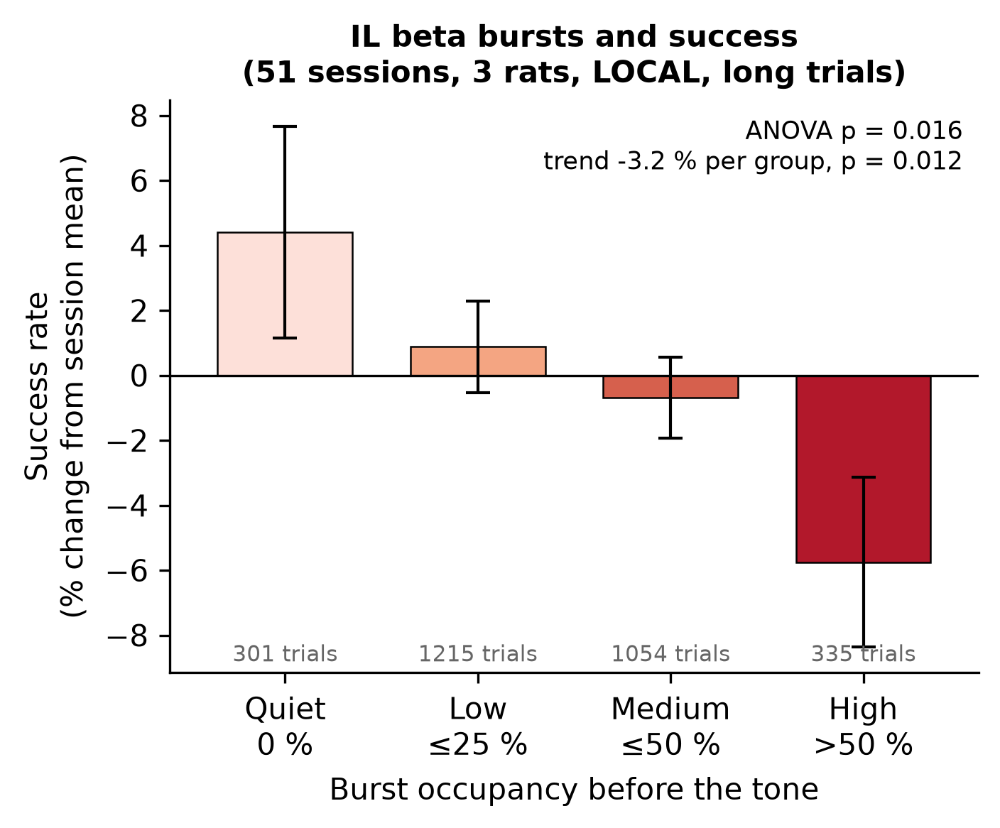

In [51]:
# ── Step 5. success vs pre-tone beta burst occupancy, IL LOCAL, long trials, all blocks, whole session (needs Settings, 6a) ──
import statsmodels.formula.api as smf
from scipy.stats import f_oneway
from IPython.display import Image, display

BAND = [b for b in BURST_BANDS_R if b.startswith("beta")][0]
OBINS = ["Quiet\n0 %", "Low\n≤25 %", "Medium\n≤50 %", "High\n>50 %"]
BINCOL = ["#fde0d9", "#f4a582", "#d6604d", "#b2182b"]
MIN_BIN_TR, MIN_BIN_SES = 3, 5

# same trials as Steps 3–4 (all blocks)
TP = pd.concat([pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))[["long_prob"]]
                .assign(session=s, trial=lambda d: d.index) for s in files], ignore_index=True)
L = TABS[BAND]["late"].merge(TP, on=["session", "trial"], how="left")
L = L[(L.ref == "LOCAL") & (L.group == "IL") & (L.typ == "long") & L.cond.isin(["correct", "late"])].dropna(subset=["occ"]).copy()
L["success"] = (L.cond == "correct").astype(float)
L["obin"] = np.select([L.occ <= 0, L.occ <= 0.25, L.occ <= 0.5], [0, 1, 2], default=3)
print(f"check occ scale: min {L.occ.min():.3f}, max {L.occ.max():.3f} (must be 0–1); "
      f"trials {len(L)} (correct {(L.cond=='correct').sum()}, late {(L.cond=='late').sum()}) — Step 3: 2743 / 490")

# sessions with at least one correct and one late trial
n_ = L.groupby("session")["cond"].agg(n_c=lambda x: (x == "correct").sum(), n_l=lambda x: (x == "late").sum())
L = L[L.session.isin(n_[(n_.n_c >= MIN_TR) & (n_.n_l >= MIN_TR)].index)].copy()

# per session and group: success as % change from the session mean
sm = L.groupby("session")["success"].mean()
PS = L.groupby(["session", "obin"])["success"].agg(["mean", "size"]).reset_index()
PS = PS[PS["size"] >= MIN_BIN_TR].copy()
PS["pcm"] = 100 * (PS["mean"] - PS["session"].map(sm)) / PS["session"].map(sm)
ST = PS.groupby("obin")["pcm"].agg(["mean", "sem", "size"]).reindex(range(4))
ST["size"] = ST["size"].fillna(0).astype(int)
ST["trials"] = PS.groupby("obin")["size"].sum().reindex(range(4)).fillna(0).astype(int)
OK = [b for b in range(4) if ST["size"].iat[b] >= MIN_BIN_SES]

# tests: ANOVA across groups + straight line through the session values (same units as the bars)
F, P_ANOVA = f_oneway(*[PS.loc[PS.obin == b, "pcm"].values for b in OK]) if len(OK) >= 2 else (np.nan, np.nan)
PSb = PS[PS.obin.isin(OK)].copy()
mb = smf.ols("pcm ~ obin", PSb).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(PSb["session"])[0]})
TREND, P_TREND = mb.params["obin"], mb.pvalues["obin"]

OUT = pd.DataFrame(dict(group=[o.replace("\n", " ") for o in OBINS], PCM_mean=ST["mean"].values,
                        PCM_sem=ST["sem"].values, sessions=ST["size"].values, trials=ST["trials"].values))
RES = pd.DataFrame([dict(sessions=L.session.nunique(), n_correct=int((L.cond == "correct").sum()),
                         n_late=int((L.cond == "late").sum()), points=len(PSb), anova_F=F, anova_p=P_ANOVA,
                         trend_pct_per_group=TREND, trend_p=P_TREND)])
print("\nsuccess (% change from session mean) per group:"); print(OUT.round(2).to_string(index=False))
print("\ntests:"); print(RES.round(4).to_string(index=False))
OUT.to_csv(os.path.join(BETA_DIR, "step5_success_vs_beta_occupancy.csv"), index=False)
RES.to_csv(os.path.join(BETA_DIR, "step5_success_vs_beta_occupancy_tests.csv"), index=False)

# ── figure ──
ptxt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig, ax = plt.subplots(figsize=(4.8, 4.0))
for b in OK:
    ax.bar(b, ST["mean"].iat[b], width=0.7, color=BINCOL[b], edgecolor="k", lw=0.6)
    ax.errorbar(b, ST["mean"].iat[b], yerr=ST["sem"].iat[b], color="k", capsize=4, lw=1)
    ax.text(b, 0.02, f"{ST['trials'].iat[b]} trials", transform=ax.get_xaxis_transform(), ha="center", fontsize=7.5, color="0.4")
ax.text(0.98, 0.97, f"ANOVA {ptxt(P_ANOVA)}\ntrend {TREND:+.1f} % per group, {ptxt(P_TREND)}",
        transform=ax.transAxes, ha="right", va="top", fontsize=8.5)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(4)); ax.set_xticklabels(OBINS); ax.set_xlim(-0.6, 3.6)
ax.set_xlabel("Burst occupancy before the tone")
ax.set_ylabel("Success rate\n(% change from session mean)")
ax.set_title(f"IL beta bursts and success\n({L.session.nunique()} sessions, 3 rats, LOCAL, long trials)", fontsize=10, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fp = os.path.join(BETA_DIR, "step5_success_vs_beta_occupancy.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig)
display(Image(fp))

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 6. Does the timing of the last beta burst before the tone predict the reaction time?

IL, LOCAL, long trials (correct and late), all blocks, exact burst times.<br>
For each trial: the last beta burst that started in the 1 s before the tone and how long before the tone it ended (gap, s).
Trials whose last burst is still ON at the tone are left out (no gap), as are trials without a burst in the 1 s and trials whose
window overlaps an artifact.<br>
<b>Why a simple correlation is not enough</b> (figure step6_RT_why): <b>A</b> the rats differ in RT (mean of session medians ± SEM);
<b>B</b> RT and gap change along the session; <b>C</b> more bursts in the 1 s → the last burst ends closer to the tone.<br>
So the model corrects for all three: log10 RT ~ gap + rat + position in session (z) + number of bursts (z) + (1 | session).
Effect = % change in RT when the last burst ended 1 s closer to the tone.<br>
<b>Figure step6_RT</b>: model line and adjusted RT in 4 ranges of the gap (display only; the test is on the continuous gap).
Checks (+ late term, correct only, late only) are printed and saved for the robustness slide.
<div>

60 sessions | long correct+late trials 3233 | with a burst in the 1 s 3098 | still ON at the tone (left out) 872 | kept 2226 (318 late)   — earlier: 3098 / 872 / 2226 (318 late)

A. per rat: RT (ms), mean of session medians ± SEM
   rat 134: 375 ± 16  (11 sessions)
   rat 135: 291 ± 18  (29 sessions)
   rat 136: 295 ± 8  (20 sessions)
B. position in session vs RT: rho = +0.063, p = 0.0028 ; vs gap: rho = +0.022, p = 0.3103
   rat 134: position vs RT rho = +0.091, p = 0.0297
   rat 135: position vs RT rho = +0.124, p = 0.0001
   rat 136: position vs RT rho = -0.037, p = 0.3489
C. number of bursts vs gap: rho = -0.417, p = 3.493e-94  (< 0 = more bursts -> last burst closer)


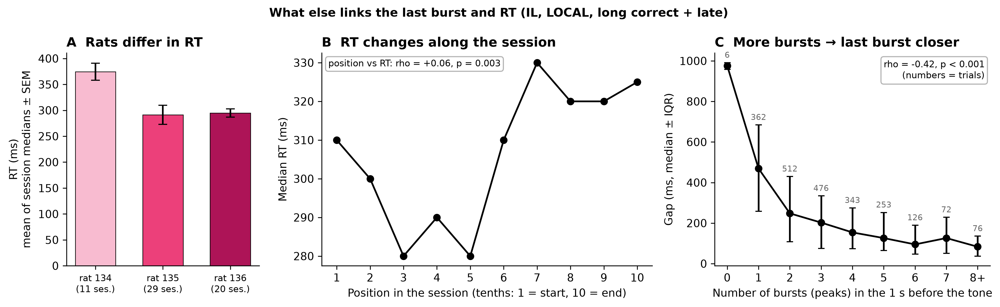

  [late trials only] fitted with method 'bfgs'

% change in RT when the last burst ends 1 s closer to the tone:
              model    n  sessions     pct      lo     hi     p
    D2 (all trials) 2226        60  15.010   1.349 30.513 0.030
     D2 + late term 2226        60   9.009  -1.370 20.480 0.091
correct trials only 1908        60   8.375  -2.543 20.516 0.138
   late trials only  318        50 -11.061 -30.836 14.370 0.361
late term: +201 % RT, p = 3.7e-291 | number of bursts: -0.9 % RT per +1 SD, p = 0.5110

adjusted RT per range (display only)
    gbin   n    ms
   0–0.1 650 315.0
0.1–0.25 628 300.0
0.25–0.5 605 303.0
 0.5–1.0 343 278.0


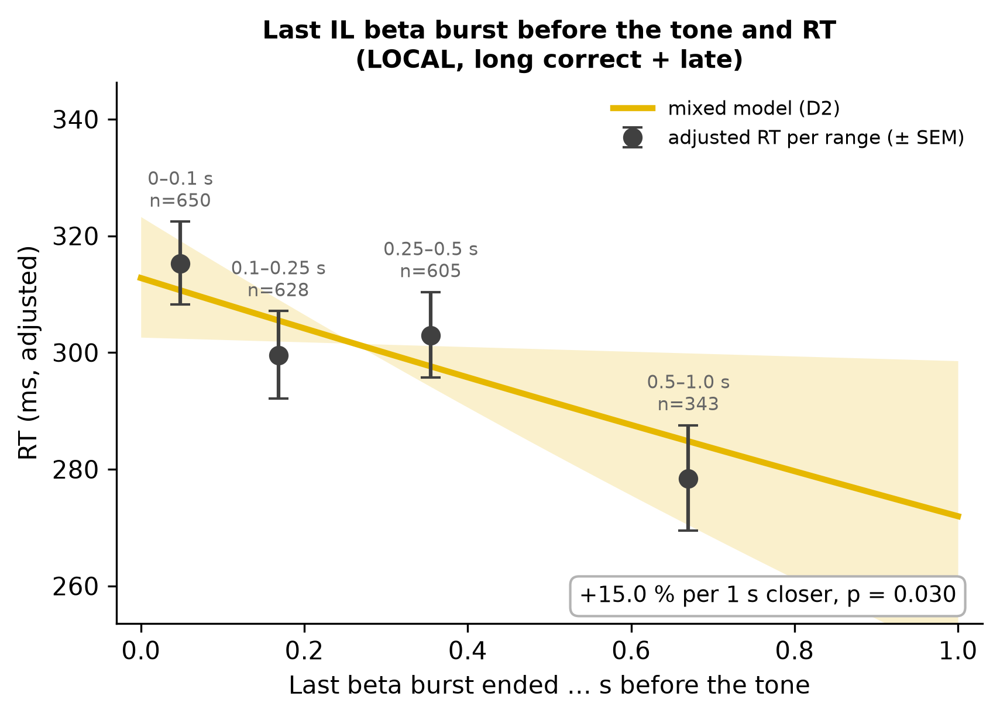

In [10]:
# ── STEP 6. LAST BETA BURST BEFORE THE TONE AND RT (exact times, IL LOCAL, long correct + late, all blocks) (needs Settings, RAT) ──
import glob, warnings
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from IPython.display import Image, display
RT_DIR = os.path.join(BETA_DIR, "RT"); os.makedirs(RT_DIR, exist_ok=True)
YEL6, WIN6 = "#E6B800", 1.0                                      # window before the tone (s), long trials
RCOL6 = {"134": "#F8BBD0", "135": "#EC407A", "136": "#AD1457"}       # rats: light, medium, dark pink
pct_closer = lambda b: 100 * (10 ** (-1.0 * b) - 1)                 # % RT change when the last burst ends 1 s CLOSER to the tone
ptxt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

# ── 1. per-trial table from the exact burst times ──
def exact_trials(bs, be, pk, ast, aen, tones, w):
    n = len(tones); gap = np.full(n, np.nan); ong = np.zeros(n, bool); npk = np.full(n, np.nan)
    for i, T in enumerate(tones):
        if not np.isfinite(T):
            continue
        a = T - w
        j = np.searchsorted(ast, T, "left") - 1                     # artifact overlapping the window -> trial left out
        if j >= 0 and aen[j] > a:
            continue
        k1 = np.searchsorted(bs, T, "left") - 1                     # last burst that started before the tone
        if k1 >= 0 and be[k1] > a:
            ong[i] = be[k1] > T
            gap[i] = 0.0 if ong[i] else T - be[k1]
        npk[i] = np.searchsorted(pk, T, "left") - np.searchsorted(pk, a, "left")
    return gap, ong, npk

rows, K6 = [], "LOCAL|beta 15-30|IL"
for f in sorted(glob.glob(os.path.join(EXACT_DIR, "*.npz"))):
    s = os.path.basename(f)[:-4]; z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
    if K6 + "|burst_start_s" not in z.files:
        print("no IL LOCAL bursts:", s); continue
    rt = (T["release_s"] - T["tone_s"]).values
    idx = np.where(np.isin(T["label"].values, ["correct", "late"]) & (T["type"].values == "long") & np.isfinite(rt))[0]
    gap, ong, npk = exact_trials(z[K6 + "|burst_start_s"], z[K6 + "|burst_end_s"], z[K6 + "|peak_s"],
                                 z["LOCAL|IL|art_start_s"], z["LOCAL|IL|art_end_s"], T["tone_s"].values[idx], WIN6)
    rows.append(pd.DataFrame({"session": s, "rat": str(RAT[s]), "label": T["label"].values[idx], "trial": idx,
                              "pos": idx / max(len(T) - 1, 1), "rt_s": rt[idx], "gap_s": gap, "n_peaks": npk,
                              "burst_at_tone": ong.astype(float)}))
TB6 = pd.concat(rows, ignore_index=True)
TB6.to_csv(os.path.join(RT_DIR, "step6_RT_trials.csv"), index=False)

Db = TB6[TB6.gap_s.notna() & TB6.n_peaks.notna() & (TB6.rt_s > 0)].copy()
Db["logrt"] = np.log10(Db["rt_s"])
Db["trial_z"] = Db.groupby("session")["trial"].transform(lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0 * x)
d6 = Db[Db.gap_s > 0].copy()                                         # burst ended before the tone
d6["peaks_z"] = (d6["n_peaks"] - d6["n_peaks"].mean()) / d6["n_peaks"].std()
d6["late"] = (d6["label"] == "late").astype(float); d6["rt_ms"] = 1000 * d6["rt_s"]
print(f"{TB6.session.nunique()} sessions | long correct+late trials {len(TB6)} | with a burst in the 1 s {len(Db)} | "
      f"still ON at the tone (left out) {int((Db.gap_s == 0).sum())} | kept {len(d6)} ({int(d6.late.sum())} late)"
      f"   — earlier: 3098 / 872 / 2226 (318 late)")

# ── 2. why a simple test is not enough: rats, position in session, number of bursts ──
S = d6.groupby(["session", "rat"]).agg(gap=("gap_s", "median"), rt=("rt_ms", "median"), n=("rt_ms", "size")).reset_index()
S["rat"] = S["rat"].astype(str); rats_ = ["134", "135", "136"]
d6["tenth"] = np.clip(np.ceil(d6["pos"] * 10), 1, 10).astype(int)
P = d6.groupby("tenth").agg(rt=("rt_ms", "median"), gap=("gap_s", "median"), n=("rt_ms", "size"))
rho_br, p_br = spearmanr(d6["pos"], d6["rt_ms"]); rho_bg, p_bg = spearmanr(d6["pos"], d6["gap_s"])
d6["k"] = d6["n_peaks"].clip(upper=8).astype(int)
K = d6.groupby("k")["gap_s"].agg(med="median", q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75), n="size")
rho_c, p_c = spearmanr(d6["n_peaks"], d6["gap_s"])
print("\nA. per rat: RT (ms), mean of session medians ± SEM")
for r in rats_:
    v = S.loc[S.rat == r, "rt"]; print(f"   rat {r}: {v.mean():.0f} ± {v.sem():.0f}  ({len(v)} sessions)")
print(f"B. position in session vs RT: rho = {rho_br:+.3f}, p = {p_br:.4f} ; vs gap: rho = {rho_bg:+.3f}, p = {p_bg:.4f}")
for r in rats_:
    x = d6[d6.rat == r]; rr_, pp_ = spearmanr(x["pos"], x["rt_ms"])
    print(f"   rat {r}: position vs RT rho = {rr_:+.3f}, p = {pp_:.4f}")
print(f"C. number of bursts vs gap: rho = {rho_c:+.3f}, p = {p_c:.4g}  (< 0 = more bursts -> last burst closer)")

plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig, ax = plt.subplots(1, 3, figsize=(13, 4.0), facecolor="white", gridspec_kw=dict(width_ratios=[0.7, 1.2, 1]))
a = ax[0]
m = [S.loc[S.rat == r, "rt"].mean() for r in rats_]; e = [S.loc[S.rat == r, "rt"].sem() for r in rats_]
a.bar(range(3), m, yerr=e, width=0.6, color=[RCOL6[r] for r in rats_], edgecolor="k", lw=0.6, capsize=4)
a.set_xticks(range(3)); a.set_xticklabels([f"rat {r}\n({(S.rat == r).sum()} ses.)" for r in rats_], fontsize=8.5)
a.set_ylabel("RT (ms)\nmean of session medians ± SEM")
a.set_title("A  Rats differ in RT", loc="left", fontweight="bold")
b = ax[1]
b.plot(P.index, P.rt, "o-", color="k", lw=1.6)
b.set_xticks(range(1, 11)); b.set_xlabel("Position in the session (tenths: 1 = start, 10 = end)")
b.set_ylabel("Median RT (ms)")
b.set_title("B  RT changes along the session", loc="left", fontweight="bold")
b.text(0.02, 0.97, f"position vs RT: rho = {rho_br:+.2f}, {ptxt(p_br)}", transform=b.transAxes, ha="left", va="top",
       fontsize=8.5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7"))
c = ax[2]
c.errorbar(K.index, 1000 * K.med, yerr=[1000 * (K.med - K.q1), 1000 * (K.q3 - K.med)], fmt="o-", color="k", capsize=3, lw=1.6)
for kk, rr in K.iterrows():
    c.text(kk, 1000 * rr.q3 + 15, f"{int(rr.n)}", ha="center", va="bottom", fontsize=7.5, color="0.4")
c.set_xticks(K.index); c.set_xticklabels([str(i) if i < 8 else "8+" for i in K.index])
c.set_xlabel("Number of bursts (peaks) in the 1 s before the tone"); c.set_ylabel("Gap (ms, median ± IQR)")
c.set_title("C  More bursts → last burst closer", loc="left", fontweight="bold")
c.text(0.98, 0.97, f"rho = {rho_c:+.2f}, {ptxt(p_c)}\n(numbers = trials)", transform=c.transAxes, ha="right", va="top", fontsize=8.5,
       bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7"))
for x_ in ax:
    x_.spines["top"].set_visible(False)
for x_ in ax: x_.spines["right"].set_visible(False)
fig.suptitle("What else links the last burst and RT (IL, LOCAL, long correct + late)", fontsize=11, fontweight="bold")
fig.tight_layout()
fp = os.path.join(RT_DIR, "step6_RT_why.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig)
display(Image(fp))

# ── 3. D2 and checks ──
F_D2 = "logrt ~ gap_s + rat + trial_z + peaks_z"
def fit6(f, dat, lab=""):
    for m_ in ("lbfgs", "bfgs", "cg", "nm"):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                r_ = smf.mixedlm(f, dat, groups=dat["session"]).fit(method=m_)
            if np.isfinite(r_.bse["gap_s"]):
                if m_ != "lbfgs": print(f"  [{lab}] fitted with method '{m_}'")
                return r_
        except Exception:
            pass
    print(f"  [{lab}] mixed model failed -> OLS with session-clustered SE")
    return smf.ols(f, dat).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(dat["session"])[0]})

CHECKS = [("D2 (all trials)", F_D2, d6), ("D2 + late term", F_D2 + " + late", d6),
          ("correct trials only", F_D2, d6[d6.label == "correct"]), ("late trials only", F_D2, d6[d6.label == "late"])]
rows, fits = [], {}
for lab, f, dat in CHECKS:
    r_ = fit6(f, dat, lab); fits[lab] = r_
    b_, se_, p_ = r_.params["gap_s"], r_.bse["gap_s"], r_.pvalues["gap_s"]
    rows.append(dict(model=lab, n=len(dat), sessions=dat.session.nunique(), pct=pct_closer(b_),
                     lo=pct_closer(b_ + 1.96 * se_), hi=pct_closer(b_ - 1.96 * se_), p=p_))
R6 = pd.DataFrame(rows)
print("\n% change in RT when the last burst ends 1 s closer to the tone:"); print(R6.round(3).to_string(index=False))
rl, rd = fits["D2 + late term"], fits["D2 (all trials)"]
print(f"late term: {100 * (10 ** rl.params['late'] - 1):+.0f} % RT, p = {rl.pvalues['late']:.2g} | "
      f"number of bursts: {100 * (10 ** rd.params['peaks_z'] - 1):+.1f} % RT per +1 SD, p = {rd.pvalues['peaks_z']:.4f}")

# ── 4. model line + adjusted RT per range (display only) ──
b, se = rd.params["gap_s"], rd.bse["gap_s"]
Xb = np.dot(rd.model.exog, rd.fe_params.values)
base = d6["logrt"].mean() - b * d6["gap_s"].mean()                   # anchor at the real mean RT (slope and test unchanged)
gbar = d6["gap_s"].mean(); g = np.linspace(0, 1, 101)
pred = 1000 * 10 ** (base + b * g)
blo = 1000 * 10 ** (base + b * g - 1.96 * se * np.abs(g - gbar)); bhi = 1000 * 10 ** (base + b * g + 1.96 * se * np.abs(g - gbar))
res = d6["logrt"].values - Xb
res = res - pd.Series(res, index=d6.index).groupby(d6["session"]).transform("mean").values   # remove each session's baseline
d6["lpr"] = base + b * d6["gap_s"].values + res
BINS, BLAB = [0.0, 0.1, 0.25, 0.5, 1.0001], ["0–0.1", "0.1–0.25", "0.25–0.5", "0.5–1.0"]
d6["gbin"] = pd.cut(d6["gap_s"], BINS, labels=BLAB)
G = d6.groupby("gbin", observed=True).agg(x=("gap_s", "mean"), m=("lpr", "mean"), se=("lpr", "sem"), n=("lpr", "size")).reset_index()
G["ms"], G["lo"], G["hi"] = 1000 * 10 ** G.m, 1000 * 10 ** (G.m - G.se), 1000 * 10 ** (G.m + G.se)
print("\nadjusted RT per range (display only)"); print(G[["gbin", "n", "ms"]].round(0).to_string(index=False))
R6.to_csv(os.path.join(RT_DIR, "step6_RT.csv"), index=False)
G.to_csv(os.path.join(RT_DIR, "step6_RT_ranges.csv"), index=False)

fig, a = plt.subplots(figsize=(5.8, 4.2), facecolor="white")
a.fill_between(g, np.minimum(blo, bhi), np.maximum(blo, bhi), color=YEL6, alpha=0.2, lw=0)
a.plot(g, pred, color=YEL6, lw=2.5, label="mixed model (D2)")
a.errorbar(G.x, G.ms, yerr=[G.ms - G.lo, G.hi - G.ms], fmt="o", color="0.25", ms=7, capsize=4, lw=1.5, zorder=3,
           label="adjusted RT per range (± SEM)")
for _, rr in G.iterrows():
    a.text(rr.x, rr.hi + 1.5, f"{rr.gbin} s\nn={int(rr.n)}", ha="center", va="bottom", fontsize=7.5, color="0.4")
lo_, hi_ = min(G.lo.min(), pred.min()), max(G.hi.max(), pred.max())
a.set_ylim(lo_ - 0.3 * (hi_ - lo_), hi_ + 0.45 * (hi_ - lo_)); a.set_xlim(-0.03, 1.03)
a.set_xlabel("Last beta burst ended … s before the tone"); a.set_ylabel("RT (ms, adjusted)")
a.text(0.97, 0.03, f"{R6.loc[0, 'pct']:+.1f} % per 1 s closer, {ptxt(R6.loc[0, 'p'])}", transform=a.transAxes, ha="right",
       va="bottom", fontsize=9, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="0.7"))
a.legend(frameon=False, fontsize=8, loc="upper right")
for sp in ("top", "right"): a.spines[sp].set_visible(False)
a.set_title("Last IL beta burst before the tone and RT\n(LOCAL, long correct + late)", fontsize=10, fontweight="bold")
fig.tight_layout()
fp = os.path.join(RT_DIR, "step6_RT.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig)
display(Image(fp))

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 6b. Last beta burst and RT: IL vs PL (check, not for the report)
Same rules as Step 6 (exact times, LOCAL, long correct + late, 1 s before the tone; trials with an artifact in the window or a burst still on at the tone left out).
1. Step 6 model for IL and PL separately: logrt ~ gap_s + rat + trial_z + peaks_z, random intercept per session.
2. Trials with a finished burst in BOTH regions: logrt ~ gap_IL + gap_PL + rat + trial_z + peaksIL_z + peaksPL_z;
   test gap_IL − gap_PL = 0 (is the IL slope different from the PL slope?).
Saved: Beta bursts\RT\step6b_IL_vs_PL.csv

<div>

In [12]:
# ── STEP 6b. LAST BETA BURST AND RT: IL vs PL (needs Step 6: exact_trials, EXACT_DIR, WIN6, pct_closer, RAT) ──
import glob, warnings
import statsmodels.formula.api as smf

def region_trials(reg):
    """Step 6 table for one region (same rules as Step 6)."""
    K, rows = f"LOCAL|beta 15-30|{reg}", []
    for f in sorted(glob.glob(os.path.join(EXACT_DIR, "*.npz"))):
        s = os.path.basename(f)[:-4]; z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
        if K + "|burst_start_s" not in z.files or f"LOCAL|{reg}|art_start_s" not in z.files:
            continue
        rt = (T["release_s"] - T["tone_s"]).values
        idx = np.where(np.isin(T["label"].values, ["correct", "late"]) & (T["type"].values == "long") & np.isfinite(rt))[0]
        gap, ong, npk = exact_trials(z[K + "|burst_start_s"], z[K + "|burst_end_s"], z[K + "|peak_s"],
                                     z[f"LOCAL|{reg}|art_start_s"], z[f"LOCAL|{reg}|art_end_s"], T["tone_s"].values[idx], WIN6)
        rows.append(pd.DataFrame({"session": s, "rat": str(RAT[s]), "trial": idx, "rt_s": rt[idx],
                                  "gap_s": gap, "n_peaks": npk}))
    d = pd.concat(rows, ignore_index=True)
    d = d[d.gap_s.notna() & d.n_peaks.notna() & (d.rt_s > 0)].copy()
    d["logrt"] = np.log10(d["rt_s"])
    d["trial_z"] = d.groupby("session")["trial"].transform(lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0 * x)
    return d

def fit(f, d):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return smf.mixedlm(f, d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"])

# 1) each region alone (same model as Step 6)
R, out = {}, []
for reg in ["IL", "PL"]:
    d = region_trials(reg); R[reg] = d
    x = d[d.gap_s > 0].copy(); x["peaks_z"] = (x.n_peaks - x.n_peaks.mean()) / x.n_peaks.std()
    m = fit("logrt ~ gap_s + rat + trial_z + peaks_z", x)
    b, se, p = m.params["gap_s"], m.bse["gap_s"], m.pvalues["gap_s"]
    out.append(dict(test=f"{reg} alone", sessions=x.session.nunique(), trials=len(x),
                    pct_RT_per_1s_closer=pct_closer(b), ci_low=pct_closer(b + 1.96 * se), ci_high=pct_closer(b - 1.96 * se), p=p))

# 2) same trials, both regions in one model
key = ["session", "rat", "trial", "logrt"]
J = (R["IL"][R["IL"].gap_s > 0][key + ["gap_s", "n_peaks"]]
     .merge(R["PL"][R["PL"].gap_s > 0][["session", "trial", "gap_s", "n_peaks"]], on=["session", "trial"], suffixes=("_IL", "_PL")))
J["trial_z"] = J.groupby("session")["trial"].transform(lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0 * x)
for r_ in ["IL", "PL"]:
    J[f"peaks{r_}_z"] = (J[f"n_peaks_{r_}"] - J[f"n_peaks_{r_}"].mean()) / J[f"n_peaks_{r_}"].std()
mj = fit("logrt ~ gap_s_IL + gap_s_PL + rat + trial_z + peaksIL_z + peaksPL_z", J)
for r_ in ["IL", "PL"]:
    b, se, p = mj.params[f"gap_s_{r_}"], mj.bse[f"gap_s_{r_}"], mj.pvalues[f"gap_s_{r_}"]
    out.append(dict(test=f"{r_} (both in one model)", sessions=J.session.nunique(), trials=len(J),
                    pct_RT_per_1s_closer=pct_closer(b), ci_low=pct_closer(b + 1.96 * se), ci_high=pct_closer(b - 1.96 * se), p=p))
from scipy.stats import norm
V = mj.cov_params()
bd = mj.params["gap_s_IL"] - mj.params["gap_s_PL"]
sd = np.sqrt(V.loc["gap_s_IL", "gap_s_IL"] + V.loc["gap_s_PL", "gap_s_PL"] - 2 * V.loc["gap_s_IL", "gap_s_PL"])
pd_ = 2 * norm.sf(abs(bd / sd))
out.append(dict(test="IL slope − PL slope", sessions=J.session.nunique(), trials=len(J),
                pct_RT_per_1s_closer=pct_closer(bd), ci_low=pct_closer(bd + 1.96 * sd), ci_high=pct_closer(bd - 1.96 * sd), p=pd_))

O6 = pd.DataFrame(out)
print("RT change (%) when the last beta burst ends 1 s closer to the tone, LOCAL, long correct + late")
print(O6.round(3).to_string(index=False))
O6.to_csv(os.path.join(RT_DIR, "step6b_IL_vs_PL.csv"), index=False)

RT change (%) when the last beta burst ends 1 s closer to the tone, LOCAL, long correct + late
                  test  sessions  trials  pct_RT_per_1s_closer  ci_low  ci_high     p
              IL alone        60    2226                15.010   1.349   30.513 0.030
              PL alone        57    2193                 1.800 -10.467   15.749 0.785
IL (both in one model)        57    1537                 8.047  -7.266   25.888 0.321
PL (both in one model)        57    1537                 5.373  -9.393   22.545 0.497
   IL slope − PL slope        57    1537                 2.537 -17.430   27.332 0.821


<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 7. After an error, is there more beta in the next trial — before or after the press?

Behaviour: after a late trial the next correct response is ~35 ms slower. Here: correct long trials, IL, LOCAL, all blocks, grouped by the
outcome of the trial directly before: <b>after correct</b> vs <b>after an error</b> (late or early).<br>
Plot: beta burst occupancy from 1 s before to 1 s after the press (mean over trials ± SEM, 150-ms smoothing for display).<br>
Test: <b>sign test across sessions</b> — for each session (≥ 3 trials of each kind), is the mean occupancy higher after an error than after
a correct? Done for the 1 s before and the 1 s after the press. Black = p < 0.05, grey = n.s.<br>
Result: before the press beta is slightly higher after an error (~+1.2 %-points, ~5 %); after the press there is no difference.
Late and early errors separately go in the same direction but are not significant on their own (fewer trials).<br>
Checks: licking does not explain it (licks in 0.2 % of trials in that second); the second before the press never contains the previous trial
(the rat waits ~7–9 s). Exploratory: the 1 s windows were chosen after looking at the time course (cluster test over the whole time course p = 0.077). Raw p.
<div>

1 s before the press: higher after an error in 40 of 56 sessions, sign test p = 0.002 (mean difference +1.24 %-points)
1 s after the press: higher after an error in 26 of 56 sessions, sign test p = 0.689 (mean difference -0.87 %-points)
trials: after correct 1370, after an error 1114 | sessions: 56


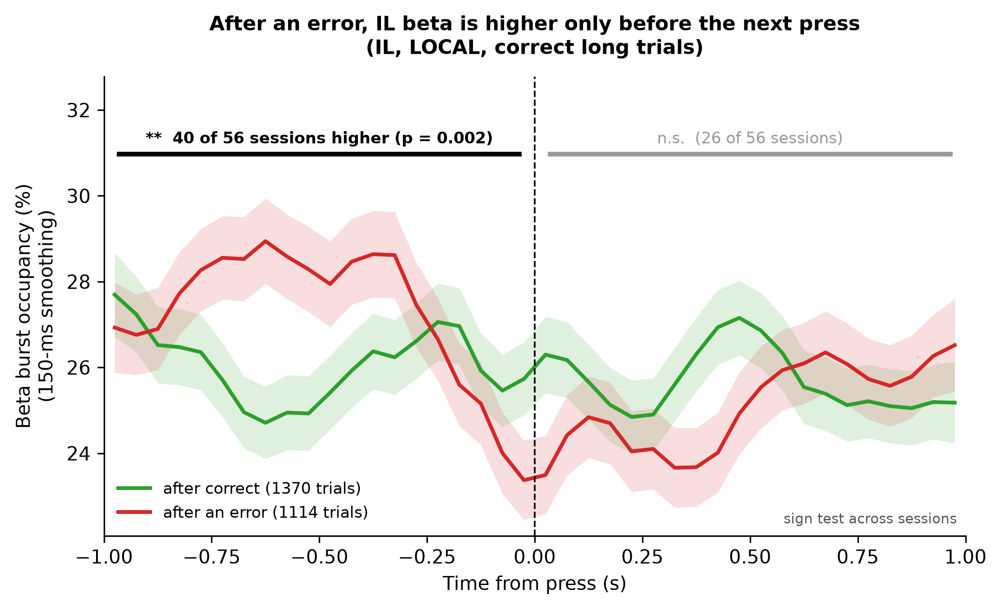

In [115]:
# ── STEP 7. FINAL: BETA 1 s BEFORE / AFTER THE PRESS, AFTER AN ERROR vs AFTER A CORRECT — SIGN TEST ACROSS SESSIONS (IL LOCAL, correct long trials, all blocks) (needs Settings) ──
from scipy.stats import binomtest
from IPython.display import Image, display
BAND = "beta 15-30"; BIN = fn.BURST_BIN; A0P = fn.BURST_A0["press"]; MIN_TR = 3
GCOL = {"correct": "#2CA02C", "error": "#D62728"}
WIN = {"1 s before the press": (-1.0, 0.0), "1 s after the press": (0.0, 1.0)}
ptxt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
stars = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."

# ── 1. correct long trials after a correct or an error (50-ms bins, −1 to +1 s around the press) ──
rows, CV = [], []
for s in files:
    z = np.load(os.path.join(BURST_DIR, s + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))
    kp = f"LOCAL|{BAND}|IL|press|occ"
    if kp not in z.files or z[kp].shape[0] != len(T): continue
    Op = z[kp]; tp = A0P + BIN * np.arange(Op.shape[1]); sel = (tp >= -1.0 - 1e-9) & (tp + BIN <= 1.0 + 1e-9); tw = tp[sel]
    for i in np.where((T["type"].values == "long") & (T["label"].values == "correct"))[0]:
        if i == 0 or T["trial_index"].iat[i - 1] != T["trial_index"].iat[i] - 1 or T["label"].iat[i - 1] not in ("correct", "late", "early"): continue
        v = Op[i, sel]
        if not np.isfinite(v).all(): continue
        r = dict(session=s, grp="correct" if T["label"].iat[i - 1] == "correct" else "error")
        for w, (a_, b_) in WIN.items():
            r[w] = 100 * v[(tw >= a_ - 1e-9) & (tw + BIN <= b_ + 1e-9)].mean()
        rows.append(r); CV.append(100 * v)
E = pd.DataFrame(rows); CV = np.vstack(CV); tc = tw + BIN / 2
kc, ke = (E.grp == "correct").values, (E.grp == "error").values

# ── 2. sign test across sessions, per window ──
n_ = E.groupby(["session", "grp"]).size().unstack(fill_value=0)
SES = n_[(n_["correct"] >= MIN_TR) & (n_["error"] >= MIN_TR)].index
G = E[E.session.isin(SES)].groupby(["session", "grp"])[list(WIN)].mean().unstack("grp")
RES = {}
for w in WIN:
    dif = G[(w, "error")] - G[(w, "correct")]; up = int((dif > 0).sum()); nn = int((dif != 0).sum())
    RES[w] = dict(up=up, n=nn, p=binomtest(up, nn).pvalue, mean_diff=dif.mean())
    print(f"{w}: higher after an error in {up} of {nn} sessions, sign test {ptxt(RES[w]['p'])} "
          f"(mean difference {dif.mean():+.2f} %-points)")
print(f"trials: after correct {kc.sum()}, after an error {ke.sum()} | sessions: {len(SES)}")
pd.DataFrame(RES).T.to_csv(os.path.join(BETA_DIR, "step7_final_signtest.csv"))

# ── 3. figure ──
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8})
fig, a = plt.subplots(figsize=(7.5, 4.6), facecolor="white")
for g, kk in (("correct", kc), ("error", ke)):
    X = pd.DataFrame(CV[kk]).T.rolling(3, center=True, min_periods=1).mean().T.values
    m_, se = X.mean(0), X.std(0, ddof=1) / np.sqrt(kk.sum())
    a.fill_between(tc, m_ - se, m_ + se, color=GCOL[g], alpha=0.15, lw=0)
    a.plot(tc, m_, color=GCOL[g], lw=2, label=f"after {'an error' if g == 'error' else 'correct'} ({kk.sum()} trials)")
a.axvline(0, color="k", ls="--", lw=0.9)
a.set_xlim(-1, 1)
y0, y1 = a.get_ylim(); hh = y1 - y0; a.set_ylim(y0, y1 + 0.3 * hh); yy = y1 + 0.08 * hh   # room above the curves
for w, (lo_, hi_) in WIN.items():
    r = RES[w]; sig = r["p"] < 0.05; col = "k" if sig else "0.6"
    a.plot([lo_ + 0.03, hi_ - 0.03], [yy, yy], color=col, lw=2.5, solid_capstyle="butt")
    lab = f"{stars(r['p'])}  {r['up']} of {r['n']} sessions higher ({ptxt(r['p'])})" if sig else f"n.s.  ({r['up']} of {r['n']} sessions)"
    a.text((lo_ + hi_) / 2, yy + 0.02 * hh, lab, ha="center", va="bottom", fontsize=8.5, color=col, fontweight="bold" if sig else "normal")
a.text(0.99, 0.02, "sign test across sessions", transform=a.transAxes, ha="right", va="bottom", fontsize=7.5, color="0.35")
a.set_xlabel("Time from press (s)"); a.set_ylabel("Beta burst occupancy (%)\n(150-ms smoothing)")
a.legend(frameon=False, fontsize=8.5, loc="lower left")
for sp in ("top", "right"): a.spines[sp].set_visible(False)
a.set_title("After an error, IL beta is higher only before the next press\n(IL, LOCAL, correct long trials)", fontsize=10.5, fontweight="bold", pad=12)
fig.tight_layout(); fp = os.path.join(BETA_DIR, "step7_final.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 8. What do the IL beta bursts look like? (as Karvat et al. 2020, Fig. 2; descriptive)

All IL beta bursts (LOCAL, 15–30 Hz; Morlet 7 cycles, peaks in time–frequency above the <b>98th percentile</b> of each frequency, as Karvat 2020)
within the task period (first press → last release) of all 60 sessions, 3 rats pooled.
Each burst (merged time–frequency event) is represented by its strongest peak:
<b>a</b> peak frequency, <b>b</b> frequency span (number of 1-Hz frequencies above threshold at the peak time),
<b>c</b> duration (time above threshold at the peak frequency), <b>d</b> inter-burst interval (strongest peak of one burst → strongest peak of the next),
<b>e</b> power at the peak (FOM = fraction of the median power of that frequency over the session).<br>
y-axis = bursts per minute of task time; dashed line = median. Descriptive only, no statistical tests.<br>
Result: 103,977 bursts (~1,800 per session, ~53 per minute); median 23 Hz, span 4 Hz, duration 67 ms, interval 0.76 s, power 7.4 FOM
(Karvat 2020, rat M1: median duration 70 ms). 1.5 % of bursts last < 10 ms and 2 % of intervals are < 0.1 s
(weak single-frequency events just above threshold).
<div>

60 sessions, 1962 min of task time | 103977 bursts | per session median 1832 bursts, 55 bursts per minute

all bursts of the task period:
                          median  minimum  % outside x-range
peak frequency (Hz)       23.000   15.000              0.000
span (Hz)                  4.000    1.000              0.000
duration (ms)             67.000    1.000              1.692
inter-burst interval (s)   0.760    0.006              3.332
power (FOM)                7.421    5.536              0.180
bursts per minute         53.001      NaN                NaN
saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Beta bursts\Burst properties (qualitative)\step8_burst_properties_p98.png | exists: True


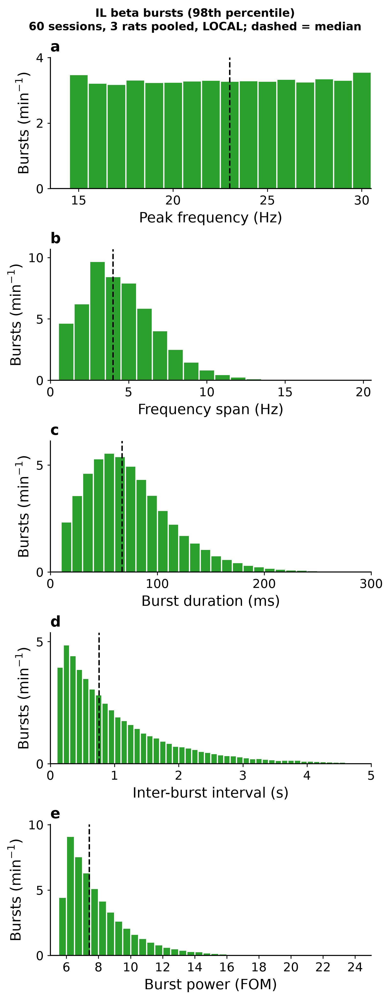

In [20]:
# ── STEP 8. IL BETA BURST PROPERTIES AT THE 98th PERCENTILE, DESCRIPTIVE (as Karvat 2020 Fig. 2): ALL SESSIONS, RATS POOLED (needs cell 0) ──
import glob
from IPython.display import Image, display
GEN_DIR  = os.path.join(BETA_DIR, "Burst properties (qualitative)"); os.makedirs(GEN_DIR, exist_ok=True)
PROP_DIR = os.path.join(DATA_OUT, "Burst properties p98")
COL = "#2CA02C"                                                      # green bars
SHOW_SHORT = False                                                   # do not DRAW bursts < 10 ms (duration) and intervals < 0.1 s (interval)                                                  # False = do not DRAW bursts < 10 ms (duration) and intervals < 0.1 s (interval)
pd.set_option("display.width", 250)

# ── 1. per session, task period: one row per merged burst = its strongest peak ──
rows, INFO = [], []
for f in sorted(glob.glob(os.path.join(PROP_DIR, "*.npz"))):
    s = os.path.basename(f)[:-4]; z = np.load(f)
    t0, t1 = float(z["task_start_s"][0]), float(z["task_end_s"][0])
    P = pd.DataFrame(dict(t=z["peak_s"], freq=z["peak_hz"], span=z["span_hz"] + 1, dur_ms=1000 * z["dur_s"], power=z["power_x_median"]))
    P = P[(P.t >= t0) & (P.t <= t1)]
    bs, be = z["burst_start_s"], z["burst_end_s"]
    i = np.searchsorted(bs, P.t.values, "right") - 1
    ok = (i >= 0) & (P.t.values <= be[np.clip(i, 0, None)])                     # peak lies inside a merged burst
    P = P[ok].assign(b=i[ok]).sort_values("power").groupby("b").last().sort_values("t")
    P["ibi_s"] = np.r_[np.nan, np.diff(P.t.values)]
    rows.append(P.assign(session=s, rat=s.split("_r0000")[1][:3]))
    INFO.append(dict(session=s, rat=s.split("_r0000")[1][:3], minutes=(t1 - t0) / 60, n_bursts=len(P)))
B = pd.concat(rows, ignore_index=True); INFO = pd.DataFrame(INFO)
MIN = INFO.minutes.sum()
print(f"{len(INFO)} sessions, {MIN:.0f} min of task time | {len(B)} bursts | per session median "
      f"{INFO.n_bursts.median():.0f} bursts, {(INFO.n_bursts / INFO.minutes).median():.0f} bursts per minute")

# first bar edge for duration / interval: the smallest value, or 10 ms / 0.1 s if the short ones are not drawn
d0 = B.dur_ms.min() if SHOW_SHORT else 10
i0 = B.ibi_s.min() if SHOW_SHORT else 0.1
DB, IBb = np.arange(10, 301, 10), np.arange(0.1, 5.01, 0.1)
# (column, x-label, bin edges, x-limits, x-tick labels, y-tick labels) — ticks are only the numbers shown, not limits
MEAS = [("freq",   "Peak frequency (Hz)",       np.arange(14.5, 31, 1.0),           (13.5, 30.5), [15, 20, 25, 30],          [0, 2, 4]),
        ("span",   "Frequency span (Hz)",       np.arange(0.5, 21, 1.0),            (0, 20.5),    [0, 5, 10, 15, 20],        [0, 5, 10]),
        ("dur_ms", "Burst duration (ms)",       np.r_[d0, DB[DB > d0]],             (0, 300),     [0, 100, 200, 300],        [0, 5]),
        ("ibi_s",  "Inter-burst interval (s)",  np.r_[i0, IBb[IBb > i0 + 1e-9]],    (0, 5),       [0, 1, 2, 3, 4, 5],        [0, 5]),
        ("power",  "Burst power (FOM)",         np.arange(5, 25.01, 0.5),           (5, 25),      [6, 8, 10, 12, 14, 16, 18, 20, 22, 24], [0, 5, 10])]

# ── 2. numbers: median and minimum (ALL bursts, also those outside the drawn x-range) ──
T = pd.DataFrame({"median": B[[m[0] for m in MEAS]].median(), "minimum": B[[m[0] for m in MEAS]].min(),
                  "% outside x-range": [100 * np.mean((B[c].dropna() < b[0]) | (B[c].dropna() > b[-1])) for c, _, b, *_ in MEAS]})
T.loc["bursts_per_min"] = [len(B) / MIN, np.nan, np.nan]
T.index = ["peak frequency (Hz)", "span (Hz)", "duration (ms)", "inter-burst interval (s)", "power (FOM)", "bursts per minute"]
print("\nall bursts of the task period:"); print(T.round(3).to_string())
T.to_csv(os.path.join(GEN_DIR, "step8_burst_properties_p98.csv"))

# ── 3. figure: bars on the x-axis; y-axis as tall as the data, ticks = only the numbers shown ──
plt.rcParams.update({"font.size": 12, "axes.linewidth": 1.0, "axes.labelsize": 14,
                     "xtick.labelsize": 12, "ytick.labelsize": 12})
fig, axs = plt.subplots(len(MEAS), 1, figsize=(5.2, 13.5), facecolor="white", constrained_layout=True)
for ax, (col, lab, bins, xl, xt, yt), letter in zip(axs, MEAS, "abcde"):
    v = B[col].dropna()
    h = np.histogram(v, bins)[0] / MIN
    ax.bar(bins[:-1], h, width=np.diff(bins), align="edge", color=COL, edgecolor="white", lw=1.2)
    ax.axvline(v.median(), color="k", ls="--", lw=1.4)
    ax.set_xlim(*xl); ax.set_xticks(xt)
    ax.set_ylim(0, h.max() * 1.1); ax.set_yticks(yt)                  # axis follows the data; ticks are just labels
    ax.set_xlabel(lab); ax.set_ylabel("Bursts (min$^{-1}$)")
    ax.set_title(letter, loc="left", fontweight="bold")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    ax.tick_params(direction="out", length=3)
fig.suptitle("IL beta bursts (98th percentile)\n60 sessions, 3 rats pooled, LOCAL; dashed = median", fontsize=11, fontweight="bold")
fp = os.path.join(GEN_DIR, "step8_burst_properties_p98.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig)
print("saved:", fp, "| exists:", os.path.exists(fp)); display(Image(fp))

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 9. Single IL beta bursts and their average (as Karvat et al. 2020, Fig. 3a; descriptive)

IL channel, LOCAL reference, raw LFP (µV, 1000 Hz), <b>98th percentile</b> (data from 06 cell 5e).
Bursts as in Step 8 (strongest peak of each merged burst, task period), selected as Karvat 2020 selected his rewarded bursts:
<b>duration ≥ 70 ms</b> and <b>peak frequency 20–25 Hz</b> (70 ms = our median burst duration; bursts are spread evenly over 15–30 Hz, so the middle band was used).
Each burst aligned to its beta trough (15–30 Hz filter, trough nearest the peak); bursts touching an artifact excluded.<br>
<b>Top:</b> 10 random selected bursts per session; black = LFP, colour = time inside the burst (power above the 98th percentile).
<b>Bottom:</b> mean LFP of all selected bursts of the session. Dashed line = trough (0 ms). Same scale bars in all panels.<br>
<b>Sessions:</b> 4 typical sessions (rule fixed before looking: sessions with < 150 selected bursts and 4 unusual sessions excluded; in each rat the session
closest to the rat's median trough depth and clarity, plus the next closest overall), shown in date order as Session 1–4.<br>
Result: single bursts are short and differ from each other, while their average looks like a rhythm (~22 Hz) — ~2.5 cycles over all 60 sessions
(Karvat 2020: ~6 cycles; his raw LFP ~10× larger, see note on reference). Descriptive only, no statistical tests.
<div>

eligible 49 of 60 sessions | chosen (Session 1–4):
                  session  n_sel  sel_depth_uV  sel_clarity  sel_cycles  dist     label
20260523_r0000136_wt_1320    363        -10.93        20.20        2.63  0.08 Session 1
20260524_r0000136_wt_1836    478        -10.69        20.00        2.52  0.23 Session 2
20260525_r0000135_wt_1426    435        -15.37        20.08        2.59  0.24 Session 3
20260612_r0000134_wt_1447    232        -22.76        17.59        2.59  0.04 Session 4
all 60 sessions: mean of selected bursts 2.56 cycles (range 2.50–2.63)
saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\beta bursts\Burst properties (qualitative)\step9_single_bursts_4_sessions_p98.png | exists: True


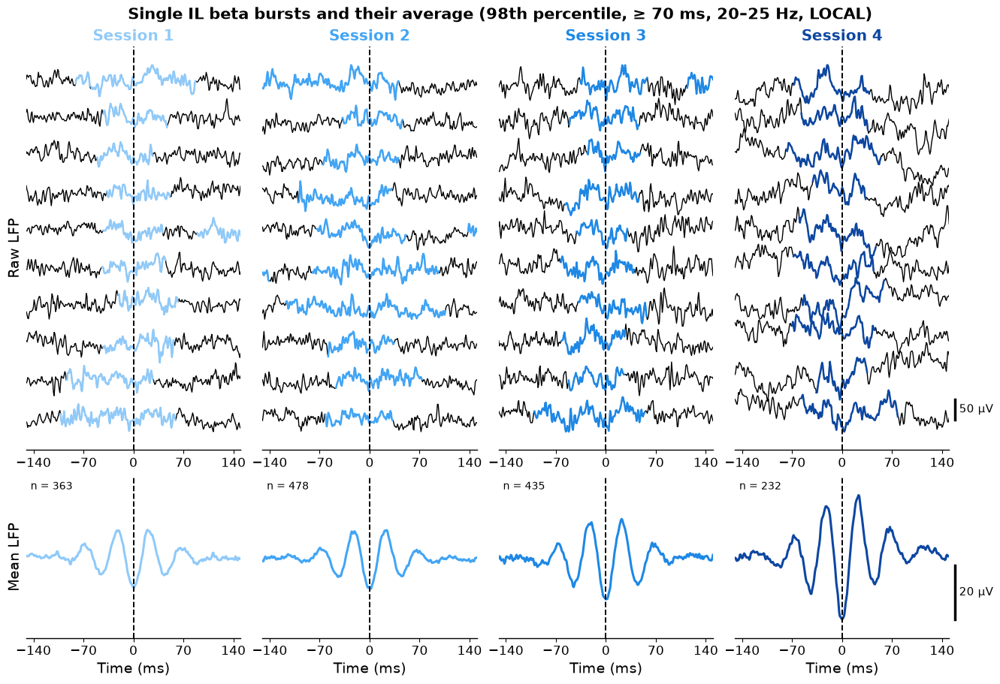

In [63]:
# ── STEP 9. SINGLE IL BETA BURSTS AND THEIR AVERAGE IN 4 TYPICAL SESSIONS (as Karvat 2020 Fig. 3a), 98th PERCENTILE, LOCAL (needs cell 0; data from 06 cell 5e) ──
from IPython.display import Image, display
AVG_DIR = os.path.join(DATA_OUT, "Burst averages p98 LOCAL")
OUT_DIR = os.path.join(BETA_DIR, "Burst properties (qualitative)"); os.makedirs(OUT_DIR, exist_ok=True)
SAVE = True
SHOW_MS, MIN_SEL = 150, 150
ODD = ["20260519_r0000136_wt_2031", "20260510_r0000135_wt_1625", "20260515_r0000135_wt_1953", "20260515_r0000135_wt_1957"]
SCOL = ["#90CAF9", "#42A5F5", "#1E88E5", "#0D47A1"]                  # blue gradient (beta colour), light → dark (Session 1 → 4)
pd.set_option("display.width", 250)

# ── 1. the rule: one typical session per rat + the next closest overall ──
M = pd.read_csv(os.path.join(AVG_DIR, "burst_average_metrics.csv"), dtype={"rat": str})
E = M[(M.n_sel >= MIN_SEL) & ~M.session.isin(ODD)].copy()
for c in ("sel_depth_uV", "sel_clarity"):
    E[c + "_z"] = E.groupby("rat")[c].transform(lambda v: (v - v.median()) / v.std(ddof=1))
E["dist"] = np.hypot(E.sel_depth_uV_z, E.sel_clarity_z); E = E.sort_values("dist")
A = [E[E.rat == r].session.iloc[0] for r in sorted(E.rat.unique())]
A = sorted(A + [E[~E.session.isin(A)].session.iloc[0]])                    # 4 sessions, date order
print(f"eligible {len(E)} of {len(M)} sessions | chosen (Session 1–4):")
print(E.set_index("session").loc[A].reset_index()[["session", "n_sel", "sel_depth_uV", "sel_clarity", "sel_cycles", "dist"]]
      .assign(label=[f"Session {i + 1}" for i in range(4)]).round(2).to_string(index=False))
print(f"all 60 sessions: mean of selected bursts {M.sel_cycles.median():.2f} cycles (range {M.sel_cycles.min():.2f}–{M.sel_cycles.max():.2f})")

# ── 2. load the saved traces / means ──
def load(s):
    z = np.load(os.path.join(AVG_DIR, s + ".npz")); t = 1000 * z["t_s"]; k = np.abs(t) <= SHOW_MS
    return dict(t=t[k], tr=z["traces_sel"][:, k], on=z["on_sel"][:, k],
                m=z["mean_sel"][k] - np.median(z["mean_sel"][np.abs(t) > 200]), n=int(z["n_sel"][0]))
R = [load(s) for s in A]
def nice(v):
    e = 10 ** np.floor(np.log10(v)); return min((1, 2, 5, 10), key=lambda m: abs(m * e - v)) * e
OFF = 1.1 * np.median([np.ptp(r["tr"], axis=1).mean() for r in R])
SB_TR, SB_M = nice(OFF * 0.6), nice(0.5 * max(np.ptp(r["m"]) for r in R))
mlo = min(r["m"].min() for r in R); mhi = max(r["m"].max() for r in R); pad = 0.15 * (mhi - mlo)

# ── 3. figure ──
plt.rcParams.update({"font.size": 12, "axes.linewidth": 1.0, "axes.labelsize": 14, "xtick.labelsize": 12, "ytick.labelsize": 12})
fig, axs = plt.subplots(2, 4, figsize=(13.2, 9), facecolor="white", gridspec_kw=dict(height_ratios=[3, 1.2]), constrained_layout=True)
for c, (r, col) in enumerate(zip(R, SCOL)):
    a, b = axs[0, c], axs[1, c]
    for q in range(len(r["tr"])):
        y = r["tr"][q] - q * OFF
        a.plot(r["t"], y, color="k", lw=1.0); a.plot(r["t"], np.where(r["on"][q], y, np.nan), color=col, lw=1.8)
    a.axvline(0, color="k", ls="--", lw=1.4); a.set_title(f"Session {c + 1}", color=col, fontweight="bold")
    b.plot(r["t"], r["m"], color=col, lw=2.2); b.axvline(0, color="k", ls="--", lw=1.4); b.set_ylim(mlo - pad, mhi + pad)
    b.text(0.02, 0.97, f"n = {r['n']}", transform=b.transAxes, va="top", fontsize=10)
    for ax_ in (a, b):
        ax_.set_xlim(-SHOW_MS, SHOW_MS); ax_.set_xticks([-140, -70, 0, 70, 140]); ax_.set_yticks([])
        for sp in ("top", "right", "left"): ax_.spines[sp].set_visible(False)
    b.set_xlabel("Time (ms)")
    if c == 0: a.set_ylabel("Raw LFP"); b.set_ylabel("Mean LFP")
    if c == 3:
        y0 = -(len(r["tr"]) - 0.5) * OFF
        a.plot([SHOW_MS + 8] * 2, [y0, y0 + SB_TR], color="k", lw=2.5, clip_on=False)
        a.text(SHOW_MS + 14, y0 + SB_TR / 2, f"{SB_TR:.0f} µV", va="center", fontsize=11)
        b.plot([SHOW_MS + 8] * 2, [mlo, mlo + SB_M], color="k", lw=2.5, clip_on=False)
        b.text(SHOW_MS + 14, mlo + SB_M / 2, f"{SB_M:.0f} µV", va="center", fontsize=11)
fig.suptitle("Single IL beta bursts and their average (98th percentile, ≥ 70 ms, 20–25 Hz, LOCAL)", fontsize=15, fontweight="bold")
fp = os.path.join(OUT_DIR, "step9_single_bursts_4_sessions_p98.png")
if SAVE: fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); print("saved:", fp, "| exists:", os.path.exists(fp))
plt.show()

<div style="color:#1565c0; border-left:4px solid #1565c0; padding-left:10px">

### Step 10. Is the average burst shape the same in every session and rat? (descriptive)

Mean LFP of the selected bursts (≥ 70 ms, 20–25 Hz; 98th percentile, IL, LOCAL; as Step 9) in each of the 60 sessions (06 cell 5e),
baseline (|t| > 200 ms) subtracted and divided by the depth of its own trough (trough = −1), so that only the shape is compared, not the size.
Thin lines = sessions (colour = rat), black = median over sessions.<br>
Shape similarity: correlation (±150 ms) of each session's normalized mean with the median of all other sessions.
Rhythm: frequency from the time between the peak before and the peak after the trough.<br>
Note: the size of the bursts differs between rats and depends on the reference (see slide note); here only the shape is compared.
Descriptive only, no statistical tests.
<div>

60 sessions | shape similarity with the other sessions: median r = 0.99 (range 0.95–0.99); r >= 0.9 in 60 of 60
rhythm (peak before -> peak after the trough): median 22.2 Hz (range 20.8–25.0)
per rat (median):
     similarity  rhythm_hz
rat                       
134        0.99      22.73
135        0.99      22.22
136        0.99      22.47
time-frequency (mean of 60 sessions): maximum at 22 Hz; above half maximum 19–26 Hz and -55 to 56 ms
saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\beta bursts\Burst properties (qualitative)\step10_burst_shape_all_sessions_p98.png | exists: True


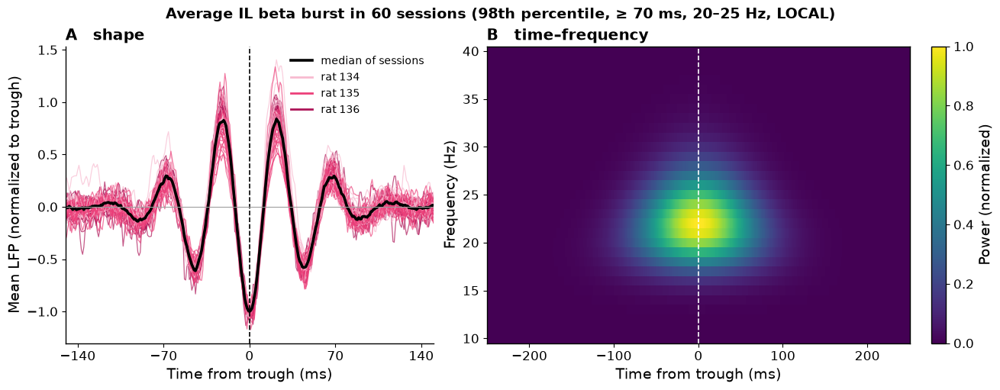

In [64]:
# ── STEP 10. SHAPE AND TIME-FREQUENCY OF THE AVERAGE IL BETA BURST IN ALL 60 SESSIONS, 98th PERCENTILE, LOCAL (needs cell 0; data from 06 cell 5e) ──
import glob
import scipy.signal as ss
AVG_DIR = os.path.join(DATA_OUT, "Burst averages p98 LOCAL")
OUT_DIR = os.path.join(BETA_DIR, "Burst properties (qualitative)"); os.makedirs(OUT_DIR, exist_ok=True)
SAVE, SHOW_MS, TFR_MS = True, 150, 250
FREQS = np.arange(10, 41)
RATC = {"134": "#F8BBD0", "135": "#EC407A", "136": "#AD1457"}

# ── 1. normalized means and their time-frequency maps ──
S, N, RAT, TF = [], [], [], []
for f in sorted(glob.glob(os.path.join(AVG_DIR, "*.npz"))):
    z = np.load(f); s = os.path.basename(f)[:-4]; fs = float(z["fs"][0])
    t = 1000 * z["t_s"]; m = z["mean_sel"] - np.median(z["mean_sel"][np.abs(t) > 200]); c = len(m) // 2
    S.append(s); RAT.append(s.split("_r0000")[1][:3]); N.append(m / abs(m[c]))
    P = np.array([np.abs(ss.fftconvolve(m, fn.morlet(f_, 7, fs), mode="same")) ** 2 for f_ in FREQS])
    TF.append(P / P.max())                                           # each session normalized to its own maximum
N, TF = np.array(N), np.mean(TF, 0)
k = np.abs(t) <= SHOW_MS; tk = t[k]; Nk = N[:, k]; med = np.median(Nk, 0)

# ── 2. shape similarity (leave one out), rhythm, time-frequency summary ──
sim = np.array([np.corrcoef(Nk[i], np.median(np.delete(Nk, i, 0), 0))[0, 1] for i in range(len(Nk))])
def rhythm(m):
    b = (tk >= -40) & (tk < 0); a = (tk > 0) & (tk <= 40)
    return 1000 / (tk[a][np.argmax(m[a])] - tk[b][np.argmax(m[b])])
T = pd.DataFrame(dict(session=S, rat=RAT, similarity=sim, rhythm_hz=[rhythm(m) for m in Nk]))
print(f"{len(T)} sessions | shape similarity with the other sessions: median r = {T.similarity.median():.2f} "
      f"(range {T.similarity.min():.2f}–{T.similarity.max():.2f}); r >= 0.9 in {(T.similarity >= 0.9).sum()} of {len(T)}")
print(f"rhythm (peak before -> peak after the trough): median {T.rhythm_hz.median():.1f} Hz (range {T.rhythm_hz.min():.1f}–{T.rhythm_hz.max():.1f})")
print("per rat (median):"); print(T.groupby("rat")[["similarity", "rhythm_hz"]].median().round(2).to_string())
low = T[T.similarity < 0.9]
if len(low): print("sessions with r < 0.9:"); print(low.round(2).to_string(index=False))
c = len(t) // 2; fmax = FREQS[np.argmax(TF[:, c])]
row = TF[np.argmax(TF[:, c])]; above = row >= 0.5 * row.max(); lo = hi = c
while lo > 0 and above[lo - 1]: lo -= 1
while hi < len(row) - 1 and above[hi + 1]: hi += 1
fband = FREQS[TF[:, c] >= 0.5 * TF[:, c].max()]
print(f"time-frequency (mean of 60 sessions): maximum at {fmax} Hz; above half maximum {fband.min()}–{fband.max()} Hz "
      f"and {t[lo]:.0f} to {t[hi]:.0f} ms")

# ── 3. figure: A shape, B time-frequency heat map ──
plt.rcParams.update({"font.size": 12, "axes.linewidth": 1.0, "axes.labelsize": 14, "xtick.labelsize": 12, "ytick.labelsize": 12})
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5), facecolor="white", gridspec_kw=dict(width_ratios=[1, 1.15]), constrained_layout=True)
for m, r in zip(Nk, RAT): a.plot(tk, m, color=RATC[r], lw=0.9, alpha=0.7)
a.plot(tk, med, color="k", lw=2.6, label="median of sessions")
for r, col in RATC.items(): a.plot([], [], color=col, lw=2, label=f"rat {r}")
a.axvline(0, color="k", ls="--", lw=1.2); a.axhline(0, color="#9E9E9E", lw=0.8)
a.set_xlim(-SHOW_MS, SHOW_MS); a.set_xticks([-140, -70, 0, 70, 140])
a.set_xlabel("Time from trough (ms)"); a.set_ylabel("Mean LFP (normalized to trough)")
a.legend(frameon=False, fontsize=10, loc="upper right"); a.set_title("A   shape", loc="left", fontweight="bold")
for sp in ("top", "right"): a.spines[sp].set_visible(False)
kt = np.abs(t) <= TFR_MS
im = b.pcolormesh(t[kt], FREQS, TF[:, kt], cmap="viridis", shading="auto", vmin=0, vmax=1)
b.axvline(0, color="w", ls="--", lw=1.2); b.set_xticks([-200, -100, 0, 100, 200])
b.set_xlabel("Time from trough (ms)"); b.set_ylabel("Frequency (Hz)"); b.set_title("B   time–frequency", loc="left", fontweight="bold")
fig.colorbar(im, ax=b, label="Power (normalized)")
fig.suptitle(f"Average IL beta burst in {len(Nk)} sessions (98th percentile, ≥ 70 ms, 20–25 Hz, LOCAL)", fontsize=14, fontweight="bold")
fp = os.path.join(OUT_DIR, "step10_burst_shape_all_sessions_p98.png")
if SAVE: fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); print("saved:", fp, "| exists:", os.path.exists(fp))
plt.show()

20260529_r0000136_wt_1318 | IL LOCAL channel imec0.ap#AP174 | trials per group: {'Quiet': 5, 'Low': 25, 'Medium': 16, 'High': 6}
Quiet: 5 trials, occupancy median 0 % | shown trial 45 (correct, 0 %)
Low: 25 trials, occupancy median 18 % | shown trial 61 (correct, 18 %)
Medium: 16 trials, occupancy median 38 % | shown trial 8 (correct, 39 %)
High: 6 trials, occupancy median 72 % | shown trial 5 (correct, 74 %)


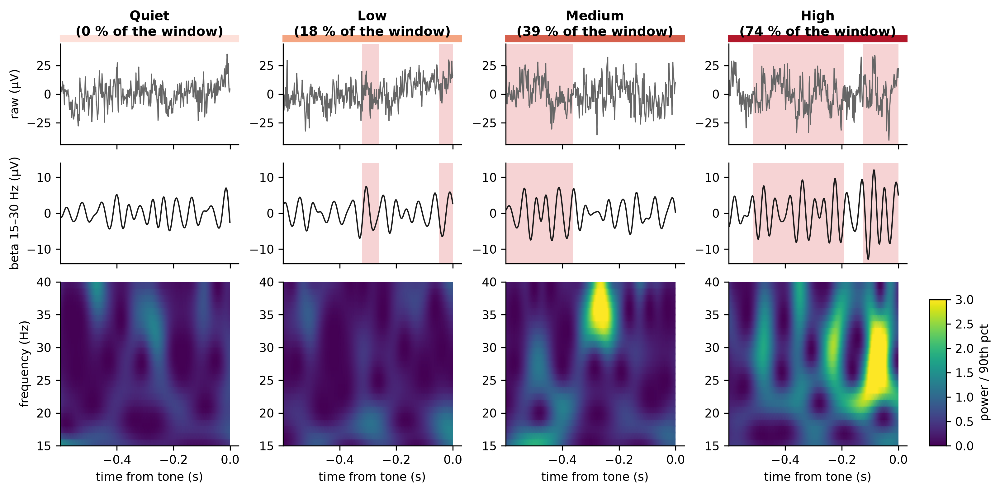

In [22]:
# ── Step 5b. Example trials for the four occupancy groups (quiet, low, medium, high), IL, LOCAL ──
from scipy.signal import butter, sosfiltfilt, hilbert, fftconvolve
from IPython.display import Image, display
S_EX, REF_EX, REG_EX, WIN_EX, MODE = TEST, "LOCAL", "IL", 0.6, "typical"     # MODE: "typical" or "clear"
GROUPS = [("Quiet", 0.0, 0.0), ("Low", 1e-9, 0.25), ("Medium", 0.25 + 1e-9, 0.50), ("High", 0.50 + 1e-9, 1.0)]
GCOL = ["#fde0d9", "#f4a582", "#d6604d", "#b2182b"]

z = np.load(os.path.join(EXACT_DIR, S_EX + ".npz")); T = pd.read_csv(os.path.join(EXACT_DIR, S_EX + "_trials.csv"))
k = f"{REF_EX}|beta 15-30|{REG_EX}"
bs, be = z[k + "|burst_start_s"], z[k + "|burst_end_s"]
ast, aen = z[f"{REF_EX}|{REG_EX}|art_start_s"], z[f"{REF_EX}|{REG_EX}|art_end_s"]
ch = str(z[f"{REF_EX}|{REG_EX}|channel"][0])

# occupancy in the 0.6 s before the tone (exact times), long correct + late, no artifact in the window
rows = []
for i, r in T[(T["type"] == "long") & T["label"].isin(["correct", "late"]) & T["tone_s"].notna()].iterrows():
    tone = r["tone_s"]; a = tone - WIN_EX
    if np.any((ast < tone) & (aen > a)): continue
    occ = np.clip(np.minimum(be, tone) - np.maximum(bs, a), 0, None).sum() / WIN_EX
    rows.append(dict(trial=i, label=r["label"], tone=tone, occ=occ))
C = pd.DataFrame(rows)
C["group"] = np.select([C.occ <= 0, C.occ <= 0.25, C.occ <= 0.5], ["Quiet", "Low", "Medium"], default="High")
print(f"{S_EX} | {REG_EX} {REF_EX} channel {ch} | trials per group:", C.group.value_counts().reindex([g for g, _, _ in GROUPS]).to_dict())

# LFP, beta-filtered signal and envelope of this channel
rec = fn.load_session(PROC, S_EX, XB, refs=(REF_EX,))[0][REF_EX]; fs = rec.get_sampling_frequency()
x = rec.get_traces(channel_ids=[ch], return_in_uV=True)[:, 0].astype(float); t = np.arange(len(x)) / fs
beta = sosfiltfilt(butter(4, [15, 30], btype="band", fs=fs, output="sos"), x); env = np.abs(hilbert(beta))

def clarity(r):                                   # strongest burst envelope / median envelope of the window
    a, b = int((r.tone - WIN_EX) * fs), int(r.tone * fs); w = env[a:b]
    return w.max() / np.median(w)
C["clarity"] = C.apply(clarity, axis=1)

pick = {}
for g, _, _ in GROUPS:
    d = C[C.group == g]
    if d.empty: print(f"{g}: no trial in this session"); continue
    if MODE == "clear" and g != "Quiet":
        pick[g] = d.sort_values("clarity", ascending=False).iloc[0]
    else:
        pick[g] = d.iloc[(d.occ - d.occ.median()).abs().argsort().iloc[0]]
    print(f"{g}: {len(d)} trials, occupancy median {100 * d.occ.median():.0f} % | shown trial {pick[g].trial} "
          f"({pick[g].label}, {100 * pick[g].occ:.0f} %)")

# time–frequency power 15–40 Hz (Morlet 7 cycles) / 90th percentile per frequency over the session (artifacts excluded), as Step 2
freqs = np.arange(15, 41, 1.0); clean = np.ones(len(x), bool)
for a_, e_ in zip(ast, aen): clean[(t >= a_) & (t < e_)] = False
PW = []
for f in freqs:
    sd = 7 / (2 * np.pi * f); tw = np.arange(-3.5 * sd, 3.5 * sd, 1 / fs)
    w = np.exp(2j * np.pi * f * tw) * np.exp(-tw ** 2 / (2 * sd ** 2)); w /= np.abs(w).sum()
    pw = np.abs(fftconvolve(x, w, mode="same")) ** 2; PW.append(pw / np.percentile(pw[clean], 90))
PW = np.array(PW, dtype=np.float32)

# figure: one column per group, rows = raw LFP, beta, time–frequency
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
G_ = [g for g, _, _ in GROUPS if g in pick]
fig, axs = plt.subplots(3, len(G_), figsize=(3.0 * len(G_), 5.6), sharex=True, facecolor="white",
                        gridspec_kw=dict(height_ratios=[0.8, 0.8, 1.3]))
for j, g in enumerate(G_):
    r = pick[g]; m = (t >= r.tone - WIN_EX) & (t <= r.tone); tt = t[m] - r.tone
    for s_, e_ in zip(bs, be):                                       # shade bursts inside the window
        if e_ > r.tone - WIN_EX and s_ < r.tone:
            for ax in axs[:2, j]: ax.axvspan(max(s_, r.tone - WIN_EX) - r.tone, min(e_, r.tone) - r.tone, color="#d62728", alpha=0.2, lw=0)
    axs[0, j].plot(tt, x[m], color="0.4", lw=0.8); axs[1, j].plot(tt, beta[m], color="0.1", lw=1)
    im = axs[2, j].pcolormesh(tt, freqs, PW[:, m], cmap="viridis", vmin=0, vmax=3, shading="gouraud")
    axs[0, j].set_title(f"{g}\n({100 * r.occ:.0f} % of the window)", fontsize=10, fontweight="bold", color="k")
    axs[0, j].add_patch(plt.Rectangle((0, 1.02), 1, 0.06, transform=axs[0, j].transAxes, color=GCOL[[x_[0] for x_ in GROUPS].index(g)], clip_on=False))
    axs[2, j].set_xlabel("time from tone (s)")
    for ax in axs[:, j]:
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axs[0, 0].set_ylabel("raw (µV)"); axs[1, 0].set_ylabel("beta 15–30 Hz (µV)"); axs[2, 0].set_ylabel("frequency (Hz)")
for i_ in range(2):                                                 # same y-scale across groups per row
    lim = max(abs(a_.get_ylim()[0]) for a_ in axs[i_]) ; [a_.set_ylim(-lim, lim) for a_ in axs[i_]]
fig.subplots_adjust(right=0.88, hspace=0.15, wspace=0.25)
cax = fig.add_axes([0.90, 0.11, 0.015, 0.28]); fig.colorbar(im, cax=cax, label="power / 90th pct")
fp = os.path.join(BETA_DIR, f"step5b_occupancy_group_examples_{MODE}.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))

<div style="color:#6a1b9a; border-left:4px solid #6a1b9a; padding-left:10px">

## 3. Gamma bursts (30–100 Hz): is the beta story specific to beta?

Same burst detection as beta (Karvat 2021: Morlet wavelets, 10 cycles for gamma; peaks above the 90th percentile per frequency; 50-ms bins),
same IL channel, LOCAL reference, same trials and models as the beta Steps. Gamma occupancy is ~47–49 % (beta ~26–28 %).<br>
Quick check of the beta Steps in gamma (IL, LOCAL, raw p):
<ul>
<li><b>Only in beta:</b> more bursts before late responses (Step 1: beta +2.7 %-points, p = 0.005; gamma +0.5, p = 0.56, and n.s. in PL, Cg1, pooled);
the start-of-session effect 0.6 s before the tone (Step 3: beta +8.2, p < 0.001; gamma +2.8, p = 0.10);
fewer successes with more bursts before the tone (Step 5: beta trend −3.2 % per group, p = 0.012; gamma +1.5, p = 0.42).</li>
<li><b>Also in gamma (general state, not beta-specific):</b> bursts decrease over the session (Step 0: gamma decreasing in 49 of 60 sessions in IL, p < 0.001, and in all regions);
more bursts before the next press after an error (Step 7: gamma 37 of 56 sessions, p = 0.022; beta 40 of 56, p = 0.002).</li>
<li>Not checked in gamma: Step 6 (needs exact burst times, beta only) and Steps 8–10 (need a gamma detection at the 98th percentile).</li>
</ul>
<div>

<div style="color:#6a1b9a; border-left:4px solid #6a1b9a; padding-left:10px">

### Gamma Step 1. At the start of the session, is the extra activity before late responses beta-specific? (beta vs gamma)

IL, LOCAL, long trials (correct and late), all blocks, 60 sessions. Start of the session = first 25 % of trials (trial number).
Same model in both panels: value ~ late × phase + block + (1 | session); shown is late − correct at the start ± 95 % CI; filled = p < 0.05, hollow = n.s. (raw p).<br>
<b>A Bursts</b> (50-ms bins; as beta Step 4): burst occupancy before the press (−1.5 to 0 s), during the whole hold (press → tone), in the 0.6 s before the tone.
Shown relative to each band's own level (late − correct as % of the mean correct occupancy of that band at the start), because gamma occupancy (~50 %)
is about twice beta occupancy (~27 %); p values unchanged by this scaling.<br>
<b>B Band power</b> (no burst detection, so not affected by gamma covering more frequencies than beta): log10 power averaged over the band
(beta 13–29, low gamma 30–60, high gamma 61–100 Hz) before the press (−0.5 to −0.2 s), during the hold (0.2–0.85 s), in the 0.3 s before the tone;
late − correct as % change in power.<br>
Result: in both measures, all bands are raised before late trials during the hold (a general state at the session start), but just before the tone
only beta is raised (bursts: beta +29 %, gamma n.s.; power: beta +14 %, low gamma +3 %, high gamma +5 %, both n.s.).
Together with the quick check above (no late − correct difference in gamma in any region; no gamma start effect before the tone; no link between gamma and success),
the increase before the tone is specific to beta.
<div>

A  BURSTS: late − correct occupancy at the START of the session (%-points; value = % of the band's correct level), IL, LOCAL:
        band            window  sessions  n_correct_start  n_late_start  occ_correct_start  occ_late_start  late_minus_correct  ci_low  ci_high  value  v_low  v_high     p  sig
  beta 15-30      before press        60              605           119          28.187000       31.200001               3.317   0.653    5.982 11.769  2.317  21.221 0.015    *
  beta 15-30        whole hold        60              605           119          26.969999       31.656000               4.722   1.767    7.677 17.508  6.551  28.464 0.002   **
  beta 15-30 0.6 s before tone        60              605           119          26.591000       34.355999               7.747   3.991   11.503 29.133 15.008  43.258 0.000  ***
gamma 30-100      before press        60              605           119          51.681999       54.544998               3.431   1.151    5.710  6.638  2.227  11.049 

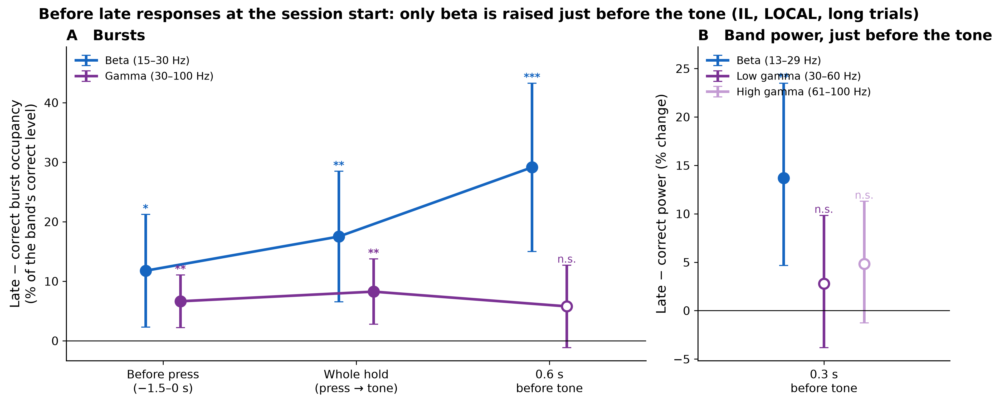

In [65]:
# ── GAMMA STEP 1. BETA vs GAMMA BEFORE LATE RESPONSES AT THE SESSION START: A BURSTS, B BAND POWER (IL, LOCAL, long trials, all blocks) (needs cell 0) ──
globals().pop("C", None)
import glob, warnings
import statsmodels.formula.api as smf
from scipy.stats import norm
from IPython.display import Image, display
GAMMA_DIR = os.path.join(AMIR, "Gamma bursts"); os.makedirs(GAMMA_DIR, exist_ok=True)
PROP_DIR  = os.path.join(DATA_OUT, "Burst properties p98")         # only to get the IL channel used for the bursts
PHS, CUTS = ["start", "middle", "end"], (0.25, 0.85)
stars = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."
PT = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), low_memory=False).sort_values(["session", "trial_index"])
PT["position"] = PT.groupby("session")["trial_index"].rank(pct=True)

def model(dd):                                                       # late − correct at the session start (estimate, SE, p)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm("y ~ late * C(phase, Treatment('start')) + C(block)", dd, groups=dd["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"])
    e, se = m.params["late"], m.bse["late"]; return e, se, 2 * norm.sf(abs(e / se))

def prep(W):
    W = W.merge(PT[["session", "trial_index", "position"]], on=["session", "trial_index"], how="left").dropna(subset=["position"])
    W["late"] = (W.cond == "late").astype(int); W["block"] = W.long_prob.round(2).astype(str)
    W["phase"] = pd.cut(W.position, [-0.001, *CUTS, 1.001], labels=PHS).astype(str)
    return W

# ── A. BURSTS (50-ms bins), relative to each band's correct level at the start ──
BANDS = {"beta 15-30": ("Beta (15–30 Hz)", "#1565C0"), "gamma 30-100": ("Gamma (30–100 Hz)", "#7B3294")}
BIN, A0P, A0T = fn.BURST_BIN, fn.BURST_A0["press"], fn.BURST_A0["tone"]
WINS = ["before press", "whole hold", "0.6 s before tone"]
WLAB = {"before press": "Before press\n(−1.5–0 s)", "whole hold": "Whole hold\n(press → tone)", "0.6 s before tone": "0.6 s\nbefore tone"}
files = [s for s in final["session"] if os.path.exists(os.path.join(BURST_DIR, s + ".npz"))]

def wm(v, t_, a, b):                                                 # mean occupancy (%) of the 50-ms bins inside [a, b]
    sel = (t_ >= a - 1e-9) & (t_ + BIN <= b + 1e-9)
    return 100 * v[sel].mean() if sel.any() and b > a and np.isfinite(v[sel]).all() else np.nan

def burst_effect(band):
    rows = []
    for s in files:
        z = np.load(os.path.join(BURST_DIR, s + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))
        kp, kt = f"LOCAL|{band}|IL|press|occ", f"LOCAL|{band}|IL|tone|occ"
        if kp not in z.files or z[kp].shape[0] != len(T): continue
        Op, Ot = z[kp], z[kt]; tp = A0P + BIN * np.arange(Op.shape[1]); tt_ = A0T + BIN * np.arange(Ot.shape[1])
        for i in np.where((T["type"].values == "long") & T["label"].isin(["correct", "late"]).values)[0]:
            tone = T["tone_s"].iat[i] - T["press_s"].iat[i]
            rows.append(dict(session=s, trial_index=T["trial_index"].iat[i], cond=T["label"].iat[i], long_prob=T["long_prob"].iat[i],
                             **{"before press": wm(Op[i], tp, -1.5, 0), "whole hold": wm(Op[i], tp, 0, min(tone, tp[-1] + BIN)),
                                "0.6 s before tone": wm(Ot[i], tt_, -0.6, 0)}))
    W = prep(pd.DataFrame(rows)); out = []
    for w in WINS:
        dd = W.dropna(subset=[w]).rename(columns={w: "y"}); e, se, p = model(dd); st = dd[dd.phase == "start"]
        lvl = st.loc[st.late == 0, "y"].mean()                         # the band's own correct level at the session start
        out.append(dict(band=band, window=w, sessions=dd.session.nunique(), n_correct_start=int((st.late == 0).sum()), n_late_start=int(st.late.sum()),
                        occ_correct_start=lvl, occ_late_start=st.loc[st.late == 1, "y"].mean(),
                        late_minus_correct=e, ci_low=e - 1.96 * se, ci_high=e + 1.96 * se,
                        value=100 * e / lvl, v_low=100 * (e - 1.96 * se) / lvl, v_high=100 * (e + 1.96 * se) / lvl, p=p, sig=stars(p)))
    return pd.DataFrame(out)

RA = pd.concat([burst_effect(b) for b in BANDS], ignore_index=True)
pd.set_option("display.width", 250)
print("A  BURSTS: late − correct occupancy at the START of the session (%-points; value = % of the band's correct level), IL, LOCAL:")
print(RA.round(3).to_string(index=False))
print("   (check: beta %-points = beta Step 4, start: before press +3.32, whole hold +4.72, 0.6 s before tone +7.75)")

# ── B. BAND POWER (band-power files, LOCAL, same IL channel), % change ──
BPB = {"beta 13-29": ("Beta (13–29 Hz)", "#1565C0"), "lowG 30-60": ("Low gamma (30–60 Hz)", "#7B3294"),
       "highG 61-100": ("High gamma (61–100 Hz)", "#C39BD3")}
BPW = {"pre": "Before press\n(−0.5 to −0.2 s)", "hold": "Hold\n(0.2–0.85 s)", "pre_tone": "0.3 s\nbefore tone"}
rows = []
for f in sorted(glob.glob(os.path.join(PROP_DIR, "*.npz"))):
    s = os.path.basename(f)[:-4]; ch = str(np.load(f)["channel"][0])
    try:
        bp = load_bp(s, "LOCAL"); ids = [str(c) for c in bp["meta"]["channel_ids"]]; j = ids.index(ch)
    except (FileNotFoundError, ValueError) as e:
        print(f"   {s}: skipped ({e!r})"); continue
    tr = bp["trials"]
    for i in np.where((tr["type"].values == "long") & tr["label"].isin(["correct", "late"]).values)[0]:
        r = dict(session=s, trial_index=tr["trial_index"].iat[i], cond=tr["label"].iat[i], long_prob=tr["long_prob"].iat[i])
        for b in BPB:
            for w in BPW: r[f"{b}|{w}"] = bp["logpow"][b][w][i, j]
        rows.append(r)
D = prep(pd.DataFrame(rows)); pc = lambda v: 100 * (10 ** v - 1); out = []
for b in BPB:
    for w in BPW:
        e, se, p = model(D.dropna(subset=[f"{b}|{w}"]).rename(columns={f"{b}|{w}": "y"}))
        out.append(dict(band=b, window=w, sessions=D.session.nunique(), value=pc(e), v_low=pc(e - 1.96 * se), v_high=pc(e + 1.96 * se), p=p, sig=stars(p)))
RB = pd.DataFrame(out)
print(f"\nB  BAND POWER: late − correct power at the START of the session (% change), IL, LOCAL "
      f"({D.session.nunique()} sessions; start: {int(((D.phase == 'start') & (D.late == 0)).sum())} correct, {int(((D.phase == 'start') & (D.late == 1)).sum())} late):")
print(RB.round(3).to_string(index=False))
RA.to_csv(os.path.join(GAMMA_DIR, "gamma_step1_A_bursts.csv"), index=False)
RB.to_csv(os.path.join(GAMMA_DIR, "gamma_step1_B_band_power.csv"), index=False)

# ── figure: A bursts, B band power — one line per band over the three windows ──
def profile(ax, R, bands, wins, wlab, ylab, letter, title):
    nb = len(bands); step = 0.18 if nb == 2 else 0.16                 # horizontal distance between the bands
    for j, (b, (lab, col)) in enumerate(bands.items()):
        d = R[R.band == b].set_index("window").loc[list(wins)]; x = np.arange(len(wins)) + (j - (nb - 1) / 2) * step
        ax.errorbar(x, d["value"], yerr=[d["value"] - d["v_low"], d["v_high"] - d["value"]], color=col, lw=2.4, capsize=4, label=lab, zorder=2)
        for xi, (_, r) in zip(x, d.iterrows()):
            sig = r.p < 0.05
            ax.plot(xi, r["value"], "o", ms=9, color=col, mfc=col if sig else "white", mew=2, zorder=3)
            ax.text(xi, r["v_high"], r.sig, ha="center", va="bottom", fontsize=9.5, color=col,
                    fontweight="bold" if sig else "normal")                 # stars just above the error bar
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(wins))); ax.set_xticklabels([wlab[w] for w in wins]); ax.set_xlim(-0.5, len(wins) - 0.5)
    y0, y1 = ax.get_ylim(); ax.set_ylim(y0, y1 + 0.08 * (y1 - y0))      # room for the stars at the top
    ax.set_ylabel(ylab); ax.legend(frameon=False, fontsize=9.5, loc="upper left")
    ax.set_title(f"{letter}   {title}", loc="left", fontweight="bold")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

plt.rcParams.update({"font.size": 11, "axes.linewidth": 0.9, "axes.labelsize": 12, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5})
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw=dict(width_ratios=[2.3, 1]), facecolor="white", constrained_layout=True)
profile(a, RA, BANDS, WINS, WLAB, "Late − correct burst occupancy\n(% of the band's correct level)", "A", "Bursts")
profile(b, RB, BPB, ["pre_tone"], BPW, "Late − correct power (% change)", "B", "Band power, just before the tone") 
fig.suptitle("Before late responses at the session start: only beta is raised just before the tone (IL, LOCAL, long trials)",
             fontsize=13.5, fontweight="bold")
fp = os.path.join(GAMMA_DIR, "gamma_step1_beta_vs_gamma_start.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig)
print("\nsaved:", fp, "| exists:", os.path.exists(fp)); display(Image(fp))